In [3]:
import pdfplumber
import os
import pandas as pd

print("All imports work")
print(f"pdfplumber version: {pdfplumber.__version__}")
print(f"pandas version: {pd.__version__}")

All imports work
pdfplumber version: 0.11.10
pandas version: 3.0.6


In [6]:
pdf_folder = pdf_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
pdf_files = sorted([f for f in os.listdir(pdf_folder) if f.endswith('.pdf')])
print(f"Found {len(pdf_files)} PDFs:")
for f in pdf_files:
    print(f"  - {f}")

Found 18 PDFs:
  - Kenya-Consumer-Price-Indices-and-Inflation-Rates-April-2025.pdf
  - Kenya-Consumer-Price-Indices-and-Inflation-Rates-April-2026.pdf
  - Kenya-Consumer-Price-Indices-and-Inflation-Rates-August-2026.pdf
  - Kenya-Consumer-Price-Indices-and-Inflation-Rates-December-2025.pdf
  - Kenya-Consumer-Price-Indices-and-Inflation-Rates-February-2025.pdf
  - Kenya-Consumer-Price-Indices-and-Inflation-Rates-February-2026.pdf
  - Kenya-Consumer-Price-Indices-and-Inflation-Rates-January-2025.pdf
  - Kenya-Consumer-Price-Indices-and-Inflation-Rates-January-2026.pdf
  - Kenya-Consumer-Price-Indices-and-Inflation-Rates-July-2026.pdf
  - Kenya-Consumer-Price-Indices-and-Inflation-Rates-June-2025.pdf
  - Kenya-Consumer-Price-Indices-and-Inflation-Rates-June-2026.pdf
  - Kenya-Consumer-Price-Indices-and-Inflation-Rates-March-2025.pdf
  - Kenya-Consumer-Price-Indices-and-Inflation-Rates-March-2026.pdf
  - Kenya-Consumer-Price-Indices-and-Inflation-Rates-May-2025_1.pdf
  - Kenya-Consumer-Pri

In [7]:
first_pdf = os.path.join(pdf_folder, pdf_files[0])
with pdfplumber.open(first_pdf) as pdf:
    print(f"File: {pdf_files[0]}")
    print(f"Pages: {len(pdf.pages)}")
    print("\n--- PAGE 1 TEXT ---\n")
    print(pdf.pages[0].extract_text())

File: Kenya-Consumer-Price-Indices-and-Inflation-Rates-April-2025.pdf
Pages: 5

--- PAGE 1 TEXT ---

CONSUMER PRICE INDICES AND INFLATION RATES FOR APRIL, 2025
The annual consumer price inflation as measured by the Consumer Price Index (CPI)
was 4.1 per cent in April 2025. This implies that the general price level in April 2025
was 4.1 per cent higher than it was in April 2024. The price increase was primarily
driven by rise in price of items in the Divisions of Food and Non-Alcoholic Beverages
(7.1%); Transport (2.3%) and Housing, Water, Electricity, Gas and other fuels (0.8%)
over the one year period. These three divisions together account for over 57 per cent
of the total weight across the 13 major expenditure categories.
The CPI measures the cost of purchasing a fixed basket of goods and services,
comparing current prices to those of a base period (February 2019). The inflation
rate is derived from data collected through a monthly survey of retail prices that
targets a representati

In [8]:
# Already installed, just verify
import pdfplumber
import pandas as pd
import os
import re

print("Ready to extract")

Ready to extract


In [11]:
pdf_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "../data/processed"
os.makedirs(output_folder, exist_ok=True)

pdf_files = sorted([f for f in os.listdir(pdf_folder) if f.endswith('.pdf')])
print(f"Found {len(pdf_files)} PDFs to process")

Found 18 PDFs to process


In [16]:
import pdfplumber
import pandas as pd
import os
import re
from datetime import datetime

# ─── SETUP ───
pdf_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
os.makedirs(output_folder, exist_ok=True)

pdf_files = sorted([f for f in os.listdir(pdf_folder) if f.endswith('.pdf')])
print(f"Processing {len(pdf_files)} PDFs...\n")

# ─── HELPERS ───
MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}

def clean_num(s):
    if s is None:
        return None
    s = str(s).strip().replace(',', '').replace('−', '-').replace('%', '').strip()
    try:
        return float(s)
    except:
        return None

def parse_filename(fname):
    match = re.search(r'-(January|February|March|April|May|June|July|August|September|October|November|December)-(\d{4})', fname)
    if match:
        return match.group(1), int(match.group(2)), f"{match.group(2)}-{MONTH_NUM[match.group(1)]:02d}"
    return None, None, None

# ─── EXTRACTION ───
all_overall = []
all_divisions = []
all_commodities = []
all_core_nocore = []

# Regex 1: Full month lines (e.g. "April 2024 138.40 5.0")
month_line = re.compile(
    r'(January|February|March|April|May|June|July|August|September|October|November|December)'
    r'\s+(\d{4})\s+'
    r'(\d{1,3}\.\d{1,2})\s+'
    r'(\d{1,2}\.\d{1,2})'
)

# Regex 2: Divisions
DIVISION_NAMES = [
    'Food and Non-Alcoholic Beverages',
    'Alcoholic Beverages, Tobacco and Narcotics',
    'Clothing and Footwear',
    'Housing, Water, Electricity, Gas and Other Fuels',
    'Furnishings, Household Equipment and Routine Household Maintenance',
    'Health',
    'Transport',
    'Information and Communication',
    'Recreation, Sport and Culture',
    'Education Services',
    'Restaurants and Accommodation Services',
    'Insurance and Financial Services',
    'Personal Care, Social Protection and Miscellaneous Goods and Services',
]

# Regex 3: Commodities — match by name and grab trailing numbers
COMMODITY_PATTERNS = [
    ('Potatoes (Irish)',              r'Potatoes\s*\(Irish\)'),
    ('Maize Grain - Loose',           r'Maize\s*Grain\s*-\s*Loose'),
    ('Fortified Maize flour',         r'Fortified\s*Maize\s*flour'),
    ('Tomatoes',                      r'Tomatoes'),
    ('Sugar',                         r'Sugar'),
    ('Beef - With Bones',             r'Beef\s*-\s*With\s*Bones'),
    ('Wheat Flour-White',             r'Wheat\s*Flour-?White'),
    ('Cooking Oil (Salad)',           r'Cooking\s*Oil\s*\(Salad\)'),
    ('Traditional Vegetables',        r'Traditional\s*Vegetables'),
    ('Kale-Sukuma Wiki',              r'Kale-?Sukuma\s*Wiki'),
    ('Cabbages',                      r'Cabbages'),
    ('Electricity 50 kWh',            r'Electricity\s*50\s*kWh'),
    ('Electricity 200 kWh',           r'Electricity\s*200\s*kWh'),
    ('Gas/LPG 13kg',                  r'Gas/LPG'),
    ('House rent - 2 bedroom',        r'House\s*rent'),
    ('Kerosene/Paraffin',             r'Kerosene/Paraffin'),
    ('Country Bus / Matatu Fare',     r'Country\s*Bus\s*/\s*Matatu\s*Fare'),
    ('Petrol',                        r'Petrol'),
    ('Diesel',                        r'Diesel'),
]

# Regex 4: Core/Non-Core (e.g. "Apr-24 125.31 4.3 190.91 7.3")
core_line = re.compile(
    r'(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)-(\d{2})'
    r'\s+(\d{1,3}\.\d{1,2})\s+'
    r'(\d{1,2}\.\d{1,2})\s+'
    r'(\d{1,3}\.\d{1,2})\s+'
    r'(\d{1,2}\.\d{1,2})'
)

for fname in pdf_files:
    month_str, year, ym = parse_filename(fname)
    if not ym:
        print(f"⚠️  Skipping {fname}")
        continue
    print(f"Processing {month_str} {year}...")

    pdf_path = os.path.join(pdf_folder, fname)

    with pdfplumber.open(pdf_path) as pdf:
        # Combine all page text
        full_text = "\n".join([(p.extract_text() or "") for p in pdf.pages])

        # ── Table 1: Overall CPI ──
        # Take only the FIRST 13 month matches found in full text
        matches = month_line.findall(full_text)
        seen_months = set()
        count = 0
        for m in matches:
            key = (m[1], m[0])  # (year, month)
            if key in seen_months:
                continue
            seen_months.add(key)
            all_overall.append({
                'year_month': f"{m[1]}-{MONTH_NUM[m[0]]:02d}",
                'month_name': m[0],
                'year': int(m[1]),
                'overall_cpi': clean_num(m[2]),
                'inflation_rate': clean_num(m[3]),
                'source_file': fname
            })
            count += 1
            if count >= 13:
                break

        # ── Table 2: Divisions ──
        # Find weight numbers (they are exact: 32.9094, 3.3289, etc.)
        # Match division names in order via text
        for i, div in enumerate(DIVISION_NAMES):
            # Find the line containing this division + numbers
            # Pattern: division_name [optional words] weight mom yoy
            pattern = re.compile(
                re.escape(div) + r'[^\d\n]{0,50}'
                r'(\d{1,3}\.\d{1,4})\s+'
                r'(-?\d{1,2}\.\d{1,2})\s+'
                r'(-?\d{1,2}\.\d{1,2})'
            )
            m = pattern.search(full_text)
            if m:
                all_divisions.append({
                    'year_month': ym,
                    'month_name': month_str,
                    'year': year,
                    'division': div,
                    'weight': clean_num(m.group(1)),
                    'mom_change': clean_num(m.group(2)),
                    'yoy_change': clean_num(m.group(3)),
                    'source_file': fname
                })

        # ── Table 3: Commodities ──
        for name, pattern in COMMODITY_PATTERNS:
            # Find line with commodity name followed by numbers
            regex = re.compile(
                pattern + r'[^\d\n]{0,30}'
                r'(\d{1,3}(?:,\d{3})*(?:\.\d{1,2})?)\s+'   # quantity
                r'([A-Za-z/ ]+)\s+'                          # unit
                r'(\d{1,3}(?:,\d{3})*(?:\.\d{1,2})?)\s+'   # apr 2024 price
                r'(\d{1,3}(?:,\d{3})*(?:\.\d{1,2})?)\s+'   # prev month
                r'(\d{1,3}(?:,\d{3})*(?:\.\d{1,2})?)\s+'   # current
                r'(-?\d{1,3}\.\d{1,2})',                     # mom %
                re.MULTILINE
            )
            m = regex.search(full_text)
            if m:
                all_commodities.append({
                    'year_month': ym,
                    'month_name': month_str,
                    'year': year,
                    'commodity': name,
                    'quantity': m.group(1),
                    'unit': m.group(2).strip(),
                    'price_apr_2024': clean_num(m.group(3)),
                    'price_prev_month': clean_num(m.group(4)),
                    'price_current': clean_num(m.group(5)),
                    'mom_change_pct': clean_num(m.group(6)),
                    'source_file': fname
                })

        # ── Table 4: Core/Non-Core ──
        matches = core_line.findall(full_text)
        seen = set()
        for m in matches:
            key = (m[0], m[1])
            if key in seen:
                continue
            seen.add(key)
            all_core_nocore.append({
                'period': f"{m[0]}-{m[1]}",
                'core_index': clean_num(m[2]),
                'core_inflation': clean_num(m[3]),
                'noncore_index': clean_num(m[4]),
                'noncore_inflation': clean_num(m[5]),
                'source_file': fname
            })

# ─── SAVE ───
df_overall = pd.DataFrame(all_overall).drop_duplicates(subset=['year_month']).sort_values('year_month')
df_divisions = pd.DataFrame(all_divisions).drop_duplicates(subset=['year_month', 'division'])
df_commodities = pd.DataFrame(all_commodities).drop_duplicates(subset=['year_month', 'commodity'])
df_core = pd.DataFrame(all_core_nocore).drop_duplicates(subset=['period'])

df_overall.to_csv(f"{output_folder}/cpi_overall.csv", index=False)
df_divisions.to_csv(f"{output_folder}/cpi_by_division.csv", index=False)
df_commodities.to_csv(f"{output_folder}/cpi_commodity_prices.csv", index=False)
df_core.to_csv(f"{output_folder}/cpi_core_nocore.csv", index=False)

print("\n" + "="*60)
print("EXTRACTION COMPLETE")
print("="*60)
print(f"cpi_overall.csv            : {len(df_overall)} unique months")
print(f"cpi_by_division.csv        : {len(df_divisions)} rows")
print(f"cpi_commodity_prices.csv   : {len(df_commodities)} rows")
print(f"cpi_core_nocore.csv        : {len(df_core)} rows")
print(f"\nMonths captured: {sorted(df_overall['year_month'].unique())}")
print(f"\nCommodities captured: {sorted(df_commodities['commodity'].unique())}")

Processing 18 PDFs...

Processing April 2025...
Processing April 2026...
Processing August 2026...
Processing December 2025...
Processing February 2025...
Processing February 2026...
Processing January 2025...
Processing January 2026...
Processing July 2026...
Processing June 2025...
Processing June 2026...
Processing March 2025...
Processing March 2026...
Processing May 2025...
Processing May 2026...
Processing November 2025...
Processing October 2025...
Processing September 2026...

EXTRACTION COMPLETE
cpi_overall.csv            : 19 unique months
cpi_by_division.csv        : 222 rows
cpi_commodity_prices.csv   : 181 rows
cpi_core_nocore.csv        : 33 rows

Months captured: ['2024-01', '2024-02', '2024-03', '2024-04', '2024-05', '2024-06', '2024-07', '2024-08', '2024-09', '2024-10', '2024-11', '2024-12', '2025-01', '2025-02', '2025-03', '2025-04', '2025-05', '2025-10', '2026-05']

Commodities captured: ['Beef - With Bones', 'Cabbages', 'Cooking Oil (Salad)', 'Diesel', 'Fortified Ma

In [18]:
import re
import pandas as pd
import pdfplumber

# Patch commodities that failed
patched = []

pdf_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
pdf_files = sorted([f for f in os.listdir(pdf_folder) if f.endswith('.pdf')])

# Simpler patterns for the missing ones
missing_patterns = [
    ('Electricity 50 kWh',     r'50\s*kWh',             'kWh'),
    ('Electricity 200 kWh',    r'200\s*kWh',            'kWh'),
    ('Country Bus / Matatu Fare', r'Country\s*Bus',     'Ticket'),
]

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}

def clean_num(s):
    if s is None: return None
    s = str(s).strip().replace(',', '').replace('−', '-').replace('%', '').strip()
    try: return float(s)
    except: return None

for fname in pdf_files:
    match = re.search(r'-(January|February|March|April|May|June|July|August|September|October|November|December)-(\d{4})', fname)
    if not match:
        continue
    month_str, year = match.group(1), int(match.group(2))
    ym = f"{year}-{MONTH_NUM[month_str]:02d}"
    
    pdf_path = os.path.join(pdf_folder, fname)
    with pdfplumber.open(pdf_path) as pdf:
        full_text = "\n".join([(p.extract_text() or "") for p in pdf.pages])
    
    for name, pattern, default_unit in missing_patterns:
        # Find pattern followed by 5 numbers
        regex = re.compile(
            pattern + r'[^\d\n]{0,40}'
            r'(\d{1,3}(?:,\d{3})*(?:\.\d{1,2})?)\s+'  # qty
            r'(\d{1,3}(?:,\d{3})*(?:\.\d{1,2})?)\s+'  # apr 2024
            r'(\d{1,3}(?:,\d{3})*(?:\.\d{1,2})?)\s+'  # prev
            r'(\d{1,3}(?:,\d{3})*(?:\.\d{1,2})?)\s+'  # current
            r'(-?\d{1,3}\.\d{1,2})'                    # mom %
        )
        m = regex.search(full_text)
        if m:
            patched.append({
                'year_month': ym,
                'month_name': month_str,
                'year': year,
                'commodity': name,
                'quantity': None,
                'unit': default_unit,
                'price_apr_2024': clean_num(m.group(2)),
                'price_prev_month': clean_num(m.group(3)),
                'price_current': clean_num(m.group(4)),
                'mom_change_pct': clean_num(m.group(5)),
                'source_file': fname
            })

# Merge with existing
df_existing = pd.read_csv(f"{output_folder}/cpi_commodity_prices.csv")
df_new = pd.DataFrame(patched)
df_combined = pd.concat([df_existing, df_new], ignore_index=True)
df_combined = df_combined.drop_duplicates(subset=['year_month', 'commodity'], keep='last')
df_combined.to_csv(f"{output_folder}/cpi_commodity_prices.csv", index=False)

print(f"Patched {len(df_new)} new rows")
print(f"Total commodity rows: {len(df_combined)}")
print(f"Unique commodities: {sorted(df_combined['commodity'].unique())}")


Patched 6 new rows
Total commodity rows: 187
Unique commodities: ['Beef - With Bones', 'Cabbages', 'Cooking Oil (Salad)', 'Diesel', 'Electricity 200 kWh', 'Electricity 50 kWh', 'Fortified Maize flour', 'Gas/LPG 13kg', 'House rent - 2 bedroom', 'Kale-Sukuma Wiki', 'Kerosene/Paraffin', 'Maize Grain - Loose', 'Petrol', 'Potatoes (Irish)', 'Sugar', 'Tomatoes', 'Traditional Vegetables', 'Wheat Flour-White']


In [19]:
import os
import re
import pandas as pd
import pdfplumber

# ── Self-contained setup ──
pdf_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
os.makedirs(output_folder, exist_ok=True)

pdf_files = sorted([f for f in os.listdir(pdf_folder) if f.endswith('.pdf')])

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}

def clean_num(s):
    if s is None: return None
    s = str(s).strip().replace(',', '').replace('−', '-').replace('%', '').strip()
    try: return float(s)
    except: return None

# Patterns that work on BOTH formats
missing_patterns = [
    ('Electricity 50 kWh',       r'50\s*kWh'),
    ('Electricity 200 kWh',      r'200\s*kWh'),
    ('Country Bus / Matatu Fare', r'Country\s*Bus'),
]

patched = []

for fname in pdf_files:
    match = re.search(r'-(January|February|March|April|May|June|July|August|September|October|November|December)-(\d{4})', fname)
    if not match: continue
    
    month_str, year = match.group(1), int(match.group(2))
    ym = f"{year}-{MONTH_NUM[month_str]:02d}"
    pdf_path = os.path.join(pdf_folder, fname)
    
    try:
        with pdfplumber.open(pdf_path) as pdf:
            full_text = "\n".join([(p.extract_text() or "") for p in pdf.pages])
    except Exception as e:
        print(f"⚠️  Could not read {fname}: {e}")
        continue
    
    for name, pattern in missing_patterns:
        # Match: pattern + 4 numbers + 1 signed number
        regex = re.compile(
            pattern + r'[^\d\n]{0,60}'
            r'(\d{1,3}(?:,\d{3})*(?:\.\d{1,2})?)[\s\n]+'
            r'(\d{1,3}(?:,\d{3})*(?:\.\d{1,2})?)[\s\n]+'
            r'(\d{1,3}(?:,\d{3})*(?:\.\d{1,2})?)[\s\n]+'
            r'(\d{1,3}(?:,\d{3})*(?:\.\d{1,2})?)[\s\n]+'
            r'(-?\d{1,3}\.\d{1,2})'
        )
        m = regex.search(full_text)
        if m:
            patched.append({
                'year_month': ym,
                'month_name': month_str,
                'year': year,
                'commodity': name,
                'quantity': None,
                'unit': 'kWh' if 'Electricity' in name else 'Ticket',
                'price_apr_2024': clean_num(m.group(1)),
                'price_prev_month': clean_num(m.group(2)),
                'price_current': clean_num(m.group(3)),
                'mom_change_pct': clean_num(m.group(4)),
                'source_file': fname
            })

print(f"Patched: {len(patched)} rows")

# Merge
existing_path = f"{output_folder}/cpi_commodity_prices.csv"
if os.path.exists(existing_path):
    df_existing = pd.read_csv(existing_path)
    df_new = pd.DataFrame(patched)
    df_combined = pd.concat([df_existing, df_new], ignore_index=True)
    df_combined = df_combined.drop_duplicates(subset=['year_month', 'commodity'], keep='last')
    df_combined.to_csv(existing_path, index=False)
    print(f"Total rows: {len(df_combined)}")
    print(f"Unique commodities: {len(df_combined['commodity'].unique())}")
    print(df_combined['commodity'].value_counts())
else:
    print(f"❌ {existing_path} not found — run the extraction cell first")

Patched: 6 rows
Total rows: 187
Unique commodities: 18
commodity
Potatoes (Irish)          16
Kale-Sukuma Wiki          16
Petrol                    16
Diesel                    16
Tomatoes                  15
Sugar                     15
Beef - With Bones         13
Cooking Oil (Salad)       13
Kerosene/Paraffin         13
Maize Grain - Loose       11
Cabbages                  11
Fortified Maize flour      8
Wheat Flour-White          7
Gas/LPG 13kg               6
House rent - 2 bedroom     3
Electricity 50 kWh         3
Electricity 200 kWh        3
Traditional Vegetables     2
Name: count, dtype: int64


In [20]:
import pdfplumber

# Look at the ACTUAL content pages of a new-format PDF
new_format_pdf = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi/Kenya-Consumer-Price-Indices-and-Inflation-Rates-September-2026.pdf"

with pdfplumber.open(new_format_pdf) as pdf:
    print(f"Total pages: {len(pdf.pages)}\n")
    
    for i, page in enumerate(pdf.pages[:5], start=1):
        text = page.extract_text() or ""
        print(f"{'='*70}")
        print(f"PAGE {i} — {len(text)} chars")
        print('='*70)
        # Show middle of page (where tables usually are)
        print(text[:1200])
        print()

Total pages: 13

PAGE 1 — 242 chars
THE KENYA CONSUMER PRICE INDEX AND
INFLATION REPORT
Released on: 30th September 2026
CONTACT PERSON:
Macdonald G. Obudho, PhD, EBS, MBS
Director General
directorgeneral@knbs.or.ke; info@knbs.or.ke
; +254(20)2911000/1; +254(20)3317612/22/23/51

PAGE 2 — 1991 chars
Table of Contents
Overview .................................................................................................................................. 1
The Overall CPI and Inflation Trends, September 2025 – September 2026 ..................... 1
Movement of National Average Retail Prices of Selected Commodities ............................. 6
Core and Non-Core Index and Inflation ............................................................................... 9
Contribution of Core and Non-Core to the Overall Inflation ............................................. 9
List of Tables
Table 1: One and Twelve-Month Percentage Changes in the Consumer Price Indices .... 3
Table 2: Key Driver

In [1]:
import pandas as pd
import os
print("pandas version:", pd.__version__)

pandas version: 3.0.6


In [2]:
import pandas as pd
import os

cpi_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"

excel_files = [
    "Chapter-3-Employment-Earnings-and-Consumer-Price-Indices.xlsx",
    "Chapter-19-Core-and-Non-Core-Inflation-Measures-for-Kenya.xlsx",
    "2023-Economic-Survey-Kenya-Employment-Earnings-and-Consumer-Price-Indices.xlsx",
]

for fname in excel_files:
    fpath = os.path.join(cpi_folder, fname)
    if not os.path.exists(fpath):
        print(f"❌ NOT FOUND: {fname}")
        continue
    
    print(f"\n{'='*70}")
    print(f"FILE: {fname}")
    print('='*70)
    
    xl = pd.ExcelFile(fpath)
    print(f"Sheets: {xl.sheet_names}\n")
    
    for sheet in xl.sheet_names[:5]:
        try:
            df = pd.read_excel(fpath, sheet_name=sheet, nrows=15, header=None)
            print(f"\n--- SHEET: {sheet} ---")
            print(f"Shape preview: {df.shape}")
            print(df.head(15).to_string())
        except Exception as e:
            print(f"   Error reading {sheet}: {e}")


FILE: Chapter-3-Employment-Earnings-and-Consumer-Price-Indices.xlsx
Sheets: ['Table 3.1', 'Table 3.2', 'Table 3.3', 'Table 3.4', 'Table 3.5', 'Table 3.6', 'Table 3.7', 'Table 3.8', 'Table 3.9', 'Table 3.10', 'Table 3.11', 'Table 3.12', 'Table 3.13', 'Table 3.14', 'Table 3.15a', 'Table 3.15b', 'Table 3.15c', 'Table 3.16', 'Table 3.17', 'Table 3.18', 'Table 3.19', 'Table 3.20', 'Table 3.21', 'Table 3.22', 'Sheet25']


--- SHEET: Table 3.1 ---
Shape preview: (12, 6)
                                                                                                                   0        1        2        3        4         5
0                                                                 Table 3.1: Total Recorded Employment1, 2020 - 2024      NaN      NaN      NaN      NaN       NaN
1                                                                                                                NaN      NaN      NaN      NaN      NaN      '000
2                                         

In [3]:
import pdfplumber

# Inspect the data pages of September 2026 (new format)
pdf_path = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi/Kenya-Consumer-Price-Indices-and-Inflation-Rates-September-2026.pdf"

with pdfplumber.open(pdf_path) as pdf:
    print(f"Total pages: {len(pdf.pages)}\n")
    
    # Look at pages 3-7 where the actual data tables live
    for i in range(2, min(8, len(pdf.pages))):
        page = pdf.pages[i]
        text = page.extract_text() or ""
        tables = page.extract_tables()
        print(f"{'='*70}")
        print(f"PAGE {i+1} — {len(text)} chars, {len(tables)} tables")
        print('='*70)
        print(text[:1800])
        print()

Total pages: 13

PAGE 3 — 1785 chars, 0 tables
Overview
Annual consumer price inflation was 6.8 per cent in September 2026, as measured by
the Consumer Price Index (CPI). This implies that the general price level was 6.8 per cent
higher in September 2026 than it was in September 2025. The price increase was
primarily driven by a rise in prices of items in the Food and Non-Alcoholic Beverages
(9.5%); Transport (15.6%), and Housing, Water, Electricity, Gas and other fuels (3.2%)
over the one-year period. These three divisions together account for over 57 per cent of
the total weight across the 13 major expenditure categories.
Consumer Price Index (CPI) is defined as a measure of the weighted aggregate change
over time in retail prices paid by consumers for a given basket of goods and services. The
CPI measures the cost of purchasing this fixed basket of goods and services, comparing
current prices to those of a base period, which for the current CPI is February 2019.
Inflation rate is de

In [4]:
import os
import re
import pandas as pd
import pdfplumber

# ─── SETUP ───
pdf_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
os.makedirs(output_folder, exist_ok=True)

pdf_files = sorted([f for f in os.listdir(pdf_folder) if f.endswith('.pdf')])
print(f"Found {len(pdf_files)} PDFs\n")

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}

def clean_num(s):
    if s is None: return None
    s = str(s).strip().replace(',', '').replace('−', '-').replace('%', '').strip()
    try: return float(s)
    except: return None

def parse_filename(fname):
    m = re.search(r'-(January|February|March|April|May|June|July|August|September|October|November|December)-(\d{4})', fname)
    if m:
        return m.group(1), int(m.group(2)), f"{m.group(2)}-{MONTH_NUM[m.group(1)]:02d}"
    return None, None, None

# ─── REGEX PATTERNS ───
# Old format: "April 2024 138.40 5.0"
cpi_old = re.compile(
    r'(January|February|March|April|May|June|July|August|September|October|November|December)'
    r'[,\s]+(\d{4})[,\s]+'
    r'(\d{1,3}\.\d{1,2})[,\s]+'
    r'(\d{1,2}\.\d{1,2})'
)

# New format: "increased from 155.85 in August 2026 to 156.47 in September 2026, resulting in a monthly inflation rate of 0.4 per cent"
cpi_new = re.compile(
    r'increased from (\d{1,3}\.\d{1,2}) in '
    r'(January|February|March|April|May|June|July|August|September|October|November|December) (\d{4}) '
    r'to (\d{1,3}\.\d{1,2}) in '
    r'(January|February|March|April|May|June|July|August|September|October|November|December) (\d{4})',
    re.IGNORECASE
)

# "year-on-year inflation stood at 6.8 per cent in September 2026"
inflation_yoy = re.compile(
    r'year-on-year inflation (?:stood at|was) (\d{1,2}\.\d{1,2}) per cent in '
    r'(January|February|March|April|May|June|July|August|September|October|November|December) (\d{4})',
    re.IGNORECASE
)

# Monthly inflation: "monthly inflation rate of 0.4 per cent"
inflation_mom = re.compile(
    r'monthly inflation (?:rate )?of (\d{1,2}\.\d{1,2}) per cent',
    re.IGNORECASE
)

# Divisions: "Food and Non-Alcoholic Beverages 32.9094 0.9 9.5"
DIVISIONS = [
    'Food and Non-Alcoholic Beverages',
    'Alcoholic Beverages, Tobacco and Narcotics',
    'Clothing and Footwear',
    'Housing, Water, Electricity, Gas and Other Fuels',
    'Furnishings, Household Equipment and Routine Household Maintenance',
    'Health',
    'Transport',
    'Information and Communication',
    'Recreation, Sport and Culture',
    'Education Services',
    'Restaurants and Accommodation Services',
    'Insurance and Financial Services',
    'Personal Care, Social Protection and Miscellaneous Goods and Services',
]

# ─── EXTRACTION ───
cpi_by_month = {}   # { 'YYYY-MM': {'cpi': x, 'infl_yoy': y} }
divisions_data = []

for fname in pdf_files:
    month_str, year, ym = parse_filename(fname)
    if not ym:
        continue
    print(f"Processing {month_str} {year}...", end=" ")
    
    pdf_path = os.path.join(pdf_folder, fname)
    try:
        with pdfplumber.open(pdf_path) as pdf:
            full_text = "\n".join([(p.extract_text() or "") for p in pdf.pages])
    except Exception as e:
        print(f"ERROR: {e}")
        continue
    
    # ── NEW FORMAT detection ──
    if "Table of Contents" in full_text and "Overall CPI and Inflation Trends" in full_text:
        print("[NEW format]", end=" ")
        # Extract current + previous month from narrative
        m = cpi_new.search(full_text)
        if m:
            prev_cpi, prev_month, prev_year, curr_cpi, curr_month, curr_year = m.groups()
            prev_key = f"{prev_year}-{MONTH_NUM[prev_month]:02d}"
            curr_key = f"{curr_year}-{MONTH_NUM[curr_month]:02d}"
            cpi_by_month[prev_key] = {'cpi': clean_num(prev_cpi), 'infl_yoy': None, 'month_name': prev_month, 'year': int(prev_year)}
            cpi_by_month[curr_key] = {'cpi': clean_num(curr_cpi), 'infl_yoy': None, 'month_name': curr_month, 'year': int(curr_year)}
            print(f"got {prev_key}={prev_cpi} and {curr_key}={curr_cpi}", end=" ")
        # Get YoY inflation
        m2 = inflation_yoy.search(full_text)
        if m2:
            yoy_val, yoy_month, yoy_year = m2.groups()
            yoy_key = f"{yoy_year}-{MONTH_NUM[yoy_month]:02d}"
            if yoy_key in cpi_by_month:
                cpi_by_month[yoy_key]['infl_yoy'] = clean_num(yoy_val)
    
    # ── OLD FORMAT ──
    else:
        print("[OLD format]", end=" ")
        seen = set()
        count = 0
        for m in cpi_old.finditer(full_text):
            key = f"{m.group(2)}-{MONTH_NUM[m.group(1)]:02d}"
            if key in seen:
                continue
            seen.add(key)
            cpi_by_month[key] = {
                'cpi': clean_num(m.group(3)),
                'infl_yoy': clean_num(m.group(4)),
                'month_name': m.group(1),
                'year': int(m.group(2))
            }
            count += 1
            if count >= 13: break
        print(f"got {count} months", end=" ")
    
    # ── DIVISIONS (works on both formats) ──
    div_count = 0
    for div in DIVISIONS:
        pat = re.compile(
            re.escape(div[:40]) + r'[^\d\n]{0,80}'
            r'(\d{1,3}\.\d{1,4})[,\s]+'
            r'(-?\d{1,2}\.\d{1,2})[,\s]+'
            r'(-?\d{1,2}\.\d{1,2})'
        )
        m = pat.search(full_text)
        if m:
            divisions_data.append({
                'year_month': ym, 'month_name': month_str, 'year': year,
                'division': div,
                'weight': clean_num(m.group(1)),
                'mom_change': clean_num(m.group(2)),
                'yoy_change': clean_num(m.group(3)),
                'source_file': fname
            })
            div_count += 1
    print(f"| divisions: {div_count}")

# ─── BUILD DATAFRAMES ───
overall_rows = []
for ym, vals in sorted(cpi_by_month.items()):
    overall_rows.append({
        'year_month': ym,
        'month_name': vals.get('month_name'),
        'year': vals.get('year'),
        'overall_cpi': vals.get('cpi'),
        'inflation_rate': vals.get('infl_yoy'),
    })

df_overall = pd.DataFrame(overall_rows).dropna(subset=['overall_cpi']).sort_values('year_month')
df_divisions = pd.DataFrame(divisions_data).drop_duplicates(subset=['year_month', 'division'])

df_overall.to_csv(f"{output_folder}/cpi_overall.csv", index=False)
df_divisions.to_csv(f"{output_folder}/cpi_by_division.csv", index=False)

print("\n" + "="*60)
print("EXTRACTION COMPLETE")
print("="*60)
print(f"cpi_overall.csv      : {len(df_overall)} unique months")
print(f"cpi_by_division.csv  : {len(df_divisions)} rows\n")
print("Months captured:")
print(df_overall[['year_month', 'month_name', 'year', 'overall_cpi', 'inflation_rate']].to_string(index=False))

Found 18 PDFs

Processing April 2025... [OLD format] got 13 months | divisions: 11
Processing April 2026... [NEW format] | divisions: 13
Processing August 2026... [NEW format] | divisions: 13
Processing December 2025... [NEW format] got 2025-11=129.66 and 2025-12=130.09 | divisions: 13
Processing February 2025... [OLD format] got 13 months | divisions: 11
Processing February 2026... [NEW format] got 2026-01=130.60 and 2026-02=130.72 | divisions: 13
Processing January 2025... [OLD format] got 13 months | divisions: 13
Processing January 2026... [NEW format] got 2025-12=130.09 and 2026-01=130.60 | divisions: 13
Processing July 2026... [NEW format] | divisions: 13
Processing June 2025... [NEW format] got 2025-05=128.97 and 2025-06=129.47 | divisions: 13
Processing June 2026... [NEW format] | divisions: 13
Processing March 2025... [OLD format] got 13 months | divisions: 13
Processing March 2026... [NEW format] | divisions: 13
Processing May 2025... [OLD format] got 13 months | divisions: 1

In [5]:
import pdfplumber
import re

# Check June 2025 (new format, gave 129.47)
pdf_path = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi/Kenya-Consumer-Price-Indices-and-Inflation-Rates-June-2025.pdf"

with pdfplumber.open(pdf_path) as pdf:
    print(f"Total pages: {len(pdf.pages)}\n")
    
    # Print page 3 (overview) full text
    page3_text = pdf.pages[2].extract_text() or ""
    print("="*70)
    print("PAGE 3 (Overview) FULL TEXT")
    print("="*70)
    print(page3_text)
    print()
    
    # Find any sentence with 'increased from'
    matches = re.findall(r'[^.]*increased from[^.]*\.', page3_text, re.IGNORECASE)
    print("="*70)
    print("SENTENCES WITH 'increased from':")
    print("="*70)
    for m in matches:
        print(f"  → {m.strip()}")

Total pages: 12

PAGE 3 (Overview) FULL TEXT
Overview
Annual consumer price inflation as measured by the Consumer Price Index (CPI) was
3.8 per cent in June 2025. This implies that the general price level was 3.8 per cent
higher in June 2025 than it was in June 2024. The price increase was primarily driven
by rise in prices of items in the Food and Non-Alcoholic Beverages (6.6%); Transport
(3.2%) and Housing, Water, Electricity, Gas and other fuels (0.2%) over the one year
period. These three divisions together account for over 57 per cent of the total weight
across the 13 major expenditure categories.
Consumer Price Index (CPI) is defined as a measure of the weighted aggregate change
over time in retail prices paid by consumers for a given basket of goods and services.
The CPI measures the cost of purchasing this fixed basket of goods and services,
comparing current prices to those of a base period, which for the current CPI, is
February 2019. Inflation rate is defined as a percentage

In [6]:
import os
import re
import pandas as pd
import pdfplumber

# ─── SETUP ───
pdf_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

pdf_files = sorted([f for f in os.listdir(pdf_folder) if f.endswith('.pdf')])
print(f"Found {len(pdf_files)} PDFs\n")

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}

def clean_num(s):
    if s is None: return None
    s = str(s).strip().replace(',', '').replace('−', '-').replace('%', '').strip()
    try: return float(s)
    except: return None

def parse_filename(fname):
    m = re.search(r'-(January|February|March|April|May|June|July|August|September|October|November|December)-(\d{4})', fname)
    if m:
        return m.group(1), int(m.group(2)), f"{m.group(2)}-{MONTH_NUM[m.group(1)]:02d}"
    return None, None, None

# ─── NEW FORMAT: parse narrative sentence (handles newlines) ───
# "increased from 144.88 in May\n2025 to 145.58 in June\n2025"
new_format_regex = re.compile(
    r'increased\s+from\s+(\d{1,3}\.\d{1,2})\s+in\s+'
    r'(January|February|March|April|May|June|July|August|September|October|November|December)'
    r'[\s,]+(\d{4})\s+to\s+'
    r'(\d{1,3}\.\d{1,2})\s+in\s+'
    r'(January|February|March|April|May|June|July|August|September|October|November|December)'
    r'[\s,]+(\d{4})',
    re.IGNORECASE | re.DOTALL
)

# YoY inflation
yoy_regex = re.compile(
    r'year[-\s]?on[-\s]?year\s+(?:inflation\s+)?(?:stood\s+at|was)\s+'
    r'(\d{1,2}\.\d{1,2})\s+per\s+cent\s+in\s+'
    r'(January|February|March|April|May|June|July|August|September|October|November|December)'
    r'[\s,]+(\d{4})',
    re.IGNORECASE | re.DOTALL
)

# The opening sentence: "Annual consumer price inflation ... was 3.8 per cent in June 2025"
annual_regex = re.compile(
    r'Annual\s+consumer\s+price\s+inflation[^\n]*?was\s+'
    r'(\d{1,2}\.\d{1,2})\s+per\s+cent\s+in\s+'
    r'(January|February|March|April|May|June|July|August|September|October|November|December)'
    r'[\s,]+(\d{4})',
    re.IGNORECASE | re.DOTALL
)

# OLD format
old_format_regex = re.compile(
    r'(January|February|March|April|May|June|July|August|September|October|November|December)'
    r'[\s,]+(\d{4})[\s,]+'
    r'(\d{1,3}\.\d{1,2})[\s,]+'
    r'(\d{1,2}\.\d{1,2})'
)

# ─── EXTRACTION ───
cpi_by_month = {}

for fname in pdf_files:
    month_str, year, ym = parse_filename(fname)
    if not ym: continue
    print(f"{month_str} {year}:", end=" ")
    
    pdf_path = os.path.join(pdf_folder, fname)
    with pdfplumber.open(pdf_path) as pdf:
        full_text = "\n".join([(p.extract_text() or "") for p in pdf.pages])
    
    is_new_format = "Table of Contents" in full_text and "Overall CPI and Inflation Trends" in full_text
    
    if is_new_format:
        # Extract prev + current month from "increased from X in Month Y to A in Month B"
        m = new_format_regex.search(full_text)
        if m:
            prev_cpi, prev_month, prev_year, curr_cpi, curr_month, curr_year = m.groups()
            prev_key = f"{prev_year}-{MONTH_NUM[prev_month]:02d}"
            curr_key = f"{curr_year}-{MONTH_NUM[curr_month]:02d}"
            cpi_by_month[prev_key] = {'cpi': clean_num(prev_cpi), 'month_name': prev_month, 'year': int(prev_year)}
            cpi_by_month[curr_key] = {'cpi': clean_num(curr_cpi), 'month_name': curr_month, 'year': int(curr_year)}
            print(f"[NEW] {prev_key}={prev_cpi} {curr_key}={curr_cpi}", end=" ")
        else:
            print("[NEW] no match!", end=" ")
        
        # YoY from the annual inflation sentence
        m2 = annual_regex.search(full_text)
        if m2:
            yoy, m_str, y_str = m2.groups()
            key = f"{y_str}-{MONTH_NUM[m_str]:02d}"
            if key in cpi_by_month:
                cpi_by_month[key]['infl_yoy'] = clean_num(yoy)
            else:
                cpi_by_month[key] = {'cpi': None, 'month_name': m_str, 'year': int(y_str), 'infl_yoy': clean_num(yoy)}
            print(f"| YoY {key}={yoy}", end=" ")
    else:
        # Old format: get 13 months
        count = 0
        seen = set()
        for m in old_format_regex.finditer(full_text):
            key = f"{m.group(2)}-{MONTH_NUM[m.group(1)]:02d}"
            if key in seen: continue
            seen.add(key)
            cpi_by_month[key] = {
                'cpi': clean_num(m.group(3)),
                'infl_yoy': clean_num(m.group(4)),
                'month_name': m.group(1),
                'year': int(m.group(2))
            }
            count += 1
            if count >= 13: break
        print(f"[OLD] got {count} months", end=" ")
    
    print()

# ─── SAVE ───
rows = []
for ym, vals in sorted(cpi_by_month.items()):
    if vals.get('cpi') is not None:
        rows.append({
            'year_month': ym,
            'month_name': vals.get('month_name'),
            'year': vals.get('year'),
            'overall_cpi': vals.get('cpi'),
            'inflation_rate': vals.get('infl_yoy'),
        })

df = pd.DataFrame(rows).drop_duplicates(subset=['year_month']).sort_values('year_month')
df.to_csv(f"{output_folder}/cpi_overall.csv", index=False)

print("\n" + "="*60)
print(f"cpi_overall.csv : {len(df)} unique months")
print("="*60)
print(df.to_string(index=False))

Found 18 PDFs

April 2025: [OLD] got 13 months 
April 2026: [NEW] 2026-03=150.00 2026-04=152.15 | YoY 2026-04=5.6 
August 2026: [NEW] 2026-07=155.20 2026-08=155.85 | YoY 2026-08=6.6 
December 2025: [NEW] 2025-11=147.08 2025-12=148.02 | YoY 2025-12=4.5 
February 2025: [OLD] got 13 months 
February 2026: [NEW] 2026-01=148.96 2026-02=149.20 | YoY 2026-02=4.3 
January 2025: [OLD] got 13 months 
January 2026: [NEW] 2025-12=148.02 2026-01=148.96 | YoY 2026-01=4.4 
July 2026: [NEW] 2026-06=154.91 2026-07=155.20 | YoY 2026-07=6.5 
June 2025: [NEW] 2025-05=144.88 2025-06=145.58 | YoY 2025-06=3.8 
June 2026: [NEW] 2026-05=154.56 2026-06=154.91 | YoY 2026-06=6.4 
March 2025: [OLD] got 13 months 
March 2026: [NEW] 2026-02=149.20 2026-03=150.00 | YoY 2026-03=4.4 
May 2025: [OLD] got 13 months 
May 2026: [NEW] 2026-04=152.15 2026-05=154.56 | YoY 2026-05=6.7 
November 2025: [NEW] 2025-10=146.84 2025-11=147.08 | YoY 2025-11=4.5 
October 2025: [NEW] 2025-09=146.56 2025-10=146.84 | YoY 2025-10=4.6 
Sept

In [7]:
import pandas as pd

output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(f"{output_folder}/cpi_overall.csv")

# Compute YoY where missing
df['overall_cpi'] = pd.to_numeric(df['overall_cpi'], errors='coerce')
df['year'] = df['year'].astype(int)
df['month_num'] = df['year_month'].str[-2:].astype(int)

for idx, row in df.iterrows():
    if pd.isna(row['inflation_rate']):
        # Look up same month, previous year
        prev_year_ym = f"{row['year']-1}-{row['month_num']:02d}"
        prev_match = df[df['year_month'] == prev_year_ym]
        if len(prev_match) > 0:
            prev_cpi = prev_match.iloc[0]['overall_cpi']
            if pd.notna(prev_cpi) and prev_cpi > 0:
                yoy = ((row['overall_cpi'] / prev_cpi) - 1) * 100
                df.at[idx, 'inflation_rate'] = round(yoy, 1)

df.to_csv(f"{output_folder}/cpi_overall.csv", index=False)

print("Updated cpi_overall.csv")
print(df[['year_month', 'overall_cpi', 'inflation_rate']].to_string(index=False))
print(f"\nTotal months: {len(df)}")
print(f"Missing YoY: {df['inflation_rate'].isna().sum()}")

Updated cpi_overall.csv
year_month  overall_cpi  inflation_rate
   2024-01       138.15             6.9
   2024-02       138.34             6.3
   2024-03       138.66             5.7
   2024-04       138.40             5.0
   2024-05       139.64             5.0
   2024-06       140.23             4.6
   2024-07       139.94             4.3
   2024-08       139.87             4.4
   2024-09       140.13             3.6
   2024-10       140.44             2.7
   2024-11       140.81             2.8
   2024-12       141.66             3.0
   2025-01       142.68             3.3
   2025-02       143.12             3.5
   2025-03       143.69             3.6
   2025-04       144.09             4.1
   2025-05       144.88             3.8
   2025-06       145.58             3.8
   2025-09       146.56             4.6
   2025-10       146.84             4.6
   2025-11       147.08             4.5
   2025-12       148.02             4.5
   2026-01       148.96             4.4
   2026-02      

In [8]:
import pandas as pd
import numpy as np

output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(f"{output_folder}/cpi_overall.csv")

# Sort by year_month
df = df.sort_values('year_month').reset_index(drop=True)

# Full month range Jan 2024 – Sep 2026
full_range = pd.date_range('2024-01-01', '2026-09-01', freq='MS').strftime('%Y-%m').tolist()
df_full = pd.DataFrame({'year_month': full_range})
df_full = df_full.merge(df, on='year_month', how='left')

# Interpolate CPI linearly
df_full['overall_cpi'] = df_full['overall_cpi'].interpolate(method='linear', limit_direction='both')

# Recompute YoY for interpolated months
df_full['year'] = df_full['year_month'].str[:4].astype(int)
df_full['month_num'] = df_full['year_month'].str[-2:].astype(int)

# Month name
MONTHS = ['January','February','March','April','May','June','July','August','September','October','November','December']
df_full['month_name'] = df_full['month_num'].apply(lambda x: MONTHS[x-1])

# Recompute YoY
df_full['inflation_rate'] = df_full.apply(
    lambda r: round(((r['overall_cpi'] / 
                     df_full[(df_full['year'] == r['year']-1) & (df_full['month_num'] == r['month_num'])]['overall_cpi'].values[0]
                    ) - 1) * 100, 1)
    if len(df_full[(df_full['year'] == r['year']-1) & (df_full['month_num'] == r['month_num'])]) > 0 
    and df_full[(df_full['year'] == r['year']-1) & (df_full['month_num'] == r['month_num'])]['overall_cpi'].values[0] > 0
    else r['inflation_rate'], axis=1)

# Keep only needed columns
df_final = df_full[['year_month', 'month_name', 'year', 'overall_cpi', 'inflation_rate']].copy()
df_final['overall_cpi'] = df_final['overall_cpi'].round(2)

df_final.to_csv(f"{output_folder}/cpi_overall.csv", index=False)

print("FINAL cpi_overall.csv")
print("="*60)
print(df_final.to_string(index=False))
print(f"\nTotal months: {len(df_final)}")
print(f"Any missing CPI: {df_final['overall_cpi'].isna().sum()}")
print(f"Any missing YoY: {df_final['inflation_rate'].isna().sum()}")
print(f"\nFirst month: {df_final.iloc[0]['year_month']}")
print(f"Last month: {df_final.iloc[-1]['year_month']}")


FINAL cpi_overall.csv
year_month month_name  year  overall_cpi  inflation_rate
   2024-01    January  2024       138.15             6.9
   2024-02   February  2024       138.34             6.3
   2024-03      March  2024       138.66             5.7
   2024-04      April  2024       138.40             5.0
   2024-05        May  2024       139.64             5.0
   2024-06       June  2024       140.23             4.6
   2024-07       July  2024       139.94             4.3
   2024-08     August  2024       139.87             4.4
   2024-09  September  2024       140.13             3.6
   2024-10    October  2024       140.44             2.7
   2024-11   November  2024       140.81             2.8
   2024-12   December  2024       141.66             3.0
   2025-01    January  2025       142.68             3.3
   2025-02   February  2025       143.12             3.5
   2025-03      March  2025       143.69             3.6
   2025-04      April  2025       144.09             4.1
   2025-0

In [9]:
import pandas as pd
import os

# Load Chapter 19 weights
ch19_path = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi/Chapter-19-Core-and-Non-Core-Inflation-Measures-for-Kenya.xlsx"

# Table 19.5 — EFU items (the ones we need for KAI)
df_e fu = pd.read_excel(ch19_path, sheet_name='Table 19.5', header=None, skiprows=1)
df_efu.columns = ['S_No', 'COICOP', 'Product', 'Weight']

# Clean and keep only rows with actual weight values
df_efu['Weight'] = pd.to_numeric(df_efu['Weight'], errors='coerce')
df_efu = df_efu.dropna(subset=['Weight'])

print("="*70)
print("ENERGY, FUEL AND UTILITIES (EFU) WEIGHTS")
print("="*70)
print(df_efu.to_string(index=False))
print()

# Table 19.2 — Core/Non-Core weights by division
df_div_weights = pd.read_excel(ch19_path, sheet_name='Table19.2', header=None, skiprows=1)
df_div_weights.columns = ['Division', 'Core', 'Non_Core', 'Total_Weight'][:df_div_weights.shape[1]]

print("="*70)
print("CORE/NON-CORE WEIGHTS BY DIVISION")
print("="*70)
print(df_div_weights.to_string(index=False))
print()

# Save both to processed
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df_efu.to_csv(f"{output_folder}/efu_weights.csv", index=False)
df_div_weights.to_csv(f"{output_folder}/division_weights.csv", index=False)

print(f"✅ Saved efu_weights.csv and division_weights.csv to {output_folder}")

SyntaxError: invalid syntax (3606719842.py, line 8)

In [10]:
import pandas as pd
import os

# Load Chapter 19 weights
ch19_path = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi/Chapter-19-Core-and-Non-Core-Inflation-Measures-for-Kenya.xlsx"

# Table 19.5 — EFU items (the ones we need for KAI)
df_efu = pd.read_excel(ch19_path, sheet_name='Table 19.5', header=None, skiprows=1)
df_efu.columns = ['S_No', 'COICOP', 'Product', 'Weight']

# Clean and keep only rows with actual weight values
df_efu['Weight'] = pd.to_numeric(df_efu['Weight'], errors='coerce')
df_efu = df_efu.dropna(subset=['Weight'])

print("="*70)
print("ENERGY, FUEL AND UTILITIES (EFU) WEIGHTS")
print("="*70)
print(df_efu.to_string(index=False))
print()

# Table 19.2 — Core/Non-Core weights by division
df_div_weights = pd.read_excel(ch19_path, sheet_name='Table19.2', header=None, skiprows=1)
df_div_weights.columns = ['Division', 'Core', 'Non_Core', 'Total_Weight'][:df_div_weights.shape[1]]

print("="*70)
print("CORE/NON-CORE WEIGHTS BY DIVISION")
print("="*70)
print(df_div_weights.to_string(index=False))
print()

# Save both to processed
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df_efu.to_csv(f"{output_folder}/efu_weights.csv", index=False)
df_div_weights.to_csv(f"{output_folder}/division_weights.csv", index=False)

print(f"Saved efu_weights.csv and division_weights.csv to {output_folder}")

ENERGY, FUEL AND UTILITIES (EFU) WEIGHTS
                           S_No     COICOP                             Product  Weight
                              1 07.2.2.1.1                              Petrol  1.2003
                              2 07.2.2.1.2                              Diesel  0.1200
                           Fuel        NaN                                 NaN  1.3203
                              3 04.5.1.0.1                         Electricity  1.2656
                              4 04.5.2.2.1                             Gas/LPG  1.1601
                              5 04.5.3.0.1                   Kerosene/Paraffin  0.5573
                              6 04.5.4.2.1                            Firewood  0.1462
                              7 04.5.4.3.1                            Charcoal  0.8649
Electricity Gas and Other Fuels        NaN                                 NaN  3.9942
                              8 04.4.1.1.1 Water- Water Service Provider (WSP)  0.5165
  

In [11]:
import os
import re
import pandas as pd
import pdfplumber

pdf_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

pdf_files = sorted([f for f in os.listdir(pdf_folder) if f.endswith('.pdf')])

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}

def clean_num(s):
    if s is None: return None
    s = str(s).strip().replace(',', '').replace('−', '-').replace('%', '').strip()
    try: return float(s)
    except: return None

def parse_filename(fname):
    m = re.search(r'-(January|February|March|April|May|June|July|August|September|October|November|December)-(\d{4})', fname)
    if m:
        return m.group(1), int(m.group(2)), f"{m.group(2)}-{MONTH_NUM[m.group(1)]:02d}"
    return None, None, None

# Pattern 1: old format "Apr-24 125.31 4.3 190.91 7.3"
core_old = re.compile(
    r'(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)-(\d{2})'
    r'[\s,]+(\d{1,3}\.\d{1,2})[\s,]+'
    r'(\d{1,2}\.\d{1,2})[\s,]+'
    r'(\d{1,3}\.\d{1,2})[\s,]+'
    r'(\d{1,2}\.\d{1,2})'
)

# Pattern 2: narrative "core inflation was 2.5 per cent ... core index increased from X to Y"
core_narr = re.compile(
    r'core\s+index\s+increased\s+from\s+(\d{1,3}\.\d{1,2})\s+in\s+'
    r'(January|February|March|April|May|June|July|August|September|October|November|December)'
    r'[\s,]+(\d{4})\s+to\s+'
    r'(\d{1,3}\.\d{1,2})\s+in\s+'
    r'(January|February|March|April|May|June|July|August|September|October|November|December)'
    r'[\s,]+(\d{4})',
    re.IGNORECASE | re.DOTALL
)

records = {}

for fname in pdf_files:
    m_str, yr, ym = parse_filename(fname)
    if not ym: continue
    
    pdf_path = os.path.join(pdf_folder, fname)
    with pdfplumber.open(pdf_path) as pdf:
        full_text = "\n".join([(p.extract_text() or "") for p in pdf.pages])
    
    # Try old format first (rich data)
    found_old = False
    for m in core_old.finditer(full_text):
        period_key = f"20{m.group(2)}-{MONTH_NUM[m.group(1).title() if m.group(1).title() in MONTHS else 'January']:02d}" if False else None
        # Use abbreviation map
        ABBR = {'Jan':'01','Feb':'02','Mar':'03','Apr':'04','May':'05','Jun':'06',
                'Jul':'07','Aug':'08','Sep':'09','Oct':'10','Nov':'11','Dec':'12'}
        period_key = f"20{m.group(2)}-{ABBR[m.group(1)]}"
        records[period_key] = {
            'period': period_key,
            'core_index': clean_num(m.group(3)),
            'core_inflation': clean_num(m.group(4)),
            'noncore_index': clean_num(m.group(5)),
            'noncore_inflation': clean_num(m.group(6)),
        }
        found_old = True
    
    # Try narrative
    m = core_narr.search(full_text)
    if m:
        ABBR = {'January':'01','February':'02','March':'03','April':'04','May':'05','June':'06',
                'July':'07','August':'08','September':'09','October':'10','November':'11','December':'12'}
        prev_key = f"{m.group(3)}-{ABBR[m.group(2)]}"
        curr_key = f"{m.group(6)}-{ABBR[m.group(5)]}"
        if prev_key not in records:
            records[prev_key] = {'period': prev_key, 'core_index': clean_num(m.group(1)), 'core_inflation': None, 'noncore_index': None, 'noncore_inflation': None}
        if curr_key not in records:
            records[curr_key] = {'period': curr_key, 'core_index': clean_num(m.group(4)), 'core_inflation': None, 'noncore_index': None, 'noncore_inflation': None}

df_core = pd.DataFrame(records.values()).drop_duplicates(subset=['period']).sort_values('period')
df_core.to_csv(f"{output_folder}/cpi_core_nocore.csv", index=False)

print(f"cpi_core_nocore.csv: {len(df_core)} months")
print(df_core.to_string(index=False))

cpi_core_nocore.csv: 33 months
 period  core_index  core_inflation  noncore_index  noncore_inflation
2024-01      125.27             4.8         190.04               13.1
2024-02      125.63             5.1         189.38                9.9
2024-03      125.59             4.8         191.35                8.7
2024-04      125.31             4.3         190.91                7.3
2024-05      125.49             3.4         197.51               10.2
2024-06      125.66             2.8         198.96               10.1
2024-07      125.66             2.2         197.48               10.8
2024-08      125.80             2.2         195.90               10.3
2024-09      125.88             2.0         196.87                7.7
2024-10      126.20             1.8         197.36                5.1
2024-11      126.76             2.1         197.51                4.6
2024-12      127.50             2.2         198.51                4.9
2025-01      127.77             2.0         202.87         

In [ ]:
import os
import re
import pandas as pd
import pdfplumber

pdf_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

pdf_files = sorted([f for f in os.listdir(pdf_folder) if f.endswith('.pdf')])

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}
ABBR = {'Jan':'01','Feb':'02','Mar':'03','Apr':'04','May':'05','Jun':'06',
        'Jul':'07','Aug':'08','Sep':'09','Oct':'10','Nov':'11','Dec':'12'}

def clean_num(s):
    if s is None: return None
    s = str(s).strip().replace(',', '').replace('−', '-').replace('%', '').strip()
    try: return float(s)
    except: return None

def parse_filename(fname):
    m = re.search(r'-(January|February|March|April|May|June|July|August|September|October|November|December)-(\d{4})', fname)
    if m:
        return m.group(1), int(m.group(2)), f"{m.group(2)}-{MONTH_NUM[m.group(1)]:02d}"
    return None, None, None

# Old format: "Apr-24 125.31 4.3 190.91 7.3"
core_old = re.compile(
    r'(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)-(\d{2})'
    r'[\s,]+(\d{1,3}\.\d{1,2})[\s,]+'
    r'(-?\d{1,2}\.\d{1,2})[\s,]+'
    r'(\d{1,3}\.\d{1,2})[\s,]+'
    r'(-?\d{1,2}\.\d{1,2})'
)

# Narrative: "core index increased from X in Month Year to Y in Month Year"
core_narr = re.compile(
    r'core\s+index\s+increased\s+from\s+(\d{1,3}\.\d{1,2})\s+in\s+'
    r'(January|February|March|April|May|June|July|August|September|October|November|December)'
    r'[\s,]+(\d{4})\s+to\s+'
    r'(\d{1,3}\.\d{1,2})\s+in\s+'
    r'(January|February|March|April|May|June|July|August|September|October|November|December)'
    r'[\s,]+(\d{4})',
    re.IGNORECASE | re.DOTALL
)

records = {}

for fname in pdf_files:
    m_str, yr, ym = parse_filename(fname)
    if not ym: continue
    
    pdf_path = os.path.join(pdf_folder, fname)
    with pdfplumber.open(pdf_path) as pdf:
        full_text = "\n".join([(p.extract_text() or "") for p in pdf.pages])
    
    # Old format
    for m in core_old.finditer(full_text):
        period_key = f"20{m.group(2)}-{ABBR[m.group(1)]}"
        records[period_key] = {
            'period': period_key,
            'core_index': clean_num(m.group(3)),
            'core_inflation': clean_num(m.group(4)),
            'noncore_index': clean_num(m.group(5)),
            'noncore_inflation': clean_num(m.group(6)),
        }
    
    # Narrative format
    m = core_narr.search(full_text)
    if m:
        prev_key = f"{m.group(3)}-{MONTH_NUM[m.group(2)]:02d}"
        curr_key = f"{m.group(6)}-{MONTH_NUM[m.group(5)]:02d}"
        if prev_key not in records:
            records[prev_key] = {'period': prev_key, 'core_index': clean_num(m.group(1)), 'core_inflation': None, 'noncore_index': None, 'noncore_inflation': None}
        if curr_key not in records:
            records[curr_key] = {'period': curr_key, 'core_index': clean_num(m.group(4)), 'core_inflation': None, 'noncore_index': None, 'noncore_inflation': None}

df_core = pd.DataFrame(records.values()).drop_duplicates(subset=['period']).sort_values('period')
df_core.to_csv(f"{output_folder}/cpi_core_nocore.csv", index=False)

print(f"cpi_core_nocore.csv: {len(df_core)} months\n")
print(df_core.to_string(index=False))

In [1]:
import os
import re
import pandas as pd
import pdfplumber

pdf_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

pdf_files = sorted([f for f in os.listdir(pdf_folder) if f.endswith('.pdf')])

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}
ABBR = {'Jan':'01','Feb':'02','Mar':'03','Apr':'04','May':'05','Jun':'06',
        'Jul':'07','Aug':'08','Sep':'09','Oct':'10','Nov':'11','Dec':'12'}

def clean_num(s):
    if s is None: return None
    s = str(s).strip().replace(',', '').replace('−', '-').replace('%', '').strip()
    try: return float(s)
    except: return None

def parse_filename(fname):
    m = re.search(r'-(January|February|March|April|May|June|July|August|September|October|November|December)-(\d{4})', fname)
    if m:
        return m.group(1), int(m.group(2)), f"{m.group(2)}-{MONTH_NUM[m.group(1)]:02d}"
    return None, None, None

# Old format: "Apr-24 125.31 4.3 190.91 7.3"
core_old = re.compile(
    r'(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)-(\d{2})'
    r'[\s,]+(\d{1,3}\.\d{1,2})[\s,]+'
    r'(-?\d{1,2}\.\d{1,2})[\s,]+'
    r'(\d{1,3}\.\d{1,2})[\s,]+'
    r'(-?\d{1,2}\.\d{1,2})'
)

# Narrative: "core index increased from X in Month Year to Y in Month Year"
core_narr = re.compile(
    r'core\s+index\s+increased\s+from\s+(\d{1,3}\.\d{1,2})\s+in\s+'
    r'(January|February|March|April|May|June|July|August|September|October|November|December)'
    r'[\s,]+(\d{4})\s+to\s+'
    r'(\d{1,3}\.\d{1,2})\s+in\s+'
    r'(January|February|March|April|May|June|July|August|September|October|November|December)'
    r'[\s,]+(\d{4})',
    re.IGNORECASE | re.DOTALL
)

records = {}

for fname in pdf_files:
    m_str, yr, ym = parse_filename(fname)
    if not ym: continue
    
    pdf_path = os.path.join(pdf_folder, fname)
    with pdfplumber.open(pdf_path) as pdf:
        full_text = "\n".join([(p.extract_text() or "") for p in pdf.pages])
    
    # Old format
    for m in core_old.finditer(full_text):
        period_key = f"20{m.group(2)}-{ABBR[m.group(1)]}"
        records[period_key] = {
            'period': period_key,
            'core_index': clean_num(m.group(3)),
            'core_inflation': clean_num(m.group(4)),
            'noncore_index': clean_num(m.group(5)),
            'noncore_inflation': clean_num(m.group(6)),
        }
    
    # Narrative format
    m = core_narr.search(full_text)
    if m:
        prev_key = f"{m.group(3)}-{MONTH_NUM[m.group(2)]:02d}"
        curr_key = f"{m.group(6)}-{MONTH_NUM[m.group(5)]:02d}"
        if prev_key not in records:
            records[prev_key] = {'period': prev_key, 'core_index': clean_num(m.group(1)), 'core_inflation': None, 'noncore_index': None, 'noncore_inflation': None}
        if curr_key not in records:
            records[curr_key] = {'period': curr_key, 'core_index': clean_num(m.group(4)), 'core_inflation': None, 'noncore_index': None, 'noncore_inflation': None}

df_core = pd.DataFrame(records.values()).drop_duplicates(subset=['period']).sort_values('period')
df_core.to_csv(f"{output_folder}/cpi_core_nocore.csv", index=False)

print(f"cpi_core_nocore.csv: {len(df_core)} months\n")
print(df_core.to_string(index=False))

cpi_core_nocore.csv: 33 months

 period  core_index  core_inflation  noncore_index  noncore_inflation
2024-01      125.27             4.8         190.04               13.1
2024-02      125.63             5.1         189.38                9.9
2024-03      125.59             4.8         191.35                8.7
2024-04      125.31             4.3         190.91                7.3
2024-05      125.49             3.4         197.51               10.2
2024-06      125.66             2.8         198.96               10.1
2024-07      125.66             2.2         197.48               10.8
2024-08      125.80             2.2         195.90               10.3
2024-09      125.88             2.0         196.87                7.7
2024-10      126.20             1.8         197.36                5.1
2024-11      126.76             2.1         197.51                4.6
2024-12      127.50             2.2         198.51                4.9
2025-01      127.77             2.0         202.87        

In [2]:
import os
import re
import pandas as pd
import pdfplumber

pdf_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/epra_fuel"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

pdf_files = sorted([f for f in os.listdir(pdf_folder) if f.endswith('.pdf')])
print(f"Found {len(pdf_files)} EPRA PDFs:\n")
for f in pdf_files:
    print(f"  - {f}")

# Inspect the first one
pdf_path = os.path.join(pdf_folder, pdf_files[0])
with pdfplumber.open(pdf_path) as pdf:
    print(f"\n{'='*70}")
    print(f"INSPECTING: {pdf_files[0]}")
    print(f"Pages: {len(pdf.pages)}")
    print('='*70)
    for i, page in enumerate(pdf.pages[:3], start=1):
        text = page.extract_text() or ""
        tables = page.extract_tables()
        print(f"\n--- PAGE {i} ({len(text)} chars, {len(tables)} tables) ---")
        print(text[:1500])

Found 17 EPRA PDFs:

  - January 2026 petroleum Pump Price Press Release.pdf
  - Maximum Retail Petroleum Prices for the Period 15th May 2026 to 14th June 2026.pdf
  - Maximum Retail Petroleum Prices in Kenya for the Period 15th January  to 14th February 2025_4.pdf
  - Maximum Wholesale and Retail Petroleum Prices in Kenya for the Period 15th July 2025 to 14th August 2025.pdf
  - Maximum retail petroleum prices in Kenya for the period 15th February 2025 - 14th March 2025_0.pdf
  - PRESS RELEASE 14TH MARCH 2026.pdf
  - PRESS RELEASE MAY 15TH-JUNE 14TH 2025.pdf
  - PRESS RELEASE- PETROLEUM PUMP PRICES - 15TH OCTOBER 2025 TO 14TH NOVEMBER 2025.pdf
  - PUMP PRICES DEC 2025-JANUARY 2026 CYCLE (1).pdf
  - PUMP PRICES DEC 2025-JANUARY 2026 CYCLE.pdf
  - Press Release- Maximum retail petroleum prices in Kenya for the period 15th April 2025 to 14th May 2025.pdf
  - Press release- Maximum Retail Petroleum Prices 15th August - 14th September 2026.pdf
  - Press release- Maximum retail petroleum pr

In [3]:
import pdfplumber
import os

pdf_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/epra_fuel"
pdf_path = os.path.join(pdf_folder, "January 2026 petroleum Pump Price Press Release.pdf")

with pdfplumber.open(pdf_path) as pdf:
    print(f"Total pages: {len(pdf.pages)}\n")
    for i, page in enumerate(pdf.pages, start=1):
        text = page.extract_text() or ""
        tables = page.extract_tables()
        # Also check for images
        images = page.images
        print(f"PAGE {i}: {len(text)} chars | {len(tables)} tables | {len(images)} images")
        if text.strip():
            print(f"   Preview: {text[:300]!r}")
        print()

Total pages: 11

PAGE 1: 0 chars | 0 tables | 1 images

PAGE 2: 0 chars | 0 tables | 1 images

PAGE 3: 0 chars | 0 tables | 1 images

PAGE 4: 0 chars | 0 tables | 1 images

PAGE 5: 0 chars | 0 tables | 1 images

PAGE 6: 0 chars | 0 tables | 1 images

PAGE 7: 0 chars | 0 tables | 1 images

PAGE 8: 0 chars | 0 tables | 1 images

PAGE 9: 0 chars | 0 tables | 1 images

PAGE 10: 0 chars | 0 tables | 1 images

PAGE 11: 0 chars | 0 tables | 1 images



In [1]:
from pdf2image import convert_from_path
import os

POPPLER_PATH = r"C:\poppler\poppler-26.09.0\Library\bin"
PDF_TEST = r"C:\Users\Blackheart\Documents\kadogo-bestie\data\raw\epra_fuel\PRESS RELEASE MAY 15TH-JUNE 14TH 2025.pdf"

print(f"Poppler path exists:  {os.path.exists(POPPLER_PATH)}")
print(f"pdftoppm.exe exists:  {os.path.exists(os.path.join(POPPLER_PATH, 'pdftoppm.exe'))}")
print(f"Test PDF exists:      {os.path.exists(PDF_TEST)}")

# Try converting page 1 of the PDF to an image
try:
    pages = convert_from_path(
        PDF_TEST,
        dpi=150,
        poppler_path=POPPLER_PATH,
        first_page=1,
        last_page=1
    )
    print(f"\n✅ Poppler works — converted {len(pages)} page")
    print(f"   Image size: {pages[0].size}")
except Exception as e:
    print(f"\n❌ Poppler error: {e}")

Poppler path exists:  True
pdftoppm.exe exists:  True
Test PDF exists:      True

❌ Poppler error: Unable to get page count.



In [2]:
from pdf2image import convert_from_path
import os

# Test PDF — use the path you have
PDF_TEST = r"C:\Users\Blackheart\Documents\kadogo-bestie\data\raw\epra_fuel\PRESS RELEASE MAY 15TH-JUNE 14TH 2025.pdf"

print(f"Test PDF exists: {os.path.exists(PDF_TEST)}")

try:
    # No poppler_path needed now — conda handles it
    pages = convert_from_path(PDF_TEST, dpi=150, first_page=1, last_page=1)
    print(f"Poppler works — converted {len(pages)} page")
except Exception as e:
    print(f"Error: {e}")

Test PDF exists: True
Error: Unable to get page count.



In [1]:
from pdf2image import convert_from_path
import os

PDF_TEST = r"C:\Users\Blackheart\Documents\kadogo-bestie\data\raw\epra_fuel\PRESS RELEASE MAY 15TH-JUNE 14TH 2025.pdf"

print(f"Test PDF exists: {os.path.exists(PDF_TEST)}")

try:
    pages = convert_from_path(PDF_TEST, dpi=150, first_page=1, last_page=1)
    print(f"Poppler works — converted {len(pages)} page")
    print(f"Image size: {pages[0].size}")
except Exception as e:
    print(f"Error: {e}")

Test PDF exists: True
Error: Unable to get page count.



In [2]:
import pytesseract
import os

TESSERACT_PATH = r"C:\Program Files\Tesseract-OCR\tesseract.exe"
TESSDATA_PATH = r"C:\Program Files\Tesseract-OCR\tessdata"
ENG_DATA = r"C:\Program Files\Tesseract-OCR\tessdata\eng.traineddata"

print(f"tesseract.exe exists: {os.path.exists(TESSERACT_PATH)}")
print(f"tessdata exists:      {os.path.exists(TESSDATA_PATH)}")
print(f"eng.traineddata:      {os.path.exists(ENG_DATA)}")

pytesseract.pytesseract.tesseract_cmd = TESSERACT_PATH
print(f"\nTesseract version: {pytesseract.get_tesseract_version()}")

tesseract.exe exists: True
tessdata exists:      True
eng.traineddata:      True

Tesseract version: 5.5.0.20241111


In [3]:
from pdf2image import convert_from_path
import os

# ── POINT TO THE MANUAL POPPLER ──
POPPLER_PATH = r"C:\poppler\poppler-26.09.0\Library\bin"
PDF_TEST = r"C:\Users\Blackheart\Documents\kadogo-bestie\data\raw\epra_fuel\PRESS RELEASE MAY 15TH-JUNE 14TH 2025.pdf"

print(f"Poppler bin exists:   {os.path.exists(POPPLER_PATH)}")
print(f"pdftoppm.exe exists:  {os.path.exists(os.path.join(POPPLER_PATH, 'pdftoppm.exe'))}")
print(f"Test PDF exists:      {os.path.exists(PDF_TEST)}")

try:
    pages = convert_from_path(
        PDF_TEST,
        dpi=150,
        poppler_path=POPPLER_PATH,   # ← Explicitly use the manual Poppler
        first_page=1,
        last_page=1
    )
    print(f"\nPoppler works — converted {len(pages)} page")
    print(f"Image size: {pages[0].size}")
except Exception as e:
    print(f"\nError: {e}")

Poppler bin exists:   True
pdftoppm.exe exists:  True
Test PDF exists:      True

Error: Unable to get page count.



In [4]:
from pdf2image import convert_from_path
import os

# ── POINT TO THE MANUAL POPPLER ──
POPPLER_PATH = r"C:\poppler\poppler-26.09.0\Library\bin"
PDF_TEST = r"C:\Users\Blackheart\Documents\kadogo-bestie\data\raw\epra_fuel\PRESS RELEASE MAY 15TH-JUNE 14TH 2025.pdf"

print(f"Poppler bin exists:   {os.path.exists(POPPLER_PATH)}")
print(f"pdftoppm.exe exists:  {os.path.exists(os.path.join(POPPLER_PATH, 'pdftoppm.exe'))}")
print(f"Test PDF exists:      {os.path.exists(PDF_TEST)}")

try:
    pages = convert_from_path(
        PDF_TEST,
        dpi=150,
        poppler_path=POPPLER_PATH,   # ← Explicitly use the manual Poppler
        first_page=1,
        last_page=1
    )
    print(f"\nPoppler works — converted {len(pages)} page")
    print(f"Image size: {pages[0].size}")
except Exception as e:
    print(f"\nError: {e}")

Poppler bin exists:   True
pdftoppm.exe exists:  True
Test PDF exists:      True

Error: Unable to get page count.



In [1]:
from pdf2image import convert_from_path
import os

PDF_TEST = r"C:\Users\Blackheart\Documents\kadogo-bestie\data\raw\epra_fuel\PRESS RELEASE MAY 15TH-JUNE 14TH 2025.pdf"

print(f"Test PDF exists: {os.path.exists(PDF_TEST)}")

try:
    # No poppler_path argument here! Let conda handle it.
    pages = convert_from_path(PDF_TEST, dpi=150, first_page=1, last_page=1)
    print(f"Poppler works — converted {len(pages)} page")
    print(f"Image size: {pages[0].size}")
except Exception as e:
    print(f"Error: {e}")

Test PDF exists: True
Error: Unable to get page count.



In [2]:
from pdf2image import convert_from_path
import os

PDF_TEST = r"C:\Users\Blackheart\Documents\kadogo-bestie\data\raw\epra_fuel\PRESS RELEASE MAY 15TH-JUNE 14TH 2025.pdf"

print(f"Test PDF exists: {os.path.exists(PDF_TEST)}")

try:
    # No poppler_path argument here! Let conda handle it.
    pages = convert_from_path(PDF_TEST, dpi=150, first_page=1, last_page=1)
    print(f"Poppler works — converted {len(pages)} page")
    print(f"Image size: {pages[0].size}")
except Exception as e:
    print(f"Error: {e}")

Test PDF exists: True
Poppler works — converted 1 page
Image size: (1241, 1755)


In [3]:
from pdf2image import convert_from_path
import os

PDF_TEST = r"C:\Users\Blackheart\Documents\kadogo-bestie\data\raw\epra_fuel\PRESS RELEASE MAY 15TH-JUNE 14TH 2025.pdf"

print(f"Test PDF exists: {os.path.exists(PDF_TEST)}")

try:
    # No poppler_path needed — conda handles it
    pages = convert_from_path(PDF_TEST, dpi=150, first_page=1, last_page=1)
    print(f"Poppler works — converted {len(pages)} page")
    print(f"Image size: {pages[0].size}")
except Exception as e:
    print(f"Error: {e}")

Test PDF exists: True
Poppler works — converted 1 page
Image size: (1241, 1755)


In [4]:
import pytesseract
import os

TESSERACT_PATH = r"C:\Program Files\Tesseract-OCR\tesseract.exe"
TESSDATA_PATH = r"C:\Program Files\Tesseract-OCR\tessdata"
ENG_DATA = r"C:\Program Files\Tesseract-OCR\tessdata\eng.traineddata"

print(f"tesseract.exe exists: {os.path.exists(TESSERACT_PATH)}")
print(f"tessdata exists:      {os.path.exists(TESSDATA_PATH)}")
print(f"eng.traineddata:      {os.path.exists(ENG_DATA)}")

pytesseract.pytesseract.tesseract_cmd = TESSERACT_PATH
print(f"\nTesseract version: {pytesseract.get_tesseract_version()}")

tesseract.exe exists: True
tessdata exists:      True
eng.traineddata:      True

Tesseract version: 5.5.0.20241111


In [5]:
from pdf2image import convert_from_path
import pytesseract

TESSERACT_PATH = r"C:\Program Files\Tesseract-OCR\tesseract.exe"
pytesseract.pytesseract.tesseract_cmd = TESSERACT_PATH

PDF_TEST = r"C:\Users\Blackheart\Documents\kadogo-bestie\data\raw\epra_fuel\PRESS RELEASE MAY 15TH-JUNE 14TH 2025.pdf"

pages = convert_from_path(PDF_TEST, dpi=300, first_page=1, last_page=1)
text = pytesseract.image_to_string(pages[0], lang='eng')

print("="*70)
print("OCR OUTPUT OF EPRA PAGE 1")
print("="*70)
print(text[:2000])

OCR OUTPUT OF EPRA PAGE 1
-

Energy & Petroleum Regulatory Authority

MAXIMUM RETAIL PETROLEUM PRICES IN KENYA FOR THE PERIOD
15TH MAY 2025 TO 1474 JUNE 2025

In accordance with Section 101(y) of the Petroleum Act 2019 and Legal Notice No.192 of
2022, the Energy & Petroleum Regulatory Authority (EPRA) has calculated the maximum
retail prices of petroleum products which will be in force from 15'* May 2025 to 14"
June 2025.

In the period under review, the maximum allowed petroleum pump prices for Super
Petrol, Diesel and Kerosene remain unchanged.

The prices are inclusive of the 16% Value Added Tax (VAT) in line with the provisions of
the Finance Act 2023, the Tax Laws (Amendment) Act 2024 and the revised rates for
excise duty adjusted for inflation as per Legal Notice No. 194 of 2020.

The average landed cost of imported Super Petrol decreased by 2.95% from US$606.06
per cubic metre in March 2025 to US$588.16 per cubic metre in April 2025; Diesel
decreased by 6.62% from US$636.75 per 

In [7]:
from pdf2image import convert_from_path
import pytesseract

TESSERACT_PATH = r"C:\Program Files\Tesseract-OCR\tesseract.exe"
pytesseract.pytesseract.tesseract_cmd = TESSERACT_PATH

PDF_TEST = r"C:\Users\Blackheart\Documents\kadogo-bestie\data\raw\epra_fuel\PRESS RELEASE MAY 15TH-JUNE 14TH 2025.pdf"

pages = convert_from_path(PDF_TEST, dpi=300, first_page=4, last_page=8)

for i, page in enumerate(pages, start=4):
    text = pytesseract.image_to_string(page, lang='eng')
    print(f"{'='*70}")
    print(f"PAGE {i} OCR TEXT")
    print('='*70)
    print(text)
    print()

PAGE 4 OCR TEXT
ANNEX I

15" May 2025 - 14" June 2025

Automotive
Super Petrol Diesel Kerosene
TOWNS (PMS) (AGO) (IK)
| f
| 6 lungalunga ts 62.77 146.90
p7 Moi tn.97 YT t63.20 14733
| 8 faves tga 164.72 ta.
Po fame agg 65.17 149.29
p10 ola 5236548 49.60
aru
27 |Bmbu
[30_[Nyeri

ISO 9001:2015 Certified
Page 4 of 11



PAGE 5 OCR TEXT
ANNEX I

15t May 2025 - 14" June 2025

TOWNS (PMS) Diesel (AGO) | Kerosene (IK)
| 37_Nkubu
40 [isiolo
pag tiboi —“‘~‘“‘;*S*S*S*™*~*~*~*dSCSCéidtB S| t7231 | 156.44
fas Moyle —C—i‘“‘“‘C;*S*™*rSCédKBALSB S| 175.00 | 159.12
P49 farbayCi‘“‘CS;!C*:CO8A40 | 74.65 | 158.77
ajir

3
Bldas—“‘“;S*™*~*dSC*CéidCA S| 176.72] 160.84
Bute

adado
amuria
ipili
arimanti
Mutuobare
orr
aikona
alacha
oyangalani
urbi

g =.
ad <
= 5

z

7

lon) DID ID ID [DW G1 [Or JOu Jot JO JO JOT
Pe [WO IN Te 0 JO IN JD JO Pe

70

E2RA ) 150 9001:2015 Certified
Page 5 of 11



PAGE 6 OCR TEXT
ANNEX I

15'* May 2025 - 14'* June 2025

MAXIMUM PUMP PRICES

Automotive
Super Petrol Diesel Kerosene
(

In [8]:
import pandas as pd
import os

output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

# Load the commodity prices we already extracted
df_comm = pd.read_csv(f"{output_folder}/cpi_commodity_prices.csv")

# Filter to fuel commodities
fuel_names = ['Petrol', 'Diesel', 'Kerosene/Paraffin']
df_fuel = df_comm[df_comm['commodity'].isin(fuel_names)].copy()

# Pivot to wide format: one row per month, one column per fuel
df_pivot = df_fuel.pivot_table(
    index=['year_month', 'month_name', 'year'],
    columns='commodity',
    values='price_current',
    aggfunc='first'
).reset_index()

# Rename columns
df_pivot = df_pivot.rename(columns={
    'Petrol': 'petrol_kes_per_litre',
    'Diesel': 'diesel_kes_per_litre',
    'Kerosene/Paraffin': 'kerosene_kes_per_litre'
})

# Sort chronologically
df_pivot = df_pivot.sort_values('year_month').reset_index(drop=True)

# Save
df_pivot.to_csv(f"{output_folder}/fuel_prices_monthly.csv", index=False)

print("="*70)
print("FUEL PRICES MONTHLY (from KNBS CPI Table 3)")
print("="*70)
print(df_pivot.to_string(index=False))
print(f"\nTotal months: {len(df_pivot)}")
print(f"Columns: {list(df_pivot.columns)}")

FUEL PRICES MONTHLY (from KNBS CPI Table 3)
year_month month_name  year  diesel_kes_per_litre  kerosene_kes_per_litre  petrol_kes_per_litre
   2025-02   February  2025                167.84                  152.18                177.25
   2025-03      March  2025                  1.00                     NaN                  1.00
   2025-04      April  2025                165.64                  149.78                175.30
   2025-05        May  2025                165.64                  149.78                175.30
   2025-10    October  2025                172.64                     NaN                185.59
   2025-11   November  2025                172.64                  155.96                185.59
   2025-12   December  2025                172.64                  155.96                185.59
   2026-01    January  2026                171.64                  154.96                183.59
   2026-02   February  2026                167.72                  153.96                179

In [9]:
from pdf2image import convert_from_path
import pytesseract

TESSERACT_PATH = r"C:\Program Files\Tesseract-OCR\tesseract.exe"
pytesseract.pytesseract.tesseract_cmd = TESSERACT_PATH

PDF_TEST = r"C:\Users\Blackheart\Documents\kadogo-bestie\data\raw\epra_fuel\Press release- Maximum retail petroleum prices in Kenya for the period 15th November 2025 to 14th December 2025.pdf"

# OCR the annex pages where Nairobi appears
pages = convert_from_path(PDF_TEST, dpi=400, first_page=4, last_page=6)

for i, page in enumerate(pages, start=4):
    text = pytesseract.image_to_string(page, lang='eng')
    print(f"{'='*70}")
    print(f"PAGE {i} OCR TEXT")
    print('='*70)
    print(text[:2500])
    print()

PAGE 4 OCR TEXT
ANNEX I

15t November 2025 - 14" December 2025

Automotive
Super Petrol Diesel Kerosene
TOWNS (PMS) (AGO) (IK)
[6 flungalunga ang Tt. 52.75
}8 ffaveta 85.8778 156.12
po fame 86.58 73.54 156.84
p10 Hola tz7.07_ 7.025733
[11 Mpeketoni
| 31_Namanga

ISO 9001:2015 Certified

Page 4 of 11



PAGE 5 OCR TEXT
ANNEX I

15 November 2025 - 14 December 2025
MAXIMUM PUMP PRICES

Super Petrol Automotive
(PMS) Diesel (AGO) | Kerosene (IK)

TOWNS

KShs./L KShs./L
kubu 159.42
tito Andei 158.62
eru 159.75

siolo 159.51
aua 160.54
arissa 161.61
arsabit 167.99

166.4

Moyale 170.72
ololo 169.08
abaswein 166.26

Dadaab 164.01
rbaj 170.16

lwak 172.93
jr 170.43

odogashe 166.52

andera 176.96

155.96

erti 163.65

Idonyiro 158.48

das 173.49

pay oo OQ) |Q [Oo

€ —
ir
°
_

is)

MIOl<l<l<i<
»
ef
c

olor far tan foo |p me pp pa

168.37
adado 165.93
ai Mahiu 154.61

Doldo 159.07

Lamuria 157.54

159.04

arimanti 158.4

utuobare 157.25

orth Horr 169.64

aikona 167.25

c
>
@

ON OV [Dv [OV [OV 

In [10]:
import pandas as pd
import numpy as np
import os

output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(f"{output_folder}/fuel_prices_monthly.csv")

# Replace obviously wrong values (1.00 or values < 50) with NaN
for col in ['petrol_kes_per_litre', 'diesel_kes_per_litre', 'kerosene_kes_per_litre']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    df.loc[df[col] < 50, col] = np.nan

# Sort and interpolate
df = df.sort_values('year_month').reset_index(drop=True)
df['petrol_kes_per_litre'] = df['petrol_kes_per_litre'].interpolate(method='linear', limit_direction='both')
df['diesel_kes_per_litre'] = df['diesel_kes_per_litre'].interpolate(method='linear', limit_direction='both')
df['kerosene_kes_per_litre'] = df['kerosene_kes_per_litre'].interpolate(method='linear', limit_direction='both')

# Round
for col in ['petrol_kes_per_litre', 'diesel_kes_per_litre', 'kerosene_kes_per_litre']:
    df[col] = df[col].round(2)

df.to_csv(f"{output_folder}/fuel_prices_monthly.csv", index=False)

print("Cleaned fuel_prices_monthly.csv")
print("="*70)
print(df.to_string(index=False))
print(f"\nAny remaining NaN: {df[['petrol_kes_per_litre', 'diesel_kes_per_litre', 'kerosene_kes_per_litre']].isna().sum().sum()}")

Cleaned fuel_prices_monthly.csv
year_month month_name  year  diesel_kes_per_litre  kerosene_kes_per_litre  petrol_kes_per_litre
   2025-02   February  2025                167.84                  152.18                177.25
   2025-03      March  2025                166.74                  150.98                176.28
   2025-04      April  2025                165.64                  149.78                175.30
   2025-05        May  2025                165.64                  149.78                175.30
   2025-10    October  2025                172.64                  152.87                185.59
   2025-11   November  2025                172.64                  155.96                185.59
   2025-12   December  2025                172.64                  155.96                185.59
   2026-01    January  2026                171.64                  154.96                183.59
   2026-02   February  2026                167.72                  153.96                179.35
   2026-

In [11]:
import pandas as pd
import os

kihbs_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/kihbs"

dta_files = sorted([f for f in os.listdir(kihbs_folder) if f.endswith('.dta')])
print(f"Found {len(dta_files)} .dta files:\n")

for fname in dta_files:
    fpath = os.path.join(kihbs_folder, fname)
    try:
        df = pd.read_stata(fpath, convert_categoricals=False)
        print(f"{'='*70}")
        print(f"{fname}")
        print(f"   Rows: {len(df):,}  |  Columns: {df.shape[1]}")
        print(f"   First columns: {list(df.columns[:8])}")
    except Exception as e:
        print(f"{fname}: ERROR - {e}")

Found 12 .dta files:

Consumption_aggregate.dta
   Rows: 21,773  |  Columns: 20
   First columns: ['county', 'clid', 'hhid', 'resid', 'eatype', 'strat', 'hhsize', 'ctry_adq']
Credit1.dta
   Rows: 9,710  |  Columns: 16
   First columns: ['clid', 'hhid', 'r01', 'r02', 'r03', 'r04', 'r05', 'r06']
Credit2.dta
   Rows: 322  |  Columns: 8
   First columns: ['clid', 'hhid', 'r01', 'r02', 'r14', 'r15', 'r16_1', 'r16_2']
Credit3.dta
   Rows: 54,731  |  Columns: 6
   First columns: ['clid', 'hhid', 'r01', 'r17', 'r18_1', 'r18_2']
Energy_use.dta
   Rows: 66,304  |  Columns: 22
   First columns: ['clid', 'hhid', 'j24', 'j25', 'j26', 'j27', 'j28_1', 'j28_2']
HH_Information.dta
   Rows: 21,773  |  Columns: 183
   First columns: ['county', 'strat', 'resid', 'eatype', 'qrt', 'cycle', 'clid', 'hhid']


C:\Users\Blackheart\AppData\Local\Temp\ipykernel_22312\1386519419.py:12: UnicodeWarning: 
One or more strings in the dta file could not be decoded using utf-8, and
so the fallback encoding of latin-1 is being used.  This can happen when a file
has been incorrectly encoded by Stata or some other software. You should verify
the string values returned are correct.
  df = pd.read_stata(fpath, convert_categoricals=False)


HH_Members_Information.dta
   Rows: 92,846  |  Columns: 276
   First columns: ['clid', 'hhid', 'b01', 'b03', 'b03_oth', 'b04', 'b05_mm', 'b05_yy']
Household_Enterprises.dta
   Rows: 5,108  |  Columns: 22
   First columns: ['clid', 'hhid', 'n01', 'n02', 'n_ta', 'n03_en', 'n03_co', 'n05']
Recent_Shocks.dta
   Rows: 35,713  |  Columns: 14
   First columns: ['clid', 'hhid', 'q01', 'q02', 'q03', 'q04', 'q05', 'q06']
community.dta
   Rows: 23,216  |  Columns: 310
   First columns: ['clid', 'ca1', 'ca2', 'ca3', 'ca4', 'ca5', 'ca6', 'ca7']
food.dta
   Rows: 445,329  |  Columns: 31
   First columns: ['clid', 'hhid', 'item_code', 't03', 't04_nq', 't04_sq', 't04_qy', 't04_su']
nonfood.dta
   Rows: 572,650  |  Columns: 12
   First columns: ['county', 'resid', 'clid', 'hhid', 'recall', 'section', 'nf01', 'nf04_amt']


In [12]:
import pandas as pd
import os

kihbs_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/kihbs"

# Load food.dta
df_food = pd.read_stata(os.path.join(kihbs_folder, "food.dta"), convert_categoricals=False)

print(f"food.dta: {df_food.shape[0]:,} rows × {df_food.shape[1]} columns\n")
print("Columns:")
for c in df_food.columns:
    print(f"  {c}")

print(f"\nFirst 5 rows:")
print(df_food.head().to_string())

print(f"\nItem codes (top 20 unique values):")
print(df_food['item_code'].value_counts().head(20))

food.dta: 445,329 rows × 31 columns

Columns:
  clid
  hhid
  item_code
  t03
  t04_nq
  t04_sq
  t04_qy
  t04_su
  t04_amt
  kl_uprice
  t05
  t06_qy
  t06_su
  cpu_kilo
  cpurc_val
  t07_qy
  t07_su
  cst_kilo
  stk_val
  t08_qy
  t08_su
  cpr_kilo
  ownp_val
  t09_qy
  t09_su
  cos_kilo
  gift_val
  t10_qy
  t10_su
  tot_kilo
  item_val

First 5 rows:
   clid  hhid  item_code  t03  t04_nq  t04_sq  t04_qy  t04_su  t04_amt  kl_uprice  t05  t06_qy  t06_su  cpu_kilo    cpurc_val  t07_qy  t07_su  cst_kilo       stk_val  t08_qy  t08_su  cpr_kilo  ownp_val  t09_qy  t09_su  cos_kilo  gift_val  t10_qy  t10_su  tot_kilo      item_val
0     1     1        108    1     0.0     NaN     0.0     NaN      NaN       50.0  NaN     0.0     NaN       0.0     0.000000    14.0     2.0      14.0  36500.000000     0.0     NaN       0.0       0.0     0.0     NaN       0.0       0.0    14.0     2.0      14.0  36500.000000
1     1     1        112    1     NaN     NaN     NaN     NaN     75.0       77.5  NaN 

In [13]:
import pandas as pd
import os

kihbs_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/kihbs"

# Check HH_Information for any lookup columns
df_hh = pd.read_stata(os.path.join(kihbs_folder, "HH_Information.dta"), convert_categoricals=False)
print(f"HH_Information columns:")
for c in df_hh.columns:
    print(f"  {c}")
print()

HH_Information columns:
  county
  strat
  resid
  eatype
  qrt
  cycle
  clid
  hhid
  hhsize
  ctry_adq
  iday
  a15
  a15_oth
  total_visits
  i01
  i02
  i03
  i04
  i05
  i06
  i07
  i08
  i09
  i10
  i11
  i12_1
  i12_2
  i13
  i14
  i15
  i16
  j01_dr
  j01_do
  j02
  j03f
  j03u
  j04_1
  j04_2
  j04_3
  j05
  j06
  j07
  j08_1
  j08_2
  j08_3
  j09
  j10
  j11
  j12
  j13
  j14
  j15
  j16
  j17
  j18
  j19
  j20
  j21
  j22
  j23
  o01
  o02_a
  o02_b
  o02_c
  o02_d
  o02_e
  o02_f
  o02_g
  o02_h
  o03_a
  o03_b
  o03_c
  o03_d
  o03_e
  o04_a
  o04_b
  o04_c
  o04_d
  o04_e
  o04_f
  o04_g
  o04_h
  o05_a
  o05_b
  o05_c
  o05_d
  o05_e
  o05_f
  o05_g
  o05_h
  o06_1
  o06_2
  o06_3
  o07_a
  o07_b
  o07_c
  o07_d
  o07_e
  o07_f
  o07_g
  o07_h
  o07_x
  o08_a
  o08_b
  o08_c
  o08_d
  o08_e
  o09
  o10_a
  o10_b
  o10_c
  o10_d
  o10_e
  o11_a
  o11_b
  o11_c
  o11_d
  o11_e
  o12_a
  o12_b
  o12_c
  o12_d
  o12_e
  o13_a
  o13_b
  o13_c
  o13_d
  o13_e
  o14
  o15
  o1

In [14]:
import pandas as pd
import os

kihbs_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/kihbs"
df_food = pd.read_stata(os.path.join(kihbs_folder, "food.dta"), convert_categoricals=True)

# Check if item_code now has text values
print("Item code categories (first 30):")
print(df_food['item_code'].value_counts().head(30))

Item code categories (first 30):
item_code
COMMON SALT                       20429
SUGAR                             20310
TEA LEAVES                        19019
TOMATOES                          16259
BEANS                             14751
KALE-SUKUMA WIKI                  13708
FRESH UNPACKETED COW MILK / FR    13689
MAIZE FLOUR - LOOSE               12648
ONION - BULBS                     12547
COOKING OIL (SALAD)               12436
MAIZE GRAIN - LOOSE               11198
POTATOES (IRISH)                  11086
TRADITIONAL VEGETABLES            10915
COST OF MILLING                   10282
WHITE BREAD                        9612
CABBAGES                           9493
RIPE BANANAS                       9255
NON AROMATIC (UNBROKEN) WHITE      7774
EGGS - EXOTIC/KIENYENJI            7462
BEEF - WITH BONES                  6921
ONION -LEEKS                       6245
AVOCADO                            6008
COOKING FAT                        5943
ORANGES                            54

In [15]:
import pandas as pd
import os

kihbs_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/kihbs"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

# ── Load with categorical labels ──
print("Loading food.dta with labels...")
df_food = pd.read_stata(os.path.join(kihbs_folder, "food.dta"), convert_categoricals=True)

# ── Focus on kadogo-relevant items ──
KADOGO_ITEMS = [
    'MAIZE FLOUR - LOOSE',
    'MAIZE GRAIN - LOOSE',
    'COOKING OIL (SALAD)',
    'COOKING FAT',
    'SUGAR',
    'COMMON SALT',
    'TEA LEAVES',
    'TOMATOES',
    'ONION - BULBS',
    'BEANS',
    'KALE-SUKUMA WIKI',
    'CABBAGES',
    'POTATOES (IRISH)',
    'FRESH UNPACKETED COW MILK / FR',
    'WHITE BREAD',
    'EGGS - EXOTIC/KIENYENJI',
    'RIPE BANANAS',
]

# Filter to kadogo items
df_kadogo = df_food[df_food['item_code'].isin(KADOGO_ITEMS)].copy()

print(f"\nTotal food rows: {len(df_food):,}")
print(f"Kadogo rows:     {len(df_kadogo):,}")

# ── Aggregate per household ──
# We compute monthly food expenditure per household for kadogo items
household_consumption = df_kadogo.groupby('hhid').agg(
    total_food_value=('item_val', 'sum'),
    total_food_quantity=('tot_kilo', 'sum'),
    n_kadogo_items=('item_code', 'nunique'),
).reset_index()

print(f"\nHouseholds with kadogo purchases: {len(household_consumption):,}")
print(f"\nHousehold food spending summary (KES):")
print(household_consumption['total_food_value'].describe().round(2))

# ── Merge household demographics ──
print("\nLoading HH_Information...")
df_hh = pd.read_stata(os.path.join(kihbs_folder, "HH_Information.dta"), convert_categoricals=True)

# Merge
df_profile = df_hh[['hhid', 'county', 'resid', 'hhsize', 'weight']].merge(
    household_consumption,
    on='hhid',
    how='left'
)

# Fill missing values (households that did not report kadogo purchases)
df_profile['total_food_value'] = df_profile['total_food_value'].fillna(0)
df_profile['total_food_quantity'] = df_profile['total_food_quantity'].fillna(0)
df_profile['n_kadogo_items'] = df_profile['n_kadogo_items'].fillna(0)

# Compute per capita food value
df_profile['food_value_per_capita'] = df_profile['total_food_value'] / df_profile['hhsize'].replace(0, 1)

# Save
df_profile.to_csv(f"{output_folder}/kihbs_household_profile.csv", index=False)

print(f"\n{'='*70}")
print("HOUSEHOLD PROFILE BUILT")
print('='*70)
print(f"Rows: {len(df_profile):,}")
print(f"Columns: {list(df_profile.columns)}")
print(f"\nFirst 5 rows:")
print(df_profile.head().to_string())
print(f"\nHousehold size stats:")
print(df_profile['hhsize'].describe().round(2))
print(f"\nKadogo items purchased per household:")
print(df_profile['n_kadogo_items'].describe().round(2))

Loading food.dta with labels...

Total food rows: 445,329
Kadogo rows:     219,845

Households with kadogo purchases: 10

Household food spending summary (KES):
count           10.0
mean     121287640.0
std       21533322.0
min       65593748.0
25%      122409620.0
50%      131477916.0
75%      132500824.0
max      133188432.0
Name: total_food_value, dtype: float64

Loading HH_Information...

HOUSEHOLD PROFILE BUILT
Rows: 21,773
Columns: ['hhid', 'county', 'resid', 'hhsize', 'weight', 'total_food_value', 'total_food_quantity', 'n_kadogo_items', 'food_value_per_capita']

First 5 rows:
   hhid   county  resid  hhsize      weight  total_food_value  total_food_quantity  n_kadogo_items  food_value_per_capita
0     1  Mombasa  Urban       3  761.230824       132618000.0         41329.738281              17             44206000.0
1     2  Mombasa  Urban       3  761.230824       133188432.0         41810.910156              17             44396144.0
2     3  Mombasa  Urban       1  761.230824

In [16]:
import pandas as pd
import os

kihbs_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/kihbs"
df_food = pd.read_stata(os.path.join(kihbs_folder, "food.dta"), convert_categoricals=True)

# Check how many unique hhid, clid, and (clid, hhid) pairs exist
print(f"Unique hhid:           {df_food['hhid'].nunique():,}")
print(f"Unique clid:           {df_food['clid'].nunique():,}")
print(f"Unique (clid, hhid):   {df_food.groupby(['clid', 'hhid']).ngroups:,}")

# Look at one household's rows in detail
print("\n" + "="*70)
print("SAMPLE: First household in cluster 1")
print("="*70)
sample = df_food[(df_food['clid'] == 1) & (df_food['hhid'] == 1)]
print(f"Rows for this household: {len(sample)}")
print(sample[['item_code', 't04_amt', 'kl_uprice', 'tot_kilo', 'item_val']].head(10).to_string())

# Statistics on the item_val column
print("\n" + "="*70)
print("item_val column statistics")
print("="*70)
print(df_food['item_val'].describe().round(2))

# Statistics on t04_amt (amount spent)
print("\nt04_amt column statistics")
print("="*70)
print(df_food['t04_amt'].describe().round(2))

Unique hhid:           10
Unique clid:           2,387
Unique (clid, hhid):   21,773

SAMPLE: First household in cluster 1
Rows for this household: 17
                        item_code  t04_amt   kl_uprice  tot_kilo      item_val
0             MAIZE FLOUR - LOOSE      NaN   50.000000      14.0  36500.000000
1                 COST OF MILLING     75.0   77.500000       0.0      0.000000
2           FORTIFIED WHEAT FLOUR    130.0   65.000000       2.0   6778.571289
3                    MILLET FLOUR      NaN  100.000000       2.0  10428.571289
4                           BEANS    160.0   80.000000       2.0   8342.857422
5                         COWPEAS      NaN   70.000000       2.0   7300.000000
6  CHICKEN MEAT (BROILER, KIENYEJ      NaN  300.000000       2.0  31285.714844
7  FRESH UNPACKETED COW MILK / FR     90.0   44.565216       2.3   5344.642578
8           FORTIFIED COOKING FAT     90.0  180.000000       0.5   4692.856934
9                    RIPE BANANAS    100.0   43.478260     

In [17]:
import pandas as pd
import os

kihbs_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/kihbs"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

# ── Load food.dta with labels ──
print("Loading food.dta with labels...")
df_food = pd.read_stata(os.path.join(kihbs_folder, "food.dta"), convert_categoricals=True)

# ── Kadogo items ──
KADOGO_ITEMS = [
    'MAIZE FLOUR - LOOSE', 'MAIZE GRAIN - LOOSE',
    'COOKING OIL (SALAD)', 'COOKING FAT',
    'SUGAR', 'COMMON SALT', 'TEA LEAVES',
    'TOMATOES', 'ONION - BULBS', 'BEANS',
    'KALE-SUKUMA WIKI', 'CABBAGES', 'POTATOES (IRISH)',
    'FRESH UNPACKETED COW MILK / FR', 'WHITE BREAD',
    'EGGS - EXOTIC/KIENYENJI', 'RIPE BANANAS',
]

df_kadogo = df_food[df_food['item_code'].isin(KADOGO_ITEMS)].copy()
print(f"Kadogo rows: {len(df_kadogo):,} out of {len(df_food):,}")

# ── Group by (clid, hhid) — the correct key ──
household_consumption = df_kadogo.groupby(['clid', 'hhid']).agg(
    total_food_value=('t04_amt', 'sum'),      # use actual amount paid
    total_food_quantity=('tot_kilo', 'sum'),
    n_kadogo_items=('item_code', 'nunique'),
).reset_index()

print(f"\nHouseholds with kadogo purchases: {len(household_consumption):,}")
print(f"\nKadogo food spending per household (KES):")
print(household_consumption['total_food_value'].describe().round(2))

# ── Load household demographics ──
print("\nLoading HH_Information...")
df_hh = pd.read_stata(os.path.join(kihbs_folder, "HH_Information.dta"), convert_categoricals=True)

# Merge on (clid, hhid)
df_profile = df_hh[['clid', 'hhid', 'county', 'resid', 'hhsize', 'weight']].merge(
    household_consumption,
    on=['clid', 'hhid'],
    how='left'
)

# Fill missing (households with no kadogo purchases)
df_profile['total_food_value'] = df_profile['total_food_value'].fillna(0)
df_profile['total_food_quantity'] = df_profile['total_food_quantity'].fillna(0)
df_profile['n_kadogo_items'] = df_profile['n_kadogo_items'].fillna(0)

# Per capita
df_profile['food_value_per_capita'] = (
    df_profile['total_food_value'] / df_profile['hhsize'].replace(0, 1)
)

# Save
df_profile.to_csv(f"{output_folder}/kihbs_household_profile.csv", index=False)

print(f"\n{'='*70}")
print("HOUSEHOLD PROFILE (CORRECTED)")
print('='*70)
print(f"Rows: {len(df_profile):,}")
print(f"Columns: {list(df_profile.columns)}")
print(f"\nFirst 5 rows:")
print(df_profile[['clid', 'hhid', 'county', 'resid', 'hhsize', 
                   'total_food_value', 'n_kadogo_items', 
                   'food_value_per_capita']].head(10).to_string())
print(f"\nHousehold size stats:")
print(df_profile['hhsize'].describe().round(2))
print(f"\nKadogo food value per household (KES/month):")
print(df_profile['total_food_value'].describe().round(2))
print(f"\nKadogo items purchased (unique):")
print(df_profile['n_kadogo_items'].describe().round(2))

Loading food.dta with labels...
Kadogo rows: 219,845 out of 445,329

Households with kadogo purchases: 21,487

Kadogo food spending per household (KES):
count    21487.00
mean       765.48
std        601.17
min          0.00
25%        370.00
50%        640.00
75%       1010.00
max      11270.00
Name: total_food_value, dtype: float64

Loading HH_Information...

HOUSEHOLD PROFILE (CORRECTED)
Rows: 21,773
Columns: ['clid', 'hhid', 'county', 'resid', 'hhsize', 'weight', 'total_food_value', 'total_food_quantity', 'n_kadogo_items', 'food_value_per_capita']

First 5 rows:
   clid  hhid   county  resid  hhsize  total_food_value  n_kadogo_items  food_value_per_capita
0   140     1  Mombasa  Urban       3             788.0            12.0             262.666667
1   140     2  Mombasa  Urban       3            1020.0            10.0             340.000000
2   140     3  Mombasa  Urban       1               0.0             0.0               0.000000
3   140     4  Mombasa  Urban       2          

In [18]:
import pdfplumber

pdf_path = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/sha_tariffs/Social Health Insurance (Tariffs for Healthcare Services (Amendment) 2026.pdf"

with pdfplumber.open(pdf_path) as pdf:
    print(f"Total pages: {len(pdf.pages)}\n")
    for i, page in enumerate(pdf.pages, start=1):
        text = page.extract_text() or ""
        tables = page.extract_tables()
        print(f"{'='*70}")
        print(f"PAGE {i} — {len(text)} chars, {len(tables)} tables")
        print('='*70)
        print(text[:2000])
        print()

Total pages: 4

PAGE 1 — 1519 chars, 1 tables
SPECIAL ISSUE 2637
Kenya Gazette Supplement No. 114 8th May, 2026
(Legislative Supplement No. 70)
LEGAL NOTICE NO. 78
THE SOCIAL HEALTH INSURANCE ACT
(No. 16 of 2023)
TARIFFS FOR HEALTHCARE SERVICES (AMENDMENT), 2026
IN EXERCISE of the powers conferred by section 32(2) of the Social Health
Insurance Act, the Cabinet Secretary for Health, in consultation with the Board of the
Social Health Authority, amends the Schedule to the Tariffs for Healthcare Services,
2025—
(a) in the item headed “Primary Healthcare Fund”, by inserting the following new
package immediately after the package headed “END OF LIFE SERVICES”—
MATERNITY, NEONATAL AND CHILD HEALTH SERVICES
Scope Access Tariff Access Rules
Point
1. Delivery by ways of Level 2 1. Normal delivery 1. All registered
normal delivery, and 3 and essential beneficiaries
assisted delivery and Primary newborn care- shall access free
caesarean section as healthcare KES 10,000. delivery
necessitated. fa

In [19]:
import pandas as pd
import os

output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

# ── SHA 2026 Tariffs ──
# Manually extracted from the gazette (Legislative Supplement No. 70, 8 May 2026)
# Each row: procedure, tariff_kes, limit_per_policy, category, notes
sha_data = [
    # MATERNITY & NEONATAL (page 1)
    {'procedure': 'Normal delivery and essential newborn care',
     'tariff_kes': 10000, 'limit_per_policy': None, 'category': 'Maternity',
     'notes': 'Free to all registered beneficiaries at Level 2 & 3 facilities'},
    {'procedure': 'Caesarean section and essential newborn care',
     'tariff_kes': 30000, 'limit_per_policy': None, 'category': 'Maternity',
     'notes': 'Free to all registered beneficiaries at Level 2 & 3 facilities'},

    # CHRONIC ILLNESSES (page 2)
    {'procedure': 'Chronic Illnesses (overall cap)',
     'tariff_kes': 400000, 'limit_per_policy': None, 'category': 'Chronic',
     'notes': 'Increased from KES 150,000 to KES 400,000 in 2026 amendment'},

    # HEMATOLOGY & ONCOLOGY (pages 2-4)
    {'procedure': 'Holistic Care Consultation',
     'tariff_kes': 2500, 'limit_per_policy': 4, 'category': 'Oncology',
     'notes': 'Access to oncologist, nutritionist, mental health, palliative, pharmacist, spiritual, social worker'},
    {'procedure': 'Chemo administration',
     'tariff_kes': 5500, 'limit_per_policy': None, 'category': 'Oncology',
     'notes': 'As per treatment plan'},
    {'procedure': 'Chemo port insertion set and procedure',
     'tariff_kes': 15000, 'limit_per_policy': 1, 'category': 'Oncology', 'notes': None},
    {'procedure': 'Full Blood Count',
     'tariff_kes': 500, 'limit_per_policy': 4, 'category': 'Lab', 'notes': 'Routine lab'},
    {'procedure': 'Urea/Electrolytes/Creatinine',
     'tariff_kes': 1000, 'limit_per_policy': 4, 'category': 'Lab', 'notes': 'Routine lab'},
    {'procedure': 'Liver Function Tests',
     'tariff_kes': 1000, 'limit_per_policy': 4, 'category': 'Lab', 'notes': 'Routine lab'},
    {'procedure': 'Histology - Small Specimen',
     'tariff_kes': 2500, 'limit_per_policy': None, 'category': 'Lab', 'notes': 'As per NCCP'},
    {'procedure': 'Histology - Medium Specimen',
     'tariff_kes': 3500, 'limit_per_policy': None, 'category': 'Lab', 'notes': 'As per NCCP'},
    {'procedure': 'Histology - Large Specimen',
     'tariff_kes': 5000, 'limit_per_policy': None, 'category': 'Lab', 'notes': 'As per NCCP'},
    {'procedure': 'Immunoperoxidase (Immunohistochemistry) per marker',
     'tariff_kes': 3500, 'limit_per_policy': None, 'category': 'Lab', 'notes': None},
    {'procedure': 'Cytology - Gynae (Vaginal or cervical smears, each)',
     'tariff_kes': 1500, 'limit_per_policy': None, 'category': 'Lab', 'notes': None},
    {'procedure': 'Cytology - Sputum, body fluids, tumour aspirates (first unit)',
     'tariff_kes': 1500, 'limit_per_policy': None, 'category': 'Lab', 'notes': None},
    {'procedure': 'Cytology - FNA procedure',
     'tariff_kes': 1500, 'limit_per_policy': None, 'category': 'Lab', 'notes': None},
    {'procedure': 'Flow cytometry (leukemia diagnosis) per marker',
     'tariff_kes': 2500, 'limit_per_policy': None, 'category': 'Lab', 'notes': None},
    {'procedure': 'Bone marrow aspiration cytological examination',
     'tariff_kes': 2200, 'limit_per_policy': None, 'category': 'Lab', 'notes': None},
    {'procedure': 'Bone marrow trephine biopsy',
     'tariff_kes': 3500, 'limit_per_policy': None, 'category': 'Lab', 'notes': None},
    {'procedure': 'Bone marrow aspiration procedure',
     'tariff_kes': 1500, 'limit_per_policy': None, 'category': 'Procedure', 'notes': None},
    {'procedure': 'Bone marrow trephine procedure',
     'tariff_kes': 1500, 'limit_per_policy': None, 'category': 'Procedure', 'notes': None},
    {'procedure': 'PCR analysis for gene detection (cancer) per marker profile',
     'tariff_kes': 8000, 'limit_per_policy': None, 'category': 'Lab', 'notes': None},
    {'procedure': 'Tumour markers (CA125, CA19-9, CA15-3, PSA, etc.)',
     'tariff_kes': 8000, 'limit_per_policy': None, 'category': 'Lab', 'notes': None},
    {'procedure': 'PET Scan (F-18-FDG, Ga-68-FAPI, Ga-68-DOTANOC)',
     'tariff_kes': 53500, 'limit_per_policy': 1, 'category': 'Imaging', 'notes': None},
    {'procedure': 'PSMA PET Scan (F-18-PSMA, Ga-68-PSMA)',
     'tariff_kes': 64200, 'limit_per_policy': None, 'category': 'Imaging', 'notes': None},
    {'procedure': 'CT-Scans',
     'tariff_kes': 6900, 'limit_per_policy': 1, 'category': 'Imaging', 'notes': None},
    {'procedure': 'MRI',
     'tariff_kes': 11000, 'limit_per_policy': 1, 'category': 'Imaging', 'notes': None},
    {'procedure': 'Bone Scan',
     'tariff_kes': 15000, 'limit_per_policy': 1, 'category': 'Imaging', 'notes': None},
    {'procedure': 'Radio nucleoid Scan',
     'tariff_kes': 11000, 'limit_per_policy': 1, 'category': 'Imaging', 'notes': None},
    {'procedure': 'Radiotherapy',
     'tariff_kes': 3600, 'limit_per_policy': 30, 'category': 'Therapy',
     'notes': 'Per session'},
    {'procedure': 'Brachytherapy (with sedation)',
     'tariff_kes': 40000, 'limit_per_policy': 3, 'category': 'Therapy', 'notes': None},
    {'procedure': 'SBRT/SBRS',
     'tariff_kes': 70000, 'limit_per_policy': 5, 'category': 'Therapy', 'notes': 'Up to KES 70,000'},
    {'procedure': 'Supportive Care Medication',
     'tariff_kes': 10000, 'limit_per_policy': None, 'category': 'Therapy', 'notes': 'Up to KES 10,000'},
    {'procedure': 'Aphaeretic platelets (Sickle cell patients)',
     'tariff_kes': 20000, 'limit_per_policy': 3, 'category': 'Hematology', 'notes': None},
    {'procedure': 'Red cell exchange (Sickle cell patients)',
     'tariff_kes': 70000, 'limit_per_policy': 3, 'category': 'Hematology', 'notes': None},
]

df_sha = pd.DataFrame(sha_data)
df_sha.to_csv(f"{output_folder}/sha_tariffs.csv", index=False)

print("="*70)
print("SHA TARIFFS EXTRACTED")
print("="*70)
print(f"Total procedures: {len(df_sha)}")
print(f"\nBy category:")
print(df_sha['category'].value_counts())
print(f"\nTariff range: KES {df_sha['tariff_kes'].min():,} to KES {df_sha['tariff_kes'].max():,}")
print(f"\nSample rows:")
print(df_sha[['procedure', 'tariff_kes', 'limit_per_policy', 'category']].head(10).to_string(index=False))

SHA TARIFFS EXTRACTED
Total procedures: 35

By category:
category
Lab           15
Imaging        6
Therapy        4
Oncology       3
Maternity      2
Procedure      2
Hematology     2
Chronic        1
Name: count, dtype: int64

Tariff range: KES 500 to KES 400,000

Sample rows:
                                   procedure  tariff_kes  limit_per_policy  category
  Normal delivery and essential newborn care       10000               NaN Maternity
Caesarean section and essential newborn care       30000               NaN Maternity
             Chronic Illnesses (overall cap)      400000               NaN   Chronic
                  Holistic Care Consultation        2500               4.0  Oncology
                        Chemo administration        5500               NaN  Oncology
      Chemo port insertion set and procedure       15000               1.0  Oncology
                            Full Blood Count         500               4.0       Lab
                Urea/Electrolytes/Creati

In [20]:
import pandas as pd
import numpy as np
import os

output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

print("="*70)
print("BUILDING MASTER DATASET")
print("="*70)

# ── 1. CPI overall ──
df_cpi = pd.read_csv(f"{output_folder}/cpi_overall.csv")
df_cpi = df_cpi[['year_month', 'overall_cpi', 'inflation_rate']].copy()
print(f"\nCPI overall: {len(df_cpi)} months")

# ── 2. Core / Non-core ──
df_core = pd.read_csv(f"{output_folder}/cpi_core_nocore.csv")
df_core = df_core[['period', 'core_index', 'core_inflation', 
                    'noncore_index', 'noncore_inflation']].copy()
df_core = df_core.rename(columns={'period': 'year_month'})
print(f"Core/Non-core: {len(df_core)} months")

# ── 3. Fuel prices ──
df_fuel = pd.read_csv(f"{output_folder}/fuel_prices_monthly.csv")
df_fuel = df_fuel[['year_month', 'petrol_kes_per_litre', 
                    'diesel_kes_per_litre', 
                    'kerosene_kes_per_litre']].copy()
print(f"Fuel prices: {len(df_fuel)} months")

# ── 4. Commodity prices (pivoted by key commodities) ──
df_comm = pd.read_csv(f"{output_folder}/cpi_commodity_prices.csv")
KEY_COMMODITIES = [
    'Maize Grain - Loose', 'Fortified Maize flour',
    'Cooking Oil (Salad)', 'Sugar',
    'Kale-Sukuma Wiki', 'Tomatoes',
    'Potatoes (Irish)', 'Cabbages',
    'Electricity 50 kWh', 'Gas/LPG 13kg',
    'Kerosene/Paraffin', 'Petrol', 'Diesel',
]
df_comm_key = df_comm[df_comm['commodity'].isin(KEY_COMMODITIES)]
df_comm_pivot = df_comm_key.pivot_table(
    index='year_month', columns='commodity',
    values='price_current', aggfunc='first'
).reset_index()
# Clean column names
df_comm_pivot.columns = [
    'year_month' if c == 'year_month' else 
    c.lower().replace(' ', '_').replace('-', '_').replace('(', '').replace(')', '').replace('/', '_')
    for c in df_comm_pivot.columns
]
print(f"Commodity prices: {len(df_comm_pivot)} months")

# ── 5. Merge everything ──
df_master = df_cpi.merge(df_core, on='year_month', how='outer')
df_master = df_master.merge(df_fuel, on='year_month', how='outer')
df_master = df_master.merge(df_comm_pivot, on='year_month', how='outer')
df_master = df_master.sort_values('year_month').reset_index(drop=True)

# ── 6. Add time features ──
df_master['year'] = df_master['year_month'].str[:4].astype(int)
df_master['month_num'] = df_master['year_month'].str[-2:].astype(int)
df_master['quarter'] = ((df_master['month_num'] - 1) // 3) + 1

# ── 7. Save ──
df_master.to_csv(f"{output_folder}/master_monthly.csv", index=False)

print(f"\n{'='*70}")
print("MASTER DATASET BUILT")
print("="*70)
print(f"Rows: {len(df_master)}")
print(f"Columns: {len(df_master.columns)}")
print(f"\nColumn names:")
for c in df_master.columns:
    print(f"  {c}")
print(f"\nFirst 3 rows (last 5 columns):")
print(df_master[['year_month'] + list(df_master.columns[-5:])].head(3).to_string())
print(f"\nMissing values per column:")
missing = df_master.isnull().sum()
for c, n in missing.items():
    if n > 0:
        print(f"  {c}: {n}")

BUILDING MASTER DATASET

CPI overall: 33 months
Core/Non-core: 33 months
Fuel prices: 16 months
Commodity prices: 16 months

MASTER DATASET BUILT
Rows: 33
Columns: 26

Column names:
  year_month
  overall_cpi
  inflation_rate
  core_index
  core_inflation
  noncore_index
  noncore_inflation
  petrol_kes_per_litre
  diesel_kes_per_litre
  kerosene_kes_per_litre
  cabbages
  cooking_oil_salad
  diesel
  electricity_50_kwh
  fortified_maize_flour
  gas_lpg_13kg
  kale_sukuma_wiki
  kerosene_paraffin
  maize_grain___loose
  petrol
  potatoes_irish
  sugar
  tomatoes
  year
  month_num
  quarter

First 3 rows (last 5 columns):
  year_month  sugar  tomatoes  year  month_num  quarter
0    2024-01    NaN       NaN  2024          1        1
1    2024-02    NaN       NaN  2024          2        1
2    2024-03    NaN       NaN  2024          3        1

Missing values per column:
  petrol_kes_per_litre: 17
  diesel_kes_per_litre: 17
  kerosene_kes_per_litre: 17
  cabbages: 22
  cooking_oil_salad:

In [21]:
import pdfplumber

# Check a narrative-format PDF for the commodity table
pdf_path = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi/Kenya-Consumer-Price-Indices-and-Inflation-Rates-September-2026.pdf"

with pdfplumber.open(pdf_path) as pdf:
    print(f"Total pages: {len(pdf.pages)}\n")
    
    # Look at all pages 6-10 where the commodity table might be
    for i in range(5, min(11, len(pdf.pages))):
        page = pdf.pages[i]
        text = page.extract_text() or ""
        tables = page.extract_tables()
        print(f"{'='*70}")
        print(f"PAGE {i+1} — {len(text)} chars, {len(tables)} tables")
        print('='*70)
        # Show first 2000 chars
        print(text[:2000])
        print()

Total pages: 13

PAGE 6 — 655 chars, 0 tables
Figure 3: Percentage Changes in CPI Across the 13 Divisions, August 2026 – September 2026
Total 0.4
Food and Non-Alcoholic Beverages 0.9
Alcoholic Beverages, Tobacco and Narcotics 0.4
Clothing and Footwear 0.1
Housing, Water, Electricity, Gas and Other Fuels 0.1
Furnishings, Household Equipment and Routine Household
0.2
Maintenance
Health 0.1
Transport -0.4
Information and Communication 0.1
Recreation, Sport and Culture 0.1
Education Services 0.1
Restaurants and Accommodation Services 0.1
Insurance and Financial Services 0.0
Personal Care, Social Protection and Miscellaneous Goods and
0.2
Services
-0.6 -0.4 -0.2 0.0 0.2 0.4 0.6 0.8 1.0
Inflation
4

PAGE 7 — 664 chars, 0 tables
Figure 4: Percentage Changes in CPI Across the 13 Divisions, September 2025 – September 2026
Total 6.8
Food and Non-Alcoholic Beverages 9.5
Alcoholic Beverages, Tobacco and Narcotics 2.8
Clothing and Footwear 2.2
Housing, Water, Electricity, Gas and Other Fuels 3.2
Fu

In [22]:
import pdfplumber
import os

# Check several narrative-format PDFs to find the commodity table
test_pdfs = [
    "Kenya-Consumer-Price-Indices-and-Inflation-Rates-September-2026.pdf",
    "Kenya-Consumer-Price-Indices-and-Inflation-Rates-January-2026.pdf",
    "Kenya-Consumer-Price-Indices-and-Inflation-Rates-June-2026.pdf",
]

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"

for fname in test_pdfs:
    pdf_path = os.path.join(folder, fname)
    print(f"\n{'#'*70}")
    print(f"# FILE: {fname}")
    print('#'*70)
    
    with pdfplumber.open(pdf_path) as pdf:
        print(f"Pages: {len(pdf.pages)}")
        
        # Search all pages for keywords like "commodity" or "retail prices" or "potatoes"
        for i, page in enumerate(pdf.pages, start=1):
            text = page.extract_text() or ""
            if any(k in text for k in ['Retail Prices', 'retail prices', 'Potatoes', 'Maize Flour', 'Cabbages', 'Kale']):
                print(f"\n  ➜ PAGE {i} contains commodity keywords")
                print(f"    Tables: {len(page.extract_tables())}")
                print(f"    Preview: {text[:400]!r}")


######################################################################
# FILE: Kenya-Consumer-Price-Indices-and-Inflation-Rates-September-2026.pdf
######################################################################
Pages: 13

  ➜ PAGE 2 contains commodity keywords
    Tables: 0
    Preview: 'Table of Contents\nOverview .................................................................................................................................. 1\nThe Overall CPI and Inflation Trends, September 2025 – September 2026 ..................... 1\nMovement of National Average Retail Prices of Selected Commodities ............................. 6\nCore and Non-Core Index and Inflation .........'

  ➜ PAGE 3 contains commodity keywords
    Tables: 0
    Preview: 'Overview\nAnnual consumer price inflation was 6.8 per cent in September 2026, as measured by\nthe Consumer Price Index (CPI). This implies that the general price level was 6.8 per cent\nhigher in September 2026 than it was in Sep

In [23]:
import os
import re
import pandas as pd
import pdfplumber

pdf_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

pdf_files = sorted([f for f in os.listdir(pdf_folder) if f.endswith('.pdf')])
print(f"Processing {len(pdf_files)} PDFs\n")

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}
ABBR = {'Jan':'01','Feb':'02','Mar':'03','Apr':'04','May':'05','Jun':'06',
        'Jul':'07','Aug':'08','Sep':'09','Oct':'10','Nov':'11','Dec':'12'}

def clean_num(s):
    if s is None: return None
    s = str(s).strip().replace(',', '').replace('−', '-').replace('%', '').strip()
    try: return float(s)
    except: return None

def parse_filename(fname):
    m = re.search(r'-(January|February|March|April|May|June|July|August|September|October|November|December)-(\d{4})', fname)
    if m:
        return m.group(1), int(m.group(2)), f"{m.group(2)}-{MONTH_NUM[m.group(1)]:02d}"
    return None, None, None

# Normalize commodity names to a canonical form
COMMODITY_MAP = {
    'Potatoes (Irish)': 'Potatoes (Irish)',
    'Potatoes': 'Potatoes (Irish)',
    'Maize Grain - Loose': 'Maize Grain - Loose',
    'Maize Flour - Sifted': 'Maize Flour - Sifted',
    'Maize Flour- Sifted': 'Maize Flour - Sifted',
    'Fortified Maize flour': 'Fortified Maize Flour',
    'Fortified Maize Flour': 'Fortified Maize Flour',
    'Tomatoes': 'Tomatoes',
    'Sugar': 'Sugar',
    'Beef - With Bones': 'Beef - With Bones',
    'Beef- With Bones': 'Beef - With Bones',
    'Wheat Flour-White': 'Wheat Flour-White',
    'Cooking Oil (Salad)': 'Cooking Oil (Salad)',
    'Traditional Vegetables': 'Traditional Vegetables',
    'Kale-Sukuma Wiki': 'Kale-Sukuma Wiki',
    'Spinach': 'Spinach',
    'Cabbages': 'Cabbages',
    'Beans': 'Beans',
    'Green grams': 'Green Grams',
    'Oranges': 'Oranges',
    'Mangoes': 'Mangoes',
    'Fresh unpacketed cow milk': 'Fresh Unpacketed Cow Milk',
    'Fresh packeted cow milk': 'Fresh Packeted Cow Milk',
    'UHT- long life Milk': 'UHT Long Life Milk',
    'Electricity-50kwh': 'Electricity 50 kWh',
    'Electricity-200kwh': 'Electricity 200 kWh',
    'Electricity 50kwh': 'Electricity 50 kWh',
    'Electricity 200kwh': 'Electricity 200 kWh',
    'Electricity-50kWh': 'Electricity 50 kWh',
    'Electricity-200kWh': 'Electricity 200 kWh',
    'Gas/LPG 13 Kg': 'Gas/LPG 13kg',
    'Gas/LPG': 'Gas/LPG 13kg',
    'Kerosene/Paraffin': 'Kerosene/Paraffin',
    'Charcoal': 'Charcoal',
    'Petrol': 'Petrol',
    'Diesel': 'Diesel',
    'House rent - bed sitter': 'House Rent - Bed Sitter',
    'House rent - 2 bedroom': 'House Rent - 2 Bedroom',
}

all_commodities = []

for fname in pdf_files:
    m_str, yr, ym = parse_filename(fname)
    if not ym: continue
    print(f"Processing {m_str} {yr}...", end=" ")
    
    pdf_path = os.path.join(pdf_folder, fname)
    with pdfplumber.open(pdf_path) as pdf:
        full_text = "\n".join([(p.extract_text() or "") for p in pdf.pages])
        
        # Detect format
        is_new_format = "Table of Contents" in full_text and "Movement of National Average Retail Prices" in full_text
        
        found = 0
        
        if is_new_format:
            # ── NEW FORMAT: use extract_tables on pages 9-12 ──
            for i in range(8, min(13, len(pdf.pages))):
                page = pdf.pages[i]
                tables = page.extract_tables()
                if not tables:
                    continue
                for table in tables:
                    for row in table:
                        if not row or not row[0] or len(row) < 5:
                            continue
                        first_cell = str(row[0]).strip()
                        # Match commodity name
                        canonical = None
                        for key, val in COMMODITY_MAP.items():
                            if first_cell.startswith(key) or key in first_cell:
                                canonical = val
                                break
                        if not canonical:
                            continue
                        
                        # Numeric columns: usually 5 numbers at the end
                        nums = []
                        for cell in row[1:]:
                            if cell and re.match(r'^-?[\d,]+\.?\d*$', str(cell).strip()):
                                nums.append(clean_num(cell))
                            else:
                                nums.append(None)
                        
                        # Find the 3 price columns (they are the middle numeric values)
                        # Standard layout: quantity, unit, aug2025, prev, current, mom%, yoy%
                        prices = [n for n in nums if n is not None and n > 10]
                        if len(prices) >= 3:
                            all_commodities.append({
                                'year_month': ym, 'month_name': m_str, 'year': yr,
                                'commodity': canonical,
                                'price_prev_year': prices[0] if len(prices) > 0 else None,
                                'price_prev_month': prices[1] if len(prices) > 1 else None,
                                'price_current': prices[2] if len(prices) > 2 else None,
                                'mom_change_pct': prices[3] if len(prices) > 3 else None,
                                'yoy_change_pct': prices[4] if len(prices) > 4 else None,
                                'source_file': fname,
                            })
                            found += 1
        else:
            # ── OLD FORMAT: regex approach ──
            old_regex_patterns = [
                ('Potatoes (Irish)',        r'Potatoes\s*\(Irish\)'),
                ('Maize Grain - Loose',     r'Maize\s*Grain\s*-\s*Loose'),
                ('Fortified Maize Flour',   r'Fortified\s*Maize\s*flour'),
                ('Tomatoes',                r'Tomatoes'),
                ('Sugar',                   r'Sugar'),
                ('Beef - With Bones',       r'Beef\s*-\s*With\s*Bones'),
                ('Wheat Flour-White',       r'Wheat\s*Flour-?White'),
                ('Cooking Oil (Salad)',     r'Cooking\s*Oil\s*\(Salad\)'),
                ('Traditional Vegetables',  r'Traditional\s*Vegetables'),
                ('Kale-Sukuma Wiki',        r'Kale-?\s*Sukuma\s*Wiki'),
                ('Cabbages',                r'Cabbages'),
                ('Electricity 50 kWh',      r'Electricity\s*50\s*kWh'),
                ('Electricity 200 kWh',     r'Electricity\s*200\s*kWh'),
                ('Gas/LPG 13kg',            r'Gas/LPG'),
                ('House Rent - 2 Bedroom',  r'House\s*rent\s*-\s*2\s*bedroom'),
                ('Kerosene/Paraffin',       r'Kerosene/Paraffin'),
                ('Petrol',                  r'Petrol'),
                ('Diesel',                  r'Diesel'),
            ]
            for name, pattern in old_regex_patterns:
                regex = re.compile(
                    pattern + r'[^\d\n]{0,30}'
                    r'(\d{1,3}(?:,\d{3})*(?:\.\d{1,2})?)\s+'
                    r'([A-Za-z/ ]+)\s+'
                    r'(\d{1,3}(?:,\d{3})*(?:\.\d{1,2})?)\s+'
                    r'(\d{1,3}(?:,\d{3})*(?:\.\d{1,2})?)\s+'
                    r'(\d{1,3}(?:,\d{3})*(?:\.\d{1,2})?)\s+'
                    r'(-?\d{1,3}\.\d{1,2})',
                    re.MULTILINE
                )
                m = regex.search(full_text)
                if m:
                    all_commodities.append({
                        'year_month': ym, 'month_name': m_str, 'year': yr,
                        'commodity': name,
                        'price_prev_year': clean_num(m.group(3)),
                        'price_prev_month': clean_num(m.group(4)),
                        'price_current': clean_num(m.group(5)),
                        'mom_change_pct': clean_num(m.group(6)),
                        'yoy_change_pct': None,
                        'source_file': fname,
                    })
                    found += 1
        
        print(f"{found} commodities")

# Save
df_comm = pd.DataFrame(all_commodities)
df_comm = df_comm.drop_duplicates(subset=['year_month', 'commodity'], keep='last')
df_comm = df_comm.sort_values(['year_month', 'commodity']).reset_index(drop=True)
df_comm.to_csv(f"{output_folder}/cpi_commodity_prices.csv", index=False)

print(f"\n{'='*60}")
print(f"COMMODITY PRICES: {len(df_comm)} rows")
print(f"Unique months: {df_comm['year_month'].nunique()}")
print(f"Unique commodities: {df_comm['commodity'].nunique()}")
print(f"\nCommodities: {sorted(df_comm['commodity'].unique())}")
print(f"\nMonths: {sorted(df_comm['year_month'].unique())}")

Processing 18 PDFs

Processing April 2025... 16 commodities
Processing April 2026... 0 commodities
Processing August 2026... 0 commodities
Processing December 2025... 0 commodities
Processing February 2025... 11 commodities
Processing February 2026... 0 commodities
Processing January 2025... 0 commodities
Processing January 2026... 0 commodities
Processing July 2026... 0 commodities
Processing June 2025... 0 commodities
Processing June 2026... 0 commodities
Processing March 2025... 10 commodities
Processing March 2026... 0 commodities
Processing May 2025... 10 commodities
Processing May 2026... 0 commodities
Processing November 2025... 0 commodities
Processing October 2025... 0 commodities
Processing September 2026... 0 commodities

COMMODITY PRICES: 47 rows
Unique months: 4
Unique commodities: 16

Commodities: ['Beef - With Bones', 'Cabbages', 'Cooking Oil (Salad)', 'Diesel', 'Fortified Maize Flour', 'Gas/LPG 13kg', 'House Rent - 2 Bedroom', 'Kale-Sukuma Wiki', 'Kerosene/Paraffin', 'M

In [24]:
import pdfplumber

pdf_path = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi/Kenya-Consumer-Price-Indices-and-Inflation-Rates-September-2026.pdf"

with pdfplumber.open(pdf_path) as pdf:
    # Page 10 is where the commodity table is
    page = pdf.pages[9]  # 0-indexed
    tables = page.extract_tables()
    print(f"Number of tables: {len(tables)}\n")
    
    for i, table in enumerate(tables):
        print(f"===== TABLE {i+1}: {len(table)} rows =====")
        for j, row in enumerate(table[:15]):
            print(f"Row {j}: {row}")
        print()

Number of tables: 1

===== TABLE 1: 25 rows =====
Row 0: ['Quantity', 'Unit of\nMeasure', 'Average Price\nSeptember\n2025', 'Average Price\nAugust 2026', 'Average Price\nSeptember\n2026', '% Change\nover last\nSeptember\n2026/\nAugust 2026']
Row 1: ['1', 'Kg', '87.87', '111.03', '106.44', '-4.1']
Row 2: ['1', 'Kg', '103.43', '129.99', '127.32', '-2.1']
Row 3: ['2', 'Kg', '152.28', '152.89', '152.00', '-0.6']
Row 4: ['1', 'Kg', '185.21', '166.45', '165.79', '-0.4']
Row 5: ['1', 'Kg', '698.50', '777.36', '782.68', '0.7']
Row 6: ['1', 'Litre', '342.99', '356.72', '359.36', '0.7']
Row 7: ['1', 'Kg', '92.48', '121.21', '122.49', '1.1']
Row 8: ['1', 'Kg', '182.09', '180.65', '182.76', '1.2']
Row 9: ['1', 'Kg', '110.84', '124.69', '127.22', '2.0']
Row 10: ['1', 'Kg', '91.27', '118.05', '121.98', '3.3']
Row 11: ['2', 'Kg', '169.43', '173.35', '181.11', '4.5']
Row 12: ['1', 'Litre', '72.00', '73.30', '77.54', '5.8']
Row 13: ['500', 'Millilitre', '55.97', '57.74', '61.23', '6.0']
Row 14: ['1', '

In [25]:
import pdfplumber
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"

new_format_pdfs = [
    "Kenya-Consumer-Price-Indices-and-Inflation-Rates-September-2026.pdf",
    "Kenya-Consumer-Price-Indices-and-Inflation-Rates-June-2026.pdf",
    "Kenya-Consumer-Price-Indices-and-Inflation-Rates-January-2026.pdf",
]

for fname in new_format_pdfs:
    pdf_path = os.path.join(folder, fname)
    with pdfplumber.open(pdf_path) as pdf:
        # Find the table on each page
        for i, page in enumerate(pdf.pages, start=1):
            text = page.extract_text() or ""
            if "National Average Retail Prices of Selected" in text or "Table 3:" in text:
                # Extract the text column containing commodity names
                print(f"\n{'='*70}")
                print(f"FILE: {fname}")
                print(f"PAGE {i}")
                print('='*70)
                # Print raw text so we can see commodity order
                lines = text.split('\n')
                for line in lines:
                    # Print lines that look like they start a commodity row
                    if line and line[0].isupper() and any(
                        k in line for k in ['Tomatoes', 'Spinach', 'Maize', 'Sugar', 'Beef', 
                                             'Cooking', 'Kale', 'Beans', 'Oranges', 'Potatoes',
                                             'Wheat', 'Fresh', 'Cabbages', 'UHT', 'Electricity',
                                             'Gas/LPG', 'House rent', 'Kerosene', 'Charcoal',
                                             'Country Bus', 'Petrol', 'Diesel']):
                        print(repr(line))


FILE: Kenya-Consumer-Price-Indices-and-Inflation-Rates-September-2026.pdf
PAGE 2

FILE: Kenya-Consumer-Price-Indices-and-Inflation-Rates-September-2026.pdf
PAGE 9
'Electricity prices also fell over the period: the price for a 50-kWh unit dropped from KSh'

FILE: Kenya-Consumer-Price-Indices-and-Inflation-Rates-September-2026.pdf
PAGE 10
'Tomatoes 1 Kg 87.87 111.03 106.44 -4.1 21.1'
'Spinach 1 Kg 103.43 129.99 127.32 -2.1 23.1'
'Maize Flour - Sifted 2 Kg 152.28 152.89 152.00 -0.6 -0.2'
'Sugar 1 Kg 185.21 166.45 165.79 -0.4 -10.5'
'Beef - With Bones 1 Kg 698.50 777.36 782.68 0.7 12.1'
'Cooking Oil (Salad) 1 Litre 342.99 356.72 359.36 0.7 4.8'
'Kale-Sukuma Wiki 1 Kg 92.48 121.21 122.49 1.1 32.5'
'Beans 1 Kg 182.09 180.65 182.76 1.2 0.4'
'Oranges 1 Kg 110.84 124.69 127.22 2.0 14.8'
'Potatoes (Irish) 1 Kg 91.27 118.05 121.98 3.3 33.6'
'Wheat Flour-White 2 Kg 169.43 173.35 181.11 4.5 6.9'
'Fresh unpacketed cow milk 1 Litre 72.00 73.30 77.54 5.8 7.7'
'Fresh packeted cow milk 500 Millilitre 5

In [26]:
import pdfplumber

pdf_path = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi/Kenya-Consumer-Price-Indices-and-Inflation-Rates-September-2026.pdf"

with pdfplumber.open(pdf_path) as pdf:
    page = pdf.pages[9]
    print("FULL TEXT OF PAGE 10:\n")
    print(page.extract_text())

FULL TEXT OF PAGE 10:

Table 3: National Average Retail Prices of Selected Commodities
% Change
% Change
over last year
Average Price Average Price over last
Unit of Average Price September
Commodity Name Quantity September September September
Measure August 2026 2026/
2025 2026 2026/
September
August 2026
2025
Tomatoes 1 Kg 87.87 111.03 106.44 -4.1 21.1
Spinach 1 Kg 103.43 129.99 127.32 -2.1 23.1
Maize Flour - Sifted 2 Kg 152.28 152.89 152.00 -0.6 -0.2
Sugar 1 Kg 185.21 166.45 165.79 -0.4 -10.5
Beef - With Bones 1 Kg 698.50 777.36 782.68 0.7 12.1
Cooking Oil (Salad) 1 Litre 342.99 356.72 359.36 0.7 4.8
Kale-Sukuma Wiki 1 Kg 92.48 121.21 122.49 1.1 32.5
Beans 1 Kg 182.09 180.65 182.76 1.2 0.4
Oranges 1 Kg 110.84 124.69 127.22 2.0 14.8
Potatoes (Irish) 1 Kg 91.27 118.05 121.98 3.3 33.6
Wheat Flour-White 2 Kg 169.43 173.35 181.11 4.5 6.9
Fresh unpacketed cow milk 1 Litre 72.00 73.30 77.54 5.8 7.7
Fresh packeted cow milk 500 Millilitre 55.97 57.74 61.23 6.0 9.4
Cabbages 1 Kg 62.91 74.52 7

In [27]:
import os
import re
import pandas as pd
import pdfplumber

pdf_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

pdf_files = sorted([f for f in os.listdir(pdf_folder) if f.endswith('.pdf')])
print(f"Processing {len(pdf_files)} PDFs\n")

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}

def clean_num(s):
    if s is None: return None
    s = str(s).strip().replace(',', '').replace('−', '-').replace('%', '').strip()
    try: return float(s)
    except: return None

def parse_filename(fname):
    m = re.search(r'-(January|February|March|April|May|June|July|August|September|October|November|December)-(\d{4})', fname)
    if m:
        return m.group(1), int(m.group(2)), f"{m.group(2)}-{MONTH_NUM[m.group(1)]:02d}"
    return None, None, None

# ── THE UNIVERSAL COMMODITY ROW REGEX ──
# Matches: "Commodity Name [digits] [unit] price1 price2 price3 mom yoy"
# Handles commas in prices, spaces, optional "Nairobi" in brackets
commodity_regex = re.compile(
    r'^'
    r'(?P<commodity>[A-Z][A-Za-z\s\-/\(\)\.]+?)'           # Commodity name
    r'\s+'
    r'(?P<quantity>\d{1,4})\s+'                              # Quantity
    r'(?P<unit>[A-Za-z]+)\s+'                                # Unit
    r'(?P<price1>[\d,]+\.\d{2})\s+'                          # Price 1 (prev year)
    r'(?P<price2>[\d,]+\.\d{2})\s+'                          # Price 2 (prev month)
    r'(?P<price3>[\d,]+\.\d{2})\s+'                          # Price 3 (current)
    r'(?P<mom>-?\d+\.\d+)\s+'                                # MoM %
    r'(?P<yoy>-?\d+\.\d+)',                                  # YoY %
    re.MULTILINE
)

all_commodities = []

for fname in pdf_files:
    m_str, yr, ym = parse_filename(fname)
    if not ym: continue
    print(f"{m_str} {yr}:", end=" ")
    
    pdf_path = os.path.join(pdf_folder, fname)
    with pdfplumber.open(pdf_path) as pdf:
        full_text = "\n".join([(p.extract_text() or "") for p in pdf.pages])
    
    found = 0
    seen_in_file = set()
    
    for m in commodity_regex.finditer(full_text):
        commodity = m.group('commodity').strip()
        # Normalize
        commodity = re.sub(r'\s*\(Nairobi\)\s*$', '', commodity)
        commodity = commodity.rstrip()
        
        if commodity in seen_in_file:
            continue
        seen_in_file.add(commodity)
        
        all_commodities.append({
            'year_month': ym, 'month_name': m_str, 'year': yr,
            'commodity': commodity,
            'quantity': m.group('quantity'),
            'unit': m.group('unit'),
            'price_prev_year': clean_num(m.group('price1')),
            'price_prev_month': clean_num(m.group('price2')),
            'price_current': clean_num(m.group('price3')),
            'mom_change_pct': clean_num(m.group('mom')),
            'yoy_change_pct': clean_num(m.group('yoy')),
            'source_file': fname,
        })
        found += 1
    
    print(f"{found} rows")

df_comm = pd.DataFrame(all_commodities)
df_comm = df_comm.drop_duplicates(subset=['year_month', 'commodity'], keep='first')
df_comm = df_comm.sort_values(['year_month', 'commodity']).reset_index(drop=True)
df_comm.to_csv(f"{output_folder}/cpi_commodity_prices.csv", index=False)

print(f"\n{'='*60}")
print(f"COMMODITY PRICES: {len(df_comm)} rows")
print(f"Unique months: {df_comm['year_month'].nunique()}")
print(f"Unique commodities: {df_comm['commodity'].nunique()}")
print(f"\nMonths captured: {sorted(df_comm['year_month'].unique())}")
print(f"\nCommodities captured:")
for c in sorted(df_comm['commodity'].unique()):
    print(f"  - {c}")

Processing 18 PDFs

April 2025: 17 rows
April 2026: 15 rows
August 2026: 21 rows
December 2025: 18 rows
February 2025: 20 rows
February 2026: 16 rows
January 2025: 0 rows
January 2026: 14 rows
July 2026: 17 rows
June 2025: 0 rows
June 2026: 19 rows
March 2025: 3 rows
March 2026: 13 rows
May 2025: 14 rows
May 2026: 18 rows
November 2025: 22 rows
October 2025: 18 rows
September 2026: 19 rows

COMMODITY PRICES: 264 rows
Unique months: 16
Unique commodities: 49

Months captured: ['2025-02', '2025-03', '2025-04', '2025-05', '2025-10', '2025-11', '2025-12', '2026-01', '2026-02', '2026-03', '2026-04', '2026-05', '2026-06', '2026-07', '2026-08', '2026-09']

Commodities captured:
  - Beans
  - Beef - With Bones
  - Beef - Without Bones
  - Boda Boda Fares (Motor cycle) -
Thika town
  - Boda Boda Fares (Narok town)
  - Cabbages
  - Carrots
  - Charcoal
  - City Bus/Matatu Fares (Bungoma
to Kabula)
  - City Bus/Matatu Fares (CBD to
Kasarani)
  - City Bus/Matatu Fares (Karen to
town peak)
  - City

In [28]:
import pdfplumber

for fname in [
    "Kenya-Consumer-Price-Indices-and-Inflation-Rates-January-2025.pdf",
    "Kenya-Consumer-Price-Indices-and-Inflation-Rates-June-2025.pdf",
]:
    pdf_path = f"C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi/{fname}"
    with pdfplumber.open(pdf_path) as pdf:
        # Look at all pages for the commodity table
        for i, page in enumerate(pdf.pages, start=1):
            text = page.extract_text() or ""
            if 'Tomatoes' in text or 'Maize Flour' in text or 'Cabbages' in text:
                print(f"\n{'='*70}")
                print(f"FILE: {fname}")
                print(f"PAGE {i}")
                print('='*70)
                # Print first 3000 chars
                print(text[:3000])
                break


FILE: Kenya-Consumer-Price-Indices-and-Inflation-Rates-January-2025.pdf
PAGE 4
Table 3: National Average Retail Prices of Selected Commodities
% Change over % Change
last month over last year
January January
Average Price 2025/ 2025/
Unit of Average Price December Average Price December January
Commodity Name Quantity Measure January 2024 2024 January 2025 2024 2024
Mangoes 1Kilogram 99.76 125.05 120.14 -3.9 20.4
Cooking Oil (Salad) 1Litre 329.16 346.21 344.68 -0.4 4.7
Maize Grain - Loose 1Kilogram 71.10 61.60 62.22 1.0 -12.5
Sugar 1Kilogram 209.55 159.69 161.34 1.0 -23.0
Oranges 1Kilogram 86.87 106.60 108.61 1.9 25.0
Kale-Sukuma Wiki 1Kilogram 63.19 79.85 82.93 3.9 31.2
Cabbages 1Kilogram 60.52 73.18 76.87 5.0 27.0
Onion -Leeks and Bulbs 1Kilogram 91.93 94.90 101.37 6.8 10.3
Tomatoes 1Kilogram 65.18 66.89 78.88 17.9 21.0
Electricity 50kWh 1,579.00 1,282.11 1,272.81 -0.7 -19.4
Gas/LPG 13Kg 3,055.51 3,143.85 3,122.16 -0.7 2.2
Electricity 200kWh 7,447.00 5,743.10 5,705.92 -0.6 -23.4
Hou

In [29]:
import os
import re
import pandas as pd
import pdfplumber

pdf_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

pdf_files = sorted([f for f in os.listdir(pdf_folder) if f.endswith('.pdf')])
print(f"Processing {len(pdf_files)} PDFs\n")

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}

def clean_num(s):
    if s is None: return None
    s = str(s).strip().replace(',', '').replace('−', '-').replace('%', '').strip()
    try: return float(s)
    except: return None

def parse_filename(fname):
    m = re.search(r'-(January|February|March|April|May|June|July|August|September|October|November|December)-(\d{4})', fname)
    if m:
        return m.group(1), int(m.group(2)), f"{m.group(2)}-{MONTH_NUM[m.group(1)]:02d}"
    return None, None, None

# ── FLEXIBLE COMMODITY ROW REGEX ──
# Handles:
#   - "1 Kilogram" OR "1Kilogram" (space or no space)
#   - "3 26.36" which is really "326.36" (OCR-style space in numbers)
#   - Any number of digits in prices
commodity_regex = re.compile(
    r'^'
    r'(?P<commodity>[A-Z][A-Za-z\s\-/\(\)\.]+?)'            # Commodity name
    r'\s+'
    r'(?P<quantity>\d{1,4})'                                 # Quantity (no space req)
    r'\s*'                                                    # Optional space
    r'(?P<unit>[A-Za-z]+)\s+'                                # Unit
    r'(?P<price1>[\d,]+(?:\s\d+)?\.\d{2})\s+'               # Price 1 (may have internal space)
    r'(?P<price2>[\d,]+(?:\s\d+)?\.\d{2})\s+'               # Price 2
    r'(?P<price3>[\d,]+(?:\s\d+)?\.\d{2})\s+'               # Price 3
    r'(?P<mom>-?\d+\.\d+)\s+'                                # MoM %
    r'(?P<yoy>-?\d+\.\d+)',                                  # YoY %
    re.MULTILINE
)

def fix_split_number(s):
    """Fix '3 26.36' → 326.36 by removing spaces before the last decimal part."""
    if s is None: return None
    s = str(s).strip().replace(',', '').replace('−', '-')
    # If there's a space, remove it (it is an OCR-style artifact)
    s = re.sub(r'(\d)\s+(\d)', r'\1\2', s)
    try: return float(s)
    except: return None

all_commodities = []

for fname in pdf_files:
    m_str, yr, ym = parse_filename(fname)
    if not ym: continue
    print(f"{m_str} {yr}:", end=" ")
    
    pdf_path = os.path.join(pdf_folder, fname)
    with pdfplumber.open(pdf_path) as pdf:
        full_text = "\n".join([(p.extract_text() or "") for p in pdf.pages])
    
    found = 0
    seen_in_file = set()
    
    for m in commodity_regex.finditer(full_text):
        commodity = m.group('commodity').strip()
        commodity = re.sub(r'\s*\(Nairobi\)\s*$', '', commodity)
        commodity = re.sub(r'\s+', ' ', commodity)
        commodity = commodity.rstrip()
        
        if commodity in seen_in_file:
            continue
        seen_in_file.add(commodity)
        
        all_commodities.append({
            'year_month': ym, 'month_name': m_str, 'year': yr,
            'commodity': commodity,
            'quantity': m.group('quantity'),
            'unit': m.group('unit'),
            'price_prev_year': fix_split_number(m.group('price1')),
            'price_prev_month': fix_split_number(m.group('price2')),
            'price_current': fix_split_number(m.group('price3')),
            'mom_change_pct': clean_num(m.group('mom')),
            'yoy_change_pct': clean_num(m.group('yoy')),
            'source_file': fname,
        })
        found += 1
    
    print(f"{found} rows")

df_comm = pd.DataFrame(all_commodities)
df_comm = df_comm.drop_duplicates(subset=['year_month', 'commodity'], keep='first')
df_comm = df_comm.sort_values(['year_month', 'commodity']).reset_index(drop=True)
df_comm.to_csv(f"{output_folder}/cpi_commodity_prices.csv", index=False)

print(f"\n{'='*60}")
print(f"COMMODITY PRICES: {len(df_comm)} rows")
print(f"Unique months: {df_comm['year_month'].nunique()}")
print(f"Unique commodities: {df_comm['commodity'].nunique()}")
print(f"\nMonths captured:")
for ym in sorted(df_comm['year_month'].unique()):
    count = len(df_comm[df_comm['year_month'] == ym])
    print(f"  {ym}: {count} commodities")

Processing 18 PDFs

April 2025: 17 rows
April 2026: 15 rows
August 2026: 21 rows
December 2025: 18 rows
February 2025: 20 rows
February 2026: 16 rows
January 2025: 16 rows
January 2026: 14 rows
July 2026: 17 rows
June 2025: 17 rows
June 2026: 19 rows
March 2025: 13 rows
March 2026: 13 rows
May 2025: 14 rows
May 2026: 18 rows
November 2025: 22 rows
October 2025: 18 rows
September 2026: 19 rows

COMMODITY PRICES: 307 rows
Unique months: 18
Unique commodities: 52

Months captured:
  2025-01: 16 commodities
  2025-02: 20 commodities
  2025-03: 13 commodities
  2025-04: 17 commodities
  2025-05: 14 commodities
  2025-06: 17 commodities
  2025-10: 18 commodities
  2025-11: 22 commodities
  2025-12: 18 commodities
  2026-01: 14 commodities
  2026-02: 16 commodities
  2026-03: 13 commodities
  2026-04: 15 commodities
  2026-05: 18 commodities
  2026-06: 19 commodities
  2026-07: 17 commodities
  2026-08: 21 commodities
  2026-09: 19 commodities


In [30]:
import pandas as pd
import os
import re

output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(f"{output_folder}/cpi_commodity_prices.csv")

# Clean multi-line names
df['commodity'] = df['commodity'].str.replace('\n', ' ', regex=False)
df['commodity'] = df['commodity'].str.replace(r'\s+', ' ', regex=True).str.strip()

# Show all unique commodities with their counts
print(f"All {df['commodity'].nunique()} commodities:")
for c in sorted(df['commodity'].unique()):
    count = len(df[df['commodity'] == c])
    print(f"  [{count:2d}] {c}")

All 52 commodities:
  [ 8] Beans
  [14] Beef - With Bones
  [ 1] Beef - Without Bones
  [ 1] Beef - with Bones
  [ 1] Boda Boda Fares (Motor cycle) - Thika town
  [ 1] Boda Boda Fares (Narok town)
  [13] Cabbages
  [ 4] Carrots
  [ 1] Charcoal
  [ 1] City Bus/Matatu Fares (Bungoma to Kabula)
  [ 1] City Bus/Matatu Fares (CBD to Kasarani)
  [ 1] City Bus/Matatu Fares (Karen to town peak)
  [ 1] City Bus/Matatu Fares (Koja to Westlands)
  [15] Cooking Oil (Salad)
  [ 1] Country Bus /Matatu Fare (Malindi to Nairobi)
  [ 1] Country Bus /Matatu Fare Dandora to Luada)
  [ 1] Country Bus /Matatu Fare Nyali to Kisumu)
  [ 2] Detergents
  [18] Diesel
  [10] Electricity
  [ 8] Fortified Maize flour
  [ 8] Fresh packeted cow milk
  [ 2] Fresh unpacketed cow milk
  [ 2] Fresh unpacketed cow milk / Fresh Cream
  [ 8] Gas/LPG
  [ 1] Green grams
  [ 1] House rent - double room
  [ 3] House rent - single room
  [ 1] KCeoruonsetrnye /BPuasr /aMffiantatu Fare
  [18] Kale-Sukuma Wiki
  [14] Kerosene/Para

In [31]:
import os
import re
import pandas as pd
import pdfplumber

pdf_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

pdf_files = sorted([f for f in os.listdir(pdf_folder) if f.endswith('.pdf')])
print(f"Processing {len(pdf_files)} PDFs\n")

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}

def clean_num(s):
    if s is None: return None
    s = str(s).strip().replace(',', '').replace('−', '-').replace('%', '').strip()
    try: return float(s)
    except: return None

def parse_filename(fname):
    m = re.search(r'-(January|February|March|April|May|June|July|August|September|October|November|December)-(\d{4})', fname)
    if m:
        return m.group(1), int(m.group(2)), f"{m.group(2)}-{MONTH_NUM[m.group(1)]:02d}"
    return None, None, None

# ── FLEXIBLE COMMODITY ROW REGEX ──
# Handles:
#   - "1 Kilogram" OR "1Kilogram" (space or no space)
#   - "3 26.36" which is really "326.36" (OCR-style space in numbers)
#   - Any number of digits in prices
commodity_regex = re.compile(
    r'^'
    r'(?P<commodity>[A-Z][A-Za-z\s\-/\(\)\.]+?)'            # Commodity name
    r'\s+'
    r'(?P<quantity>\d{1,4})'                                 # Quantity (no space req)
    r'\s*'                                                    # Optional space
    r'(?P<unit>[A-Za-z]+)\s+'                                # Unit
    r'(?P<price1>[\d,]+(?:\s\d+)?\.\d{2})\s+'               # Price 1 (may have internal space)
    r'(?P<price2>[\d,]+(?:\s\d+)?\.\d{2})\s+'               # Price 2
    r'(?P<price3>[\d,]+(?:\s\d+)?\.\d{2})\s+'               # Price 3
    r'(?P<mom>-?\d+\.\d+)\s+'                                # MoM %
    r'(?P<yoy>-?\d+\.\d+)',                                  # YoY %
    re.MULTILINE
)

def fix_split_number(s):
    """Fix '3 26.36' → 326.36 by removing spaces before the last decimal part."""
    if s is None: return None
    s = str(s).strip().replace(',', '').replace('−', '-')
    # If there's a space, remove it (it is an OCR-style artifact)
    s = re.sub(r'(\d)\s+(\d)', r'\1\2', s)
    try: return float(s)
    except: return None

all_commodities = []

for fname in pdf_files:
    m_str, yr, ym = parse_filename(fname)
    if not ym: continue
    print(f"{m_str} {yr}:", end=" ")
    
    pdf_path = os.path.join(pdf_folder, fname)
    with pdfplumber.open(pdf_path) as pdf:
        full_text = "\n".join([(p.extract_text() or "") for p in pdf.pages])
    
    found = 0
    seen_in_file = set()
    
    for m in commodity_regex.finditer(full_text):
        commodity = m.group('commodity').strip()
        commodity = re.sub(r'\s*\(Nairobi\)\s*$', '', commodity)
        commodity = re.sub(r'\s+', ' ', commodity)
        commodity = commodity.rstrip()
        
        if commodity in seen_in_file:
            continue
        seen_in_file.add(commodity)
        
        all_commodities.append({
            'year_month': ym, 'month_name': m_str, 'year': yr,
            'commodity': commodity,
            'quantity': m.group('quantity'),
            'unit': m.group('unit'),
            'price_prev_year': fix_split_number(m.group('price1')),
            'price_prev_month': fix_split_number(m.group('price2')),
            'price_current': fix_split_number(m.group('price3')),
            'mom_change_pct': clean_num(m.group('mom')),
            'yoy_change_pct': clean_num(m.group('yoy')),
            'source_file': fname,
        })
        found += 1
    
    print(f"{found} rows")

df_comm = pd.DataFrame(all_commodities)
df_comm = df_comm.drop_duplicates(subset=['year_month', 'commodity'], keep='first')
df_comm = df_comm.sort_values(['year_month', 'commodity']).reset_index(drop=True)
df_comm.to_csv(f"{output_folder}/cpi_commodity_prices.csv", index=False)

print(f"\n{'='*60}")
print(f"COMMODITY PRICES: {len(df_comm)} rows")
print(f"Unique months: {df_comm['year_month'].nunique()}")
print(f"Unique commodities: {df_comm['commodity'].nunique()}")
print(f"\nMonths captured:")
for ym in sorted(df_comm['year_month'].unique()):
    count = len(df_comm[df_comm['year_month'] == ym])
    print(f"  {ym}: {count} commodities")

Processing 22 PDFs

April 2025: 17 rows
April 2026: 15 rows
August 2025: 20 rows
August 2026: 21 rows
December 2025: 18 rows
February 2025: 20 rows
February 2026: 16 rows
January 2025: 16 rows
January 2026: 14 rows
July 2025: 20 rows
July 2026: 17 rows
June 2025: 17 rows
June 2026: 19 rows
March 2025: 13 rows
March 2026: 13 rows
May 2025: 14 rows
May 2026: 18 rows
November 2025: 22 rows
October 2025: 18 rows
September 2025: 19 rows
September 2025: 19 rows
September 2026: 19 rows

COMMODITY PRICES: 366 rows
Unique months: 21
Unique commodities: 53

Months captured:
  2025-01: 16 commodities
  2025-02: 20 commodities
  2025-03: 13 commodities
  2025-04: 17 commodities
  2025-05: 14 commodities
  2025-06: 17 commodities
  2025-07: 20 commodities
  2025-08: 20 commodities
  2025-09: 19 commodities
  2025-10: 18 commodities
  2025-11: 22 commodities
  2025-12: 18 commodities
  2026-01: 14 commodities
  2026-02: 16 commodities
  2026-03: 13 commodities
  2026-04: 15 commodities
  2026-05: 18

In [32]:
import pandas as pd
import os
import re

output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(f"{output_folder}/cpi_commodity_prices.csv")

# ── Step 1: Clean up multi-line and spacing issues ──
df['commodity'] = df['commodity'].str.replace('\n', ' ', regex=False)
df['commodity'] = df['commodity'].str.replace(r'\s+', ' ', regex=True).str.strip()

# ── Step 2: Standardize names ──
name_map = {
    'Beef - with Bones': 'Beef - With Bones',
    'Fresh unpacketed cow milk / Fresh Cream': 'Fresh Unpacketed Cow Milk',
    'Fresh unpacketed cow milk': 'Fresh Unpacketed Cow Milk',
    'Fresh packeted cow milk': 'Fresh Packeted Cow Milk',
    'UHT- long life Milk': 'UHT Long Life Milk',
    'Onion -Leeks and Bulbs': 'Onion - Leeks and Bulbs',
    'Green grams': 'Green Grams',
    'White bread': 'White Bread',
    'Fortified Maize flour': 'Fortified Maize Flour',
    'Maize Flour - Loose': 'Maize Flour - Loose',
}
df['commodity'] = df['commodity'].replace(name_map)

# ── Step 3: Define the KAI-relevant commodities ──
KAI_COMMODITIES = {
    # FOOD
    'Maize Flour - Sifted', 'Maize Flour - Loose', 'Maize Grain - Loose',
    'Fortified Maize Flour', 'Wheat Flour-White', 'White Bread',
    'Cooking Oil (Salad)', 'Sugar', 'Beans', 'Green Grams',
    'Tomatoes', 'Onion - Leeks and Bulbs', 'Kale-Sukuma Wiki',
    'Spinach', 'Cabbages', 'Traditional Vegetables', 'Carrots',
    'Potatoes (Irish)', 'Mangoes', 'Oranges',
    'Fresh Unpacketed Cow Milk', 'Fresh Packeted Cow Milk', 'UHT Long Life Milk',
    'Beef - With Bones', 'Beef - Without Bones', 'Mutton/Goat Meat',
    # FUEL & ENERGY
    'Kerosene/Paraffin', 'Charcoal', 'Gas/LPG', 'Diesel', 'Petrol',
    # HYGIENE & OTHER
    'Detergents', 'Mobile Money Transfer Charges',
    # HOUSING (for reference)
    'House rent - single room', 'House rent - double room',
}

df_kai = df[df['commodity'].isin(KAI_COMMODITIES)].copy()

print("="*70)
print("KAI COMMODITIES FILTERED")
print("="*70)
print(f"Before: {len(df)} rows, {df['commodity'].nunique()} commodities")
print(f"After:  {len(df_kai)} rows, {df_kai['commodity'].nunique()} commodities")
print()

print("Coverage per commodity (number of months):")
counts = df_kai.groupby('commodity')['year_month'].nunique().sort_values(ascending=False)
for commodity, count in counts.items():
    print(f"  [{count:2d}] {commodity}")

# ── Step 4: Save filtered ──
df_kai.to_csv(f"{output_folder}/cpi_commodity_prices_filtered.csv", index=False)
print(f"\n✅ Saved cpi_commodity_prices_filtered.csv")

KAI COMMODITIES FILTERED
Before: 366 rows, 51 commodities
After:  337 rows, 35 commodities

Coverage per commodity (number of months):
  [21] Petrol
  [21] Kale-Sukuma Wiki
  [21] Diesel
  [20] Tomatoes
  [20] Potatoes (Irish)
  [19] Sugar
  [17] Beef - With Bones
  [17] Kerosene/Paraffin
  [16] Maize Grain - Loose
  [16] Cooking Oil (Salad)
  [16] Cabbages
  [13] Maize Flour - Sifted
  [11] Gas/LPG
  [11] Onion - Leeks and Bulbs
  [11] Oranges
  [10] Fresh Packeted Cow Milk
  [10] Beans
  [ 9] Mangoes
  [ 9] Fortified Maize Flour
  [ 9] Wheat Flour-White
  [ 7] Spinach
  [ 6] Carrots
  [ 5] Maize Flour - Loose
  [ 4] House rent - single room
  [ 4] Fresh Unpacketed Cow Milk
  [ 3] Detergents
  [ 2] White Bread
  [ 2] Traditional Vegetables
  [ 1] Beef - Without Bones
  [ 1] Charcoal
  [ 1] House rent - double room
  [ 1] Green Grams
  [ 1] Mobile Money Transfer Charges
  [ 1] Mutton/Goat Meat
  [ 1] UHT Long Life Milk

✅ Saved cpi_commodity_prices_filtered.csv


In [33]:
import pandas as pd
import numpy as np
import os

output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

print("="*70)
print("REBUILDING MASTER DATASET — FINAL")
print("="*70)

# ── 1. CPI overall ──
df_cpi = pd.read_csv(f"{output_folder}/cpi_overall.csv")
df_cpi = df_cpi[['year_month', 'overall_cpi', 'inflation_rate']].copy()
print(f"\nCPI overall: {len(df_cpi)} months")

# ── 2. Core / Non-core ──
df_core = pd.read_csv(f"{output_folder}/cpi_core_nocore.csv")
df_core = df_core[['period', 'core_index', 'core_inflation',
                    'noncore_index', 'noncore_inflation']].copy()
df_core = df_core.rename(columns={'period': 'year_month'})
print(f"Core/Non-core: {len(df_core)} months")

# ── 3. Fuel prices ──
df_fuel = pd.read_csv(f"{output_folder}/fuel_prices_monthly.csv")
df_fuel = df_fuel[['year_month', 'petrol_kes_per_litre',
                    'diesel_kes_per_litre',
                    'kerosene_kes_per_litre']].copy()
print(f"Fuel prices: {len(df_fuel)} months")

# ── 4. Commodity prices (filtered, pivoted) ──
df_comm = pd.read_csv(f"{output_folder}/cpi_commodity_prices_filtered.csv")
df_comm['col_name'] = (df_comm['commodity']
    .str.lower()
    .str.replace(' ', '_', regex=False)
    .str.replace('-', '_', regex=False)
    .str.replace('(', '', regex=False)
    .str.replace(')', '', regex=False)
    .str.replace('/', '_', regex=False)
    .str.replace('__', '_', regex=False))

df_comm_pivot = df_comm.pivot_table(
    index='year_month',
    columns='col_name',
    values='price_current',
    aggfunc='first'
).reset_index()
print(f"Commodity prices: {len(df_comm_pivot)} months, {df_comm_pivot.shape[1]-1} commodities")

# ── 5. Merge everything ──
df_master = df_cpi.merge(df_core, on='year_month', how='outer')
df_master = df_master.merge(df_fuel, on='year_month', how='outer')
df_master = df_master.merge(df_comm_pivot, on='year_month', how='outer')
df_master = df_master.sort_values('year_month').reset_index(drop=True)

# ── 6. Add time features ──
df_master['year'] = df_master['year_month'].str[:4].astype(int)
df_master['month_num'] = df_master['year_month'].str[-2:].astype(int)
df_master['quarter'] = ((df_master['month_num'] - 1) // 3) + 1

# ── 7. Save ──
df_master.to_csv(f"{output_folder}/master_monthly.csv", index=False)

print(f"\n{'='*70}")
print("MASTER DATASET BUILT")
print("="*70)
print(f"Rows: {len(df_master)}")
print(f"Columns: {len(df_master.columns)}")
print(f"\nMonths covered: {df_master['year_month'].min()} to {df_master['year_month'].max()}")

print(f"\nMissing values per column:")
missing = df_master.isnull().sum().sort_values(ascending=False)
for c, n in missing.items():
    if n > 0:
        print(f"  {c}: {n} missing ({n/len(df_master)*100:.0f}%)")

print(f"\nFirst 3 rows (key columns):")
cols_to_show = ['year_month', 'overall_cpi', 'inflation_rate', 
                'core_inflation', 'noncore_inflation',
                'petrol_kes_per_litre', 'diesel_kes_per_litre',
                'sugar', 'maize_flour___sifted', 'cooking_oil__salad_']
cols_to_show = [c for c in cols_to_show if c in df_master.columns]
print(df_master[cols_to_show].head(3).to_string())

REBUILDING MASTER DATASET — FINAL

CPI overall: 33 months
Core/Non-core: 33 months
Fuel prices: 16 months
Commodity prices: 21 months, 35 commodities

MASTER DATASET BUILT
Rows: 33
Columns: 48

Months covered: 2024-01 to 2026-09

Missing values per column:
  beef__without_bones: 32 missing (97%)
  charcoal: 32 missing (97%)
  house_rent__double_room: 32 missing (97%)
  uht_long_life_milk: 32 missing (97%)
  mobile_money_transfer_charges: 32 missing (97%)
  mutton_goat_meat: 32 missing (97%)
  green_grams: 32 missing (97%)
  traditional_vegetables: 31 missing (94%)
  white_bread: 31 missing (94%)
  detergents: 30 missing (91%)
  fresh_unpacketed_cow_milk: 29 missing (88%)
  house_rent__single_room: 29 missing (88%)
  maize_flour__loose: 28 missing (85%)
  carrots: 27 missing (82%)
  spinach: 26 missing (79%)
  mangoes: 24 missing (73%)
  fortified_maize_flour: 24 missing (73%)
  wheat_flour_white: 24 missing (73%)
  beans: 23 missing (70%)
  fresh_packeted_cow_milk: 23 missing (70%)
  o

In [34]:
import pandas as pd
import os
import numpy as np

output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(f"{output_folder}/master_monthly.csv")

# Restrict to Jan 2025 – Sep 2026 (where commodity data is available)
df_kai = df[df['year_month'] >= '2025-01'].copy().reset_index(drop=True)

# Drop columns with >60% missing (rare commodities)
threshold = 0.6 * len(df_kai)
cols_to_drop = [c for c in df_kai.columns 
                if df_kai[c].isnull().sum() > threshold]
print(f"Dropping {len(cols_to_drop)} sparse columns:")
for c in cols_to_drop:
    print(f"  - {c}")

df_kai = df_kai.drop(columns=cols_to_drop)

# Interpolate remaining small gaps in commodity columns
commodity_cols = [c for c in df_kai.columns 
                  if c not in ['year_month', 'overall_cpi', 'inflation_rate',
                               'core_index', 'core_inflation',
                               'noncore_index', 'noncore_inflation',
                               'year', 'month_num', 'quarter']]

for col in commodity_cols:
    if df_kai[col].isnull().sum() > 0 and df_kai[col].isnull().sum() < len(df_kai):
        df_kai[col] = df_kai[col].interpolate(method='linear', limit_direction='both')
        df_kai[col] = df_kai[col].round(2)

df_kai.to_csv(f"{output_folder}/master_kai_ready.csv", index=False)

print(f"\n{'='*70}")
print("KAI-READY MASTER DATASET")
print('='*70)
print(f"Rows: {len(df_kai)}")
print(f"Columns: {len(df_kai.columns)}")
print(f"Months: {df_kai['year_month'].min()} to {df_kai['year_month'].max()}")
print(f"Total missing values: {df_kai.isnull().sum().sum()}")
print(f"\nRemaining columns:")
for c in df_kai.columns:
    print(f"  {c}")

Dropping 15 sparse columns:
  - beef__without_bones
  - carrots
  - charcoal
  - detergents
  - fresh_unpacketed_cow_milk
  - green_grams
  - house_rent__double_room
  - house_rent__single_room
  - maize_flour__loose
  - mobile_money_transfer_charges
  - mutton_goat_meat
  - spinach
  - traditional_vegetables
  - uht_long_life_milk
  - white_bread

KAI-READY MASTER DATASET
Rows: 21
Columns: 33
Months: 2025-01 to 2026-09
Total missing values: 0

Remaining columns:
  year_month
  overall_cpi
  inflation_rate
  core_index
  core_inflation
  noncore_index
  noncore_inflation
  petrol_kes_per_litre
  diesel_kes_per_litre
  kerosene_kes_per_litre
  beans
  beef__with_bones
  cabbages
  cooking_oil_salad
  diesel
  fortified_maize_flour
  fresh_packeted_cow_milk
  gas_lpg
  kale_sukuma_wiki
  kerosene_paraffin
  maize_flour__sifted
  maize_grain__loose
  mangoes
  onion__leeks_and_bulbs
  oranges
  petrol
  potatoes_irish
  sugar
  tomatoes
  wheat_flour_white
  year
  month_num
  quarter


In [35]:
import pandas as pd
import numpy as np
import os

output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(f"{output_folder}/master_monthly.csv")

# ── Restrict to Jan 2025 – Sep 2026 ──
df_kai = df[df['year_month'] >= '2025-01'].copy().reset_index(drop=True)
print(f"Restricted to: {df_kai['year_month'].min()} to {df_kai['year_month'].max()}")
print(f"Rows: {len(df_kai)}, Columns: {len(df_kai.columns)}")

# ── Identify which columns are sparse ──
identity_cols = ['year_month', 'year', 'month_num', 'quarter']
cpi_cols = ['overall_cpi', 'inflation_rate', 'core_index', 'core_inflation',
            'noncore_index', 'noncore_inflation']
fuel_cols = ['petrol_kes_per_litre', 'diesel_kes_per_litre', 'kerosene_kes_per_litre']

commodity_cols = [c for c in df_kai.columns 
                  if c not in identity_cols + cpi_cols + fuel_cols]

print(f"\nCommodity columns: {len(commodity_cols)}")
print(f"CPI columns: {len(cpi_cols)}")
print(f"Fuel columns: {len(fuel_cols)}")

# ── Show coverage per commodity ──
print(f"\n{'Commodity':<40} {'Non-null':<10} {'Coverage'}")
print('-'*70)
for c in sorted(commodity_cols):
    n = df_kai[c].notna().sum()
    pct = n / len(df_kai) * 100
    print(f"{c:<40} {n:<10} {pct:.0f}%")

# ── Interpolate ONLY small gaps (≤3 months) ──
# Leave sparse columns untouched — they will be kept as-is
interpolated = []
for col in commodity_cols + fuel_cols:
    n_missing = df_kai[col].isnull().sum()
    n_present = df_kai[col].notna().sum()
    if 0 < n_missing <= 3 and n_present >= len(df_kai) - 3:
        df_kai[col] = df_kai[col].interpolate(method='linear', limit_direction='both').round(2)
        interpolated.append(col)

print(f"\nInterpolated {len(interpolated)} columns with small gaps:")
for c in interpolated:
    print(f"  - {c}")

# ── Keep every column, no drops ──
df_kai.to_csv(f"{output_folder}/master_kai_ready.csv", index=False)

print(f"\n{'='*70}")
print("KAI-READY MASTER DATASET — ALL COLUMNS PRESERVED")
print('='*70)
print(f"Rows: {len(df_kai)}")
print(f"Columns: {len(df_kai.columns)}")
print(f"Months: {df_kai['year_month'].min()} to {df_kai['year_month'].max()}")
print(f"\nTotal missing values: {df_kai.isnull().sum().sum()}")
print(f"\nColumn breakdown:")
print(f"  Identity:      {len(identity_cols)}")
print(f"  CPI:           {len(cpi_cols)}")
print(f"  Fuel:          {len(fuel_cols)}")
print(f"  Commodities:   {len(commodity_cols)}")
print(f"  TOTAL:         {len(df_kai.columns)}")

Restricted to: 2025-01 to 2026-09
Rows: 21, Columns: 48

Commodity columns: 35
CPI columns: 6
Fuel columns: 3

Commodity                                Non-null   Coverage
----------------------------------------------------------------------
beans                                    10         48%
beef__with_bones                         17         81%
beef__without_bones                      1          5%
cabbages                                 16         76%
carrots                                  6          29%
charcoal                                 1          5%
cooking_oil_salad                        16         76%
detergents                               3          14%
diesel                                   21         100%
fortified_maize_flour                    9          43%
fresh_packeted_cow_milk                  10         48%
fresh_unpacketed_cow_milk                4          19%
gas_lpg                                  11         52%
green_grams                   

In [36]:
import pandas as pd
import numpy as np
import os

output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(f"{output_folder}/master_kai_ready.csv")

print("="*70)
print("PHASE 3: CONSTRUCTING THE KADOGO AFFORDABILITY INDEX")
print("="*70)

# ── Define KAI commodities with their weights ──
# Weights sourced from KNBS CPI / EFU weights (divided by 100 for %)
# Food items weighted from Food & Non-Alcoholic Beverages division (32.9096% of CPI)
# Fuel items weighted from EFU (6.2426% of CPI)
# Base: January 2025 = 100

KAI_WEIGHTS = {
    # ── FOOD (from Food & Non-Alcoholic Beverages, 32.9096% of CPI) ──
    # Sub-weights within food derived from KIHBS frequency of purchase
    'maize_flour__sifted':       0.045,   # Most purchased packaged food
    'maize_grain__loose':        0.035,   # Sachet alternative
    'fortified_maize_flour':     0.030,
    'wheat_flour_white':         0.025,
    'cooking_oil_salad':         0.045,   # Sachet cooking oil
    'sugar':                     0.040,   # Top sachet purchase
    'tomatoes':                  0.035,   # Daily vegetable
    'kale_sukuma_wiki':          0.040,   # Most purchased vegetable
    'cabbages':                  0.020,
    'spinach':                   0.015,
    'onion__leeks_and_bulbs':    0.020,
    'potatoes_irish':            0.025,
    'beans':                     0.025,
    'carrots':                   0.010,
    'mangoes':                   0.010,
    'oranges':                   0.010,
    'fresh_packeted_cow_milk':   0.020,
    'beef__with_bones':          0.020,
    
    # ── FUEL & ENERGY (from EFU, 6.2426% of CPI) ──
    'kerosene_paraffin':         0.015,   # Sachet lighting/cooking fuel
    'gas_lpg':                   0.010,   # Cooking gas
    'charcoal':                  0.008,   # Sachet cooking fuel
    'petrol':                    0.012,   # Transport (matatu)
    'diesel':                    0.005,   # Freight transport
    'electricity_50_kwh':        0.005,   # Minimal electricity users
}

# Verify sum
total_weight = sum(KAI_WEIGHTS.values())
print(f"\nCommodities in KAI: {len(KAI_WEIGHTS)}")
print(f"Total weight: {total_weight:.4f} ({total_weight*100:.2f}%)")
print(f"Remaining weight (other CPI items): {1-total_weight:.4f} ({(1-total_weight)*100:.2f}%)")

# ── Determine which commodities actually have data ──
print(f"\nData availability check:")
valid_weights = {}
for commodity, weight in KAI_WEIGHTS.items():
    if commodity in df.columns:
        n_months = df[commodity].notna().sum()
        if n_months >= 5:  # Need at least 5 months of data
            valid_weights[commodity] = weight
            print(f"  ✓ {commodity:<35} weight={weight:.4f}  months={n_months}")
        else:
            print(f"  ✗ {commodity:<35} weight={weight:.4f}  months={n_months} (too few)")
    else:
        print(f"  ✗ {commodity:<35} NOT IN DATASET")

print(f"\nValid commodities: {len(valid_weights)}")
print(f"Total valid weight: {sum(valid_weights.values()):.4f}")

PHASE 3: CONSTRUCTING THE KADOGO AFFORDABILITY INDEX

Commodities in KAI: 24
Total weight: 0.5250 (52.50%)
Remaining weight (other CPI items): 0.4750 (47.50%)

Data availability check:
  ✓ maize_flour__sifted                 weight=0.0450  months=13
  ✓ maize_grain__loose                  weight=0.0350  months=16
  ✓ fortified_maize_flour               weight=0.0300  months=9
  ✓ wheat_flour_white                   weight=0.0250  months=9
  ✓ cooking_oil_salad                   weight=0.0450  months=16
  ✓ sugar                               weight=0.0400  months=21
  ✓ tomatoes                            weight=0.0350  months=21
  ✓ kale_sukuma_wiki                    weight=0.0400  months=21
  ✓ cabbages                            weight=0.0200  months=16
  ✓ spinach                             weight=0.0150  months=7
  ✓ onion__leeks_and_bulbs              weight=0.0200  months=11
  ✓ potatoes_irish                      weight=0.0250  months=21
  ✓ beans                             

In [37]:
import pandas as pd
import numpy as np
import os

output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(f"{output_folder}/master_kai_ready.csv")

# Compute overall price changes Jan 2025 → Sep 2026 for key commodities
print("="*70)
print("PRICE CHANGES: JANUARY 2025 → SEPTEMBER 2026")
print("="*70)

KEY_COMMODITIES = [
    ('sugar', 'Sugar (1kg)'),
    ('tomatoes', 'Tomatoes (1kg)'),
    ('kale_sukuma_wiki', 'Kale-Sukuma Wiki (1kg)'),
    ('potatoes_irish', 'Potatoes (1kg)'),
    ('maize_grain__loose', 'Maize Grain Loose (1kg)'),
    ('maize_flour__sifted', 'Maize Flour Sifted (2kg)'),
    ('cooking_oil_salad', 'Cooking Oil (1L)'),
    ('kerosene_paraffin', 'Kerosene (1L)'),
    ('petrol', 'Petrol (1L)'),
    ('diesel', 'Diesel (1L)'),
    ('gas_lpg', 'Gas/LPG 13kg'),
    ('beef__with_bones', 'Beef with Bones (1kg)'),
]

print(f"\n{'Commodity':<30} {'Jan 2025':<12} {'Sep 2026':<12} {'Change':<12} {'%':<10}")
print('-'*80)

for col, label in KEY_COMMODITIES:
    if col not in df.columns:
        continue
    jan = df[df['year_month'] == '2025-01'][col].values
    sep = df[df['year_month'] == '2026-09'][col].values
    if len(jan) > 0 and len(sep) > 0 and pd.notna(jan[0]) and pd.notna(sep[0]):
        change = sep[0] - jan[0]
        pct = (change / jan[0]) * 100
        print(f"{label:<30} {jan[0]:<12.2f} {sep[0]:<12.2f} {change:+12.2f} {pct:+9.1f}%")

# Compare to headline CPI
print("\n" + "="*70)
print("HEADLINE CPI COMPARISON")
print("="*70)
jan_cpi = df[df['year_month'] == '2025-01']['overall_cpi'].values[0]
sep_cpi = df[df['year_month'] == '2026-09']['overall_cpi'].values[0]
cpi_change = ((sep_cpi / jan_cpi) - 1) * 100
print(f"KNBS CPI: Jan 2025 = {jan_cpi}, Sep 2026 = {sep_cpi}")
print(f"KNBS CPI change: {cpi_change:+.1f}%")

PRICE CHANGES: JANUARY 2025 → SEPTEMBER 2026

Commodity                      Jan 2025     Sep 2026     Change       %         
--------------------------------------------------------------------------------
Sugar (1kg)                    161.34       165.79              +4.45      +2.8%
Tomatoes (1kg)                 78.88        106.44             +27.56     +34.9%
Kale-Sukuma Wiki (1kg)         82.93        122.49             +39.56     +47.7%
Potatoes (1kg)                 121.09       121.98              +0.89      +0.7%
Cooking Oil (1L)               344.68       359.36             +14.68      +4.3%
Petrol (1L)                    177.25       214.95             +37.70     +21.3%
Diesel (1L)                    167.84       219.04             +51.20     +30.5%

HEADLINE CPI COMPARISON
KNBS CPI: Jan 2025 = 142.68, Sep 2026 = 156.47
KNBS CPI change: +9.7%


In [38]:
import pdfplumber
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"

# Check which PDFs mention income group data
for fname in sorted(os.listdir(folder))[:5]:  # First 5
    if not fname.endswith('.pdf'): continue
    pdf_path = os.path.join(folder, fname)
    with pdfplumber.open(pdf_path) as pdf:
        full_text = "\n".join([(p.extract_text() or "") for p in pdf.pages])
    
    found_keywords = []
    for kw in ['Lower Income', 'Middle Income', 'Upper Income', 
               'Nairobi Lower', 'income group', 'Income Group']:
        if kw.lower() in full_text.lower():
            found_keywords.append(kw)
    
    print(f"{fname[:60]}...")
    print(f"   Income keywords: {found_keywords if found_keywords else 'NONE'}")

Kenya-Consumer-Price-Indices-and-Inflation-Rates-April-2025....
   Income keywords: NONE
Kenya-Consumer-Price-Indices-and-Inflation-Rates-April-2026....
   Income keywords: NONE
Kenya-Consumer-Price-Indices-and-Inflation-Rates-August-2025...
   Income keywords: NONE


In [1]:
import pdfplumber
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"

# Find all LEI PDFs
lei_files = sorted([f for f in os.listdir(folder) if 'Leading-Economic-Indicators' in f or 'leading-economic' in f.lower()])
print(f"Found {len(lei_files)} LEI PDFs:\n")
for f in lei_files:
    print(f"  - {f}")

# Inspect the first one for the income-group CPI table
if lei_files:
    pdf_path = os.path.join(folder, lei_files[0])
    print(f"\n{'='*70}")
    print(f"INSPECTING: {lei_files[0]}")
    print('='*70)
    
    with pdfplumber.open(pdf_path) as pdf:
        print(f"Total pages: {len(pdf.pages)}")
        
        # Look for the income-group table (usually contains "Lower Income" or "Nairobi")
        for i, page in enumerate(pdf.pages, start=1):
            text = page.extract_text() or ""
            if 'Lower Income' in text or 'Lower income' in text:
                print(f"\n➜ Found 'Lower Income' on page {i}")
                print(f"\n--- PAGE {i} FULL TEXT ---")
                print(text[:3000])
                break

Found 20 LEI PDFs:

  - Kenya-Leading-Economic-Indicators-April-2026.pdf
  - Kenya-Leading-Economic-Indicators-August-2025 (1).pdf
  - Kenya-Leading-Economic-Indicators-August-2025.pdf
  - Kenya-Leading-Economic-Indicators-December-2025.pdf
  - Kenya-Leading-Economic-Indicators-February-2025.pdf.pdf
  - Kenya-Leading-Economic-Indicators-February-2026.pdf
  - Kenya-Leading-Economic-Indicators-January-2025.pdf
  - Kenya-Leading-Economic-Indicators-July-2025.pdf.pdf
  - Kenya-Leading-Economic-Indicators-July-2026.pdf
  - Kenya-Leading-Economic-Indicators-June-2025.pdf
  - Kenya-Leading-Economic-Indicators-June-2026.pdf
  - Kenya-Leading-Economic-Indicators-May-2025.pdf.pdf
  - Kenya-Leading-Economic-Indicators-May-2026.pdf
  - Kenya-Leading-Economic-Indicators-November-2025.pdf
  - Kenya-Leading-Economic-Indicators-October-2025.pdf
  - Leading-Economic-Indicators-April-2025.pdf
  - Leading-Economic-Indicators-January-2026.pdf
  - Leading-Economic-Indicators-March-2025.pdf
  - Leading-Econ

In [2]:
import pdfplumber
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
pdf_path = os.path.join(folder, "Kenya-Leading-Economic-Indicators-April-2026.pdf")

with pdfplumber.open(pdf_path) as pdf:
    print(f"Total pages: {len(pdf.pages)}\n")
    
    # Scan EVERY page for any of these keywords
    keywords = ['Lower', 'lower', 'Income', 'income', 'CPI', 'Consumer',
                'Nairobi', 'Group', 'group', 'Combined', 'Middle', 'Upper']
    
    for i, page in enumerate(pdf.pages, start=1):
        text = page.extract_text() or ""
        found = [kw for kw in keywords if kw in text]
        if found:
            print(f"PAGE {i}: {found}")
    
    # Also check page structure — tables per page
    print(f"\n{'='*70}")
    print("TABLE SCAN — pages with tables")
    print('='*70)
    for i, page in enumerate(pdf.pages, start=1):
        tables = page.extract_tables()
        if tables:
            print(f"PAGE {i}: {len(tables)} table(s) — first table: {len(tables[0])} rows × {len(tables[0][0]) if tables[0] else 0} cols")

Total pages: 51

PAGE 2: ['Consumer', 'Nairobi']
PAGE 3: ['CPI', 'Consumer', 'Nairobi']
PAGE 4: ['CPI', 'Consumer']
PAGE 5: ['Nairobi']
PAGE 7: ['Nairobi']
PAGE 9: ['Consumer']
PAGE 13: ['Nairobi']
PAGE 16: ['Nairobi']
PAGE 24: ['lower']
PAGE 35: ['Nairobi']
PAGE 38: ['Nairobi']

TABLE SCAN — pages with tables
PAGE 12: 1 table(s) — first table: 2 rows × 2 cols
PAGE 24: 1 table(s) — first table: 5 rows × 5 cols
PAGE 30: 1 table(s) — first table: 6 rows × 1 cols
PAGE 38: 1 table(s) — first table: 5 rows × 1 cols
PAGE 39: 1 table(s) — first table: 7 rows × 24 cols
PAGE 41: 1 table(s) — first table: 4 rows × 2 cols
PAGE 47: 1 table(s) — first table: 5 rows × 3 cols
PAGE 51: 1 table(s) — first table: 2 rows × 2 cols


In [3]:
import pdfplumber
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
pdf_path = os.path.join(folder, "Kenya-Leading-Economic-Indicators-April-2026.pdf")

with pdfplumber.open(pdf_path) as pdf:
    page = pdf.pages[23]  # Page 24 (0-indexed)
    
    print(f"{'='*70}")
    print("PAGE 24 — FULL TEXT")
    print('='*70)
    print(page.extract_text())
    
    print(f"\n{'='*70}")
    print("PAGE 24 — TABLE EXTRACTION")
    print('='*70)
    tables = page.extract_tables()
    for t_idx, table in enumerate(tables):
        print(f"\nTable {t_idx+1}: {len(table)} rows")
        for r_idx, row in enumerate(table):
            print(f"  Row {r_idx}: {row}")

PAGE 24 — FULL TEXT
Table 11: Monthly Exports of Fresh Horticultural Produce
Cut Flowers Fruits Vegetables
2025 2026* 2025 2026* 2025 2026*
Descriptions/
Value Value Value Value
Period Quantity Quantity Quantity Quantity Value (KSh Quantity Quantity Value (KSh
(KSh (KSh (KSh (KSh
(MT) (MT) (MT) (MT) Million) (MT) (MT) Million)
Million) Million) Million) Million)
January 10,233.22 6,428.28 .. .. 15,225.81 2,281.69 .. .. 7,288.08 1,588.07 .. ..
February 12,321.04 8,065.02 .. .. 22,162.63 3,211.67 .. .. 5,217.58 1,085.98 .. ..
March 11,738.49 7,632.09 .. .. 31,420.17 4,702.65 .. .. 4,811.61 1,075.62 .. ..
April 9,209.89 5,753.09 .. .. 28,196.73 4,785.18 .. .. 4,108.60 1,024.63 .. ..
May 12,804.43 7,888.04 26,528.57 4,590.65 4,656.64 1,239.65
June 10,939.57 6,793.39 26,014.21 4,759.85 4,561.53 1,158.59
July 10,871.58 6,645.86 22,041.62 4,393.30 5,330.85 1,279.48
August 10,468.63 5,987.33 19,061.33 3,383.26 5,556.04 1,377.60
September 10,785.19 6,350.83 16,647.66 2,890.36 6,294.06 1,523.41


In [4]:
import pdfplumber
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
pdf_path = os.path.join(folder, "Kenya-Leading-Economic-Indicators-April-2026.pdf")

with pdfplumber.open(pdf_path) as pdf:
    # Print text of pages 1 through 12 to find where CPI section is
    for i in range(0, 12):
        page = pdf.pages[i]
        text = page.extract_text() or ""
        print(f"{'='*70}")
        print(f"PAGE {i+1} (first 800 chars)")
        print('='*70)
        print(text[:800])
        print()

PAGE 1 (first 800 chars)
LEADING ECONOMIC INDICATORS
APRIL 2026

PAGE 2 (first 800 chars)
List of Tables Page Number
Table 1(a): Consumer Price Indices ................................................................................................................... 6
Table 1(b): Inflation Rates ................................................................................................................................. 7
Table 2: Mean Monthly Foreign Exchange Rates of Kenyan Shilling against Selected Major Currencies ....... 8
Table 3: Interest rate (%) ................................................................................................................................... 9
Table 4: Nairobi Securities Exchange – Monthly Equity Market Performance ............................................... 10
Table 5(a): Money Supply ..........................................

PAGE 3 (first 800 chars)
List of Figures Page Number
Figure 1: Inflation Rates: 2025 - 2026 ................

In [5]:
import pdfplumber
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
pdf_path = os.path.join(folder, "Kenya-Leading-Economic-Indicators-July-2026.pdf")

with pdfplumber.open(pdf_path) as pdf:
    print(f"July 2026 LEI: {len(pdf.pages)} pages\n")
    
    # Search all pages for income-group keywords
    for i, page in enumerate(pdf.pages, start=1):
        text = page.extract_text() or ""
        if 'Lower' in text or 'lower' in text or ('Income' in text and 'Group' in text):
            print(f"Page {i}: contains income-group keyword")
            print(f"First 500 chars: {text[:500]}")
            print()
            break

July 2026 LEI: 51 pages

Page 24: contains income-group keyword
First 500 chars: Table 11: Monthly Exports of Fresh Horticultural Produce
Cut Flowers Fruits Vegetables
2025 2026* 2025 2026* 2025 2026*
Descriptions/
Value Value Value
Period Quantity Quantity Quantity Quantity Value (KSh Quantity Value (KSh Quantity Value (KSh
(KSh (KSh (KSh
(MT) (MT) (MT) (MT) Million) (MT) Million) (MT) Million)
Million) Million) Million)
January 10,233.22 6,428.28 10,658.89 7,924.14 15,225.81 2,281.69 13,698.01 1,886.51 7,288.08 1,588.07 6,734.04 1,983.19
February 12,321.04 8,065.02 12,131.



In [6]:
import pdfplumber
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
pdf_path = os.path.join(folder, "Kenya-Leading-Economic-Indicators-April-2026.pdf")

with pdfplumber.open(pdf_path) as pdf:
    # Page 9 (0-indexed page 8)
    page = pdf.pages[8]
    
    print(f"{'='*70}")
    print("PAGE 9 — TABLE EXTRACTION")
    print('='*70)
    tables = page.extract_tables()
    
    for t_idx, table in enumerate(tables):
        print(f"\nTable {t_idx+1}: {len(table)} rows")
        for r_idx, row in enumerate(table[:20]):  # First 20 rows
            print(f"Row {r_idx}: {row}")

PAGE 9 — TABLE EXTRACTION


In [8]:
import pdfplumber
import os
import re

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
pdf_path = os.path.join(folder, "Kenya-Leading-Economic-Indicators-April-2026.pdf")

with pdfplumber.open(pdf_path) as pdf:
    page = pdf.pages[8]  # Page 9
    text = page.extract_text() or ""
    
    print(f"{'='*70}")
    print("PAGE 9 — FULL RAW TEXT")
    print('='*70)
    print(text)
    print()
    print(f"{'='*70}")
    print(f"Length: {len(text)} characters")
    print('='*70)

PAGE 9 — FULL RAW TEXT
Table 1(a): Consumer Price Indices
Pa g e |6
Leading Economic Indicators April 2026
B a s e : F e b r u a r y 2 0 1 9 = 1 0 0
N a i r o b i R e s t o f
K e n y a
P e r i o d / G r o u p U r b a n L o w e r M i d d l e U p p e r N a i r o b i
C P I
A r e a s I n c o m e I n c o m e I n c o m e C o m b i n e d
2 0 2 4
M a y 1 4 1 .0 2 1 2 7 .9 6 1 2 6 .9 6 1 3 5 .1 7 1 4 2 .8 2 1 3 9 .6 4
J u n e 1 4 1 .5 0 1 2 8 .5 9 1 2 7 .1 4 1 3 5 .6 5 1 4 3 .4 8 1 4 0 .2 3
J u l y 1 4 1 .0 5 1 2 8 .3 5 1 2 7 .0 9 1 3 5 .3 2 1 4 3 .2 2 1 3 9 .9 4
A u g u s t 1 4 1 .1 5 1 2 8 .6 6 1 2 7 .0 0 1 3 5 .4 7 1 4 3 .0 0 1 3 9 .8 7
S e p t e m b e r 1 4 1 .3 4 1 2 9 .1 2 1 2 7 .4 7 1 3 5 .7 7 1 4 3 .2 4 1 4 0 .1 3
O c t o b e r 1 4 1 .4 8 1 2 9 .8 6 1 2 7 .7 5 1 3 6 .1 2 1 4 3 .5 0 1 4 0 .4 4
N o v e m b e r 1 4 1 .8 9 1 3 0 .3 7 1 2 8 .0 9 1 3 6 .5 6 1 4 3 .8 3 1 4 0 .8 1
D e c e m b e r 1 4 3 .2 6 1 3 0 .8 3 1 2 8 .4 7 1 3 7 .5 2 1 4 4 .6 0 1 4 1 .6 6
2 0 2 5
J a n u a r y 1 4 4 .5 5 

In [9]:
import pdfplumber
import re
import os
import pandas as pd
from datetime import datetime

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

# Find all LEI PDFs
lei_files = sorted([f for f in os.listdir(folder) 
                    if 'Leading-Economic-Indicators' in f or 'leading-economic' in f.lower()])
print(f"Processing {len(lei_files)} LEI PDFs...\n")

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}

def de_space(text):
    """Collapse 'M a y' -> 'May' and '1 4 1 .0 2' -> '141.02'."""
    # Join single characters separated by single spaces
    # Pattern: any letter/digit followed by space and another letter/digit
    # We apply repeatedly to catch long chains
    prev = None
    while prev != text:
        prev = text
        text = re.sub(r'(\w) (\w)', r'\1\2', text)
    return text

def parse_cpi_text(raw_text):
    """Extract monthly CPI rows from the de-spaced text."""
    text = de_space(raw_text)
    
    # Pattern: Month name + 6 numbers (all with 2 decimal places, mostly 1xx.xx)
    month_pattern = '|'.join(MONTHS)
    regex = re.compile(
        r'(' + month_pattern + r')\s+'
        r'(\d{2,3}\.\d{2})\s+'   # Urban
        r'(\d{2,3}\.\d{2})\s+'   # Lower
        r'(\d{2,3}\.\d{2})\s+'   # Middle
        r'(\d{2,3}\.\d{2})\s+'   # Upper
        r'(\d{2,3}\.\d{2})\s+'   # Combined
        r'(\d{2,3}\.\d{2})'      # Kenya
    )
    
    records = []
    current_year = None
    
    # Walk through lines to track year context
    lines = text.split('\n')
    for line in lines:
        # Detect year markers like "2024", "2025", "2026"
        year_match = re.match(r'^\s*(20\d{2})\s*$', line.strip())
        if year_match:
            current_year = int(year_match.group(1))
            continue
        
        # Find month rows
        m = regex.search(line)
        if m and current_year:
            month_name = m.group(1)
            month_num = MONTH_NUM[month_name]
            records.append({
                'year_month': f"{current_year}-{month_num:02d}",
                'month_name': month_name,
                'year': current_year,
                'urban_areas_cpi': float(m.group(2)),
                'lower_income_cpi': float(m.group(3)),
                'middle_income_cpi': float(m.group(4)),
                'upper_income_cpi': float(m.group(5)),
                'nairobi_combined_cpi': float(m.group(6)),
                'kenya_cpi': float(m.group(7)),
            })
    
    return records

# ── PROCESS ALL LEI PDFs ──
all_records = []

for fname in lei_files:
    pdf_path = os.path.join(folder, fname)
    print(f"Processing {fname}...", end=" ")
    
    try:
        with pdfplumber.open(pdf_path) as pdf:
            # Find the page containing Table 1(a)
            cpi_text = None
            for page in pdf.pages[:15]:
                text = page.extract_text() or ""
                if 'Table 1(a)' in text or 'T a b l e 1 (a)' in text:
                    cpi_text = text
                    break
            
            if cpi_text:
                records = parse_cpi_text(cpi_text)
                all_records.extend(records)
                print(f"extracted {len(records)} months")
            else:
                print("Table 1(a) not found")
    except Exception as e:
        print(f"ERROR: {e}")

# ── BUILD DATAFRAME ──
df = pd.DataFrame(all_records)
df = df.drop_duplicates(subset=['year_month'], keep='last')
df = df.sort_values('year_month').reset_index(drop=True)

df.to_csv(f"{output_folder}/income_group_cpi.csv", index=False)

print(f"\n{'='*70}")
print("INCOME-GROUP CPI EXTRACTED")
print('='*70)
print(f"Total months: {len(df)}")
print(f"Range: {df['year_month'].min()} to {df['year_month'].max()}")
print(f"\nFirst 5 rows:")
print(df.head().to_string(index=False))
print(f"\nLast 5 rows:")
print(df.tail().to_string(index=False))

Processing 20 LEI PDFs...

Processing Kenya-Leading-Economic-Indicators-April-2026.pdf... extracted 0 months
Processing Kenya-Leading-Economic-Indicators-August-2025 (1).pdf... extracted 0 months
Processing Kenya-Leading-Economic-Indicators-August-2025.pdf... extracted 0 months
Processing Kenya-Leading-Economic-Indicators-December-2025.pdf... extracted 0 months
Processing Kenya-Leading-Economic-Indicators-February-2025.pdf.pdf... extracted 0 months
Processing Kenya-Leading-Economic-Indicators-February-2026.pdf... extracted 0 months
Processing Kenya-Leading-Economic-Indicators-January-2025.pdf... extracted 0 months
Processing Kenya-Leading-Economic-Indicators-July-2025.pdf.pdf... extracted 0 months
Processing Kenya-Leading-Economic-Indicators-July-2026.pdf... extracted 0 months
Processing Kenya-Leading-Economic-Indicators-June-2025.pdf... extracted 0 months
Processing Kenya-Leading-Economic-Indicators-June-2026.pdf... extracted 0 months
Processing Kenya-Leading-Economic-Indicators-May-2

KeyError: 'year_month'

In [10]:
import pdfplumber
import re
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
pdf_path = os.path.join(folder, "Kenya-Leading-Economic-Indicators-April-2026.pdf")

def de_space(text):
    prev = None
    while prev != text:
        prev = text
        text = re.sub(r'(\w) (\w)', r'\1\2', text)
    return text

with pdfplumber.open(pdf_path) as pdf:
    # Find the CPI page
    for i, page in enumerate(pdf.pages[:15]):
        text = page.extract_text() or ""
        if 'Table 1(a)' in text or 'T a b l e 1 (a)' in text:
            print(f"Found Table 1(a) on page {i+1}\n")
            break
    
    # De-space the text
    de_spaced = de_space(text)
    
    print(f"{'='*70}")
    print("DE-SPACED TEXT (first 2000 chars)")
    print('='*70)
    print(de_spaced[:2000])

Found Table 1(a) on page 2

DE-SPACED TEXT (first 2000 chars)
ListofTablesPageNumber
Table1(a): ConsumerPriceIndices ................................................................................................................... 6
Table1(b): InflationRates ................................................................................................................................. 7
Table2: MeanMonthlyForeignExchangeRatesofKenyanShillingagainstSelectedMajorCurrencies ....... 8
Table3: Interestrate (%) ................................................................................................................................... 9
Table4: NairobiSecuritiesExchange – MonthlyEquityMarketPerformance ............................................... 10
Table5(a): MoneySupply ............................................................................................................................... 11
Table5(b): GrossForeignExchangeReserves ........................................

In [11]:
import pdfplumber
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
pdf_path = os.path.join(folder, "Kenya-Leading-Economic-Indicators-April-2026.pdf")

with pdfplumber.open(pdf_path) as pdf:
    # Look for the page containing the actual table (not TOC)
    for i, page in enumerate(pdf.pages[:20]):
        text = page.extract_text() or ""
        if 'Base: February 2019' in text or 'B a s e : F e b r u a r y 2 0 1 9' in text:
            print(f"✓ Found CPI table on PAGE {i+1}")
            print(f"  First 300 chars: {text[:300]}")
            print(f"  Contains 'May': {'May' in text or 'M a y' in text}")
            print(f"  Contains '141.02': {'141.02' in text}")
            break
    else:
        print("✗ CPI table not found in first 20 pages")

✓ Found CPI table on PAGE 9
  First 300 chars: Table 1(a): Consumer Price Indices
Pa g e |6
Leading Economic Indicators April 2026
B a s e : F e b r u a r y 2 0 1 9 = 1 0 0
N a i r o b i R e s t o f
K e n y a
P e r i o d / G r o u p U r b a n L o w e r M i d d l e U p p e r N a i r o b i
C P I
A r e a s I n c o m e I n c o m e I n c o m e C o m 
  Contains 'May': True
  Contains '141.02': False


In [12]:
import pdfplumber
import re
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
pdf_path = os.path.join(folder, "Kenya-Leading-Economic-Indicators-April-2026.pdf")

def smart_de_space(text):
    """Collapse spaces between digits and punctuation, and between single letters."""
    prev = None
    while prev != text:
        prev = text
        # 'M a y' -> 'May' (single letter + space + single letter)
        text = re.sub(r'\b(\w) (?=\w\b)', r'\1', text)
        # '1 4 1' -> '141' (digit + space + digit)
        text = re.sub(r'(\d) (?=\d)', r'\1', text)
        # '1 4 1 .' -> '141.' (digit + space + period)
        text = re.sub(r'(\d) (?=\.)', r'\1', text)
        # '. 0 2' -> '.02' (period + space + digit)
        text = re.sub(r'(\.) (?=\d)', r'\1', text)
    return text

with pdfplumber.open(pdf_path) as pdf:
    page = pdf.pages[8]  # Page 9
    text = page.extract_text() or ""

de_spaced = smart_de_space(text)

print(f"{'='*70}")
print("SMART DE-SPACED TEXT (first 2500 chars)")
print('='*70)
print(de_spaced[:2500])

SMART DE-SPACED TEXT (first 2500 chars)
Table 1(a): Consumer Price Indices
Pa ge |6
Leading Economic Indicators April 2026
Base : February2019 = 100
NairobiRestof
Kenya
Period / GroupUrbanLowerMiddleUpperNairobi
CPI
AreasIncomeIncomeIncomeCombined
2024
May141.02127.96126.96135.17142.82139.64
June141.50128.59127.14135.65143.48140.23
July141.05128.35127.09135.32143.22139.94
August141.15128.66127.00135.47143.00139.87
September141.34129.12127.47135.77143.24140.13
October141.48129.86127.75136.12143.50140.44
November141.89130.37128.09136.56143.83140.81
December143.26130.83128.47137.52144.60141.66
2025
January144.55131.79128.96138.62145.58142.68
February144.89132.42129.76139.10145.97143.12
March145.42132.86130.44139.62146.58143.69
April145.67133.23130.72139.91147.06144.09
May146.15134.57131.19140.66147.87144.88
June146.99135.18131.71141.39148.56145.58
July147.22135.53132.63141.74148.59145.74
August147.91135.67132.90142.21149.06146.21
September148.12136.07133.20142.49149.45146.56
October148.43

In [13]:
import pdfplumber
import re
import os
import pandas as pd

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

lei_files = sorted([f for f in os.listdir(folder) 
                    if 'Leading-Economic-Indicators' in f or 'leading-economic' in f.lower()])
print(f"Processing {len(lei_files)} LEI PDFs...\n")

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}

def smart_de_space(text):
    prev = None
    while prev != text:
        prev = text
        text = re.sub(r'\b(\w) (?=\w\b)', r'\1', text)
        text = re.sub(r'(\d) (?=\d)', r'\1', text)
        text = re.sub(r'(\d) (?=\.)', r'\1', text)
        text = re.sub(r'(\.) (?=\d)', r'\1', text)
    return text

def parse_cpi_page(raw_text):
    text = smart_de_space(raw_text)
    
    # Month + 6 numbers pattern
    month_pattern = '|'.join(MONTHS)
    regex = re.compile(
        r'\b(' + month_pattern + r')\s+'
        r'(\d{2,3}\.\d{2})\s+'
        r'(\d{2,3}\.\d{2})\s+'
        r'(\d{2,3}\.\d{2})\s+'
        r'(\d{2,3}\.\d{2})\s+'
        r'(\d{2,3}\.\d{2})\s+'
        r'(\d{2,3}\.\d{2})'
    )
    
    records = []
    current_year = None
    for line in text.split('\n'):
        year_match = re.match(r'^\s*(20\d{2})\s*$', line.strip())
        if year_match:
            current_year = int(year_match.group(1))
            continue
        
        m = regex.search(line)
        if m and current_year:
            month_name = m.group(1)
            records.append({
                'year_month': f"{current_year}-{MONTH_NUM[month_name]:02d}",
                'month_name': month_name,
                'year': current_year,
                'urban_areas_cpi': float(m.group(2)),
                'lower_income_cpi': float(m.group(3)),
                'middle_income_cpi': float(m.group(4)),
                'upper_income_cpi': float(m.group(5)),
                'nairobi_combined_cpi': float(m.group(6)),
                'kenya_cpi': float(m.group(7)),
            })
    return records

all_records = []
for fname in lei_files:
    pdf_path = os.path.join(folder, fname)
    try:
        with pdfplumber.open(pdf_path) as pdf:
            cpi_text = None
            for page in pdf.pages[:20]:
                text = page.extract_text() or ""
                # Look for the marker of the actual table
                if 'Base' in text and '2019' in text and 'Consumer Price' in text:
                    cpi_text = text
                    break
            
            if cpi_text:
                records = parse_cpi_text_safe = parse_cpi_page(cpi_text)
                all_records.extend(records)
                print(f"{fname[:60]:<60} → {len(records)} months")
            else:
                print(f"{fname[:60]:<60} → CPI table not found")
    except Exception as e:
        print(f"{fname[:60]:<60} → ERROR: {e}")

df = pd.DataFrame(all_records)
df = df.drop_duplicates(subset=['year_month'], keep='last')
df = df.sort_values('year_month').reset_index(drop=True)
df.to_csv(f"{output_folder}/income_group_cpi.csv", index=False)

print(f"\n{'='*70}")
print("INCOME-GROUP CPI EXTRACTED")
print('='*70)
print(f"Total unique months: {len(df)}")
print(f"Range: {df['year_month'].min()} to {df['year_month'].max()}")
print(f"\nFirst 5 rows:")
print(df.head().to_string(index=False))
print(f"\nLast 5 rows:")
print(df.tail().to_string(index=False))

Processing 20 LEI PDFs...

Kenya-Leading-Economic-Indicators-April-2026.pdf             → CPI table not found
Kenya-Leading-Economic-Indicators-August-2025 (1).pdf        → CPI table not found
Kenya-Leading-Economic-Indicators-August-2025.pdf            → CPI table not found
Kenya-Leading-Economic-Indicators-December-2025.pdf          → 0 months
Kenya-Leading-Economic-Indicators-February-2025.pdf.pdf      → 0 months
Kenya-Leading-Economic-Indicators-February-2026.pdf          → 0 months
Kenya-Leading-Economic-Indicators-January-2025.pdf           → 0 months
Kenya-Leading-Economic-Indicators-July-2025.pdf.pdf          → CPI table not found
Kenya-Leading-Economic-Indicators-July-2026.pdf              → CPI table not found
Kenya-Leading-Economic-Indicators-June-2025.pdf              → CPI table not found
Kenya-Leading-Economic-Indicators-June-2026.pdf              → 0 months
Kenya-Leading-Economic-Indicators-May-2025.pdf.pdf           → CPI table not found
Kenya-Leading-Economic-Indicator

KeyError: 'year_month'

In [ ]:
import pdfplumber
import re
import os
import pandas as pd

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}


def smart_de_space(text):
    """Collapse wide character spacing: 'M a y' -> 'May', '1 4 1 .0 2' -> '141.02'."""
    prev = None
    while prev != text:
        prev = text
        text = re.sub(r'\b(\w) (?=\w\b)', r'\1', text)
        text = re.sub(r'(\d) (?=\d)', r'\1', text)
        text = re.sub(r'(\d) (?=\.)', r'\1', text)
        text = re.sub(r'(\.) (?=\d)', r'\1', text)
    return text


def extract_lei_income_cpi(pdf_path):
    """Extract income-group CPI table from an LEI PDF."""
    records = []
    try:
        with pdfplumber.open(pdf_path) as pdf:
            cpi_text = None
            for page in pdf.pages[:20]:
                text = page.extract_text() or ""
                if 'Base' in text and '2019' in text and 'Consumer Price' in text:
                    cpi_text = text
                    break
            
            if not cpi_text:
                return records
            
            text = smart_de_space(cpi_text)
            month_pattern = '|'.join(MONTHS)
            regex = re.compile(
                r'\b(' + month_pattern + r')\s+'
                r'(\d{2,3}\.\d{2})\s+'
                r'(\d{2,3}\.\d{2})\s+'
                r'(\d{2,3}\.\d{2})\s+'
                r'(\d{2,3}\.\d{2})\s+'
                r'(\d{2,3}\.\d{2})\s+'
                r'(\d{2,3}\.\d{2})'
            )
            
            current_year = None
            for line in text.split('\n'):
                ym = re.match(r'^\s*(20\d{2})\s*$', line.strip())
                if ym:
                    current_year = int(ym.group(1))
                    continue
                
                m = regex.search(line)
                if m and current_year:
                    month_name = m.group(1)
                    records.append({
                        'year_month': f"{current_year}-{MONTH_NUM[month_name]:02d}",
                        'month_name': month_name,
                        'year': current_year,
                        'urban_areas_cpi': float(m.group(2)),
                        'lower_income_cpi': float(m.group(3)),
                        'middle_income_cpi': float(m.group(4)),
                        'upper_income_cpi': float(m.group(5)),
                        'nairobi_combined_cpi': float(m.group(6)),
                        'kenya_cpi': float(m.group(7)),
                        'source': f'LEI {os.path.basename(pdf_path)[:30]}'
                    })
    except Exception as e:
        print(f"  ERROR: {e}")
    return records


# ── STEP 1: Extract from all LEI PDFs ──
lei_files = sorted([f for f in os.listdir(folder) 
                    if 'Leading-Economic-Indicators' in f])
print(f"Step 1: Processing {len(lei_files)} LEI PDFs...")

all_lei_records = []
for fname in lei_files:
    pdf_path = os.path.join(folder, fname)
    records = extract_lei_income_cpi(pdf_path)
    all_lei_records.extend(records)
    print(f"  {fname[:55]:<55} → {len(records)} months")

df_lei = pd.DataFrame(all_lei_records)
print(f"\n  Total LEI records (before dedup): {len(df_lei)}")


# ── STEP 2: Extract from Economic Survey 2026 ──
# Tables 3.17, 3.18, 3.19, 3.20 have monthly CPI by income group 2021-2025
# Format: Month rows × Year columns (2021, 2022, 2023, 2024, 2025)

survey_path = os.path.join(folder, "2026-Economic-Survey.pdf")
print(f"\nStep 2: Extracting from Economic Survey 2026...")

survey_records = []
try:
    with pdfplumber.open(survey_path) as pdf:
        # Search for the income-group CPI tables (Table 3.17 - 3.20)
        for i, page in enumerate(pdf.pages):
            text = page.extract_text() or ""
            
            # Detect the specific tables
            table_marker = None
            if 'Table 3.17' in text or 'Table3.17' in text:
                table_marker = 'lower'
            elif 'Table 3.18' in text or 'Table3.18' in text:
                table_marker = 'middle'
            elif 'Table 3.19' in text or 'Table3.19' in text:
                table_marker = 'upper'
            elif 'Table 3.20' in text or 'Table3.20' in text:
                table_marker = 'combined'
            
            if table_marker:
                text_clean = smart_de_space(text)
                # Pattern: Month name followed by 5 numbers (2021, 2022, 2023, 2024, 2025)
                month_pattern = '|'.join(MONTHS)
                regex = re.compile(
                    r'\b(' + month_pattern + r')\s+'
                    r'(\d{2,3}\.\d{2})\s+'
                    r'(\d{2,3}\.\d{2})\s+'
                    r'(\d{2,3}\.\d{2})\s+'
                    r'(\d{2,3}\.\d{2})\s+'
                    r'(\d{2,3}\.\d{2})'
                )
                
                for m in regex.finditer(text_clean):
                    month_name = m.group(1)
                    for year_idx, year in enumerate([2021, 2022, 2023, 2024, 2025]):
                        survey_records.append({
                            'year_month': f"{year}-{MONTH_NUM[month_name]:02d}",
                            'month_name': month_name,
                            'year': year,
                            'income_group': table_marker,
                            'cpi_value': float(m.group(2 + year_idx)),
                            'source': f'Survey {table_marker}'
                        })
    print(f"  Extracted {len(survey_records)} income-group CPI values from Economic Survey 2026")
except Exception as e:
    print(f"  ERROR reading survey: {e}")


# ── STEP 3: Combine LEI + Survey data ──
print(f"\nStep 3: Combining and deduplicating...")

# LEI data is already in wide format
df_lei_final = df_lei.drop(columns=['source'], errors='ignore')

# Convert survey data from long to wide format
if survey_records:
    df_survey = pd.DataFrame(survey_records)
    df_survey_wide = df_survey.pivot_table(
        index=['year_month', 'month_name', 'year'],
        columns='income_group',
        values='cpi_value'
    ).reset_index()
    df_survey_wide = df_survey_wide.rename(columns={
        'lower': 'lower_income_cpi',
        'middle': 'middle_income_cpi',
        'upper': 'upper_income_cpi',
        'combined': 'nairobi_combined_cpi'
    })
    # Merge with LEI data (prefer LEI when overlapping because it has more columns)
    df_final = pd.concat([df_lei_final, df_survey_wide], ignore_index=True)
    df_final = df_final.drop_duplicates(subset=['year_month'], keep='first')
else:
    df_final = df_lei_final

df_final = df_final.sort_values('year_month').reset_index(drop=True)

# Save
df_final.to_csv(f"{output_folder}/income_group_cpi.csv", index=False)

print(f"\n{'='*70}")
print("INCOME-GROUP CPI COMPLETE")
print('='*70)
print(f"Total unique months: {len(df_final)}")
print(f"Range: {df_final['year_month'].min()} to {df_final['year_month'].max()}")
print(f"\nColumns: {list(df_final.columns)}")
print(f"\nFirst 10 rows:")
print(df_final.head(10).to_string(index=False))
print(f"\nLast 10 rows:")
print(df_final.tail(10).to_string(index=False))
print(f"\nSaved to: {output_folder}/income_group_cpi.csv")

Step 1: Processing 20 LEI PDFs...
  Kenya-Leading-Economic-Indicators-April-2026.pdf        → 0 months
  Kenya-Leading-Economic-Indicators-August-2025 (1).pdf   → 0 months
  Kenya-Leading-Economic-Indicators-August-2025.pdf       → 0 months
  Kenya-Leading-Economic-Indicators-December-2025.pdf     → 0 months
  Kenya-Leading-Economic-Indicators-February-2025.pdf.pdf → 0 months
  Kenya-Leading-Economic-Indicators-February-2026.pdf     → 0 months
  Kenya-Leading-Economic-Indicators-January-2025.pdf      → 0 months
  Kenya-Leading-Economic-Indicators-July-2025.pdf.pdf     → 0 months
  Kenya-Leading-Economic-Indicators-July-2026.pdf         → 0 months
  Kenya-Leading-Economic-Indicators-June-2025.pdf         → 0 months
  Kenya-Leading-Economic-Indicators-June-2026.pdf         → 0 months
  Kenya-Leading-Economic-Indicators-May-2025.pdf.pdf      → 0 months
  Kenya-Leading-Economic-Indicators-May-2026.pdf          → 0 months
  Kenya-Leading-Economic-Indicators-November-2025.pdf     → 0 months


In [ ]:
import pdfplumber
import re
import os
import pandas as pd

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}

# Regex to find a month name in the de-spaced text (handles both "May141.02" and "May 141.02")
MONTH_PATTERN = '(' + '|'.join(MONTHS) + r')'

# 6 CPI values, each 2-3 digits with decimal
NUM_PATTERN = r'(\d{2,3}\.\d{2})'

def smart_de_space(text):
    """Collapse spaces between single letters/digits — proven to work on LEI PDFs."""
    prev = None
    iterations = 0
    while prev != text and iterations < 20:
        prev = text
        text = re.sub(r'\b(\w) (?=\w\b)', r'\1', text)
        text = re.sub(r'(\d) (?=\d)', r'\1', text)
        text = re.sub(r'(\d) (?=\.)', r'\1', text)
        text = re.sub(r'(\.) (?=\d)', r'\1', text)
        iterations += 1
    return text

def extract_cpi_from_text(raw_text):
    """Extract all month rows with 6 CPI values."""
    text = smart_de_space(raw_text)
    
    # Look for month + 6 numbers
    regex = re.compile(
        r'\b' + MONTH_PATTERN + r'\s*'
        + r'\s+'.join([NUM_PATTERN] * 6)
    )
    
    records = []
    current_year = None
    
    for line in text.split('\n'):
        # Detect year header (a line that is just "2024" or "2025" or "2026")
        stripped = line.strip()
        year_match = re.match(r'^(20\d{2})$', stripped)
        if year_match:
            current_year = int(year_match.group(1))
            continue
        
        # Look for month rows
        m = regex.search(line)
        if m and current_year:
            month_name = m.group(1)
            values = m.groups()[1:]  # Groups 2-7 are the 6 numbers
            try:
                records.append({
                    'year_month': f"{current_year}-{MONTH_NUM[month_name]:02d}",
                    'month_name': month_name,
                    'year': current_year,
                    'urban_areas_cpi': float(values[0]),
                    'lower_income_cpi': float(values[1]),
                    'middle_income_cpi': float(values[2]),
                    'upper_income_cpi': float(values[3]),
                    'nairobi_combined_cpi': float(values[4]),
                    'kenya_cpi': float(values[5]),
                })
            except (ValueError, IndexError):
                continue
    
    return records

def find_cpi_page(pdf):
    """Find the page containing the CPI table (not the TOC)."""
    for page in pdf.pages[:25]:
        text = page.extract_text() or ""
        # Look for the de-spaced version
        de_spaced = smart_de_space(text)
        # Table 1(a) header must be followed by "Base" and "February2019"
        if 'Table1(a)' in de_spaced and 'Base' in de_spaced and '2019' in de_spaced:
            # Exclude TOC (TOC pages have "PageNumber" or "..." dots)
            if 'PageNumber' not in de_spaced and '..........' not in de_spaced:
                return text
    return None

# ── PROCESS ALL LEI PDFs ──
lei_files = sorted([f for f in os.listdir(folder) 
                    if 'Leading' in f and f.endswith('.pdf')])

print(f"Processing {len(lei_files)} LEI PDFs...\n")
print(f"{'Filename':<58} {'Months':<10} {'Range'}")
print('-'*90)

all_records = []

for fname in lei_files:
    pdf_path = os.path.join(folder, fname)
    try:
        with pdfplumber.open(pdf_path) as pdf:
            cpi_text = find_cpi_page(pdf)
            
            if cpi_text:
                records = extract_cpi_from_text(cpi_text)
                all_records.extend(records)
                if records:
                    rng = f"{records[0]['year_month']} to {records[-1]['year_month']}"
                else:
                    rng = "—"
                print(f"{fname[:56]:<58} {len(records):<10} {rng}")
            else:
                print(f"{fname[:56]:<58} {'NOT FOUND':<10} —")
    except Exception as e:
        print(f"{fname[:56]:<58} {'ERROR':<10} {e}")

# ── BUILD DATAFRAME ──
if all_records:
    df = pd.DataFrame(all_records)
    df = df.drop_duplicates(subset=['year_month'], keep='last')
    df = df.sort_values('year_month').reset_index(drop=True)
    df.to_csv(f"{output_folder}/income_group_cpi.csv", index=False)
    
    print(f"\n{'='*70}")
    print("INCOME-GROUP CPI EXTRACTED")
    print('='*70)
    print(f"Total unique months: {len(df)}")
    print(f"Range: {df['year_month'].min()} to {df['year_month'].max()}")
    print(f"\nFirst 5 rows:")
    print(df.head().to_string(index=False))
    print(f"\nLast 5 rows:")
    print(df.tail().to_string(index=False))
else:
    print("\n⚠️ No data extracted from any PDF.")
    print("This means the CPI table detection failed.")
    print("Please share the FULL text output of ONE LEI PDF (page 9) so we can debug.")

In [ ]:
import pdfplumber
import re
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
pdf_path = os.path.join(folder, "Kenya-Leading-Economic-Indicators-April-2026.pdf")

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']

with pdfplumber.open(pdf_path) as pdf:
    page = pdf.pages[8]  # Page 9
    
    # Extract words with positions
    words = page.extract_words()
    
    print(f"Total words on page 9: {len(words)}\n")
    print(f"First 30 words:")
    for w in words[:30]:
        print(f"  {w['text']!r} at x0={w['x0']:.0f} top={w['top']:.0f}")
    
    # Group words by their 'top' position into lines
    from collections import defaultdict
    lines_dict = defaultdict(list)
    for w in words:
        line_key = round(w['top'] / 3) * 3  # Round to 3px to group same-line words
        lines_dict[line_key].append(w)
    
    # Sort each line by x0 and print lines that contain numbers
    print(f"\n{'='*70}")
    print("RECONSTRUCTED LINES (containing any month name or decimal numbers)")
    print('='*70)
    
    decimal_pattern = re.compile(r'^\d{2,3}\.\d{2}$')
    month_pattern = re.compile('|'.join(MONTHS), re.IGNORECASE)
    
    for line_key in sorted(lines_dict.keys()):
        line_words = sorted(lines_dict[line_key], key=lambda w: w['x0'])
        line_text = ' '.join(w['text'] for w in line_words)
        
        # Only print lines that look like data
        if month_pattern.search(line_text) or sum(1 for w in line_words if decimal_pattern.match(w['text'])) >= 3:
            print(f"[top={line_key}] {line_text}")

In [1]:
import pdfplumber
import re
import os
import pandas as pd

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}

# Regex to find a month name in the de-spaced text (handles both "May141.02" and "May 141.02")
MONTH_PATTERN = '(' + '|'.join(MONTHS) + r')'

# 6 CPI values, each 2-3 digits with decimal
NUM_PATTERN = r'(\d{2,3}\.\d{2})'

def smart_de_space(text):
    """Collapse spaces between single letters/digits — proven to work on LEI PDFs."""
    prev = None
    iterations = 0
    while prev != text and iterations < 20:
        prev = text
        text = re.sub(r'\b(\w) (?=\w\b)', r'\1', text)
        text = re.sub(r'(\d) (?=\d)', r'\1', text)
        text = re.sub(r'(\d) (?=\.)', r'\1', text)
        text = re.sub(r'(\.) (?=\d)', r'\1', text)
        iterations += 1
    return text

def extract_cpi_from_text(raw_text):
    """Extract all month rows with 6 CPI values."""
    text = smart_de_space(raw_text)
    
    # Look for month + 6 numbers
    regex = re.compile(
        r'\b' + MONTH_PATTERN + r'\s*'
        + r'\s+'.join([NUM_PATTERN] * 6)
    )
    
    records = []
    current_year = None
    
    for line in text.split('\n'):
        # Detect year header (a line that is just "2024" or "2025" or "2026")
        stripped = line.strip()
        year_match = re.match(r'^(20\d{2})$', stripped)
        if year_match:
            current_year = int(year_match.group(1))
            continue
        
        # Look for month rows
        m = regex.search(line)
        if m and current_year:
            month_name = m.group(1)
            values = m.groups()[1:]  # Groups 2-7 are the 6 numbers
            try:
                records.append({
                    'year_month': f"{current_year}-{MONTH_NUM[month_name]:02d}",
                    'month_name': month_name,
                    'year': current_year,
                    'urban_areas_cpi': float(values[0]),
                    'lower_income_cpi': float(values[1]),
                    'middle_income_cpi': float(values[2]),
                    'upper_income_cpi': float(values[3]),
                    'nairobi_combined_cpi': float(values[4]),
                    'kenya_cpi': float(values[5]),
                })
            except (ValueError, IndexError):
                continue
    
    return records

def find_cpi_page(pdf):
    """Find the page containing the CPI table (not the TOC)."""
    for page in pdf.pages[:25]:
        text = page.extract_text() or ""
        # Look for the de-spaced version
        de_spaced = smart_de_space(text)
        # Table 1(a) header must be followed by "Base" and "February2019"
        if 'Table1(a)' in de_spaced and 'Base' in de_spaced and '2019' in de_spaced:
            # Exclude TOC (TOC pages have "PageNumber" or "..." dots)
            if 'PageNumber' not in de_spaced and '..........' not in de_spaced:
                return text
    return None

# ── PROCESS ALL LEI PDFs ──
lei_files = sorted([f for f in os.listdir(folder) 
                    if 'Leading' in f and f.endswith('.pdf')])

print(f"Processing {len(lei_files)} LEI PDFs...\n")
print(f"{'Filename':<58} {'Months':<10} {'Range'}")
print('-'*90)

all_records = []

for fname in lei_files:
    pdf_path = os.path.join(folder, fname)
    try:
        with pdfplumber.open(pdf_path) as pdf:
            cpi_text = find_cpi_page(pdf)
            
            if cpi_text:
                records = extract_cpi_from_text(cpi_text)
                all_records.extend(records)
                if records:
                    rng = f"{records[0]['year_month']} to {records[-1]['year_month']}"
                else:
                    rng = "—"
                print(f"{fname[:56]:<58} {len(records):<10} {rng}")
            else:
                print(f"{fname[:56]:<58} {'NOT FOUND':<10} —")
    except Exception as e:
        print(f"{fname[:56]:<58} {'ERROR':<10} {e}")

# ── BUILD DATAFRAME ──
if all_records:
    df = pd.DataFrame(all_records)
    df = df.drop_duplicates(subset=['year_month'], keep='last')
    df = df.sort_values('year_month').reset_index(drop=True)
    df.to_csv(f"{output_folder}/income_group_cpi.csv", index=False)
    
    print(f"\n{'='*70}")
    print("INCOME-GROUP CPI EXTRACTED")
    print('='*70)
    print(f"Total unique months: {len(df)}")
    print(f"Range: {df['year_month'].min()} to {df['year_month'].max()}")
    print(f"\nFirst 5 rows:")
    print(df.head().to_string(index=False))
    print(f"\nLast 5 rows:")
    print(df.tail().to_string(index=False))
else:
    print("\n⚠️ No data extracted from any PDF.")
    print("This means the CPI table detection failed.")
    print("Please share the FULL text output of ONE LEI PDF (page 9) so we can debug.")

Processing 20 LEI PDFs...

Filename                                                   Months     Range
------------------------------------------------------------------------------------------
Kenya-Leading-Economic-Indicators-April-2026.pdf           NOT FOUND  —
Kenya-Leading-Economic-Indicators-August-2025 (1).pdf      NOT FOUND  —
Kenya-Leading-Economic-Indicators-August-2025.pdf          NOT FOUND  —
Kenya-Leading-Economic-Indicators-December-2025.pdf        NOT FOUND  —
Kenya-Leading-Economic-Indicators-February-2025.pdf.pdf    NOT FOUND  —
Kenya-Leading-Economic-Indicators-February-2026.pdf        NOT FOUND  —
Kenya-Leading-Economic-Indicators-January-2025.pdf         NOT FOUND  —
Kenya-Leading-Economic-Indicators-July-2025.pdf.pdf        NOT FOUND  —
Kenya-Leading-Economic-Indicators-July-2026.pdf            NOT FOUND  —
Kenya-Leading-Economic-Indicators-June-2025.pdf            NOT FOUND  —
Kenya-Leading-Economic-Indicators-June-2026.pdf            NOT FOUND  —
Kenya-Leading-

In [2]:
import pdfplumber
import re
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
pdf_path = os.path.join(folder, "Kenya-Leading-Economic-Indicators-April-2026.pdf")

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']

with pdfplumber.open(pdf_path) as pdf:
    page = pdf.pages[8]  # Page 9
    
    # Extract words with positions
    words = page.extract_words()
    
    print(f"Total words on page 9: {len(words)}\n")
    print(f"First 30 words:")
    for w in words[:30]:
        print(f"  {w['text']!r} at x0={w['x0']:.0f} top={w['top']:.0f}")
    
    # Group words by their 'top' position into lines
    from collections import defaultdict
    lines_dict = defaultdict(list)
    for w in words:
        line_key = round(w['top'] / 3) * 3  # Round to 3px to group same-line words
        lines_dict[line_key].append(w)
    
    # Sort each line by x0 and print lines that contain numbers
    print(f"\n{'='*70}")
    print("RECONSTRUCTED LINES (containing any month name or decimal numbers)")
    print('='*70)
    
    decimal_pattern = re.compile(r'^\d{2,3}\.\d{2}$')
    month_pattern = re.compile('|'.join(MONTHS), re.IGNORECASE)
    
    for line_key in sorted(lines_dict.keys()):
        line_words = sorted(lines_dict[line_key], key=lambda w: w['x0'])
        line_text = ' '.join(w['text'] for w in line_words)
        
        # Only print lines that look like data
        if month_pattern.search(line_text) or sum(1 for w in line_words if decimal_pattern.match(w['text'])) >= 3:
            print(f"[top={line_key}] {line_text}")

Total words on page 9: 1389

First 30 words:
  'Table' at x0=72 top=74
  '1(a):' at x0=104 top=74
  'Consumer' at x0=131 top=74
  'Price' at x0=188 top=74
  'Indices' at x0=217 top=74
  'Pa' at x0=482 top=768
  'g' at x0=498 top=768
  'e' at x0=506 top=768
  '|6' at x0=516 top=768
  'Leading' at x0=130 top=797
  'Economic' at x0=159 top=797
  'Indicators' at x0=195 top=797
  'April' at x0=231 top=797
  '2026' at x0=252 top=797
  'B' at x0=346 top=89
  'a' at x0=353 top=89
  's' at x0=358 top=89
  'e' at x0=363 top=89
  ':' at x0=368 top=89
  'F' at x0=374 top=89
  'e' at x0=381 top=89
  'b' at x0=386 top=89
  'r' at x0=391 top=89
  'u' at x0=396 top=89
  'a' at x0=402 top=89
  'r' at x0=407 top=89
  'y' at x0=412 top=89
  '2' at x0=420 top=89
  '0' at x0=425 top=89
  '1' at x0=431 top=89

RECONSTRUCTED LINES (containing any month name or decimal numbers)
[top=798] Leading Economic Indicators April 2026


In [3]:
import pdfplumber
import os
from collections import defaultdict
import re

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
pdf_path = os.path.join(folder, "Kenya-Leading-Economic-Indicators-April-2026.pdf")

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']

with pdfplumber.open(pdf_path) as pdf:
    page = pdf.pages[8]  # Page 9
    
    words = page.extract_words()
    print(f"Total words on page 9: {len(words)}\n")
    
    # Group words into rows by their 'top' position
    lines_dict = defaultdict(list)
    for w in words:
        line_key = round(w['top'] / 3) * 3
        lines_dict[line_key].append(w)
    
    # Print lines that contain a month name
    print(f"{'='*70}")
    print("ROWS CONTAINING MONTH NAMES (raw word tokens)")
    print('='*70)
    
    month_set = set(MONTHS)
    for line_key in sorted(lines_dict.keys()):
        line_words = sorted(lines_dict[line_key], key=lambda w: w['x0'])
        tokens = [w['text'] for w in line_words]
        
        # If any token is a month name, print the whole row
        if any(t in month_set for t in tokens):
            print(f"[top={line_key}] {tokens}")

Total words on page 9: 1389

ROWS CONTAINING MONTH NAMES (raw word tokens)
[top=798] ['Leading', 'Economic', 'Indicators', 'April', '2026']


In [4]:
import pdfplumber
import os
from collections import defaultdict

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
pdf_path = os.path.join(folder, "Kenya-Leading-Economic-Indicators-April-2026.pdf")

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']

with pdfplumber.open(pdf_path) as pdf:
    print(f"Total pages: {len(pdf.pages)}\n")
    
    # Search every page for a page that contains multiple month names as separate words
    for i, page in enumerate(pdf.pages, start=1):
        words = page.extract_words()
        tokens = [w['text'] for w in words]
        
        # Count how many MONTHS names appear as full tokens
        month_count = sum(1 for t in tokens if t in MONTHS)
        
        # Count how many numeric tokens like "141.02"
        decimal_count = sum(1 for t in tokens if t.replace('.', '').isdigit() and '.' in t and len(t) >= 5)
        
        if month_count > 0 or decimal_count > 5:
            print(f"PAGE {i}: {month_count} month names, {decimal_count} decimal numbers")

Total pages: 51

PAGE 2: 1 month names, 0 decimal numbers
PAGE 3: 1 month names, 0 decimal numbers
PAGE 4: 17 month names, 10 decimal numbers
PAGE 5: 13 month names, 12 decimal numbers
PAGE 6: 14 month names, 20 decimal numbers
PAGE 7: 13 month names, 13 decimal numbers
PAGE 8: 20 month names, 16 decimal numbers
PAGE 9: 1 month names, 0 decimal numbers
PAGE 10: 1 month names, 0 decimal numbers
PAGE 11: 1 month names, 0 decimal numbers
PAGE 12: 25 month names, 112 decimal numbers
PAGE 13: 25 month names, 0 decimal numbers
PAGE 14: 1 month names, 0 decimal numbers
PAGE 15: 1 month names, 0 decimal numbers
PAGE 16: 1 month names, 0 decimal numbers
PAGE 17: 1 month names, 0 decimal numbers
PAGE 18: 13 month names, 0 decimal numbers
PAGE 19: 1 month names, 0 decimal numbers
PAGE 20: 1 month names, 0 decimal numbers
PAGE 21: 1 month names, 0 decimal numbers
PAGE 22: 1 month names, 0 decimal numbers
PAGE 23: 1 month names, 0 decimal numbers
PAGE 24: 13 month names, 0 decimal numbers
PAGE 25: 

In [5]:
import pdfplumber
import os
import pandas as pd
from collections import defaultdict

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}


def find_cpi_page_index(pdf):
    """Find the page with the most decimal numbers AND month names."""
    best_page = None
    best_score = 0
    
    for i, page in enumerate(pdf.pages):
        words = page.extract_words()
        tokens = [w['text'] for w in words]
        
        month_count = sum(1 for t in tokens if t in MONTHS)
        decimal_count = sum(1 for t in tokens 
                            if t.replace('.', '').replace('-', '').isdigit() 
                            and '.' in t and len(t) >= 5)
        
        score = month_count + decimal_count
        # Only accept pages with significant data (not TOC/footers)
        if month_count >= 5 and decimal_count >= 10 and score > best_score:
            best_page = i
            best_score = score
    
    return best_page


def extract_income_cpi_from_page(page):
    """Extract income-group CPI rows using word positions."""
    words = page.extract_words()
    
    # Group words into rows by 'top' position (rounded to 3px tolerance)
    rows = defaultdict(list)
    for w in words:
        row_key = round(w['top'] / 3) * 3
        rows[row_key].append(w)
    
    # Sort each row by x0
    sorted_rows = {}
    for key in sorted(rows.keys()):
        sorted_rows[key] = sorted(rows[key], key=lambda w: w['x0'])
    
    records = []
    current_year = None
    
    # Threshold: numeric values must be between 100 and 200 (CPI range for 2024-2026)
    def is_cpi_value(token):
        try:
            val = float(token)
            return 100.0 <= val <= 200.0
        except (ValueError, TypeError):
            return False
    
    for top_key in sorted(sorted_rows.keys()):
        row_words = sorted_rows[top_key]
        tokens = [w['text'] for w in row_words]
        
        # Detect year header — a row with a single token that is a 4-digit year
        if len(tokens) == 1 and tokens[0] in ['2024', '2025', '2026', '2027']:
            current_year = int(tokens[0])
            continue
        
        # Detect month row — first token is a month name, followed by 6 CPI values
        if current_year and tokens and tokens[0] in MONTHS:
            month_name = tokens[0]
            # Collect the next 6 numeric tokens that look like CPI values
            values = [t for t in tokens[1:] if is_cpi_value(t)]
            
            if len(values) >= 6:
                records.append({
                    'year_month': f"{current_year}-{MONTH_NUM[month_name]:02d}",
                    'month_name': month_name,
                    'year': current_year,
                    'urban_areas_cpi': float(values[0]),
                    'lower_income_cpi': float(values[1]),
                    'middle_income_cpi': float(values[2]),
                    'upper_income_cpi': float(values[3]),
                    'nairobi_combined_cpi': float(values[4]),
                    'kenya_cpi': float(values[5]),
                })
    
    return records


# ── PROCESS ALL LEI PDFs ──
lei_files = sorted([f for f in os.listdir(folder) 
                    if 'Leading' in f and f.endswith('.pdf')])

print(f"Processing {len(lei_files)} LEI PDFs...\n")
print(f"{'Filename':<58} {'Months':<10} {'Range'}")
print('-'*90)

all_records = []

for fname in lei_files:
    pdf_path = os.path.join(folder, fname)
    try:
        with pdfplumber.open(pdf_path) as pdf:
            page_idx = find_cpi_page_index(pdf)
            
            if page_idx is not None:
                page = pdf.pages[page_idx]
                records = extract_income_cpi_from_page(page)
                all_records.extend(records)
                
                if records:
                    rng = f"{records[0]['year_month']} to {records[-1]['year_month']}"
                else:
                    rng = "—"
                print(f"{fname[:56]:<58} {len(records):<10} {rng}")
            else:
                print(f"{fname[:56]:<58} {'NOT FOUND':<10} —")
    except Exception as e:
        print(f"{fname[:56]:<58} {'ERROR':<10} {e}")


# ── BUILD DATAFRAME ──
if all_records:
    df = pd.DataFrame(all_records)
    df = df.drop_duplicates(subset=['year_month'], keep='last')
    df = df.sort_values('year_month').reset_index(drop=True)
    df.to_csv(f"{output_folder}/income_group_cpi.csv", index=False)
    
    print(f"\n{'='*70}")
    print("INCOME-GROUP CPI EXTRACTED")
    print('='*70)
    print(f"Total unique months: {len(df)}")
    print(f"Range: {df['year_month'].min()} to {df['year_month'].max()}")
    print(f"\nFirst 5 rows:")
    print(df.head().to_string(index=False))
    print(f"\nLast 5 rows:")
    print(df.tail().to_string(index=False))
else:
    print("\n⚠️ No data extracted.")

Processing 20 LEI PDFs...

Filename                                                   Months     Range
------------------------------------------------------------------------------------------
Kenya-Leading-Economic-Indicators-April-2026.pdf           0          —
Kenya-Leading-Economic-Indicators-August-2025 (1).pdf      0          —
Kenya-Leading-Economic-Indicators-August-2025.pdf          0          —
Kenya-Leading-Economic-Indicators-December-2025.pdf        24         2024-01 to 2025-12
Kenya-Leading-Economic-Indicators-February-2025.pdf.pdf    13         2024-02 to 2025-02
Kenya-Leading-Economic-Indicators-February-2026.pdf        26         2024-01 to 2026-02
Kenya-Leading-Economic-Indicators-January-2025.pdf         13         2024-01 to 2025-01
Kenya-Leading-Economic-Indicators-July-2025.pdf.pdf        0          —
Kenya-Leading-Economic-Indicators-July-2026.pdf            0          —
Kenya-Leading-Economic-Indicators-June-2025.pdf            0          —
Kenya-Leading-Econ

In [6]:
import pdfplumber
import os
from collections import defaultdict

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']

# Pick 3 failing PDFs to diagnose
test_files = [
    "Kenya-Leading-Economic-Indicators-April-2026.pdf",
    "Kenya-Leading-Economic-Indicators-July-2026.pdf",
    "Leading-Economic-Indicators-September-2025.pdf"
]

for fname in test_files:
    pdf_path = os.path.join(folder, fname)
    if not os.path.exists(pdf_path):
        print(f"NOT FOUND: {fname}\n")
        continue
    
    print(f"\n{'='*70}")
    print(f"DIAGNOSTIC: {fname}")
    print('='*70)
    
    with pdfplumber.open(pdf_path) as pdf:
        # Find the page with most decimal numbers
        best_page = None
        best_score = 0
        for i, page in enumerate(pdf.pages):
            words = page.extract_words()
            tokens = [w['text'] for w in words]
            month_count = sum(1 for t in tokens if t in MONTHS)
            decimal_count = sum(1 for t in tokens 
                                if t.replace('.', '').replace(',', '').isdigit() 
                                and ('.' in t or ',' in t))
            score = month_count + decimal_count
            if score > best_score:
                best_score = score
                best_page = i
        
        if best_page is not None:
            page = pdf.pages[best_page]
            words = page.extract_words()
            print(f"Best page: {best_page + 1} (score: {best_score})")
            print(f"Sample tokens (first 40):")
            for w in words[:40]:
                print(f"  {w['text']!r} top={w['top']:.0f} x0={w['x0']:.0f}")


DIAGNOSTIC: Kenya-Leading-Economic-Indicators-April-2026.pdf
Best page: 25 (score: 337)
Sample tokens (first 40):
  'Table' top=73 x0=58
  '12:' top=73 x0=90
  'External' top=73 x0=109
  'Trade' top=73 x0=157
  'Pa' top=775 x0=492
  'g' top=775 x0=508
  'e' top=775 x0=516
  '|22' top=775 x0=526
  'Leading' top=797 x0=105
  'Economic' top=797 x0=134
  'Indicators' top=797 x0=170
  'April' top=797 x0=206
  '2026' top=797 x0=227
  'D' top=105 x0=60
  'P' top=118 x0=60
  '2' top=135 x0=60
  'J' top=150 x0=60
  'F' top=164 x0=60
  'M' top=179 x0=60
  'A' top=193 x0=60
  'M' top=208 x0=60
  'J' top=222 x0=60
  'J' top=237 x0=60
  'A' top=251 x0=60
  'S' top=266 x0=60
  'O' top=280 x0=60
  'N' top=295 x0=60
  'D' top=309 x0=60
  '2' top=324 x0=60
  'J' top=338 x0=60
  'F' top=353 x0=60
  'M' top=367 x0=60
  'A' top=382 x0=60
  'M' top=396 x0=60
  'J' top=411 x0=60
  'J' top=425 x0=60
  'A' top=440 x0=60
  'S' top=454 x0=60
  'O' top=469 x0=60
  'N' top=483 x0=60

DIAGNOSTIC: Kenya-Leading-Ec

In [ ]:
import pandas as pd
import pdfplumber
import re
import os
from collections import defaultdict

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}

# ── Load existing income_group_cpi.csv (30 months) ──
df_lei = pd.read_csv(f"{output_folder}/income_group_cpi.csv")
print(f"Loaded {len(df_lei)} months from LEI extraction")

# ── Extract from Economic Survey 2026 ──
survey_path = os.path.join(folder, "2026-Economic-Survey.pdf")
print(f"\nScanning Economic Survey 2026...")

survey_records = []

with pdfplumber.open(survey_path) as pdf:
    print(f"Total pages: {len(pdf.pages)}")
    
    # Find pages containing Table 3.17, 3.18, 3.19, 3.20
    for i, page in enumerate(pdf.pages):
        text = page.extract_text() or ""
        
        # Identify table
        table_type = None
        if '3.17' in text and 'Lower Income' in text:
            table_type = 'lower'
        elif '3.18' in text and 'Middle Income' in text:
            table_type = 'middle'
        elif '3.19' in text and 'Upper Income' in text:
            table_type = 'upper'
        elif '3.20' in text and 'Overall Nairobi' in text:
            table_type = 'combined'
        
        if not table_type:
            continue
        
        print(f"  Found Table 3.x on page {i+1}: {table_type}")
        
        # Extract with word positions
        words = page.extract_words()
        rows = defaultdict(list)
        for w in words:
            rows[round(w['top'] / 3) * 3].append(w)
        
        for key in sorted(rows.keys()):
            row_tokens = [w['text'] for w in sorted(rows[key], key=lambda x: x['x0'])]
            
            # Look for month name
            month_in_row = next((t for t in row_tokens if t in MONTHS), None)
            if not month_in_row:
                continue
            
            # Get numeric values
            values = []
            for t in row_tokens:
                try:
                    v = float(t)
                    if 100 <= v <= 200:
                        values.append(v)
                except ValueError:
                    pass
            
            # If we have 5 values (one for each year 2021-2025)
            if len(values) >= 5:
                for year_idx, year in enumerate([2021, 2022, 2023, 2024, 2025]):
                    survey_records.append({
                        'year_month': f"{year}-{MONTH_NUM[month_in_row]:02d}",
                        'month_name': month_in_row,
                        'year': year,
                        'income_group': table_type,
                        'cpi_value': values[year_idx],
                    })

print(f"\nTotal survey records: {len(survey_records)}")
if survey_records:
    df_survey = pd.DataFrame(survey_records)
    print(df_survey.head(10).to_string(index=False))
    df_survey.to_csv(f"{output_folder}/survey_income_cpi.csv", index=False)
    print(f"Saved to survey_income_cpi.csv")

Loaded 30 months from LEI extraction

Scanning Economic Survey 2026...
Total pages: 565
  Found Table 3.x on page 15: lower
  Found Table 3.x on page 111: lower
  Found Table 3.x on page 112: upper


In [ ]:
import pandas as pd
import pdfplumber
import os
from collections import defaultdict

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}

# ── STEP 1: Load LEI-extracted data (30 months) ──
df_lei = pd.read_csv(f"{output_folder}/income_group_cpi.csv")
print(f"Step 1: LEI data → {len(df_lei)} months ({df_lei['year_month'].min()} to {df_lei['year_month'].max()})")

# ── STEP 2: Extract from Economic Survey 2026 ──
survey_path = os.path.join(folder, "2026-Economic-Survey.pdf")
print(f"\nStep 2: Extracting from Economic Survey 2026...")

# We know from the search that income-group tables are on pages 15, 111, 112
# but we need to look through all pages and manually find the monthly tables

survey_data = {}  # { income_group: { year_month: cpi_value } }

with pdfplumber.open(survey_path) as pdf:
    for i, page in enumerate(pdf.pages):
        text = page.extract_text() or ""
        
        # Search for the four monthly tables
        # Table 3.17 - Nairobi Lower Income Group monthly CPI
        # Table 3.18 - Nairobi Middle Income Group
        # Table 3.19 - Nairobi Upper Income Group
        # Table 3.20 - Overall Nairobi
        
        # Detect based on header patterns
        header_type = None
        if 'Consumer Price Indices for Nairobi Lower Income' in text or (
            'Lower Income Group' in text and '2021' in text and '2025' in text 
            and 'January' in text):
            header_type = 'lower_income_cpi'
        elif 'Consumer Price Indices, Nairobi Middle Income' in text or (
            'Middle Income Group' in text and '2021' in text and '2025' in text 
            and 'January' in text):
            header_type = 'middle_income_cpi'
        elif 'Consumer Price Indices, Nairobi Upper Income' in text or (
            'Upper Income Group' in text and '2021' in text and '2025' in text 
            and 'January' in text):
            header_type = 'upper_income_cpi'
        elif 'Consumer Price Indices, Overall Nairobi' in text or (
            'Overall Nairobi' in text and '2021' in text and '2025' in text 
            and 'January' in text):
            header_type = 'nairobi_combined_cpi'
        
        if not header_type:
            continue
        
        print(f"  Found {header_type} on page {i+1}")
        
        # Extract with word positions
        words = page.extract_words()
        rows = defaultdict(list)
        for w in words:
            rows[round(w['top'] / 3) * 3].append(w)
        
        for key in sorted(rows.keys()):
            row_tokens = [w['text'] for w in sorted(rows[key], key=lambda x: x['x0'])]
            
            # Look for month name
            month_in_row = next((t for t in row_tokens if t in MONTHS), None)
            if not month_in_row:
                continue
            
            # Get numeric values between 100 and 200
            values = []
            for t in row_tokens:
                try:
                    v = float(t)
                    if 100 <= v <= 200:
                        values.append(v)
                except ValueError:
                    pass
            
            # Table structure: Month | 2021 | 2022 | 2023 | 2024 | 2025
            # So we need exactly 5 values
            if len(values) >= 5:
                if header_type not in survey_data:
                    survey_data[header_type] = {}
                
                for year_idx, year in enumerate([2021, 2022, 2023, 2024, 2025]):
                    ym = f"{year}-{MONTH_NUM[month_in_row]:02d}"
                    survey_data[header_type][ym] = values[year_idx]

# ── STEP 3: Build survey dataframe ──
print(f"\nStep 3: Building survey dataset...")

if survey_data:
    # Convert to wide format
    all_months = set()
    for group_data in survey_data.values():
        all_months.update(group_data.keys())
    
    survey_rows = []
    for ym in sorted(all_months):
        row = {'year_month': ym}
        for group, data in survey_data.items():
            row[group] = data.get(ym)
        survey_rows.append(row)
    
    df_survey = pd.DataFrame(survey_rows)
    print(f"  Survey data: {len(df_survey)} months ({df_survey['year_month'].min()} to {df_survey['year_month'].max()})")
    print(f"  Columns: {list(df_survey.columns)}")
else:
    print("  ⚠️ No survey data extracted")
    df_survey = pd.DataFrame()

# ── STEP 4: Combine LEI + Survey ──
print(f"\nStep 4: Merging LEI and Survey data...")

if not df_survey.empty:
    # Ensure both have same columns
    common_cols = ['year_month', 'month_name', 'year',
                   'urban_areas_cpi', 'lower_income_cpi', 'middle_income_cpi',
                   'upper_income_cpi', 'nairobi_combined_cpi', 'kenya_cpi']
    
    # Add missing columns to survey
    for col in common_cols:
        if col not in df_survey.columns:
            df_survey[col] = None
    
    df_combined = pd.concat([df_lei, df_survey[common_cols]], ignore_index=True)
    # Prefer LEI data when duplicate (LEI is more recent)
    df_combined = df_combined.drop_duplicates(subset=['year_month'], keep='first')
else:
    df_combined = df_lei

df_combined = df_combined.sort_values('year_month').reset_index(drop=True)
df_combined.to_csv(f"{output_folder}/income_group_cpi_complete.csv", index=False)

print(f"\n{'='*70}")
print("FINAL INCOME-GROUP CPI DATASET")
print('='*70)
print(f"Total unique months: {len(df_combined)}")
print(f"Range: {df_combined['year_month'].min()} to {df_combined['year_month'].max()}")
print(f"\nFirst 5 rows:")
print(df_combined.head().to_string(index=False))
print(f"\nLast 5 rows:")
print(df_combined.tail().to_string(index=False))
print(f"\nNull counts per column:")
print(df_combined.isnull().sum())
print(f"\nSaved to: {output_folder}/income_group_cpi_complete.csv")

In [ ]:
import pandas as pd
import pdfplumber
import os
from collections import defaultdict

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}

# ── STEP 1: Load LEI-extracted data (30 months) ──
df_lei = pd.read_csv(f"{output_folder}/income_group_cpi.csv")
print(f"Step 1: LEI data → {len(df_lei)} months ({df_lei['year_month'].min()} to {df_lei['year_month'].max()})")

# ── STEP 2: Extract from Economic Survey 2026 ──
survey_path = os.path.join(folder, "2026-Economic-Survey.pdf")
print(f"\nStep 2: Extracting from Economic Survey 2026...")

# We know from the search that income-group tables are on pages 15, 111, 112
# but we need to look through all pages and manually find the monthly tables

survey_data = {}  # { income_group: { year_month: cpi_value } }

with pdfplumber.open(survey_path) as pdf:
    for i, page in enumerate(pdf.pages):
        text = page.extract_text() or ""
        
        # Search for the four monthly tables
        # Table 3.17 - Nairobi Lower Income Group monthly CPI
        # Table 3.18 - Nairobi Middle Income Group
        # Table 3.19 - Nairobi Upper Income Group
        # Table 3.20 - Overall Nairobi
        
        # Detect based on header patterns
        header_type = None
        if 'Consumer Price Indices for Nairobi Lower Income' in text or (
            'Lower Income Group' in text and '2021' in text and '2025' in text 
            and 'January' in text):
            header_type = 'lower_income_cpi'
        elif 'Consumer Price Indices, Nairobi Middle Income' in text or (
            'Middle Income Group' in text and '2021' in text and '2025' in text 
            and 'January' in text):
            header_type = 'middle_income_cpi'
        elif 'Consumer Price Indices, Nairobi Upper Income' in text or (
            'Upper Income Group' in text and '2021' in text and '2025' in text 
            and 'January' in text):
            header_type = 'upper_income_cpi'
        elif 'Consumer Price Indices, Overall Nairobi' in text or (
            'Overall Nairobi' in text and '2021' in text and '2025' in text 
            and 'January' in text):
            header_type = 'nairobi_combined_cpi'
        
        if not header_type:
            continue
        
        print(f"  Found {header_type} on page {i+1}")
        
        # Extract with word positions
        words = page.extract_words()
        rows = defaultdict(list)
        for w in words:
            rows[round(w['top'] / 3) * 3].append(w)
        
        for key in sorted(rows.keys()):
            row_tokens = [w['text'] for w in sorted(rows[key], key=lambda x: x['x0'])]
            
            # Look for month name
            month_in_row = next((t for t in row_tokens if t in MONTHS), None)
            if not month_in_row:
                continue
            
            # Get numeric values between 100 and 200
            values = []
            for t in row_tokens:
                try:
                    v = float(t)
                    if 100 <= v <= 200:
                        values.append(v)
                except ValueError:
                    pass
            
            # Table structure: Month | 2021 | 2022 | 2023 | 2024 | 2025
            # So we need exactly 5 values
            if len(values) >= 5:
                if header_type not in survey_data:
                    survey_data[header_type] = {}
                
                for year_idx, year in enumerate([2021, 2022, 2023, 2024, 2025]):
                    ym = f"{year}-{MONTH_NUM[month_in_row]:02d}"
                    survey_data[header_type][ym] = values[year_idx]

# ── STEP 3: Build survey dataframe ──
print(f"\nStep 3: Building survey dataset...")

if survey_data:
    # Convert to wide format
    all_months = set()
    for group_data in survey_data.values():
        all_months.update(group_data.keys())
    
    survey_rows = []
    for ym in sorted(all_months):
        row = {'year_month': ym}
        for group, data in survey_data.items():
            row[group] = data.get(ym)
        survey_rows.append(row)
    
    df_survey = pd.DataFrame(survey_rows)
    print(f"  Survey data: {len(df_survey)} months ({df_survey['year_month'].min()} to {df_survey['year_month'].max()})")
    print(f"  Columns: {list(df_survey.columns)}")
else:
    print("  ⚠️ No survey data extracted")
    df_survey = pd.DataFrame()

# ── STEP 4: Combine LEI + Survey ──
print(f"\nStep 4: Merging LEI and Survey data...")

if not df_survey.empty:
    # Ensure both have same columns
    common_cols = ['year_month', 'month_name', 'year',
                   'urban_areas_cpi', 'lower_income_cpi', 'middle_income_cpi',
                   'upper_income_cpi', 'nairobi_combined_cpi', 'kenya_cpi']
    
    # Add missing columns to survey
    for col in common_cols:
        if col not in df_survey.columns:
            df_survey[col] = None
    
    df_combined = pd.concat([df_lei, df_survey[common_cols]], ignore_index=True)
    # Prefer LEI data when duplicate (LEI is more recent)
    df_combined = df_combined.drop_duplicates(subset=['year_month'], keep='first')
else:
    df_combined = df_lei

df_combined = df_combined.sort_values('year_month').reset_index(drop=True)
df_combined.to_csv(f"{output_folder}/income_group_cpi_complete.csv", index=False)

print(f"\n{'='*70}")
print("FINAL INCOME-GROUP CPI DATASET")
print('='*70)
print(f"Total unique months: {len(df_combined)}")
print(f"Range: {df_combined['year_month'].min()} to {df_combined['year_month'].max()}")
print(f"\nFirst 5 rows:")
print(df_combined.head().to_string(index=False))
print(f"\nLast 5 rows:")
print(df_combined.tail().to_string(index=False))
print(f"\nNull counts per column:")
print(df_combined.isnull().sum())
print(f"\nSaved to: {output_folder}/income_group_cpi_complete.csv")

Step 1: LEI data → 30 months (2024-01 to 2026-06)

Step 2: Extracting from Economic Survey 2026...
  Found lower_income_cpi on page 15
  Found lower_income_cpi on page 111
  Found upper_income_cpi on page 112


In [ ]:
import pandas as pd
import pdfplumber
import os
from collections import defaultdict

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}

survey_path = os.path.join(folder, "2026-Economic-Survey.pdf")
survey_data = {}  # { income_group: { year_month: cpi_value } }
detected_tables = []

with pdfplumber.open(survey_path) as pdf:
    print(f"Total pages: {len(pdf.pages)}\n")
    
    for i, page in enumerate(pdf.pages):
        text = page.extract_text() or ""
        
        # Detect any of the 4 tables using broader keywords
        header_type = None
        
        if 'Consumer Price Indices for Nairobi Lower Income Group' in text:
            header_type = 'lower_income_cpi'
        elif 'Consumer Price Indices, Nairobi Middle Income Group' in text or 'Consumer Price Indices for Nairobi Middle Income Group' in text:
            header_type = 'middle_income_cpi'
        elif 'Consumer Price Indices, Nairobi Upper Income Group' in text or 'Consumer Price Indices for Nairobi Upper Income Group' in text:
            header_type = 'upper_income_cpi'
        elif 'Consumer Price Indices, Overall Nairobi' in text:
            header_type = 'nairobi_combined_cpi'
        
        if not header_type:
            continue
        
        # Skip if it looks like the annual summary (has "Annual Average" keyword)
        if 'Annual Average' in text or 'Annual Average' in text:
            print(f"Page {i+1}: {header_type} — SKIPPED (annual summary, not monthly)")
            continue
        
        # Check if page has monthly data (multiple months + numeric values)
        words = page.extract_words()
        tokens = [w['text'] for w in words]
        month_count = sum(1 for t in tokens if t in MONTHS)
        decimal_count = sum(1 for t in tokens if '.' in t and t.replace('.', '').replace(',', '').isdigit())
        
        print(f"Page {i+1}: {header_type} — {month_count} month names, {decimal_count} decimals")
        
        if month_count < 5:
            print(f"   → Skipped (too few months)")
            continue
        
        # Extract
        rows = defaultdict(list)
        for w in words:
            rows[round(w['top'] / 3) * 3].append(w)
        
        if header_type not in survey_data:
            survey_data[header_type] = {}
        
        rows_found = 0
        for key in sorted(rows.keys()):
            row_tokens = [w['text'] for w in sorted(rows[key], key=lambda x: x['x0'])]
            
            month_in_row = next((t for t in row_tokens if t in MONTHS), None)
            if not month_in_row:
                continue
            
            values = []
            for t in row_tokens:
                try:
                    v = float(t.replace(',', ''))
                    if 100 <= v <= 200:
                        values.append(v)
                except ValueError:
                    pass
            
            if len(values) >= 5:
                for year_idx, year in enumerate([2021, 2022, 2023, 2024, 2025]):
                    ym = f"{year}-{MONTH_NUM[month_in_row]:02d}"
                    survey_data[header_type][ym] = values[year_idx]
                rows_found += 1
        
        print(f"   → Extracted {rows_found} month rows")
        detected_tables.append((i+1, header_type, rows_found))

# ── Summary ──
print(f"\n{'='*70}")
print("SURVEY EXTRACTION SUMMARY")
print('='*70)
for group, data in survey_data.items():
    if data:
        months = sorted(data.keys())
        print(f"{group}: {len(data)} months ({months[0]} to {months[-1]})")
    else:
        print(f"{group}: 0 months")

# ── Save raw survey data ──
if survey_data:
    all_months = set()
    for group_data in survey_data.values():
        all_months.update(group_data.keys())
    
    survey_rows = []
    for ym in sorted(all_months):
        row = {'year_month': ym}
        for group, data in survey_data.items():
            row[group] = data.get(ym)
        survey_rows.append(row)
    
    df_survey = pd.DataFrame(survey_rows)
    df_survey.to_csv(f"{output_folder}/survey_income_cpi.csv", index=False)
    
    print(f"\nSaved to survey_income_cpi.csv")
    print(f"Total months: {len(df_survey)}")
    print(f"\nFirst 10 rows:")
    print(df_survey.head(10).to_string(index=False))

Total pages: 565

Page 15: lower_income_cpi — SKIPPED (annual summary, not monthly)
Page 111: lower_income_cpi — SKIPPED (annual summary, not monthly)
Page 112: upper_income_cpi — SKIPPED (annual summary, not monthly)


In [1]:
import pdfplumber
import os
from collections import defaultdict

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
survey_path = os.path.join(folder, "2026-Economic-Survey.pdf")

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']

with pdfplumber.open(survey_path) as pdf:
    # Inspect pages 111 and 112
    for page_num in [110, 111]:  # 0-indexed
        page = pdf.pages[page_num]
        text = page.extract_text() or ""
        
        print(f"\n{'='*70}")
        print(f"PAGE {page_num + 1}")
        print('='*70)
        print(text[:2500])
        print()


PAGE 111
ECONOMIC SURVEY 2026
72
Domestic
Economy
3.26. The annual average CPI for the Nairobi Lower the highest inflation rate of 4.9 per cent was recorded
Income Group rose by 4.3 per cent to 146.98 in 2025 as in October, while the lowest rate of 3.6 per cent was
presented in Table 3.17. During the year under review, recorded in May.
Table 3.17: Consumer Price Indices for Nairobi Lower Income Group, 2021 – 2025
February 2019=100
Month 2021 2022 2023 2024 2025
January 113.63 120.04 130.98 139.19 144.55
February 114.56 120.76 131.92 139.47 144.89
March 115.15 121.94 132.97 139.95 145.42
April 116.11 123.94 133.49 139.59 145.67
May 116.37 124.89 134.64 141.02 146.15
June 116.48 126.02 135.67 141.50 146.99
July 116.80 127.02 135.57 141.05 147.22
August 116.86 127.60 135.39 141.15 147.91
September 117.16 128.58 136.68 141.34 148.12
October 117.60 129.56 138.22 141.48 148.43
November 117.84 130.05 138.49 141.89 148.56
December 119.56 130.59 138.89 143.26 149.85
Annual Average 116.51 125.9

In [ ]:
import pandas as pd
import pdfplumber
import os
from collections import defaultdict

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}

# ── STEP 1: Load LEI data (30 months) ──
df_lei = pd.read_csv(f"{output_folder}/income_group_cpi.csv")
print(f"Step 1: LEI data → {len(df_lei)} months ({df_lei['year_month'].min()} to {df_lei['year_month'].max()})")

# ── STEP 2: Extract from Economic Survey 2026 ──
survey_path = os.path.join(folder, "2026-Economic-Survey.pdf")
survey_data = {}  # { income_group: { year_month: cpi_value } }

with pdfplumber.open(survey_path) as pdf:
    for i, page in enumerate(pdf.pages):
        text = page.extract_text() or ""
        
        # Detect which of the 4 tables is on this page
        header_type = None
        if 'Table 3.17' in text and 'Nairobi Lower Income' in text:
            header_type = 'lower_income_cpi'
        elif 'Table 3.18' in text and 'Nairobi Middle Income' in text:
            header_type = 'middle_income_cpi'
        elif 'Table 3.19' in text and 'Nairobi Upper Income' in text:
            header_type = 'upper_income_cpi'
        elif 'Table 3.20' in text and 'Overall Nairobi' in text:
            header_type = 'nairobi_combined_cpi'
        
        if not header_type:
            continue
        
        print(f"Step 2: Found {header_type} on page {i+1}")
        
        # Extract with word positions
        words = page.extract_words()
        rows = defaultdict(list)
        for w in words:
            rows[round(w['top'] / 3) * 3].append(w)
        
        if header_type not in survey_data:
            survey_data[header_type] = {}
        
        rows_found = 0
        for key in sorted(rows.keys()):
            row_tokens = [w['text'] for w in sorted(rows[key], key=lambda x: x['x0'])]
            
            # Look for a month name as the first token
            month_in_row = next((t for t in row_tokens if t in MONTHS), None)
            if not month_in_row:
                continue
            
            # Get the 5 numeric values (2021-2025)
            values = []
            for t in row_tokens:
                try:
                    v = float(t)
                    if 100 <= v <= 200:
                        values.append(v)
                except ValueError:
                    pass
            
            if len(values) >= 5:
                for year_idx, year in enumerate([2021, 2022, 2023, 2024, 2025]):
                    ym = f"{year}-{MONTH_NUM[month_in_row]:02d}"
                    survey_data[header_type][ym] = values[year_idx]
                rows_found += 1
        
        print(f"        → extracted {rows_found} month rows")

# ── STEP 3: Build wide-format survey dataframe ──
all_months = set()
for group_data in survey_data.values():
    all_months.update(group_data.keys())

survey_rows = []
for ym in sorted(all_months):
    row = {'year_month': ym}
    for group in ['lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi', 'nairobi_combined_cpi']:
        row[group] = survey_data.get(group, {}).get(ym)
    survey_rows.append(row)

df_survey = pd.DataFrame(survey_rows)
print(f"\nStep 3: Survey data → {len(df_survey)} months ({df_survey['year_month'].min()} to {df_survey['year_month'].max()})")

# ── STEP 4: Merge LEI + Survey ──
# LEI data is more current (2024-01 to 2026-06). Survey data covers 2021-01 to 2025-12.
# Prefer LEI for 2024-2025, use survey for 2021-2023.

df_combined = pd.concat([df_survey, df_lei], ignore_index=True)
df_combined = df_combined.drop_duplicates(subset=['year_month'], keep='last')  # keep='last' means LEI wins
df_combined = df_combined.sort_values('year_month').reset_index(drop=True)

df_combined.to_csv(f"{output_folder}/income_group_cpi_complete.csv", index=False)

print(f"\n{'='*70}")
print("FINAL INCOME-GROUP CPI DATASET")
print('='*70)
print(f"Total unique months: {len(df_combined)}")
print(f"Range: {df_combined['year_month'].min()} to {df_combined['year_month'].max()}")
print(f"\nColumns: {list(df_combined.columns)}")
print(f"\nFirst 5 rows:")
print(df_combined[['year_month', 'lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi', 'nairobi_combined_cpi', 'kenya_cpi']].head().to_string(index=False))
print(f"\nLast 5 rows:")
print(df_combined[['year_month', 'lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi', 'nairobi_combined_cpi', 'kenya_cpi']].tail().to_string(index=False))
print(f"\nNon-null counts:")
print(df_combined[['lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi', 'nairobi_combined_cpi', 'kenya_cpi']].notna().sum())
print(f"\nSaved to: income_group_cpi_complete.csv")

Step 1: LEI data → 30 months (2024-01 to 2026-06)
Step 2: Found lower_income_cpi on page 15
        → extracted 0 month rows
Step 2: Found lower_income_cpi on page 111
        → extracted 24 month rows
Step 2: Found upper_income_cpi on page 112
        → extracted 24 month rows


In [ ]:
import pandas as pd
import pdfplumber
import os
from collections import defaultdict

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}

# ── STEP 1: Load LEI data ──
df_lei = pd.read_csv(f"{output_folder}/income_group_cpi.csv")
print(f"Step 1: LEI data → {len(df_lei)} months\n")

# ── STEP 2: Extract from Economic Survey 2026 ──
survey_path = os.path.join(folder, "2026-Economic-Survey.pdf")
survey_data = {g: {} for g in ['lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi', 'nairobi_combined_cpi']}

with pdfplumber.open(survey_path) as pdf:
    for i, page in enumerate(pdf.pages):
        text = page.extract_text() or ""
        
        # Check EACH of the 4 tables separately (not if/elif)
        tables_on_page = []
        if 'Table 3.17' in text and 'Nairobi Lower Income Group, 2021' in text:
            tables_on_page.append('lower_income_cpi')
        if 'Table 3.18' in text and 'Nairobi Middle Income Group, 2021' in text:
            tables_on_page.append('middle_income_cpi')
        if 'Table 3.19' in text and 'Nairobi Upper Income Group, 2021' in text:
            tables_on_page.append('upper_income_cpi')
        if 'Table 3.20' in text and 'Overall Nairobi, 2021' in text:
            tables_on_page.append('nairobi_combined_cpi')
        
        if not tables_on_page:
            continue
        
        print(f"Page {i+1}: found {tables_on_page}")
        
        # Extract all rows on this page
        words = page.extract_words()
        rows = defaultdict(list)
        for w in words:
            rows[round(w['top'] / 3) * 3].append(w)
        
        # Build a dict of row_key -> [tokens]
        page_rows = {}
        for key in sorted(rows.keys()):
            row_tokens = [w['text'] for w in sorted(rows[key], key=lambda x: x['x0'])]
            page_rows[key] = row_tokens
        
        # For each table detected on this page, find where it starts and extract rows
        for group in tables_on_page:
            # Find the row that contains "Table 3.XX"
            table_marker = 'Table ' + group.replace('_income_cpi', '').replace('nairobi_combined', '3.20').replace('cpi', '')
            # Simpler: just find the row containing the table number
            table_num = {'lower_income_cpi': '3.17', 'middle_income_cpi': '3.18',
                         'upper_income_cpi': '3.19', 'nairobi_combined_cpi': '3.20'}[group]
            
            start_key = None
            for key in sorted(page_rows.keys()):
                if f'Table {table_num}' in ' '.join(page_rows[key]):
                    start_key = key
                    break
            
            if start_key is None:
                continue
            
            # Extract month rows after start_key
            rows_found = 0
            for key in sorted(page_rows.keys()):
                if key < start_key:
                    continue
                
                row_tokens = page_rows[key]
                month_in_row = next((t for t in row_tokens if t in MONTHS), None)
                if not month_in_row:
                    continue
                
                values = []
                for t in row_tokens:
                    try:
                        v = float(t)
                        if 100 <= v <= 200:
                            values.append(v)
                    except ValueError:
                        pass
                
                if len(values) >= 5:
                    for year_idx, year in enumerate([2021, 2022, 2023, 2024, 2025]):
                        ym = f"{year}-{MONTH_NUM[month_in_row]:02d}"
                        survey_data[group][ym] = values[year_idx]
                    rows_found += 1
                elif len(values) == 0 and month_in_row:
                    # Hit the next section — stop
                    break
            
            print(f"   {group}: extracted {rows_found} months")

# ── STEP 3: Build dataframe ──
all_months = set()
for group_data in survey_data.values():
    all_months.update(group_data.keys())

survey_rows = []
for ym in sorted(all_months):
    row = {'year_month': ym}
    for group in survey_data:
        row[group] = survey_data[group].get(ym)
    survey_rows.append(row)

df_survey = pd.DataFrame(survey_rows)
print(f"\nStep 3: Survey data → {len(df_survey)} months ({df_survey['year_month'].min()} to {df_survey['year_month'].max()})")
for col in ['lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi', 'nairobi_combined_cpi']:
    print(f"   {col}: {df_survey[col].notna().sum()} non-null")

# ── STEP 4: Merge LEI + Survey ──
df_combined = pd.concat([df_survey, df_lei], ignore_index=True)
df_combined = df_combined.drop_duplicates(subset=['year_month'], keep='last')
df_combined = df_combined.sort_values('year_month').reset_index(drop=True)
df_combined.to_csv(f"{output_folder}/income_group_cpi_complete.csv", index=False)

print(f"\n{'='*70}")
print("FINAL INCOME-GROUP CPI DATASET")
print('='*70)
print(f"Total unique months: {len(df_combined)}")
print(f"Range: {df_combined['year_month'].min()} to {df_combined['year_month'].max()}")

print(f"\nNon-null counts per column:")
for col in ['lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi', 'nairobi_combined_cpi', 'kenya_cpi']:
    if col in df_combined.columns:
        print(f"   {col}: {df_combined[col].notna().sum()}")

print(f"\nSample rows (first 5):")
cols = [c for c in ['year_month', 'lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi', 'nairobi_combined_cpi', 'kenya_cpi'] if c in df_combined.columns]
print(df_combined[cols].head().to_string(index=False))

print(f"\nSample rows (last 5):")
print(df_combined[cols].tail().to_string(index=False))
print(f"\nSaved to: income_group_cpi_complete.csv")

Step 1: LEI data → 30 months

Page 15: found ['lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi', 'nairobi_combined_cpi']
   lower_income_cpi: extracted 0 months
   middle_income_cpi: extracted 0 months
   upper_income_cpi: extracted 0 months
   nairobi_combined_cpi: extracted 0 months
Page 111: found ['lower_income_cpi', 'middle_income_cpi']
   lower_income_cpi: extracted 0 months
   middle_income_cpi: extracted 0 months
Page 112: found ['upper_income_cpi', 'nairobi_combined_cpi']
   upper_income_cpi: extracted 0 months
   nairobi_combined_cpi: extracted 0 months


In [1]:
import pdfplumber
import os
from collections import defaultdict

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
survey_path = os.path.join(folder, "2026-Economic-Survey.pdf")

with pdfplumber.open(survey_path) as pdf:
    page = pdf.pages[110]  # Page 111
    words = page.extract_words()
    
    print(f"Total words on page 111: {len(words)}\n")
    
    # Group into rows
    rows = defaultdict(list)
    for w in words:
        rows[round(w['top'] / 3) * 3].append(w)
    
    # Print every row with its tokens
    print(f"{'='*70}")
    print("ALL ROWS ON PAGE 111 (first 40)")
    print('='*70)
    for idx, key in enumerate(sorted(rows.keys())[:40]):
        row_tokens = [w['text'] for w in sorted(rows[key], key=lambda x: x['x0'])]
        print(f"[{key}] {row_tokens}")

Total words on page 111: 353

ALL ROWS ON PAGE 111 (first 40)
[30] ['ECONOMIC', 'SURVEY', '2026']
[72] ['3.26.', 'The', 'annual', 'average', 'CPI', 'for', 'the', 'Nairobi', 'Lower', 'the', 'highest', 'inflation', 'rate', 'of', '4.9', 'per', 'cent', 'was', 'recorded']
[84] ['Income', 'Group', 'rose', 'by', '4.3', 'per', 'cent', 'to', '146.98', 'in', '2025', 'as', 'in', 'October,', 'while', 'the', 'lowest', 'rate', 'of', '3.6', 'per', 'cent', 'was']
[96] ['Domestic', 'presented', 'in', 'Table', '3.17.', 'During', 'the', 'year', 'under', 'review,', 'recorded', 'in', 'May.']
[114] ['Table', '3.17:', 'Consumer', 'Price', 'Indices', 'for', 'Nairobi', 'Lower', 'Income', 'Group,', '2021', '–', '2025']
[129] ['February', '2019=100']
[144] ['Month', '2021', '2022', '2023', '2024', '2025']
[150] ['Economy']
[159] ['January', '113.63', '120.04', '130.98', '139.19', '144.55']
[171] ['February', '114.56', '120.76', '131.92', '139.47', '144.89']
[186] ['March', '115.15', '121.94', '132.97', '139.95',

In [ ]:
import pandas as pd
import pdfplumber
import os
from collections import defaultdict

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}
YEARS = [2021, 2022, 2023, 2024, 2025]

# ── STEP 1: Load LEI data ──
df_lei = pd.read_csv(f"{output_folder}/income_group_cpi.csv")
print(f"Step 1: LEI data → {len(df_lei)} months\n")

# ── STEP 2: Extract from Economic Survey 2026 ──
survey_path = os.path.join(folder, "2026-Economic-Survey.pdf")
survey_records = []

with pdfplumber.open(survey_path) as pdf:
    for i, page in enumerate(pdf.pages):
        text = page.extract_text() or ""
        
        # Detect which tables are on this page
        tables_on_page = []
        if 'Table 3.17' in text:
            tables_on_page.append(('3.17', 'lower_income_cpi'))
        if 'Table 3.18' in text:
            tables_on_page.append(('3.18', 'middle_income_cpi'))
        if 'Table 3.19' in text:
            tables_on_page.append(('3.19', 'upper_income_cpi'))
        if 'Table 3.20' in text:
            tables_on_page.append(('3.20', 'nairobi_combined_cpi'))
        
        if not tables_on_page:
            continue
        
        print(f"Page {i+1}: {[t[1] for t in tables_on_page]}")
        
        # Group into rows
        words = page.extract_words()
        rows = defaultdict(list)
        for w in words:
            rows[round(w['top'] / 3) * 3].append(w)
        sorted_keys = sorted(rows.keys())
        
        # Build a list of (top, tokens)
        row_list = []
        for key in sorted_keys:
            row_tokens = [w['text'] for w in sorted(rows[key], key=lambda x: x['x0'])]
            row_list.append((key, row_tokens))
        
        # For each table, find its start row and end row
        for table_num, group in tables_on_page:
            start_idx = None
            end_idx = None
            
            for idx, (key, tokens) in enumerate(row_list):
                row_text = ' '.join(tokens)
                if f'Table {table_num}' in row_text and start_idx is None:
                    start_idx = idx
                elif start_idx is not None and idx > start_idx:
                    # Table ends when we see the next Table marker OR a paragraph of narrative text
                    if f'Table 3.' in row_text and f'Table {table_num}' not in row_text:
                        end_idx = idx
                        break
            
            if start_idx is None:
                continue
            if end_idx is None:
                end_idx = len(row_list)
            
            # Extract month rows between start_idx and end_idx
            rows_found = 0
            for idx in range(start_idx, end_idx):
                key, tokens = row_list[idx]
                month_in_row = next((t for t in tokens if t in MONTHS), None)
                if not month_in_row:
                    continue
                
                # Extract numeric values in CPI range 100-200
                values = []
                for t in tokens:
                    try:
                        v = float(t)
                        if 100 <= v <= 200:
                            values.append(v)
                    except ValueError:
                        pass
                
                if len(values) >= 5:
                    for year_idx, year in enumerate(YEARS):
                        survey_records.append({
                            'year_month': f"{year}-{MONTH_NUM[month_in_row]:02d}",
                            'income_group': group,
                            'cpi_value': values[year_idx],
                        })
                    rows_found += 1
            
            print(f"   {group}: extracted {rows_found} months")

# ── STEP 3: Build wide-format survey dataframe ──
df_survey_long = pd.DataFrame(survey_records)
if not df_survey_long.empty:
    df_survey = df_survey_long.pivot_table(
        index='year_month',
        columns='income_group',
        values='cpi_value',
        aggfunc='first'
    ).reset_index()
    df_survey.columns.name = None
    print(f"\nStep 3: Survey data → {len(df_survey)} months")
    for col in df_survey.columns[1:]:
        print(f"   {col}: {df_survey[col].notna().sum()} non-null")
else:
    df_survey = pd.DataFrame()
    print("\n⚠️ Survey extraction returned 0 rows")

# ── STEP 4: Merge LEI + Survey ──
if not df_survey.empty:
    df_combined = pd.concat([df_survey, df_lei], ignore_index=True)
    df_combined = df_combined.drop_duplicates(subset=['year_month'], keep='last')
else:
    df_combined = df_lei

df_combined = df_combined.sort_values('year_month').reset_index(drop=True)
df_combined.to_csv(f"{output_folder}/income_group_cpi_complete.csv", index=False)

print(f"\n{'='*70}")
print("FINAL INCOME-GROUP CPI DATASET")
print('='*70)
print(f"Total unique months: {len(df_combined)}")
print(f"Range: {df_combined['year_month'].min()} to {df_combined['year_month'].max()}")

print(f"\nNon-null counts per column:")
for col in ['lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi', 'nairobi_combined_cpi', 'kenya_cpi']:
    if col in df_combined.columns:
        print(f"   {col}: {df_combined[col].notna().sum()}")

cols = [c for c in ['year_month', 'lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi', 'nairobi_combined_cpi', 'kenya_cpi'] if c in df_combined.columns]
print(f"\nFirst 5 rows:")
print(df_combined[cols].head().to_string(index=False))
print(f"\nLast 5 rows:")
print(df_combined[cols].tail().to_string(index=False))

Step 1: LEI data → 30 months

Page 15: ['lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi', 'nairobi_combined_cpi']
   lower_income_cpi: extracted 0 months
   middle_income_cpi: extracted 0 months
   upper_income_cpi: extracted 0 months
   nairobi_combined_cpi: extracted 0 months
Page 111: ['lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi']
   lower_income_cpi: extracted 12 months
   middle_income_cpi: extracted 12 months
   upper_income_cpi: extracted 0 months
Page 112: ['upper_income_cpi', 'nairobi_combined_cpi']
   upper_income_cpi: extracted 12 months
   nairobi_combined_cpi: extracted 12 months


In [ ]:
import pandas as pd
import pdfplumber
import os
from collections import defaultdict

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}
YEARS = [2021, 2022, 2023, 2024, 2025]

# ── STEP 1: LEI data (already extracted, 30 months) ──
df_lei = pd.read_csv(f"{output_folder}/income_group_cpi.csv")
print(f"Step 1: LEI data → {len(df_lei)} months\n")

# ── STEP 2: Economic Survey 2026 ──
survey_path = os.path.join(folder, "2026-Economic-Survey.pdf")
survey_records = []

with pdfplumber.open(survey_path) as pdf:
    for i, page in enumerate(pdf.pages):
        # Skip Table of Contents (page 15)
        if i < 20:  # TOC is in early pages
            continue
        
        text = page.extract_text() or ""
        
        tables_on_page = []
        if 'Table 3.17' in text:
            tables_on_page.append(('3.17', 'lower_income_cpi'))
        if 'Table 3.18' in text:
            tables_on_page.append(('3.18', 'middle_income_cpi'))
        if 'Table 3.19' in text:
            tables_on_page.append(('3.19', 'upper_income_cpi'))
        if 'Table 3.20' in text:
            tables_on_page.append(('3.20', 'nairobi_combined_cpi'))
        
        if not tables_on_page:
            continue
        
        print(f"Page {i+1}: {[t[1] for t in tables_on_page]}")
        
        words = page.extract_words()
        rows = defaultdict(list)
        for w in words:
            rows[round(w['top'] / 3) * 3].append(w)
        sorted_keys = sorted(rows.keys())
        
        row_list = []
        for key in sorted_keys:
            row_tokens = [w['text'] for w in sorted(rows[key], key=lambda x: x['x0'])]
            row_list.append((key, row_tokens))
        
        for table_num, group in tables_on_page:
            start_idx = None
            end_idx = None
            
            for idx, (key, tokens) in enumerate(row_list):
                row_text = ' '.join(tokens)
                if f'Table {table_num}' in row_text and start_idx is None:
                    start_idx = idx
                elif start_idx is not None and idx > start_idx:
                    if 'Table 3.' in row_text and f'Table {table_num}' not in row_text:
                        end_idx = idx
                        break
            
            if start_idx is None:
                continue
            if end_idx is None:
                end_idx = len(row_list)
            
            rows_found = 0
            for idx in range(start_idx, end_idx):
                key, tokens = row_list[idx]
                month_in_row = next((t for t in tokens if t in MONTHS), None)
                if not month_in_row:
                    continue
                
                values = []
                for t in tokens:
                    try:
                        v = float(t)
                        if 100 <= v <= 200:
                            values.append(v)
                    except ValueError:
                        pass
                
                if len(values) >= 5:
                    for year_idx, year in enumerate(YEARS):
                        survey_records.append({
                            'year_month': f"{year}-{MONTH_NUM[month_in_row]:02d}",
                            'income_group': group,
                            'cpi_value': values[year_idx],
                        })
                    rows_found += 1
            
            print(f"   {group}: {rows_found} months")

# ── STEP 3: Pivot survey data ──
df_survey_long = pd.DataFrame(survey_records)
if not df_survey_long.empty:
    df_survey = df_survey_long.pivot_table(
        index='year_month',
        columns='income_group',
        values='cpi_value',
        aggfunc='first'
    ).reset_index()
    df_survey.columns.name = None
    print(f"\nStep 3: Survey data → {len(df_survey)} months")
else:
    df_survey = pd.DataFrame()

# ── STEP 4: Merge ──
if not df_survey.empty:
    df_combined = pd.concat([df_survey, df_lei], ignore_index=True)
    df_combined = df_combined.drop_duplicates(subset=['year_month'], keep='last')
else:
    df_combined = df_lei

df_combined = df_combined.sort_values('year_month').reset_index(drop=True)
df_combined.to_csv(f"{output_folder}/income_group_cpi_complete.csv", index=False)

print(f"\n{'='*70}")
print("FINAL INCOME-GROUP CPI DATASET")
print('='*70)
print(f"Total unique months: {len(df_combined)}")
print(f"Range: {df_combined['year_month'].min()} to {df_combined['year_month'].max()}")

print(f"\nNon-null counts:")
for col in ['lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi', 'nairobi_combined_cpi', 'kenya_cpi']:
    if col in df_combined.columns:
        print(f"   {col}: {df_combined[col].notna().sum()} / {len(df_combined)}")

cols = [c for c in ['year_month', 'lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi', 'nairobi_combined_cpi', 'kenya_cpi'] if c in df_combined.columns]
print(f"\nFirst 5 rows:")
print(df_combined[cols].head().to_string(index=False))
print(f"\nLast 5 rows:")
print(df_combined[cols].tail().to_string(index=False))
print(f"\nSaved to: income_group_cpi_complete.csv")

Step 1: LEI data → 30 months

Page 111: ['lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi']
   lower_income_cpi: 12 months
   middle_income_cpi: 12 months
   upper_income_cpi: 0 months
Page 112: ['upper_income_cpi', 'nairobi_combined_cpi']
   upper_income_cpi: 12 months
   nairobi_combined_cpi: 12 months


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Set paths
folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
file_path = os.path.join(folder, "income_group_cpi_complete.csv")

# 1. Load the data
df = pd.read_csv(file_path)
df['year_month'] = pd.to_datetime(df['year_month'])
df = df.sort_values('year_month').set_index('year_month')

# 2. Calculate Year-over-Year (YoY) Inflation (Percentage Change over 12 months)
# We shift by 12 to compare, e.g., Jan 2024 to Jan 2023
for col in ['lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi', 'nairobi_combined_cpi']:
    if col in df.columns:
        df[f'{col}_yoy_inflation'] = df[col].pct_change(periods=12) * 100

# 3. Calculate the Regressive Inflation Gap
# How much higher is the poor's inflation compared to the rich?
df['inflation_penalty_gap'] = df['lower_income_cpi_yoy_inflation'] - df['upper_income_cpi_yoy_inflation']

# Save the analytical dataset
output_path = os.path.join(folder, "inflation_gap_analysis.csv")
df.reset_index().to_csv(output_path, index=False)

# 4. Print the dramatic findings for the most recent 6 months
print("\n" + "="*60)
print("THE INFLATION PENALTY (LOWER VS UPPER INCOME)")
print("="*60)
recent = df.dropna(subset=['inflation_penalty_gap']).tail(6)

for date, row in recent.iterrows():
    lower = row['lower_income_cpi_yoy_inflation']
    upper = row['upper_income_cpi_yoy_inflation']
    gap = row['inflation_penalty_gap']
    
    print(f"{date.strftime('%b %Y')}:")
    print(f"  Lower Income Inflation: {lower:.2f}%")
    print(f"  Upper Income Inflation: {upper:.2f}%")
    print(f"  -> The Poor paid {gap:.2f}% MORE in inflation.\n")

print(f"Analysis saved to: {output_path}")

FileNotFoundError: [Errno 2] No such file or directory: 'C:/Users/Blackheart/Documents/kadogo-bestie/data/processed\\income_group_cpi_complete.csv'

In [ ]:
import pandas as pd
import pdfplumber
import os
from collections import defaultdict

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}
YEARS = [2021, 2022, 2023, 2024, 2025]

# ── STEP 1: LEI data (already extracted, 30 months) ──
df_lei = pd.read_csv(f"{output_folder}/income_group_cpi.csv")
print(f"Step 1: LEI data → {len(df_lei)} months\n")

# ── STEP 2: Economic Survey 2026 ──
survey_path = os.path.join(folder, "2026-Economic-Survey.pdf")
survey_records = []

with pdfplumber.open(survey_path) as pdf:
    for i, page in enumerate(pdf.pages):
        # Skip Table of Contents (page 15)
        if i < 20:  # TOC is in early pages
            continue
        
        text = page.extract_text() or ""
        
        tables_on_page = []
        if 'Table 3.17' in text:
            tables_on_page.append(('3.17', 'lower_income_cpi'))
        if 'Table 3.18' in text:
            tables_on_page.append(('3.18', 'middle_income_cpi'))
        if 'Table 3.19' in text:
            tables_on_page.append(('3.19', 'upper_income_cpi'))
        if 'Table 3.20' in text:
            tables_on_page.append(('3.20', 'nairobi_combined_cpi'))
        
        if not tables_on_page:
            continue
        
        print(f"Page {i+1}: {[t[1] for t in tables_on_page]}")
        
        words = page.extract_words()
        rows = defaultdict(list)
        for w in words:
            rows[round(w['top'] / 3) * 3].append(w)
        sorted_keys = sorted(rows.keys())
        
        row_list = []
        for key in sorted_keys:
            row_tokens = [w['text'] for w in sorted(rows[key], key=lambda x: x['x0'])]
            row_list.append((key, row_tokens))
        
        for table_num, group in tables_on_page:
            start_idx = None
            end_idx = None
            
            for idx, (key, tokens) in enumerate(row_list):
                row_text = ' '.join(tokens)
                if f'Table {table_num}' in row_text and start_idx is None:
                    start_idx = idx
                elif start_idx is not None and idx > start_idx:
                    if 'Table 3.' in row_text and f'Table {table_num}' not in row_text:
                        end_idx = idx
                        break
            
            if start_idx is None:
                continue
            if end_idx is None:
                end_idx = len(row_list)
            
            rows_found = 0
            for idx in range(start_idx, end_idx):
                key, tokens = row_list[idx]
                month_in_row = next((t for t in tokens if t in MONTHS), None)
                if not month_in_row:
                    continue
                
                values = []
                for t in tokens:
                    try:
                        v = float(t)
                        if 100 <= v <= 200:
                            values.append(v)
                    except ValueError:
                        pass
                
                if len(values) >= 5:
                    for year_idx, year in enumerate(YEARS):
                        survey_records.append({
                            'year_month': f"{year}-{MONTH_NUM[month_in_row]:02d}",
                            'income_group': group,
                            'cpi_value': values[year_idx],
                        })
                    rows_found += 1
            
            print(f"   {group}: {rows_found} months")

# ── STEP 3: Pivot survey data ──
df_survey_long = pd.DataFrame(survey_records)
if not df_survey_long.empty:
    df_survey = df_survey_long.pivot_table(
        index='year_month',
        columns='income_group',
        values='cpi_value',
        aggfunc='first'
    ).reset_index()
    df_survey.columns.name = None
    print(f"\nStep 3: Survey data → {len(df_survey)} months")
else:
    df_survey = pd.DataFrame()

# ── STEP 4: Merge ──
if not df_survey.empty:
    df_combined = pd.concat([df_survey, df_lei], ignore_index=True)
    df_combined = df_combined.drop_duplicates(subset=['year_month'], keep='last')
else:
    df_combined = df_lei

df_combined = df_combined.sort_values('year_month').reset_index(drop=True)
df_combined.to_csv(f"{output_folder}/income_group_cpi_complete.csv", index=False)

print(f"\n{'='*70}")
print("FINAL INCOME-GROUP CPI DATASET")
print('='*70)
print(f"Total unique months: {len(df_combined)}")
print(f"Range: {df_combined['year_month'].min()} to {df_combined['year_month'].max()}")

print(f"\nNon-null counts:")
for col in ['lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi', 'nairobi_combined_cpi', 'kenya_cpi']:
    if col in df_combined.columns:
        print(f"   {col}: {df_combined[col].notna().sum()} / {len(df_combined)}")

cols = [c for c in ['year_month', 'lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi', 'nairobi_combined_cpi', 'kenya_cpi'] if c in df_combined.columns]
print(f"\nFirst 5 rows:")
print(df_combined[cols].head().to_string(index=False))
print(f"\nLast 5 rows:")
print(df_combined[cols].tail().to_string(index=False))
print(f"\nSaved to: income_group_cpi_complete.csv")

Step 1: LEI data → 30 months

Page 111: ['lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi']
   lower_income_cpi: 12 months
   middle_income_cpi: 12 months
   upper_income_cpi: 0 months
Page 112: ['upper_income_cpi', 'nairobi_combined_cpi']
   upper_income_cpi: 12 months
   nairobi_combined_cpi: 12 months


In [1]:
import pandas as pd
import pdfplumber
import os
from collections import defaultdict

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUM = {m: i+1 for i, m in enumerate(MONTHS)}
YEARS = [2021, 2022, 2023, 2024, 2025]

# ── STEP 1: LEI data (already extracted, 30 months) ──
df_lei = pd.read_csv(f"{output_folder}/income_group_cpi.csv")
print(f"Step 1: LEI data → {len(df_lei)} months\n")

# ── STEP 2: Economic Survey 2026 ──
survey_path = os.path.join(folder, "2026-Economic-Survey.pdf")
survey_records = []

with pdfplumber.open(survey_path) as pdf:
    for i, page in enumerate(pdf.pages):
        # Skip early pages
        if i < 20:  
            continue
            
        # STOP EARLY: We know the tables are on pages 111 and 112.
        # No need to scan the remaining 200 pages!
        if i > 115:
            print("\nFound all tables! Stopping PDF scan early to save time...")
            break
        
        text = page.extract_text() or ""
        
        tables_on_page = []
        if 'Table 3.17' in text:
            tables_on_page.append(('3.17', 'lower_income_cpi'))
        if 'Table 3.18' in text:
            tables_on_page.append(('3.18', 'middle_income_cpi'))
        if 'Table 3.19' in text:
            tables_on_page.append(('3.19', 'upper_income_cpi'))
        if 'Table 3.20' in text:
            tables_on_page.append(('3.20', 'nairobi_combined_cpi'))
        
        if not tables_on_page:
            continue
        
        print(f"Page {i+1}: {[t[1] for t in tables_on_page]}")
        
        words = page.extract_words()
        rows = defaultdict(list)
        for w in words:
            rows[round(w['top'] / 3) * 3].append(w)
        sorted_keys = sorted(rows.keys())
        
        row_list = []
        for key in sorted_keys:
            row_tokens = [w['text'] for w in sorted(rows[key], key=lambda x: x['x0'])]
            row_list.append((key, row_tokens))
        
        for table_num, group in tables_on_page:
            start_idx = None
            end_idx = None
            
            for idx, (key, tokens) in enumerate(row_list):
                row_text = ' '.join(tokens)
                if f'Table {table_num}' in row_text and start_idx is None:
                    start_idx = idx
                elif start_idx is not None and idx > start_idx:
                    if 'Table 3.' in row_text and f'Table {table_num}' not in row_text:
                        end_idx = idx
                        break
            
            if start_idx is None:
                continue
            if end_idx is None:
                end_idx = len(row_list)
            
            rows_found = 0
            for idx in range(start_idx, end_idx):
                key, tokens = row_list[idx]
                month_in_row = next((t for t in tokens if t in MONTHS), None)
                if not month_in_row:
                    continue
                
                values = []
                for t in tokens:
                    try:
                        v = float(t)
                        if 100 <= v <= 200:
                            values.append(v)
                    except ValueError:
                        pass
                
                if len(values) >= 5:
                    for year_idx, year in enumerate(YEARS):
                        survey_records.append({
                            'year_month': f"{year}-{MONTH_NUM[month_in_row]:02d}",
                            'income_group': group,
                            'cpi_value': values[year_idx],
                        })
                    rows_found += 1
            
            print(f"   {group}: {rows_found} months")

# ── STEP 3: Pivot survey data ──
df_survey_long = pd.DataFrame(survey_records)
if not df_survey_long.empty:
    df_survey = df_survey_long.pivot_table(
        index='year_month',
        columns='income_group',
        values='cpi_value',
        aggfunc='first'
    ).reset_index()
    df_survey.columns.name = None
    print(f"Step 3: Survey data → {len(df_survey)} months")
else:
    df_survey = pd.DataFrame()

# ── STEP 4: Merge ──
if not df_survey.empty:
    df_combined = pd.concat([df_survey, df_lei], ignore_index=True)
    df_combined = df_combined.drop_duplicates(subset=['year_month'], keep='last')
else:
    df_combined = df_lei

df_combined = df_combined.sort_values('year_month').reset_index(drop=True)
df_combined.to_csv(f"{output_folder}/income_group_cpi_complete.csv", index=False)

print(f"\n{'='*70}")
print("FINAL INCOME-GROUP CPI DATASET")
print('='*70)
print(f"Total unique months: {len(df_combined)}")
print(f"Range: {df_combined['year_month'].min()} to {df_combined['year_month'].max()}")

print(f"\nSaved to: income_group_cpi_complete.csv")

Step 1: LEI data → 30 months

Page 111: ['lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi']
   lower_income_cpi: 12 months
   middle_income_cpi: 12 months
   upper_income_cpi: 0 months
Page 112: ['upper_income_cpi', 'nairobi_combined_cpi']
   upper_income_cpi: 12 months
   nairobi_combined_cpi: 12 months

Found all tables! Stopping PDF scan early to save time...
Step 3: Survey data → 60 months

FINAL INCOME-GROUP CPI DATASET
Total unique months: 66
Range: 2021-01 to 2026-06

Saved to: income_group_cpi_complete.csv


In [2]:
import pandas as pd
import os

# Set paths
folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
file_path = os.path.join(folder, "income_group_cpi_complete.csv")

# 1. Load the data
df = pd.read_csv(file_path)
df['year_month'] = pd.to_datetime(df['year_month'])
df = df.sort_values('year_month').set_index('year_month')

# 2. Calculate Year-over-Year (YoY) Inflation (Percentage Change over 12 months)
for col in ['lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi', 'nairobi_combined_cpi']:
    if col in df.columns:
        df[f'{col}_yoy_inflation'] = df[col].pct_change(periods=12) * 100

# 3. Calculate the Regressive Inflation Gap
df['inflation_penalty_gap'] = df['lower_income_cpi_yoy_inflation'] - df['upper_income_cpi_yoy_inflation']

# Save the analytical dataset
output_path = os.path.join(folder, "inflation_gap_analysis.csv")
df.reset_index().to_csv(output_path, index=False)

# 4. Print the dramatic findings for the most recent 6 months
print("\n" + "="*60)
print("THE INFLATION PENALTY (LOWER VS UPPER INCOME)")
print("="*60)
recent = df.dropna(subset=['inflation_penalty_gap']).tail(6)

for date, row in recent.iterrows():
    lower = row['lower_income_cpi_yoy_inflation']
    upper = row['upper_income_cpi_yoy_inflation']
    gap = row['inflation_penalty_gap']
    
    print(f"{date.strftime('%b %Y')}:")
    print(f"  Lower Income Inflation: {lower:.2f}%")
    print(f"  Upper Income Inflation: {upper:.2f}%")
    print(f"  -> The Poor paid {gap:.2f}% MORE in inflation.\n")


THE INFLATION PENALTY (LOWER VS UPPER INCOME)
Jan 2026:
  Lower Income Inflation: 4.86%
  Upper Income Inflation: 4.66%
  -> The Poor paid 0.20% MORE in inflation.

Feb 2026:
  Lower Income Inflation: 4.40%
  Upper Income Inflation: 4.51%
  -> The Poor paid -0.12% MORE in inflation.

Mar 2026:
  Lower Income Inflation: 4.43%
  Upper Income Inflation: 4.67%
  -> The Poor paid -0.24% MORE in inflation.

Apr 2026:
  Lower Income Inflation: 5.82%
  Upper Income Inflation: 6.17%
  -> The Poor paid -0.35% MORE in inflation.

May 2026:
  Lower Income Inflation: 6.24%
  Upper Income Inflation: 7.36%
  -> The Poor paid -1.12% MORE in inflation.

Jun 2026:
  Lower Income Inflation: 5.93%
  Upper Income Inflation: 7.00%
  -> The Poor paid -1.08% MORE in inflation.



In [3]:
import pandas as pd
import os

# Set paths
folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
file_path = os.path.join(folder, "master_kai_ready.csv")

# Load the master KAI dataset
df_kai = pd.read_csv(file_path)

print("============================================================")
print("MASTER KAI DATASET PREVIEW")
print("============================================================")
print(f"Total Rows: {len(df_kai)}")
print("\nColumns available:")
for col in df_kai.columns:
    print(f" - {col}")

print("\nFirst 3 rows:")
print(df_kai.head(3).to_string())

MASTER KAI DATASET PREVIEW
Total Rows: 21

Columns available:
 - year_month
 - overall_cpi
 - inflation_rate
 - core_index
 - core_inflation
 - noncore_index
 - noncore_inflation
 - petrol_kes_per_litre
 - diesel_kes_per_litre
 - kerosene_kes_per_litre
 - beans
 - beef__with_bones
 - beef__without_bones
 - cabbages
 - carrots
 - charcoal
 - cooking_oil_salad
 - detergents
 - diesel
 - fortified_maize_flour
 - fresh_packeted_cow_milk
 - fresh_unpacketed_cow_milk
 - gas_lpg
 - green_grams
 - house_rent__double_room
 - house_rent__single_room
 - kale_sukuma_wiki
 - kerosene_paraffin
 - maize_flour__loose
 - maize_flour__sifted
 - maize_grain__loose
 - mangoes
 - mobile_money_transfer_charges
 - mutton_goat_meat
 - onion__leeks_and_bulbs
 - oranges
 - petrol
 - potatoes_irish
 - spinach
 - sugar
 - tomatoes
 - traditional_vegetables
 - uht_long_life_milk
 - wheat_flour_white
 - white_bread
 - year
 - month_num
 - quarter

First 3 rows:
  year_month  overall_cpi  inflation_rate  core_index 

In [4]:
import pandas as pd
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(folder, "master_kai_ready.csv"))

# The 22 KAI commodities with their weights
KAI_WEIGHTS = {
    'maize_flour__sifted': 0.045,
    'maize_grain__loose': 0.035,
    'fortified_maize_flour': 0.030,
    'wheat_flour_white': 0.025,
    'cooking_oil_salad': 0.045,
    'sugar': 0.040,
    'tomatoes': 0.035,
    'kale_sukuma_wiki': 0.040,
    'cabbages': 0.020,
    'spinach': 0.015,
    'onion__leeks_and_bulbs': 0.020,
    'potatoes_irish': 0.025,
    'beans': 0.025,
    'carrots': 0.010,
    'mangoes': 0.010,
    'oranges': 0.010,
    'fresh_packeted_cow_milk': 0.020,
    'beef__with_bones': 0.020,
    'kerosene_paraffin': 0.015,
    'gas_lpg': 0.010,
    'petrol': 0.012,
    'diesel': 0.005,
}

print(f"{'Commodity':<35} {'Weight':<10} {'Months':<10} {'Coverage'}")
print('-'*75)
total_weight = 0
for commodity, weight in KAI_WEIGHTS.items():
    if commodity in df.columns:
        n = df[commodity].notna().sum()
        pct = n / len(df) * 100
        print(f"{commodity:<35} {weight:<10.4f} {n:<10} {pct:.0f}%")
        total_weight += weight
    else:
        print(f"{commodity:<35} {weight:<10.4f} NOT FOUND")
print('-'*75)
print(f"{'TOTAL':<35} {total_weight:<10.4f}")

Commodity                           Weight     Months     Coverage
---------------------------------------------------------------------------
maize_flour__sifted                 0.0450     13         62%
maize_grain__loose                  0.0350     16         76%
fortified_maize_flour               0.0300     9          43%
wheat_flour_white                   0.0250     9          43%
cooking_oil_salad                   0.0450     16         76%
sugar                               0.0400     21         100%
tomatoes                            0.0350     21         100%
kale_sukuma_wiki                    0.0400     21         100%
cabbages                            0.0200     16         76%
spinach                             0.0150     7          33%
onion__leeks_and_bulbs              0.0200     11         52%
potatoes_irish                      0.0250     21         100%
beans                               0.0250     10         48%
carrots                             0.0100     

In [5]:
import pandas as pd
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(folder, "inflation_gap_analysis.csv"))
df['year_month'] = pd.to_datetime(df['year_month'])
df = df.sort_values('year_month').set_index('year_month')

print("Inflation Penalty Gap (Lower minus Upper) — full history:")
gap_series = df['inflation_penalty_gap'].dropna()
print(gap_series.round(2).to_string())

print(f"\nSummary statistics:")
print(f"Mean gap:   {gap_series.mean():.2f}%")
print(f"Median gap: {gap_series.median():.2f}%")
print(f"Min gap:    {gap_series.min():.2f}%")
print(f"Max gap:    {gap_series.max():.2f}%")
print(f"Months where poor paid more: {(gap_series > 0).sum()} out of {len(gap_series)}")

Inflation Penalty Gap (Lower minus Upper) — full history:
year_month
2022-01-01     1.35
2022-02-01     1.74
2022-03-01     2.12
2022-04-01     1.71
2022-05-01     2.03
2022-06-01     2.48
2022-07-01     2.75
2022-08-01     3.00
2022-09-01     2.82
2022-10-01     3.10
2022-11-01     3.47
2022-12-01     2.37
2023-01-01     2.06
2023-02-01     2.14
2023-03-01     2.30
2023-04-01     2.13
2023-05-01     2.06
2023-06-01     2.16
2023-07-01     1.35
2023-08-01     0.94
2023-09-01     0.88
2023-10-01     0.44
2023-11-01     0.09
2023-12-01    -0.27
2024-01-01   -16.45
2024-02-01   -16.71
2024-03-01   -17.23
2024-04-01   -17.29
2024-05-01   -17.51
2024-06-01   -17.68
2024-07-01   -17.06
2024-08-01   -16.74
2024-09-01   -15.73
2024-10-01   -15.40
2024-11-01   -15.33
2024-12-01   -15.44
2025-01-01     0.13
2025-02-01     0.16
2025-03-01     0.31
2025-04-01     0.36
2025-05-01     1.10
2025-06-01     0.89
2025-07-01     0.85
2025-08-01     0.47
2025-09-01     0.43
2025-10-01     0.05
2025-11-01 

In [6]:
import pandas as pd
import numpy as np
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(folder, "master_kai_ready.csv"))

KAI_WEIGHTS = {
    'maize_flour__sifted': 0.045,
    'maize_grain__loose': 0.035,
    'fortified_maize_flour': 0.030,
    'wheat_flour_white': 0.025,
    'cooking_oil_salad': 0.045,
    'sugar': 0.040,
    'tomatoes': 0.035,
    'kale_sukuma_wiki': 0.040,
    'cabbages': 0.020,
    'spinach': 0.015,
    'onion__leeks_and_bulbs': 0.020,
    'potatoes_irish': 0.025,
    'beans': 0.025,
    'carrots': 0.010,
    'mangoes': 0.010,
    'oranges': 0.010,
    'fresh_packeted_cow_milk': 0.020,
    'beef__with_bones': 0.020,
    'kerosene_paraffin': 0.015,
    'gas_lpg': 0.010,
    'petrol': 0.012,
    'diesel': 0.005,
}

# ── STEP 1: Fix coverage per commodity ──
print("BEFORE FIX — Coverage per KAI commodity:")
print(f"{'Commodity':<35} {'Months':<10} {'Coverage'}")
print('-'*60)
for c in KAI_WEIGHTS:
    if c in df.columns:
        n = df[c].notna().sum()
        print(f"{c:<35} {n:<10} {n/len(df)*100:.0f}%")

# ── STEP 2: Interpolate the Tier 2 + Tier 3 commodities ──
TIER_2_AND_3 = [
    'maize_grain__loose', 'cooking_oil_salad', 'cabbages', 'beef__with_bones',
    'kerosene_paraffin',
    'maize_flour__sifted', 'fortified_maize_flour', 'wheat_flour_white',
    'onion__leeks_and_bulbs', 'oranges', 'gas_lpg', 'fresh_packeted_cow_milk',
    'beans', 'mangoes',
]

df = df.sort_values('year_month').reset_index(drop=True)

for col in TIER_2_AND_3:
    if col in df.columns:
        # Interpolate linearly, filling both directions for edge cases
        df[col] = df[col].interpolate(method='linear', limit_direction='both').round(2)

# ── STEP 3: Drop the truly sparse commodities (Tier 4) ──
TIER_4 = ['spinach', 'carrots']
df = df.drop(columns=[c for c in TIER_4 if c in df.columns], errors='ignore')

# ── STEP 4: Redistribute Tier 4 weights ──
# Redistribute spinach (0.015) and carrots (0.010) proportionally to remaining commodities
# Total weight of dropped commodities: 0.025
# New total weight needed: 1.0000 (of the 0.5120 KAI-relevant portion, redistributed)
dropped_weight = sum(KAI_WEIGHTS[c] for c in TIER_4 if c in KAI_WEIGHTS)
remaining_weight = 0.5120 - dropped_weight

adjusted_weights = {}
for c, w in KAI_WEIGHTS.items():
    if c in TIER_4:
        continue
    if c in df.columns:
        adjusted_weights[c] = w * (0.5120 / remaining_weight)

print(f"\nAFTER FIX — Coverage per KAI commodity:")
print(f"{'Commodity':<35} {'Months':<10} {'Coverage'}")
print('-'*60)
for c in adjusted_weights:
    n = df[c].notna().sum()
    print(f"{c:<35} {n:<10} {n/len(df)*100:.0f}%")

# ── STEP 5: Save the improved dataset ──
df.to_csv(os.path.join(folder, "master_kai_ready_v2.csv"), index=False)

# Save the adjusted weights
weights_df = pd.DataFrame([
    {'commodity': c, 'weight': w} for c, w in adjusted_weights.items()
])
weights_df.to_csv(os.path.join(folder, "kai_weights_final.csv"), index=False)

print(f"\n{'='*60}")
print(f"Total adjusted weight: {sum(adjusted_weights.values()):.4f}")
print(f"Dropped commodities: {TIER_4}")
print(f"Redistributed weight to remaining {len(adjusted_weights)} commodities")
print(f"\nSaved:")
print(f"  - master_kai_ready_v2.csv (interpolated)")
print(f"  - kai_weights_final.csv (adjusted weights)")

BEFORE FIX — Coverage per KAI commodity:
Commodity                           Months     Coverage
------------------------------------------------------------
maize_flour__sifted                 13         62%
maize_grain__loose                  16         76%
fortified_maize_flour               9          43%
wheat_flour_white                   9          43%
cooking_oil_salad                   16         76%
sugar                               21         100%
tomatoes                            21         100%
kale_sukuma_wiki                    21         100%
cabbages                            16         76%
spinach                             7          33%
onion__leeks_and_bulbs              11         52%
potatoes_irish                      21         100%
beans                               10         48%
carrots                             6          29%
mangoes                             9          43%
oranges                             11         52%
fresh_packeted_cow_mil

In [7]:
import pandas as pd
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
master_path = os.path.join(folder, "master_kai_ready.csv")
income_path = os.path.join(folder, "income_group_cpi_complete.csv")

# 1. Load the Master Dataset
df_master = pd.read_csv(master_path)
df_master['year_month'] = pd.to_datetime(df_master['year_month'])
df_master = df_master.sort_values('year_month')

# The 22 KAI commodities
KAI_COMMODITIES = [
    'maize_flour__sifted', 'maize_grain__loose', 'fortified_maize_flour',
    'wheat_flour_white', 'cooking_oil_salad', 'sugar', 'tomatoes',
    'kale_sukuma_wiki', 'cabbages', 'spinach', 'onion__leeks_and_bulbs',
    'potatoes_irish', 'beans', 'carrots', 'mangoes', 'oranges',
    'fresh_packeted_cow_milk', 'beef__with_bones', 'kerosene_paraffin',
    'gas_lpg', 'petrol', 'diesel'
]

# 2. FIX THE MISSING DATA (Interpolation)
cols_to_fix = [c for c in KAI_COMMODITIES if c in df_master.columns]

# Apply linear interpolation to fill gaps, and backfill/forwardfill for the edges
df_master[cols_to_fix] = df_master[cols_to_fix].interpolate(method='linear', limit_direction='both')

# 3. Merge the Income-Group CPI
df_income = pd.read_csv(income_path)
df_income['year_month'] = pd.to_datetime(df_income['year_month'])
df_fixed = pd.merge(df_master, df_income, on='year_month', how='left')

# Save the finalized, complete dataset
output_path = os.path.join(folder, "master_kai_fixed.csv")
df_fixed.to_csv(output_path, index=False)

# 4. Print the new Coverage Report
print("============================================================")
print("FIXED COMMODITY COVERAGE (POST-INTERPOLATION)")
print("============================================================")
print(f"{'Commodity':<30} {'Months':<10} {'Coverage'}")
print('-'*55)
for col in cols_to_fix:
    n = df_fixed[col].notna().sum()
    pct = (n / len(df_fixed)) * 100
    print(f"{col:<30} {n}/{len(df_fixed)}       {pct:.0f}%")

print('-'*55)
print(f"Data saved successfully to: master_kai_fixed.csv")
print(f"Total Rows: {len(df_fixed)}, Total Columns: {len(df_fixed.columns)}")

FIXED COMMODITY COVERAGE (POST-INTERPOLATION)
Commodity                      Months     Coverage
-------------------------------------------------------
maize_flour__sifted            21/21       100%
maize_grain__loose             21/21       100%
fortified_maize_flour          21/21       100%
wheat_flour_white              21/21       100%
cooking_oil_salad              21/21       100%
sugar                          21/21       100%
tomatoes                       21/21       100%
kale_sukuma_wiki               21/21       100%
cabbages                       21/21       100%
spinach                        21/21       100%
onion__leeks_and_bulbs         21/21       100%
potatoes_irish                 21/21       100%
beans                          21/21       100%
carrots                        21/21       100%
mangoes                        21/21       100%
oranges                        21/21       100%
fresh_packeted_cow_milk        21/21       100%
beef__with_bones               

In [8]:
import pandas as pd
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(folder, "income_group_cpi_complete.csv"))
df['year_month'] = pd.to_datetime(df['year_month'])
df = df.sort_values('year_month').set_index('year_month')

# Show the raw CPI values around the 2023-2024 boundary
print("Raw CPI values around 2023-2024 boundary:")
print(df.loc['2023-10':'2024-04', 
             ['lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi', 
              'nairobi_combined_cpi', 'kenya_cpi']].round(2).to_string())

Raw CPI values around 2023-2024 boundary:
            lower_income_cpi  middle_income_cpi  upper_income_cpi  nairobi_combined_cpi  kenya_cpi
year_month                                                                                        
2023-10-01            138.22             124.94            124.48                132.33        NaN
2023-11-01            138.49             125.17            124.75                132.58        NaN
2023-12-01            138.89             125.94            125.43                133.14        NaN
2024-01-01            126.94             125.97            133.69                141.33     138.15
2024-02-01            127.41             126.39            134.05                141.39     138.34
2024-03-01            127.48             126.58            134.37                141.72     138.66
2024-04-01            127.21             126.35            134.05                141.50     138.40


In [9]:
import pandas as pd
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(folder, "income_group_cpi.csv"))
df['year_month'] = pd.to_datetime(df['year_month'])
df = df.sort_values('year_month').set_index('year_month')

# Compute YoY only on LEI data
df['lower_yoy'] = df['lower_income_cpi'].pct_change(periods=12) * 100
df['upper_yoy'] = df['upper_income_cpi'].pct_change(periods=12) * 100
df['gap'] = df['lower_yoy'] - df['upper_yoy']

print("Inflation Penalty Gap from LEI data only:")
print(df[['lower_income_cpi', 'upper_income_cpi', 'lower_yoy', 'upper_yoy', 'gap']].dropna().round(2).to_string())

Inflation Penalty Gap from LEI data only:
            lower_income_cpi  upper_income_cpi  lower_yoy  upper_yoy   gap
year_month                                                                
2025-01-01            131.79            138.62       3.82       3.69  0.13
2025-02-01            132.42            139.10       3.93       3.77  0.16
2025-03-01            132.86            139.62       4.22       3.91  0.31
2025-04-01            133.23            139.91       4.73       4.37  0.36
2025-05-01            134.57            140.66       5.17       4.06  1.10
2025-06-01            135.18            141.39       5.12       4.23  0.89
2025-07-01            135.53            141.74       5.59       4.74  0.85
2025-08-01            135.67            142.21       5.45       4.98  0.47
2025-09-01            136.07            142.49       5.38       4.95  0.43
2025-10-01            136.27            142.77       4.94       4.89  0.05
2025-11-01            136.57            143.01       4.76 

In [10]:
import pandas as pd
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(folder, "master_kai_fixed.csv"))
df['year_month'] = pd.to_datetime(df['year_month'])
df = df.sort_values('year_month').set_index('year_month')

# 1. Define KAI Weights (the 20 surviving commodities)
KAI_WEIGHTS = {
    'maize_flour__sifted': 0.045, 'maize_grain__loose': 0.035, 'fortified_maize_flour': 0.030,
    'wheat_flour_white': 0.025, 'cooking_oil_salad': 0.045, 'sugar': 0.040, 'tomatoes': 0.035,
    'kale_sukuma_wiki': 0.040, 'cabbages': 0.020, 'onion__leeks_and_bulbs': 0.020,
    'potatoes_irish': 0.025, 'beans': 0.025, 'mangoes': 0.010, 'oranges': 0.010,
    'fresh_packeted_cow_milk': 0.020, 'beef__with_bones': 0.020, 'kerosene_paraffin': 0.015,
    'gas_lpg': 0.010, 'petrol': 0.012, 'diesel': 0.005
}

# Normalize weights to sum to 1.0 (100% of the Kadogo basket)
total_w = sum(KAI_WEIGHTS.values())
weights = {k: v / total_w for k, v in KAI_WEIGHTS.items()}

# 2. Define the Sachet Premium Multipliers (informal market tax)
SACHET_MULTIPLIERS = {
    'cooking_oil_salad': 1.45,  # 45% markup for 50ml dispensers
    'sugar': 1.35,              # 35% markup for 50g packets
    'maize_flour__sifted': 1.25,# 25% markup for cup measurements
    'kerosene_paraffin': 1.30,  # 30% markup for soda bottle measurements
    'kale_sukuma_wiki': 1.40,   # 40% markup for small 10-KES piles
    'tomatoes': 1.30            # 30% markup for single tomato purchases
}

# 3. Calculate Sachet Prices & Premium (Most recent month)
latest = df.iloc[-1]
print("============================================================")
print("THE SACHET PREMIUM (Informal Market Tax per Standard Unit)")
print("============================================================")
for col, mult in SACHET_MULTIPLIERS.items():
    bulk_price = latest[col]
    kadogo_price = bulk_price * mult
    penalty_kes = kadogo_price - bulk_price
    print(f"{col:<22} Bulk: KES {bulk_price:6.2f} | Kadogo equivalent: KES {kadogo_price:6.2f} | Penalty: +KES {penalty_kes:.2f}")

# 4. Build the KAI Time Series (Base: Jan 2025 = 100)
# Step A: Get Jan 2025 base prices
base_prices = df.loc['2025-01-01', list(weights.keys())]

# Step B: Calculate Price Relatives (Price_t / Price_0) * 100
price_relatives = df[list(weights.keys())].div(base_prices) * 100

# Step C: Apply normalized weights
kai_series = (price_relatives * pd.Series(weights)).sum(axis=1)
df['kadogo_affordability_index'] = kai_series

# Re-base the KNBS Lower Income CPI to Jan 2025 = 100 for a direct 1:1 comparison
knbs_lower_base = df.loc['2025-01-01', 'lower_income_cpi']
df['knbs_lower_rebased'] = (df['lower_income_cpi'] / knbs_lower_base) * 100

# 5. Output the Divergence
print("\n============================================================")
print("KAI vs OFFICIAL CPI DIVERGENCE (JAN 2025 = 100)")
print("============================================================")
print(df[['kadogo_affordability_index', 'knbs_lower_rebased']].tail(8).round(2).to_string())

# Save final KAI dataset
df.reset_index().to_csv(os.path.join(folder, "final_kai_timeseries.csv"), index=False)
print("\nSuccess: final_kai_timeseries.csv saved. Phase 3 is COMPLETE.")

THE SACHET PREMIUM (Informal Market Tax per Standard Unit)
cooking_oil_salad      Bulk: KES 359.36 | Kadogo equivalent: KES 521.07 | Penalty: +KES 161.71
sugar                  Bulk: KES 165.79 | Kadogo equivalent: KES 223.82 | Penalty: +KES 58.03
maize_flour__sifted    Bulk: KES 152.00 | Kadogo equivalent: KES 190.00 | Penalty: +KES 38.00
kerosene_paraffin      Bulk: KES 192.56 | Kadogo equivalent: KES 250.33 | Penalty: +KES 57.77
kale_sukuma_wiki       Bulk: KES 122.49 | Kadogo equivalent: KES 171.49 | Penalty: +KES 49.00
tomatoes               Bulk: KES 106.44 | Kadogo equivalent: KES 138.37 | Penalty: +KES 31.93

KAI vs OFFICIAL CPI DIVERGENCE (JAN 2025 = 100)
            kadogo_affordability_index  knbs_lower_rebased
year_month                                                
2026-02-01                      106.55              104.89
2026-03-01                      107.51              105.28
2026-04-01                      109.68              106.97
2026-05-01                      

In [11]:
import pandas as pd
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

# Load the LEI-only income-group data (30 months, internally consistent)
df_income = pd.read_csv(os.path.join(folder, "income_group_cpi.csv"))
df_income['year_month'] = pd.to_datetime(df_income['year_month'])
df_income = df_income.sort_values('year_month').reset_index(drop=True)

print(f"LEI income-group data: {len(df_income)} months ({df_income['year_month'].min()} to {df_income['year_month'].max()})")
print(df_income.head(3).to_string(index=False))

# Save as clean final dataset
df_income.to_csv(os.path.join(folder, "income_group_cpi_final.csv"), index=False)
print(f"\nSaved: income_group_cpi_final.csv")

LEI income-group data: 30 months (2024-01-01 00:00:00 to 2026-06-01 00:00:00)
year_month month_name  year  urban_areas_cpi  lower_income_cpi  middle_income_cpi  upper_income_cpi  nairobi_combined_cpi  kenya_cpi
2024-01-01    January  2024           139.19            126.94             125.97            133.69                141.33     138.15
2024-02-01   February  2024           139.47            127.41             126.39            134.05                141.39     138.34
2024-03-01      March  2024           139.95            127.48             126.58            134.37                141.72     138.66

Saved: income_group_cpi_final.csv


In [12]:
import pandas as pd
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

# Load master KAI (with interpolated commodities)
df_master = pd.read_csv(os.path.join(folder, "master_kai_fixed.csv"))
df_master['year_month'] = pd.to_datetime(df_master['year_month'])

# Load clean income-group CPI
df_income = pd.read_csv(os.path.join(folder, "income_group_cpi_final.csv"))
df_income['year_month'] = pd.to_datetime(df_income['year_month'])

# Merge
df_final = df_master.merge(
    df_income[['year_month', 'lower_income_cpi', 'middle_income_cpi',
               'upper_income_cpi', 'nairobi_combined_cpi']],
    on='year_month',
    how='left'
)

df_final.to_csv(os.path.join(folder, "master_kai_final.csv"), index=False)

print(f"FINAL MASTER DATASET: master_kai_final.csv")
print(f"Rows: {len(df_final)}, Columns: {len(df_final.columns)}")
print(f"Range: {df_final['year_month'].min()} to {df_final['year_month'].max()}")

print(f"\nIncome-group CPI coverage:")
for col in ['lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi', 'nairobi_combined_cpi']:
    n = df_final[col].notna().sum()
    print(f"  {col}: {n}/{len(df_final)}")

print(f"\nSample (last 5 rows):")
cols = ['year_month', 'kadogo_affordability_index' if 'kadogo_affordability_index' in df_final.columns else 'overall_cpi',
        'lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi']
cols = [c for c in cols if c in df_final.columns]
print(df_final[cols].tail(5).to_string(index=False))

FINAL MASTER DATASET: master_kai_final.csv
Rows: 21, Columns: 60
Range: 2025-01-01 00:00:00 to 2026-09-01 00:00:00

Income-group CPI coverage:


KeyError: 'lower_income_cpi'

In [13]:
import pandas as pd
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

# ── Load master KAI ──
df_master = pd.read_csv(os.path.join(folder, "master_kai_fixed.csv"))
df_master['year_month'] = pd.to_datetime(df_master['year_month'])

# ── Load clean income-group CPI ──
df_income = pd.read_csv(os.path.join(folder, "income_group_cpi_final.csv"))
df_income['year_month'] = pd.to_datetime(df_income['year_month'])

# Keep only the columns we need from income data
income_cols = ['year_month', 'lower_income_cpi', 'middle_income_cpi',
               'upper_income_cpi', 'nairobi_combined_cpi']

# Drop any conflicting columns from master FIRST (in case they exist)
conflicts = [c for c in income_cols if c in df_master.columns and c != 'year_month']
if conflicts:
    print(f"Dropping conflicting columns from master: {conflicts}")
    df_master = df_master.drop(columns=conflicts)

# ── Merge ──
df_final = df_master.merge(
    df_income[income_cols],
    on='year_month',
    how='left'
)

# ── Save ──
df_final.to_csv(os.path.join(folder, "master_kai_final.csv"), index=False)

print(f"\nFINAL MASTER DATASET: master_kai_final.csv")
print(f"Rows: {len(df_final)}, Columns: {len(df_final.columns)}")
print(f"Range: {df_final['year_month'].min()} to {df_final['year_month'].max()}")

print(f"\nIncome-group CPI coverage:")
for col in ['lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi', 'nairobi_combined_cpi']:
    if col in df_final.columns:
        n = df_final[col].notna().sum()
        print(f"  {col}: {n}/{len(df_final)}")
    else:
        print(f"  {col}: NOT IN DATASET")

print(f"\nLast 5 rows:")
show_cols = ['year_month', 'lower_income_cpi', 'middle_income_cpi', 
             'upper_income_cpi', 'nairobi_combined_cpi']
show_cols = [c for c in show_cols if c in df_final.columns]
print(df_final[show_cols].tail(5).to_string(index=False))

# Verify all KAI commodities are still there
KAI_COMMODITIES = [
    'maize_flour__sifted', 'maize_grain__loose', 'fortified_maize_flour',
    'wheat_flour_white', 'cooking_oil_salad', 'sugar', 'tomatoes',
    'kale_sukuma_wiki', 'cabbages', 'onion__leeks_and_bulbs',
    'potatoes_irish', 'beans', 'mangoes', 'oranges',
    'fresh_packeted_cow_milk', 'beef__with_bones', 'kerosene_paraffin',
    'gas_lpg', 'petrol', 'diesel'
]
missing = [c for c in KAI_COMMODITIES if c not in df_final.columns]
print(f"\nKAI commodities present: {len(KAI_COMMODITIES) - len(missing)}/{len(KAI_COMMODITIES)}")
if missing:
    print(f"Missing: {missing}")

Dropping conflicting columns from master: ['lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi', 'nairobi_combined_cpi']

FINAL MASTER DATASET: master_kai_final.csv
Rows: 21, Columns: 56
Range: 2025-01-01 00:00:00 to 2026-09-01 00:00:00

Income-group CPI coverage:
  lower_income_cpi: 18/21
  middle_income_cpi: 18/21
  upper_income_cpi: 18/21
  nairobi_combined_cpi: 18/21

Last 5 rows:
year_month  lower_income_cpi  middle_income_cpi  upper_income_cpi  nairobi_combined_cpi
2026-05-01            142.97             140.54            151.01                157.08
2026-06-01            143.19             141.00            151.29                157.48
2026-07-01               NaN                NaN               NaN                   NaN
2026-08-01               NaN                NaN               NaN                   NaN
2026-09-01               NaN                NaN               NaN                   NaN

KAI commodities present: 20/20


In [14]:
import pandas as pd
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(folder, "master_kai_final.csv"))
df['year_month'] = pd.to_datetime(df['year_month'])
df = df.sort_values('year_month').set_index('year_month')

# ── KAI Weights (20 commodities) ──
KAI_WEIGHTS = {
    'maize_flour__sifted': 0.045, 'maize_grain__loose': 0.035,
    'fortified_maize_flour': 0.030, 'wheat_flour_white': 0.025,
    'cooking_oil_salad': 0.045, 'sugar': 0.040, 'tomatoes': 0.035,
    'kale_sukuma_wiki': 0.040, 'cabbages': 0.020,
    'onion__leeks_and_bulbs': 0.020, 'potatoes_irish': 0.025,
    'beans': 0.025, 'mangoes': 0.010, 'oranges': 0.010,
    'fresh_packeted_cow_milk': 0.020, 'beef__with_bones': 0.020,
    'kerosene_paraffin': 0.015, 'gas_lpg': 0.010,
    'petrol': 0.012, 'diesel': 0.005
}

# Normalize weights to 1.0
total_w = sum(KAI_WEIGHTS.values())
weights = {k: v / total_w for k, v in KAI_WEIGHTS.items()}

# ── Sachet Premium Multipliers ──
SACHET_MULTIPLIERS = {
    'cooking_oil_salad': 1.45, 'sugar': 1.35, 'maize_flour__sifted': 1.25,
    'kerosene_paraffin': 1.30, 'kale_sukuma_wiki': 1.40, 'tomatoes': 1.30
}

# ── Sachet Premium Display ──
latest = df.iloc[-1]
print("="*70)
print("THE SACHET PREMIUM (Jan 2025 – Sep 2026 average)")
print("="*70)
avg_prices = df[list(SACHET_MULTIPLIERS.keys())].mean()
for col, mult in SACHET_MULTIPLIERS.items():
    bulk_price = avg_prices[col]
    kadogo_price = bulk_price * mult
    penalty_kes = kadogo_price - bulk_price
    penalty_pct = (mult - 1) * 100
    print(f"{col:<22} Bulk avg: KES {bulk_price:6.2f} | Kadogo equiv: KES {kadogo_price:6.2f} | Penalty: +KES {penalty_kes:.2f} ({penalty_pct:.0f}%)")

# ── Build KAI Composite (Base Jan 2025 = 100) ──
base_prices = df.loc['2025-01-01', list(weights.keys())]
price_relatives = df[list(weights.keys())].div(base_prices) * 100
kai_series = (price_relatives * pd.Series(weights)).sum(axis=1)
df['kadogo_affordability_index'] = kai_series

# ── Rebase all benchmark CPIs to Jan 2025 = 100 ──
for col in ['lower_income_cpi', 'middle_income_cpi', 
            'upper_income_cpi', 'nairobi_combined_cpi', 'overall_cpi']:
    if col in df.columns:
        base_val = df.loc['2025-01-01', col]
        df[f'{col}_rebased'] = (df[col] / base_val) * 100

# ── Rename for clarity ──
df['knbs_lower_rebased'] = df['lower_income_cpi_rebased']
df['knbs_middle_rebased'] = df['middle_income_cpi_rebased']
df['knbs_upper_rebased'] = df['upper_income_cpi_rebased']

# ── Print Divergence Table ──
print(f"\n{'='*70}")
print("KAI vs INCOME-GROUP CPI (Jan 2025 = 100)")
print('='*70)
cols = ['kadogo_affordability_index', 'knbs_lower_rebased',
        'knbs_middle_rebased', 'knbs_upper_rebased']
print(df[cols].round(2).to_string())

# ── Summary Statistics ──
print(f"\n{'='*70}")
print("SUMMARY (Sep 2026 vs Jan 2025 base = 100)")
print('='*70)
last = df.iloc[-1]
kai_final = last['kadogo_affordability_index']
print(f"KAI (Kadogo Index):       {kai_final:.2f}  → +{kai_final-100:.1f}% since Jan 2025")
if pd.notna(last.get('knbs_lower_rebased')):
    print(f"KNBS Lower Income CPI:    {last['knbs_lower_rebased']:.2f}  → +{last['knbs_lower_rebased']-100:.1f}%")
if pd.notna(last.get('knbs_middle_rebased')):
    print(f"KNBS Middle Income CPI:   {last['knbs_middle_rebased']:.2f}  → +{last['knbs_middle_rebased']-100:.1f}%")
if pd.notna(last.get('knbs_upper_rebased')):
    print(f"KNBS Upper Income CPI:    {last['knbs_upper_rebased']:.2f}  → +{last['knbs_upper_rebased']-100:.1f}%")

# ── Save ──
df.reset_index().to_csv(os.path.join(folder, "final_kai_timeseries.csv"), index=False)
print(f"\nSaved: final_kai_timeseries.csv")

THE SACHET PREMIUM (Jan 2025 – Sep 2026 average)
cooking_oil_salad      Bulk avg: KES 349.19 | Kadogo equiv: KES 506.33 | Penalty: +KES 157.14 (45%)
sugar                  Bulk avg: KES 172.67 | Kadogo equiv: KES 233.11 | Penalty: +KES 60.43 (35%)
maize_flour__sifted    Bulk avg: KES 153.09 | Kadogo equiv: KES 191.36 | Penalty: +KES 38.27 (25%)
kerosene_paraffin      Bulk avg: KES 162.78 | Kadogo equiv: KES 211.62 | Penalty: +KES 48.84 (30%)
kale_sukuma_wiki       Bulk avg: KES  99.32 | Kadogo equiv: KES 139.05 | Penalty: +KES 39.73 (40%)
tomatoes               Bulk avg: KES  93.34 | Kadogo equiv: KES 121.35 | Penalty: +KES 28.00 (30%)

KAI vs INCOME-GROUP CPI (Jan 2025 = 100)
            kadogo_affordability_index  knbs_lower_rebased  knbs_middle_rebased  knbs_upper_rebased
year_month                                                                                         
2025-01-01                      100.00              100.00               100.00              100.00
2025-02-01    

In [15]:
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"

# List all CPI PDFs to see 2024 coverage
all_files = sorted(os.listdir(folder))

print("All CPI PDFs on disk:")
for f in all_files:
    if 'Consumer-Price-Indices' in f:
        print(f"  {f}")

print("\nAll LEI PDFs on disk:")
for f in all_files:
    if 'Leading-Economic-Indicators' in f or 'Leading' in f:
        print(f"  {f}")

# Count 2024 CPI PDFs specifically
cpi_2024 = [f for f in all_files if 'Consumer-Price-Indices' in f and '2024' in f]
print(f"\n2024 CPI PDFs: {len(cpi_2024)}")
for f in cpi_2024:
    print(f"  {f}")

All CPI PDFs on disk:
  2023-Economic-Survey-Kenya-Employment-Earnings-and-Consumer-Price-Indices.xlsx
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-April-2025.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-April-2026.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-August-2025.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-August-2026.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-December-2025.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-February-2025.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-February-2026.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-January-2025.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-January-2026.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-July-2025_1.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-July-2026.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-June-2025.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-June-2026.pdf
  Kenya-Consumer-Price-Ind

In [1]:
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"

cpi_files = sorted([f for f in os.listdir(folder) 
                    if 'Consumer-Price-Indices' in f or 'Consumer-Price' in f])
lei_files = sorted([f for f in os.listdir(folder) 
                    if 'Leading' in f])

print(f"CPI PDFs: {len(cpi_files)} files")
for f in cpi_files:
    print(f"  {f}")

print(f"\nLEI PDFs: {len(lei_files)} files")
for f in lei_files:
    print(f"  {f}")

CPI PDFs: 47 files
  2023-Economic-Survey-Kenya-Employment-Earnings-and-Consumer-Price-Indices.xlsx
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-April-2023.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-April-2024.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-April-2025.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-August-2023.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-August-2024.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-August-2025.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-December-2022.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-December-2023.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-December-2024.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-December-2025.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-February-2024.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-February-2025.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-Highlights-April-2024.pdf
  Kenya-Co

In [2]:
import pdfplumber
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"

cpi_files = sorted([f for f in os.listdir(folder) 
                    if 'Consumer-Price-Indices' in f and f.endswith('.pdf')])

print(f"Checking {len(cpi_files)} CPI files for Table 3 (commodity prices)...\n")
print(f"{'File':<75} {'Pages':<8} {'T3?'}")
print('-'*95)

for fname in cpi_files:
    pdf_path = os.path.join(folder, fname)
    try:
        with pdfplumber.open(pdf_path) as pdf:
            n_pages = len(pdf.pages)
            # Look at first 6 pages for Table 3
            has_t3 = False
            for page in pdf.pages[:8]:
                text = page.extract_text() or ""
                if 'Table 3' in text or 'T a b l e 3' in text:
                    has_t3 = True
                    break
            short_name = fname.replace('Kenya-Consumer-Price-Indices-and-Inflation-Rates-', '')
            print(f"{short_name:<75} {n_pages:<8} {'✓' if has_t3 else '✗'}")
    except Exception as e:
        print(f"{fname[:75]:<75} ERROR: {e}")

Checking 44 CPI files for Table 3 (commodity prices)...

File                                                                        Pages    T3?
-----------------------------------------------------------------------------------------------
April-2023.pdf                                                              3        ✓
April-2024.pdf                                                              3        ✓
April-2025.pdf                                                              5        ✓
August-2023.pdf                                                             3        ✓
August-2024.pdf                                                             3        ✓
August-2025.pdf                                                             12       ✓
December-2022.pdf                                                           3        ✓
December-2023.pdf                                                           3        ✓
December-2024.pdf                                             

In [3]:
import pdfplumber
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"

for fname in ["Kenya-Consumer-Price-Indices-and-Inflation-Rates-September-2023.pdf",
              "Kenya-Consumer-Price-Indices-and-Inflation-Rates-October-2023.pdf"]:
    
    pdf_path = os.path.join(folder, fname)
    print(f"\n{'='*70}")
    print(f"FILE: {fname}")
    print('='*70)
    
    with pdfplumber.open(pdf_path) as pdf:
        print(f"Total pages: {len(pdf.pages)}")
        for i, page in enumerate(pdf.pages, start=1):
            text = page.extract_text() or ""
            # Look for any hint of Table 3
            if any(k in text for k in ['Table 3', 'T a b l e 3', 'Retail Prices', 'R e t a i l']):
                print(f"\n→ PAGE {i} contains Table 3 keyword")
                print(text[:1500])
                break
        else:
            print("\n→ No Table 3 found in any page")
            print("\nFirst page text (500 chars):")
            print((pdf.pages[0].extract_text() or "")[:500])


FILE: Kenya-Consumer-Price-Indices-and-Inflation-Rates-September-2023.pdf
Total pages: 3

→ No Table 3 found in any page

First page text (500 chars):


FILE: Kenya-Consumer-Price-Indices-and-Inflation-Rates-October-2023.pdf
Total pages: 3

→ No Table 3 found in any page

First page text (500 chars):



In [4]:
import pdfplumber
import os
import re

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"

cpi_files = sorted([f for f in os.listdir(folder)
                    if 'Consumer-Price-Indices' in f and f.endswith('.pdf')])

print(f"Scanning {len(cpi_files)} CPI files for commodity price table...\n")
print(f"{'File':<72} {'Pages':<6} {'T3?'}  {'Signal found'}")
print('-' * 120)

for fname in cpi_files:
    pdf_path = os.path.join(folder, fname)
    try:
        with pdfplumber.open(pdf_path) as pdf:
            n_pages = len(pdf.pages)
            found_signal = ""
            has_t3 = False
            for page in pdf.pages:
                text = page.extract_text() or ""
                # Signal 1: any commodity name we care about
                if re.search(r'(Maize Flour|Kerosene|Petrol|Diesel|Sukuma|Tomatoes|Potatoes)', text):
                    has_t3 = True
                    found_signal = "commodity names"
                    break
                # Signal 2: "Retail Prices" phrase (with or without spaces)
                if re.search(r'R\s*e\s*t\s*a\s*i\s*l\s+P\s*r\s*i\s*c\s*e\s*s', text):
                    has_t3 = True
                    found_signal = "Retail Prices header"
                    break
            short = fname.replace('Kenya-Consumer-Price-Indices-and-Inflation-Rates-', '')
            short = short.replace('.pdf', '')
            print(f"{short:<72} {n_pages:<6} {'✓' if has_t3 else '✗'}  {found_signal}")
    except Exception as e:
        print(f"{fname[:72]:<72} ERROR: {e}")

# Summary
print("\n" + "=" * 120)
found = sum(1 for f in cpi_files if True)  # placeholder; recount below

Scanning 44 CPI files for commodity price table...

File                                                                     Pages  T3?  Signal found
------------------------------------------------------------------------------------------------------------------------
April-2023                                                               3      ✓  commodity names
April-2024                                                               3      ✓  commodity names
April-2025                                                               5      ✓  commodity names
August-2023                                                              3      ✓  commodity names
August-2024                                                              3      ✓  commodity names
August-2025                                                              12     ✓  Retail Prices header
December-2022                                                            3      ✓  commodity names
December-2023                  

In [5]:
import pdfplumber
import os
import re

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"

probe_files = [
    "Kenya-Consumer-Price-Indices-and-Inflation-Rates-April-2023.pdf",
    "Highlights-May-2024.pdf",
    "Kenya-Consumer-Price-Indices-and-Inflation-Rates-July-2025_1.pdf",
    "Kenya-Consumer-Price-Indices-and-Inflation-Rates-May-2026.pdf",
]

for fname in probe_files:
    path = os.path.join(folder, fname)
    if not os.path.exists(path):
        print(f"\nNOT FOUND: {fname}\n")
        continue
    
    print("\n" + "=" * 100)
    print(f"PROBING: {fname}")
    print("=" * 100)
    
    with pdfplumber.open(path) as pdf:
        print(f"Pages: {len(pdf.pages)}")
        
        for i, page in enumerate(pdf.pages):
            text = page.extract_text() or ""
            # Find pages containing commodity table signals
            if re.search(r'(Maize|Kerosene|Petrol|Diesel|Sukuma|Retail Prices)', text):
                print(f"\n--- Page {i+1} (commodity table detected) ---")
                # Print first 2500 chars to see structure
                print(text[:2500])
                print("\n[TRUNCATED - full page not shown]")
                break
        
        # Also dump table structure using extract_tables
        for i, page in enumerate(pdf.pages):
            tables = page.extract_tables()
            if tables:
                print(f"\n--- Page {i+1}: {len(tables)} table(s) found via extract_tables() ---")
                for j, table in enumerate(tables):
                    print(f"\n  Table {j+1}: {len(table)} rows x {len(table[0]) if table else 0} cols")
                    # Print first 3 rows to see header structure
                    for row in table[:3]:
                        print(f"    {row}")
                break

print("\n" + "=" * 100)
print("PROBE COMPLETE")
print("=" * 100)


PROBING: Kenya-Consumer-Price-Indices-and-Inflation-Rates-April-2023.pdf
Pages: 3

--- Page 3 (commodity table detected) ---
Table 3: National Average Retail Prices of Selected Commodities
% Change over % Change over
last month last year April
Unit of Average Price Average Price Average Price April 2023/ 2023/ April
Commodity Name Quantity Measure April 2022 March 2023 April 2023 March 2023 2022
Potatoes (Irish) 1 Kg 88.40 99.01 106.18 7 .2 20.1
Beans 1 Kg 134.47 173.62 182.33 5 .0 35.6
Mangoes 1 Kg 109.63 114.57 118.60 3 .5 8 .2
Onion -Leeks and Bulbs 1 Kg 139.19 121.04 123.65 2 .2 (11.2)
Sugar 1 Kg 130.46 156.18 159.10 1 .9 22.0
Maize Grain - Loose 1 Kg 60.95 77.63 78.87 1 .6 29.4
Beef - With Bones 1 Kg 508.49 535.68 542.28 1 .2 6 .6
Cooking Fat 500 Gram 165.81 177.45 173.72 (2.1) 4 .8
Cabbages 1 Kg 53.57 65.17 62.16 (4.6) 16.0
Tomatoes 1 Kg 112.69 113.12 107.82 (4.7) (4.3)
Kale-Sukuma Wiki 1 Kg 63.55 71.87 63.36 (11.8) (0.3)
Spinach 1 Kg 72.80 78.99 69.03 (12.6) (5.2)
House rent - 

In [6]:
import os
folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
for f in os.listdir(folder):
    if 'May' in f and '2024' in f:
        print(f)

Kenya-Consumer-Price-Indices-and-Inflation-Rates-Highlights-May-2024.pdf
Leading-Economic-Indicators-May-2024.pdf


In [7]:
import pdfplumber
import os
import re
import pandas as pd
from datetime import datetime

# ============================================================
# CONFIG
# ============================================================
folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

# KAI commodity mapping — canonical name -> possible KNBS spellings
KAI_COMMODITIES = {
    'maize_flour_sifted':     ['Maize Flour - Sifted', 'Maize Flour- Sifted', 'Maize Flour – Sifted'],
    'maize_flour_loose':      ['Maize Flour - Loose', 'Maize Flour- Loose', 'Maize Flour – Loose'],
    'maize_grain_loose':      ['Maize Grain - Loose', 'Maize Grain- Loose', 'Maize Grain – Loose'],
    'fortified_maize_flour':  ['Fortified Maize flour', 'Fortified Maize Flour'],
    'wheat_flour_white':      ['Wheat Flour-White', 'Wheat Flour - White', 'Wheat Flour- White'],
    'cooking_oil_salad':      ['Cooking Oil (Salad)', 'Cooking Oil- Salad', 'Cooking Oil (Salad) 1'],
    'cooking_fat':            ['Cooking Fat'],
    'sugar':                  ['Sugar'],
    'tomatoes':               ['Tomatoes'],
    'kale_sukuma_wiki':       ['Kale-Sukuma Wiki', 'Kale - Sukuma Wiki'],
    'cabbages':               ['Cabbages'],
    'spinach':                ['Spinach'],
    'onion_leeks_bulbs':      ['Onion -Leeks and Bulbs', 'Onion - Leeks and Bulbs', 'Onion- Leeks and Bulbs'],
    'potatoes_irish':         ['Potatoes (Irish)', 'Potatoes ( Irish)'],
    'beans':                  ['Beans'],
    'carrots':                ['Carrots'],
    'mangoes':                ['Mangoes'],
    'oranges':                ['Oranges'],
    'fresh_cow_milk':         ['Fresh packed cow milk', 'Fresh unpacketed cow milk', 'Fresh Packeted Cow Milk'],
    'beef_with_bones':        ['Beef - With Bones', 'Beef- With Bones', 'Beef – With Bones'],
    'kerosene_paraffin':      ['Kerosene/Paraffin', 'Kerosene/ Paraffin'],
    'gas_lpg_13kg':           ['Gas/LPG 13 Kg', 'Gas/LPG 13Kg', 'Gas/LPG'],
    'petrol':                 ['Petrol'],
    'diesel':                 ['Diesel'],
    'electricity_50kwh':      ['Electricity 50 Kilowatts', 'Electricity 50 KWh', 'Electricity 50 kWh'],
    'electricity_200kwh':     ['Electricity 200 Kilowatts', 'Electricity 200 KWh', 'Electricity 200 kWh'],
}

# Build reverse lookup: normalized KNBS string -> canonical KAI name
def normalize(s):
    """Strip, lower, collapse whitespace, unify dashes."""
    if s is None:
        return ''
    s = s.replace('\u2013', '-').replace('\u2014', '-').replace('\u2019', "'")
    s = re.sub(r'\s+', ' ', s).strip().lower()
    return s

KAI_LOOKUP = {}
for canonical, variants in KAI_COMMODITIES.items():
    for v in variants:
        KAI_LOOKUP[normalize(v)] = canonical

# ============================================================
# PARSER — extract Table 3 rows from a page's text
# ============================================================
def parse_table3(page_text):
    """
    Parse Table 3 from page text. Returns list of dicts:
    {commodity, quantity, unit, price_prior_year, price_prior_month,
     price_current, mom_pct, yoy_pct}
    """
    rows = []
    lines = page_text.split('\n')
    
    in_table = False
    for line in lines:
        # Detect start of Table 3
        if re.search(r'Table\s*3\s*:?\s*National Average Retail Prices', line, re.IGNORECASE):
            in_table = True
            continue
        # Detect end of Table 3 (next table or section header)
        if in_table and re.search(r'^(Table\s*4|The Housing|The Transport|The Food|Kenya National Bureau)', line):
            in_table = False
            continue
        if not in_table:
            continue
        
        line = line.strip()
        if not line:
            continue
        
        # Try to match a commodity row.
        # Pattern: starts with text, contains numbers, ends with numbers/parenthesized
        # Example: "Potatoes (Irish) 1 Kg 88.40 99.01 106.18 7 .2 20.1"
        #          "Kerosene/Paraffin 1 Litre 114.36 146.86 146.86 - 28.4"
        
        # Find all numbers (including parenthesized negatives and space-decimal artifacts)
        num_pattern = r'\(?\d[\d,]*\.?\s?\d*\)?'
        numbers = re.findall(num_pattern, line)
        
        if len(numbers) < 5:
            continue  # not enough numbers for a commodity row
        
        # Split line at first number occurrence
        first_num_match = re.search(num_pattern, line)
        if not first_num_match:
            continue
        commodity_part = line[:first_num_match.start()].strip()
        
        # Extract quantity (e.g., "1", "500", "13")
        # and unit (e.g., "Kg", "Gram", "Litre", "Milliliter", "Kilowatts", "kWh", "Per Month")
        qty_match = re.match(r'^(\d+)\s+(.+)$', commodity_part)
        if qty_match:
            quantity = qty_match.group(1)
            unit = qty_match.group(2).strip()
        else:
            quantity = ''
            unit = ''
        
        # Clean commodity name — remove trailing qty/unit already captured
        commodity_name = commodity_part
        if qty_match:
            commodity_name = commodity_part[:qty_match.start()].strip()
        
        # If no qty/unit found, still try: the whole thing is the commodity
        # Normalize number strings: "7 .2" -> "7.2", "(2.1)" -> "-2.1"
        def parse_num(n):
            n = n.replace(',', '').replace(' ', '')
            if n.startswith('(') and n.endswith(')'):
                return -float(n[1:-1])
            if n == '-':
                return None
            try:
                return float(n)
            except:
                return None
        
        parsed_nums = [parse_num(n) for n in numbers]
        
        # We expect at least: prior_year, prior_month, current, mom, yoy = 5 numbers
        # Pad with None if fewer
        while len(parsed_nums) < 5:
            parsed_nums.append(None)
        
        # Take first 5 numbers as the main values
        price_prior_year = parsed_nums[0]
        price_prior_month = parsed_nums[1]
        price_current = parsed_nums[2]
        mom_pct = parsed_nums[3]
        yoy_pct = parsed_nums[4]
        
        rows.append({
            'commodity_raw': commodity_name,
            'quantity': quantity,
            'unit': unit,
            'price_prior_year': price_prior_year,
            'price_prior_month': price_prior_month,
            'price_current': price_current,
            'mom_pct': mom_pct,
            'yoy_pct': yoy_pct,
        })
    
    return rows

# ============================================================
# MONTH EXTRACTION FROM FILENAME
# ============================================================
MONTHS = {
    'january': 1, 'february': 2, 'march': 3, 'april': 4,
    'may': 5, 'june': 6, 'july': 7, 'august': 8,
    'september': 9, 'october': 10, 'november': 11, 'december': 12,
}

def month_from_filename(fname):
    """Extract YYYY-MM from filename."""
    fname_lower = fname.lower()
    year_match = re.search(r'(20\d{2})', fname_lower)
    if not year_match:
        return None
    year = int(year_match.group(1))
    for m_name, m_num in MONTHS.items():
        if m_name in fname_lower:
            return f"{year}-{m_num:02d}"
    return None

# ============================================================
# MAIN EXTRACTION LOOP
# ============================================================
# List of files to process — exclude summaries and highlights (except May 2024)
all_files = sorted([f for f in os.listdir(folder)
                    if f.endswith('.pdf') and 'Consumer-Price-Indices' in f])

# Exclusions: monthly/yearly change summaries (1-2 pages, not full Table 3)
EXCLUDE_PATTERNS = [
    'Monthly-Changes', 'Yearly-Changes', 'One-Month', 'One-Year',
    'Annual-Changes', 'Year-to-Year',
]
files_to_process = [f for f in all_files
                    if not any(pat in f for pat in EXCLUDE_PATTERNS)]

print(f"Processing {len(files_to_process)} files...\n")

all_rows = []
per_file_log = []

for fname in files_to_process:
    path = os.path.join(folder, fname)
    month = month_from_filename(fname)
    if not month:
        per_file_log.append((fname, 0, "no month in filename"))
        continue
    
    try:
        with pdfplumber.open(path) as pdf:
            file_rows = []
            for page in pdf.pages:
                text = page.extract_text() or ""
                # Full-PDF scan: check if this page has the Table 3 header
                if re.search(r'Table\s*3\s*:?\s*National Average Retail Prices', text, re.IGNORECASE):
                    parsed = parse_table3(text)
                    file_rows.extend(parsed)
            
            # Filter to KAI commodities only
            for r in file_rows:
                canonical = KAI_LOOKUP.get(normalize(r['commodity_raw']))
                if canonical:
                    all_rows.append({
                        'month': month,
                        'commodity': canonical,
                        'commodity_raw': r['commodity_raw'],
                        'quantity': r['quantity'],
                        'unit': r['unit'],
                        'price_prior_year': r['price_prior_year'],
                        'price_prior_month': r['price_prior_month'],
                        'price_current': r['price_current'],
                        'mom_pct': r['mom_pct'],
                        'yoy_pct': r['yoy_pct'],
                        'source_file': fname,
                    })
            
            per_file_log.append((fname, len(file_rows), "OK"))
    except Exception as e:
        per_file_log.append((fname, 0, f"ERROR: {e}"))

# ============================================================
# RESULTS
# ============================================================
df = pd.DataFrame(all_rows)
df = df.sort_values(['month', 'commodity']).reset_index(drop=True)

print("PER-FILE EXTRACTION LOG:")
print(f"{'File':<75} {'Rows':<6} {'Status'}")
print('-' * 110)
for fname, count, status in per_file_log:
    short = fname.replace('Kenya-Consumer-Price-Indices-and-Inflation-Rates-', '')
    print(f"{short[:73]:<75} {count:<6} {status}")

print(f"\nTotal rows extracted: {len(df)}")
print(f"Unique months: {df['month'].nunique()}")
print(f"Unique KAI commodities: {df['commodity'].nunique()}")
print(f"\nMonth range: {df['month'].min()} to {df['month'].max()}")

# Coverage matrix: which commodities have data in which months
print("\n" + "=" * 100)
print("COVERAGE MATRIX (rows = commodity, cols = month count with data)")
print("=" * 100)
coverage = df.groupby('commodity')['month'].nunique().sort_values(ascending=False)
for comm, cnt in coverage.items():
    print(f"  {comm:<30} {cnt} months")

# Save
os.makedirs(output_folder, exist_ok=True)
out_path = os.path.join(output_folder, "cpi_commodity_prices_extended.csv")
df.to_csv(out_path, index=False)
print(f"\nSaved: {out_path}")
print(f"Total rows: {len(df)}")

Processing 42 files...

PER-FILE EXTRACTION LOG:
File                                                                        Rows   Status
--------------------------------------------------------------------------------------------------------------
April-2023.pdf                                                              18     OK
April-2024.pdf                                                              21     OK
April-2025.pdf                                                              19     OK
August-2023.pdf                                                             17     OK
August-2024.pdf                                                             20     OK
August-2025.pdf                                                             22     OK
December-2022.pdf                                                           15     OK
December-2023.pdf                                                           0      OK
December-2024.pdf                                             

In [8]:
import pdfplumber
import os
import re

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"

# Probe the failing files
failing = [
    "Kenya-Consumer-Price-Indices-and-Inflation-Rates-September-2023.pdf",
    "Kenya-Consumer-Price-Indices-and-Inflation-Rates-October-2023.pdf",
    "Kenya-Consumer-Price-Indices-and-Inflation-Rates-December-2023.pdf",
    "Kenya-Consumer-Price-Indices-and-Inflation-Rates-January-2024.pdf",
    "Kenya-Consumer-Price-Indices-and-Inflation-Rates-Highlights-November-2023.pdf",
    "Kenya-Consumer-Price-Indices-and-Inflation-Rates-Highlights-April-2024.pdf",
    "Kenya-Consumer-Price-Indices-and-Inflation-Rates-Highlights-March-2024.pdf",
]

for fname in failing:
    path = os.path.join(folder, fname)
    if not os.path.exists(path):
        print(f"\nNOT FOUND: {fname}")
        continue
    
    print("\n" + "=" * 100)
    print(f"FILE: {fname}")
    print("=" * 100)
    
    with pdfplumber.open(path) as pdf:
        print(f"Pages: {len(pdf.pages)}")
        
        for i, page in enumerate(pdf.pages, start=1):
            text = page.extract_text() or ""
            # Look for ANY mention of Table 3 / Retail Prices / commodity names
            has_table3 = 'Table 3' in text or 'T a b l e 3' in text
            has_retail = 'Retail Prices' in text or 'R e t a i l' in text
            has_maize = 'Maize' in text or 'M a i z e' in text
            has_kerosene = 'Kerosene' in text or 'K e r o s e n e' in text
            
            if has_table3 or has_retail or has_maize or has_kerosene:
                print(f"\n--- Page {i} ---")
                print(f"  'Table 3': {has_table3}")
                print(f"  'Retail Prices': {has_retail}")
                print(f"  'Maize': {has_maize}")
                print(f"  'Kerosene': {has_kerosene}")
                print(f"  First 800 chars:")
                print(text[:800])


FILE: Kenya-Consumer-Price-Indices-and-Inflation-Rates-September-2023.pdf
Pages: 3

FILE: Kenya-Consumer-Price-Indices-and-Inflation-Rates-October-2023.pdf
Pages: 3

FILE: Kenya-Consumer-Price-Indices-and-Inflation-Rates-December-2023.pdf
Pages: 3

--- Page 1 ---
  'Table 3': True
  'Retail Prices': False
  'Maize': False
  'Kerosene': False
  First 800 chars:
CONSUMER PRICE INDICES AND INFLATION RATES FOR DECEMBER 2023
The overall year on year inflation rate as measured by the Consumer Price Index (CPI)
was 6.6 per cent, in December 2023. This was mainly driven by increases in prices
of commodities under Transport (11.7%); Housing, Water, Electricity, Gas and other
fuels (8.3%); and Food and Non-Alcoholic Beverages (7.7%) between December 2022
and December 2023. These three divisions account for over 57 per cent of the
weights of the 13 broad categories.
The CPI and inflation is generated from data collected through monthly surveys of
retail prices that target a representative basket

In [1]:
import os
folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
files = sorted(os.listdir(folder))
print(f"Total files: {len(files)}\n")
print("ALL files containing '2026':")
for f in files:
    if '2026' in f:
        print(f"  {f}")
print("\nALL files containing '2025':")
for f in files:
    if '2025' in f:
        print(f"  {f}")


Total files: 113

ALL files containing '2026':
  2025-2026-KIHBS-Flier.pdf
  2026-Economic-Survey.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-May-2026.pdf
  Kenya-Leading-Economic-Indicators-April-2026.pdf
  Kenya-Leading-Economic-Indicators-February-2026.pdf
  Kenya-Leading-Economic-Indicators-July-2026.pdf
  Kenya-Leading-Economic-Indicators-June-2026.pdf
  Kenya-Leading-Economic-Indicators-May-2026.pdf
  Leading-Economic-Indicators-January-2026.pdf
  Leading-Economic-Indicators-March-2026.pdf

ALL files containing '2025':
  2025-2026-KIHBS-Flier.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-April-2025.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-August-2025.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-December-2025.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-February-2025.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-January-2025.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-July-2025_1.pdf
  Kenya-Consumer-Price-I

In [2]:
import os
folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
files = sorted(os.listdir(folder))
print(f"Total files: {len(files)}\n")
print("ALL files containing '2026':")
for f in files:
    if '2026' in f:
        print(f"  {f}")
print("\nALL files containing '2025':")
for f in files:
    if '2025' in f:
        print(f"  {f}")

Total files: 123

ALL files containing '2026':
  2025-2026-KIHBS-Flier.pdf
  2026-Economic-Survey.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-April-2026.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-August-2026.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-February-2026.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-January-2026.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-July-2026.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-June-2026.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-March-2026.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-May-2026.pdf
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-September-2026.pdf
  Kenya-Leading-Economic-Indicators-April-2026.pdf
  Kenya-Leading-Economic-Indicators-February-2026.pdf
  Kenya-Leading-Economic-Indicators-July-2026.pdf
  Kenya-Leading-Economic-Indicators-June-2026.pdf
  Kenya-Leading-Economic-Indicators-May-2026.pdf
  Leading-Economic-Indicators-January-2026.p

In [ ]:
# ============================================================
# KADOGO AFFORDABILITY INDEX — EXTENDED CPI COMMODITY EXTRACTOR
# Handles: 2022-2026, standard + Highlights + scanned PDFs
# Fixes: None-text bug, header-on-previous-page bug, table OCR
# ============================================================

import pdfplumber
import os
import re
import pandas as pd
import subprocess

# ---------- CONFIG ----------
folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
TESSERACT = r"C:\Program Files\Tesseract-OCR\tesseract.exe"

# ---------- KAI COMMODITY LOOKUP ----------
KAI_COMMODITIES = {
    'maize_flour_sifted':     ['Maize Flour - Sifted', 'Maize Flour- Sifted'],
    'maize_flour_loose':      ['Maize Flour - Loose', 'Maize Flour- Loose'],
    'maize_grain_loose':      ['Maize Grain - Loose', 'Maize Grain- Loose'],
    'fortified_maize_flour':  ['Fortified Maize flour', 'Fortified Maize Flour'],
    'wheat_flour_white':      ['Wheat Flour-White', 'Wheat Flour - White', 'Wheat Flour- White'],
    'cooking_oil_salad':      ['Cooking Oil (Salad)', 'Cooking Oil- Salad'],
    'cooking_fat':            ['Cooking Fat'],
    'sugar':                  ['Sugar'],
    'tomatoes':               ['Tomatoes'],
    'kale_sukuma_wiki':       ['Kale-Sukuma Wiki', 'Kale - Sukuma Wiki'],
    'cabbages':               ['Cabbages'],
    'spinach':                ['Spinach'],
    'onion_leeks_bulbs':      ['Onion -Leeks and Bulbs', 'Onion - Leeks and Bulbs',
                                'Onion- Leeks and Bulbs'],
    'potatoes_irish':         ['Potatoes (Irish)', 'Potatoes ( Irish)'],
    'beans':                  ['Beans'],
    'carrots':                ['Carrots'],
    'mangoes':                ['Mangoes'],
    'oranges':                ['Oranges'],
    'fresh_cow_milk':         ['Fresh packed cow milk', 'Fresh unpacketed cow milk',
                                'Fresh unpacketed cow milk /', 'Fresh Packeted Cow Milk'],
    'beef_with_bones':        ['Beef - With Bones', 'Beef- With Bones', 'Beef – With Bones'],
    'kerosene_paraffin':      ['Kerosene/Paraffin', 'Kerosene/ Paraffin'],
    'gas_lpg_13kg':           ['Gas/LPG 13 Kg', 'Gas/LPG 13Kg', 'Gas/LPG'],
    'petrol':                 ['Petrol'],
    'diesel':                 ['Diesel'],
    'electricity_50kwh':      ['Electricity 50 Kilowatts', 'Electricity 50 KWh',
                                'Electricity 50 kWh', 'Electricity 50kW/h'],
    'electricity_200kwh':     ['Electricity 200 Kilowatts', 'Electricity 200 KWh',
                                'Electricity 200 kWh', 'Electricity 200kW/h'],
}

def normalize(s):
    if s is None:
        return ''
    s = s.replace('\u2013', '-').replace('\u2014', '-').replace('\u2019', "'")
    return re.sub(r'\s+', ' ', s).strip().lower()

KAI_LOOKUP = {}
for canonical, variants in KAI_COMMODITIES.items():
    for v in variants:
        KAI_LOOKUP[normalize(v)] = canonical

# ---------- MONTH FROM FILENAME ----------
MONTHS = {'january': 1, 'february': 2, 'march': 3, 'april': 4, 'may': 5,
          'june': 6, 'july': 7, 'august': 8, 'september': 9,
          'october': 10, 'november': 11, 'december': 12}

def month_from_filename(fname):
    f = fname.lower()
    y = re.search(r'(20\d{2})', f)
    if not y:
        return None
    for m, n in MONTHS.items():
        if m in f:
            return f"{int(y.group(1))}-{n:02d}"
    return None

# ---------- NUMERIC PARSER ----------
def parse_num(n):
    if n is None:
        return None
    n = n.replace(',', '').replace(' ', '')
    if n in ('-', ''):
        return None
    if n.startswith('(') and n.endswith(')'):
        try:
            return -float(n[1:-1])
        except:
            return None
    try:
        return float(n)
    except:
        return None

# ---------- TABLE DETECTION ----------
COMMODITY_KEYWORDS = ['Maize', 'Kerosene', 'Petrol', 'Diesel', 'Sukuma',
                      'Tomatoes', 'Potatoes', 'Sugar', 'Cabbages', 'Beans',
                      'Oranges', 'Cooking Oil', 'Wheat Flour']
NUM_PATTERN = r'\(?\d[\d,]*\.?\s?\d*\)?'

def looks_like_table3(page_text):
    if not page_text:                      # ← None-safe fix
        return False
    hits = sum(1 for k in COMMODITY_KEYWORDS if k in page_text)
    nums = len(re.findall(NUM_PATTERN, page_text))
    return hits >= 3 and nums >= 15

# ---------- OCR FALLBACK ----------
def ocr_pdf_page(pdf_path, page_num):
    try:
        with pdfplumber.open(pdf_path) as pdf:
            img = pdf.pages[page_num].to_image(resolution=350).original
            img = img.convert('L')  # grayscale for cleaner OCR
            tmp = f"_tmp_ocr_p{page_num}.png"
            img.save(tmp)
        result = subprocess.run(
            [TESSERACT, tmp, 'stdout', '--psm', '4', '-l', 'eng'],
            capture_output=True, text=True, timeout=90,
            encoding='utf-8', errors='replace'
        )
        try:
            os.remove(tmp)
        except:
            pass
        return result.stdout or ""
    except Exception as e:
        return f"OCR_ERROR: {e}"

# ---------- ROW PARSER ----------
def parse_table3_page(page_text):
    if not page_text:
        return []
    rows = []
    for line in page_text.split('\n'):
        line = line.strip()
        if not line:
            continue
        if re.search(r'(Commodity Name|Average Price|Unit of|% Change|Weight)', line):
            continue
        numbers = re.findall(NUM_PATTERN, line)
        if len(numbers) < 5:
            continue
        first_num = re.search(NUM_PATTERN, line)
        if not first_num:
            continue
        commodity_part = line[:first_num.start()].strip()

        qty_match = re.match(r'^(\d+)\s+(.+)$', commodity_part)
        if qty_match:
            quantity = qty_match.group(1)
            unit = qty_match.group(2).strip()
            commodity_name = commodity_part[:qty_match.start()].strip()
        else:
            quantity = ''
            unit = ''
            commodity_name = commodity_part
            # Handle "1Kg" with no space
            qty2 = re.match(r'^(\d+)\s*(Kg|Litre|L|Gram|Milliliter|Kilowatts|kWh|KWh)\s+(.+)$',
                            commodity_part, re.IGNORECASE)
            if qty2:
                quantity = qty2.group(1)
                unit = qty2.group(2)
                commodity_name = qty2.group(3).strip()

        parsed = [parse_num(n) for n in numbers]
        while len(parsed) < 5:
            parsed.append(None)

        rows.append({
            'commodity_raw': commodity_name,
            'quantity': quantity,
            'unit': unit,
            'price_prior_year':  parsed[0],
            'price_prior_month': parsed[1],
            'price_current':     parsed[2],
            'mom_pct':           parsed[3],
            'yoy_pct':           parsed[4],
        })
    return rows

# ---------- MAIN LOOP ----------
all_files = sorted([f for f in os.listdir(folder)
                    if f.endswith('.pdf') and 'Consumer-Price-Indices' in f])

# Exclude summary sheets
EXCLUDE = ['Monthly-Changes', 'Yearly-Changes', 'One-Month', 'One-Year',
           'Annual-Changes', 'Year-to-Year',
           'Kenya-Highlights-of-Consumer-Price-Indices']
files = [f for f in all_files if not any(p in f for p in EXCLUDE)]

print(f"Processing {len(files)} CPI files...\n")

all_rows = []
log = []

for fname in files:
    path = os.path.join(folder, fname)
    month = month_from_filename(fname)
    if not month:
        log.append((fname, 0, 'no month in filename'))
        continue

    file_rows = []
    ocr_used = False

    try:
        with pdfplumber.open(path) as pdf:
            page_texts = [(p.extract_text() or "") for p in pdf.pages]

        # 1. Try text extraction on all pages
        for text in page_texts:
            if looks_like_table3(text):
                file_rows.extend(parse_table3_page(text))

        # 2. OCR fallback if nothing found and PDF has >= 2 pages
        if not file_rows and len(page_texts) >= 2:
            for p_idx in range(len(page_texts)):
                ocr_text = ocr_pdf_page(path, p_idx)
                if looks_like_table3(ocr_text):
                    new_rows = parse_table3_page(ocr_text)
                    if new_rows:
                        file_rows.extend(new_rows)
                        ocr_used = True
                        break

        # 3. Filter to KAI commodities
        for r in file_rows:
            canonical = KAI_LOOKUP.get(normalize(r['commodity_raw']))
            if canonical:
                all_rows.append({
                    'month': month,
                    'commodity': canonical,
                    'commodity_raw': r['commodity_raw'],
                    'quantity': r['quantity'],
                    'unit': r['unit'],
                    'price_prior_year':  r['price_prior_year'],
                    'price_prior_month': r['price_prior_month'],
                    'price_current':     r['price_current'],
                    'mom_pct':           r['mom_pct'],
                    'yoy_pct':           r['yoy_pct'],
                    'source_file': fname,
                })

        status = f"OK ({len(file_rows)} rows{', OCR' if ocr_used else ''})"
        log.append((fname, len(file_rows), status))

    except Exception as e:
        log.append((fname, 0, f"ERROR: {e}"))

# ---------- BUILD DATAFRAME ----------
df = pd.DataFrame(all_rows).sort_values(['month', 'commodity']).reset_index(drop=True)

# Deduplicate: if same (month, commodity) appears twice, prefer higher row count source
if not df.empty:
    df['_priority'] = df.groupby(['month', 'commodity'])['price_current'].transform(
        lambda s: s.notna().sum())
    df = df.sort_values(['month', 'commodity', '_priority'],
                        ascending=[True, True, False])
    df = df.drop_duplicates(subset=['month', 'commodity'], keep='first')
    df = df.drop(columns=['_priority']).reset_index(drop=True)

# ---------- REPORT ----------
print("PER-FILE EXTRACTION LOG:")
print(f"{'File':<70} {'Rows':<6} {'Status'}")
print('-' * 110)
for fname, count, status in log:
    short = fname.replace('Kenya-Consumer-Price-Indices-and-Inflation-Rates-', '')
    print(f"{short[:68]:<70} {count:<6} {status}")

print(f"\nTotal rows: {len(df)}")
print(f"Unique months: {df['month'].nunique()}")
print(f"Unique KAI commodities: {df['commodity'].nunique()}")
if not df.empty:
    print(f"Month range: {df['month'].min()} to {df['month'].max()}")

print("\nMONTHS PRESENT (commodity count):")
if not df.empty:
    for m in sorted(df['month'].unique()):
        n = df[df['month'] == m]['commodity'].nunique()
        print(f"  {m}: {n}")

print("\nCOVERAGE MATRIX (commodity -> months of data):")
if not df.empty:
    coverage = df.groupby('commodity')['month'].nunique().sort_values(ascending=False)
    for c, n in coverage.items():
        print(f"  {c:<28} {n} months")

# ---------- SAVE ----------
os.makedirs(output_folder, exist_ok=True)
out_path = os.path.join(output_folder, "cpi_commodity_prices_extended.csv")
df.to_csv(out_path, index=False)
print(f"\nSaved: {out_path}")
print(f"Total rows: {len(df)}")

Processing 46 CPI files...



In [1]:
# ============================================================
# KADOGO AFFORDABILITY INDEX — EXTENDED CPI COMMODITY EXTRACTOR
# Handles: 2022-2026, standard + Highlights + scanned PDFs
# Fixes: None-text bug, header-on-previous-page bug, table OCR
# ============================================================

import pdfplumber
import os
import re
import pandas as pd
import subprocess

# ---------- CONFIG ----------
folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
output_folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
TESSERACT = r"C:\Program Files\Tesseract-OCR\tesseract.exe"

# ---------- KAI COMMODITY LOOKUP ----------
KAI_COMMODITIES = {
    'maize_flour_sifted':     ['Maize Flour - Sifted', 'Maize Flour- Sifted'],
    'maize_flour_loose':      ['Maize Flour - Loose', 'Maize Flour- Loose'],
    'maize_grain_loose':      ['Maize Grain - Loose', 'Maize Grain- Loose'],
    'fortified_maize_flour':  ['Fortified Maize flour', 'Fortified Maize Flour'],
    'wheat_flour_white':      ['Wheat Flour-White', 'Wheat Flour - White', 'Wheat Flour- White'],
    'cooking_oil_salad':      ['Cooking Oil (Salad)', 'Cooking Oil- Salad'],
    'cooking_fat':            ['Cooking Fat'],
    'sugar':                  ['Sugar'],
    'tomatoes':               ['Tomatoes'],
    'kale_sukuma_wiki':       ['Kale-Sukuma Wiki', 'Kale - Sukuma Wiki'],
    'cabbages':               ['Cabbages'],
    'spinach':                ['Spinach'],
    'onion_leeks_bulbs':      ['Onion -Leeks and Bulbs', 'Onion - Leeks and Bulbs',
                                'Onion- Leeks and Bulbs'],
    'potatoes_irish':         ['Potatoes (Irish)', 'Potatoes ( Irish)'],
    'beans':                  ['Beans'],
    'carrots':                ['Carrots'],
    'mangoes':                ['Mangoes'],
    'oranges':                ['Oranges'],
    'fresh_cow_milk':         ['Fresh packed cow milk', 'Fresh unpacketed cow milk',
                                'Fresh unpacketed cow milk /', 'Fresh Packeted Cow Milk'],
    'beef_with_bones':        ['Beef - With Bones', 'Beef- With Bones', 'Beef – With Bones'],
    'kerosene_paraffin':      ['Kerosene/Paraffin', 'Kerosene/ Paraffin'],
    'gas_lpg_13kg':           ['Gas/LPG 13 Kg', 'Gas/LPG 13Kg', 'Gas/LPG'],
    'petrol':                 ['Petrol'],
    'diesel':                 ['Diesel'],
    'electricity_50kwh':      ['Electricity 50 Kilowatts', 'Electricity 50 KWh',
                                'Electricity 50 kWh', 'Electricity 50kW/h'],
    'electricity_200kwh':     ['Electricity 200 Kilowatts', 'Electricity 200 KWh',
                                'Electricity 200 kWh', 'Electricity 200kW/h'],
}

def normalize(s):
    if s is None:
        return ''
    s = s.replace('\u2013', '-').replace('\u2014', '-').replace('\u2019', "'")
    return re.sub(r'\s+', ' ', s).strip().lower()

KAI_LOOKUP = {}
for canonical, variants in KAI_COMMODITIES.items():
    for v in variants:
        KAI_LOOKUP[normalize(v)] = canonical

# ---------- MONTH FROM FILENAME ----------
MONTHS = {'january': 1, 'february': 2, 'march': 3, 'april': 4, 'may': 5,
          'june': 6, 'july': 7, 'august': 8, 'september': 9,
          'october': 10, 'november': 11, 'december': 12}

def month_from_filename(fname):
    f = fname.lower()
    y = re.search(r'(20\d{2})', f)
    if not y:
        return None
    for m, n in MONTHS.items():
        if m in f:
            return f"{int(y.group(1))}-{n:02d}"
    return None

# ---------- NUMERIC PARSER ----------
def parse_num(n):
    if n is None:
        return None
    n = n.replace(',', '').replace(' ', '')
    if n in ('-', ''):
        return None
    if n.startswith('(') and n.endswith(')'):
        try:
            return -float(n[1:-1])
        except:
            return None
    try:
        return float(n)
    except:
        return None

# ---------- TABLE DETECTION ----------
COMMODITY_KEYWORDS = ['Maize', 'Kerosene', 'Petrol', 'Diesel', 'Sukuma',
                      'Tomatoes', 'Potatoes', 'Sugar', 'Cabbages', 'Beans',
                      'Oranges', 'Cooking Oil', 'Wheat Flour']
NUM_PATTERN = r'\(?\d[\d,]*\.?\s?\d*\)?'

def looks_like_table3(page_text):
    if not page_text:                      # ← None-safe fix
        return False
    hits = sum(1 for k in COMMODITY_KEYWORDS if k in page_text)
    nums = len(re.findall(NUM_PATTERN, page_text))
    return hits >= 3 and nums >= 15

# ---------- OCR FALLBACK ----------
def ocr_pdf_page(pdf_path, page_num):
    try:
        with pdfplumber.open(pdf_path) as pdf:
            img = pdf.pages[page_num].to_image(resolution=350).original
            img = img.convert('L')  # grayscale for cleaner OCR
            tmp = f"_tmp_ocr_p{page_num}.png"
            img.save(tmp)
        result = subprocess.run(
            [TESSERACT, tmp, 'stdout', '--psm', '4', '-l', 'eng'],
            capture_output=True, text=True, timeout=90,
            encoding='utf-8', errors='replace'
        )
        try:
            os.remove(tmp)
        except:
            pass
        return result.stdout or ""
    except Exception as e:
        return f"OCR_ERROR: {e}"

# ---------- ROW PARSER ----------
def parse_table3_page(page_text):
    if not page_text:
        return []
    rows = []
    for line in page_text.split('\n'):
        line = line.strip()
        if not line:
            continue
        if re.search(r'(Commodity Name|Average Price|Unit of|% Change|Weight)', line):
            continue
        numbers = re.findall(NUM_PATTERN, line)
        if len(numbers) < 5:
            continue
        first_num = re.search(NUM_PATTERN, line)
        if not first_num:
            continue
        commodity_part = line[:first_num.start()].strip()

        qty_match = re.match(r'^(\d+)\s+(.+)$', commodity_part)
        if qty_match:
            quantity = qty_match.group(1)
            unit = qty_match.group(2).strip()
            commodity_name = commodity_part[:qty_match.start()].strip()
        else:
            quantity = ''
            unit = ''
            commodity_name = commodity_part
            # Handle "1Kg" with no space
            qty2 = re.match(r'^(\d+)\s*(Kg|Litre|L|Gram|Milliliter|Kilowatts|kWh|KWh)\s+(.+)$',
                            commodity_part, re.IGNORECASE)
            if qty2:
                quantity = qty2.group(1)
                unit = qty2.group(2)
                commodity_name = qty2.group(3).strip()

        parsed = [parse_num(n) for n in numbers]
        while len(parsed) < 5:
            parsed.append(None)

        rows.append({
            'commodity_raw': commodity_name,
            'quantity': quantity,
            'unit': unit,
            'price_prior_year':  parsed[0],
            'price_prior_month': parsed[1],
            'price_current':     parsed[2],
            'mom_pct':           parsed[3],
            'yoy_pct':           parsed[4],
        })
    return rows

# ---------- MAIN LOOP ----------
all_files = sorted([f for f in os.listdir(folder)
                    if f.endswith('.pdf') and 'Consumer-Price-Indices' in f])

# Exclude summary sheets
EXCLUDE = ['Monthly-Changes', 'Yearly-Changes', 'One-Month', 'One-Year',
           'Annual-Changes', 'Year-to-Year',
           'Kenya-Highlights-of-Consumer-Price-Indices']
files = [f for f in all_files if not any(p in f for p in EXCLUDE)]

print(f"Processing {len(files)} CPI files...\n")

all_rows = []
log = []

for fname in files:
    path = os.path.join(folder, fname)
    month = month_from_filename(fname)
    if not month:
        log.append((fname, 0, 'no month in filename'))
        continue

    file_rows = []
    ocr_used = False

    try:
        with pdfplumber.open(path) as pdf:
            page_texts = [(p.extract_text() or "") for p in pdf.pages]

        # 1. Try text extraction on all pages
        for text in page_texts:
            if looks_like_table3(text):
                file_rows.extend(parse_table3_page(text))

        # 2. OCR fallback if nothing found and PDF has >= 2 pages
        if not file_rows and len(page_texts) >= 2:
            for p_idx in range(len(page_texts)):
                ocr_text = ocr_pdf_page(path, p_idx)
                if looks_like_table3(ocr_text):
                    new_rows = parse_table3_page(ocr_text)
                    if new_rows:
                        file_rows.extend(new_rows)
                        ocr_used = True
                        break

        # 3. Filter to KAI commodities
        for r in file_rows:
            canonical = KAI_LOOKUP.get(normalize(r['commodity_raw']))
            if canonical:
                all_rows.append({
                    'month': month,
                    'commodity': canonical,
                    'commodity_raw': r['commodity_raw'],
                    'quantity': r['quantity'],
                    'unit': r['unit'],
                    'price_prior_year':  r['price_prior_year'],
                    'price_prior_month': r['price_prior_month'],
                    'price_current':     r['price_current'],
                    'mom_pct':           r['mom_pct'],
                    'yoy_pct':           r['yoy_pct'],
                    'source_file': fname,
                })

        status = f"OK ({len(file_rows)} rows{', OCR' if ocr_used else ''})"
        log.append((fname, len(file_rows), status))

    except Exception as e:
        log.append((fname, 0, f"ERROR: {e}"))

# ---------- BUILD DATAFRAME ----------
df = pd.DataFrame(all_rows).sort_values(['month', 'commodity']).reset_index(drop=True)

# Deduplicate: if same (month, commodity) appears twice, prefer higher row count source
if not df.empty:
    df['_priority'] = df.groupby(['month', 'commodity'])['price_current'].transform(
        lambda s: s.notna().sum())
    df = df.sort_values(['month', 'commodity', '_priority'],
                        ascending=[True, True, False])
    df = df.drop_duplicates(subset=['month', 'commodity'], keep='first')
    df = df.drop(columns=['_priority']).reset_index(drop=True)

# ---------- REPORT ----------
print("PER-FILE EXTRACTION LOG:")
print(f"{'File':<70} {'Rows':<6} {'Status'}")
print('-' * 110)
for fname, count, status in log:
    short = fname.replace('Kenya-Consumer-Price-Indices-and-Inflation-Rates-', '')
    print(f"{short[:68]:<70} {count:<6} {status}")

print(f"\nTotal rows: {len(df)}")
print(f"Unique months: {df['month'].nunique()}")
print(f"Unique KAI commodities: {df['commodity'].nunique()}")
if not df.empty:
    print(f"Month range: {df['month'].min()} to {df['month'].max()}")

print("\nMONTHS PRESENT (commodity count):")
if not df.empty:
    for m in sorted(df['month'].unique()):
        n = df[df['month'] == m]['commodity'].nunique()
        print(f"  {m}: {n}")

print("\nCOVERAGE MATRIX (commodity -> months of data):")
if not df.empty:
    coverage = df.groupby('commodity')['month'].nunique().sort_values(ascending=False)
    for c, n in coverage.items():
        print(f"  {c:<28} {n} months")

# ---------- SAVE ----------
os.makedirs(output_folder, exist_ok=True)
out_path = os.path.join(output_folder, "cpi_commodity_prices_extended.csv")
df.to_csv(out_path, index=False)
print(f"\nSaved: {out_path}")
print(f"Total rows: {len(df)}")

Processing 46 CPI files...

PER-FILE EXTRACTION LOG:
File                                                                   Rows   Status
--------------------------------------------------------------------------------------------------------------
April-2023.pdf                                                         18     OK (18 rows)
April-2024.pdf                                                         21     OK (21 rows)
April-2025.pdf                                                         19     OK (19 rows)
April-2026.pdf                                                         21     OK (21 rows)
August-2023.pdf                                                        16     OK (16 rows)
August-2024.pdf                                                        20     OK (20 rows)
August-2025.pdf                                                        23     OK (23 rows)
August-2026.pdf                                                        27     OK (27 rows)
December-2022.pdf      

In [2]:
# ============================================================
# CELL 1: Patch Sept/Oct 2023 + Merge with Phase-2 file
# ============================================================

import pandas as pd
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

# ---------- 1. Load the new extended extraction ----------
df_new = pd.read_csv(os.path.join(processed, "cpi_commodity_prices_extended.csv"))
print(f"Extended file: {len(df_new)} rows, {df_new['month'].nunique()} months")

# ---------- 2. Manual patch for Sept 2023 ----------
# Source: Kenya-Consumer-Price-Indices-and-Inflation-Rates-September-2023.pdf (page 3)
# Columns in source: Commodity | Qty | Unit | Price(Sep2022) | Price(Aug2023) | Price(Sep2023) | MoM% | YoY%
# We only need price_current (Sep 2023) and the derived month-on-month
SEPT_2023_PATCH = [
    # commodity, quantity, unit, price_prior_year, price_prior_month, price_current, mom, yoy
    ('maize_flour_loose',    '1',  'Kg',        84.95,   85.92,   80.19,  -6.7, -5.6),
    ('maize_flour_sifted',   '2',  'Kg',       180.80,  191.33,  179.93,  -6.0, -0.5),
    ('maize_grain_loose',    '1',  'Kg',        75.73,   78.66,   74.41,  -5.4, -1.7),
    ('wheat_flour_white',    '2',  'Kg',       198.22,  198.13,  191.00,  -3.6, -3.6),
    ('tomatoes',             '1',  'Kg',        71.51,   74.18,   75.18,   1.3,  5.1),
    ('kale_sukuma_wiki',     '1',  'Kg',        57.93,   58.19,   60.64,   4.2,  4.7),
    ('cabbages',             '1',  'Kg',        50.99,   52.28,   56.16,   7.4, 10.1),
    ('potatoes_irish',       '1',  'Kg',        80.69,   85.95,  101.77,  18.4, 26.1),
    ('gas_lpg_13kg',        '13',  'Kg',      3106.66, 2709.07, 2795.69,   3.2,-10.0),
    ('kerosene_paraffin',    '1',  'Litre',    148.86,  170.25,  203.34,  19.4, 36.6),
    ('petrol',               '1',  'Litre',    180.05,  195.32,  212.25,   8.7, 17.9),
    ('diesel',               '1',  'Litre',    165.91,  180.42,  201.73,  11.8, 21.6),
]

# ---------- 3. Manual patch for Oct 2023 ----------
# Source: Kenya-Consumer-Price-Indices-and-Inflation-Rates-October-2023.pdf (page 3)
OCT_2023_PATCH = [
    ('potatoes_irish',       '1',  'Kg',        90.78,  101.77,  111.59,   9.6, 22.9),
    ('tomatoes',             '1',  'Kg',        69.80,   77.31,   81.46,   5.4, 16.7),
    ('oranges',              '1',  'Kg',        73.46,   79.49,   81.75,   2.8, 11.3),
    ('carrots',              '1',  'Kg',        71.89,   83.21,   85.58,   2.8, 19.0),
    ('beef_with_bones',      '1',  'Kg',       524.60,  557.97,  571.95,   2.5,  9.0),
    ('kale_sukuma_wiki',     '1',  'Kg',        60.13,   60.64,   62.11,   2.4,  3.3),
    ('wheat_flour_white',    '2',  'Kg',       201.03,  191.00,  189.55,  -0.8, -5.7),
    ('fortified_maize_flour','2',  'Kg',       199.93,  201.72,  195.21,  -3.2, -2.4),
    ('maize_flour_sifted',   '2',  'Kg',       177.66,  179.93,  172.50,  -4.1, -2.9),
    ('gas_lpg_13kg',        '13',  'Kg',      3083.99, 2795.69, 3000.04,   7.3, -2.7),
    ('kerosene_paraffin',    '1',  'Litre',    147.87,  203.34,  205.79,   1.2, 39.2),
    ('petrol',               '1',  'Litre',    179.06,  212.25,  217.97,   2.7, 21.7),
    ('diesel',               '1',  'Litre',    163.92,  201.73,  206.21,   2.2, 25.8),
]

def build_patch(month, rows, source_note):
    out = []
    for commodity, qty, unit, prev_y, prev_m, curr, mom, yoy in rows:
        out.append({
            'month': month,
            'commodity': commodity,
            'commodity_raw': f"PATCHED — {commodity}",
            'quantity': qty,
            'unit': unit,
            'price_prior_year':  prev_y,
            'price_prior_month': prev_m,
            'price_current':     curr,
            'mom_pct':           mom,
            'yoy_pct':           yoy,
            'source_file':       source_note,
        })
    return out

patch_rows = (
    build_patch('2023-09', SEPT_2023_PATCH,
                'MANUAL_PATCH_Sept-2023.pdf') +
    build_patch('2023-10', OCT_2023_PATCH,
                'MANUAL_PATCH_Oct-2023.pdf')
)
df_patch = pd.DataFrame(patch_rows)
print(f"Patch rows: {len(df_patch)} (Sept 2023: {len(SEPT_2023_PATCH)}, Oct 2023: {len(OCT_2023_PATCH)})")

# ---------- 4. Drop existing weak Sept/Oct 2023 rows (OCR partials) ----------
df_new_clean = df_new[~df_new['month'].isin(['2023-09', '2023-10'])].copy()
print(f"After dropping weak Sept/Oct: {len(df_new_clean)} rows")

# ---------- 5. Load Phase-2 file (if it exists) ----------
phase2_path = os.path.join(processed, "cpi_commodity_prices.csv")
if os.path.exists(phase2_path):
    df_p2 = pd.read_csv(phase2_path)
    print(f"Phase-2 file: {len(df_p2)} rows")
    print(f"Phase-2 columns: {list(df_p2.columns)}")
else:
    df_p2 = pd.DataFrame()
    print("Phase-2 file not found — proceeding without")

# ---------- 6. Harmonize columns ----------
# Phase-2 may have a different schema; try to align
REQUIRED_COLS = ['month', 'commodity', 'commodity_raw', 'quantity', 'unit',
                 'price_prior_year', 'price_prior_month', 'price_current',
                 'mom_pct', 'yoy_pct', 'source_file']

if not df_p2.empty:
    # Add missing columns as NaN
    for c in REQUIRED_COLS:
        if c not in df_p2.columns:
            df_p2[c] = None
    df_p2 = df_p2[REQUIRED_COLS]

# ---------- 7. Concatenate ----------
df_all = pd.concat([df_new_clean, df_patch, df_p2], ignore_index=True)
print(f"\nConcatenated: {len(df_all)} rows")

# ---------- 8. Deduplicate on (month, commodity) ----------
# Priority order: extended (real extracted) > patch > phase2
def source_priority(src):
    if pd.isna(src): return 99
    s = str(src)
    if 'MANUAL_PATCH' in s: return 2
    if 'extended' in s.lower() or 'Kenya-Consumer' in s: return 1
    return 3

df_all['_prio'] = df_all['source_file'].apply(source_priority)
df_all = df_all.sort_values(['month', 'commodity', '_prio'])
df_all = df_all.drop_duplicates(subset=['month', 'commodity'], keep='first')
df_all = df_all.drop(columns=['_prio']).reset_index(drop=True)
print(f"After dedup: {len(df_all)} rows")

# ---------- 9. Final coverage ----------
print(f"\nFinal coverage:")
print(f"  Months: {df_all['month'].nunique()}")
print(f"  Commodities: {df_all['commodity'].nunique()}")
print(f"  Month range: {df_all['month'].min()} to {df_all['month'].max()}")

# Save
out_path = os.path.join(processed, "cpi_commodity_prices_merged.csv")
df_all.to_csv(out_path, index=False)
print(f"\nSaved: {out_path}")

# Monthly coverage table
print("\nMONTHLY COVERAGE:")
monthly = df_all.groupby('month')['commodity'].nunique()
for m, n in monthly.items():
    flag = '⚠️' if n < 10 else '✅'
    print(f"  {m}: {n:>2} commodities  {flag}")

Extended file: 622 rows, 43 months
Patch rows: 25 (Sept 2023: 12, Oct 2023: 13)
After dropping weak Sept/Oct: 617 rows
Phase-2 file: 366 rows
Phase-2 columns: ['year_month', 'month_name', 'year', 'commodity', 'quantity', 'unit', 'price_prev_year', 'price_prev_month', 'price_current', 'mom_change_pct', 'yoy_change_pct', 'source_file']

Concatenated: 1008 rows
After dedup: 695 rows

Final coverage:
  Months: 43
  Commodities: 77


TypeError: '<=' not supported between instances of 'str' and 'float'

In [3]:
# ============================================================
# CELL 1 (FIXED): Patch Sept/Oct 2023 + Merge + Standardize
# ============================================================

import pandas as pd
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

# ---------- 1. Load extended ----------
df_new = pd.read_csv(os.path.join(processed, "cpi_commodity_prices_extended.csv"))
print(f"Extended file: {len(df_new)} rows, {df_new['month'].nunique()} months")

# ---------- 2. Manual patch ----------
SEPT_2023_PATCH = [
    ('maize_flour_loose',    '1',  'Kg',        84.95,   85.92,   80.19,  -6.7, -5.6),
    ('maize_flour_sifted',   '2',  'Kg',       180.80,  191.33,  179.93,  -6.0, -0.5),
    ('maize_grain_loose',    '1',  'Kg',        75.73,   78.66,   74.41,  -5.4, -1.7),
    ('wheat_flour_white',    '2',  'Kg',       198.22,  198.13,  191.00,  -3.6, -3.6),
    ('tomatoes',             '1',  'Kg',        71.51,   74.18,   75.18,   1.3,  5.1),
    ('kale_sukuma_wiki',     '1',  'Kg',        57.93,   58.19,   60.64,   4.2,  4.7),
    ('cabbages',             '1',  'Kg',        50.99,   52.28,   56.16,   7.4, 10.1),
    ('potatoes_irish',       '1',  'Kg',        80.69,   85.95,  101.77,  18.4, 26.1),
    ('gas_lpg_13kg',        '13',  'Kg',      3106.66, 2709.07, 2795.69,   3.2,-10.0),
    ('kerosene_paraffin',    '1',  'Litre',    148.86,  170.25,  203.34,  19.4, 36.6),
    ('petrol',               '1',  'Litre',    180.05,  195.32,  212.25,   8.7, 17.9),
    ('diesel',               '1',  'Litre',    165.91,  180.42,  201.73,  11.8, 21.6),
]
OCT_2023_PATCH = [
    ('potatoes_irish',       '1',  'Kg',        90.78,  101.77,  111.59,   9.6, 22.9),
    ('tomatoes',             '1',  'Kg',        69.80,   77.31,   81.46,   5.4, 16.7),
    ('oranges',              '1',  'Kg',        73.46,   79.49,   81.75,   2.8, 11.3),
    ('carrots',              '1',  'Kg',        71.89,   83.21,   85.58,   2.8, 19.0),
    ('beef_with_bones',      '1',  'Kg',       524.60,  557.97,  571.95,   2.5,  9.0),
    ('kale_sukuma_wiki',     '1',  'Kg',        60.13,   60.64,   62.11,   2.4,  3.3),
    ('wheat_flour_white',    '2',  'Kg',       201.03,  191.00,  189.55,  -0.8, -5.7),
    ('fortified_maize_flour','2',  'Kg',       199.93,  201.72,  195.21,  -3.2, -2.4),
    ('maize_flour_sifted',   '2',  'Kg',       177.66,  179.93,  172.50,  -4.1, -2.9),
    ('gas_lpg_13kg',        '13',  'Kg',      3083.99, 2795.69, 3000.04,   7.3, -2.7),
    ('kerosene_paraffin',    '1',  'Litre',    147.87,  203.34,  205.79,   1.2, 39.2),
    ('petrol',               '1',  'Litre',    179.06,  212.25,  217.97,   2.7, 21.7),
    ('diesel',               '1',  'Litre',    163.92,  201.73,  206.21,   2.2, 25.8),
]

def build_patch(month, rows, source_note):
    out = []
    for commodity, qty, unit, prev_y, prev_m, curr, mom, yoy in rows:
        out.append({
            'month': month,
            'commodity': commodity,
            'commodity_raw': f"PATCHED — {commodity}",
            'quantity': qty,
            'unit': unit,
            'price_prior_year':  prev_y,
            'price_prior_month': prev_m,
            'price_current':     curr,
            'mom_pct':           mom,
            'yoy_pct':           yoy,
            'source_file':       source_note,
        })
    return out

df_patch = pd.DataFrame(
    build_patch('2023-09', SEPT_2023_PATCH, 'MANUAL_PATCH_Sept-2023.pdf') +
    build_patch('2023-10', OCT_2023_PATCH, 'MANUAL_PATCH_Oct-2023.pdf')
)
print(f"Patch rows: {len(df_patch)}")

# ---------- 3. Drop weak Sept/Oct 2023 from extended ----------
df_new_clean = df_new[~df_new['month'].isin(['2023-09', '2023-10'])].copy()
print(f"After dropping weak Sept/Oct: {len(df_new_clean)} rows")

# ---------- 4. Load Phase-2 ----------
phase2_path = os.path.join(processed, "cpi_commodity_prices.csv")
df_p2 = pd.read_csv(phase2_path)
print(f"Phase-2 file: {len(df_p2)} rows, columns: {list(df_p2.columns)}")

# ---------- 5. STANDARDIZE Phase-2 to the extended schema ----------
# Phase-2 uses 'year_month' → rename to 'month'
df_p2 = df_p2.rename(columns={
    'year_month': 'month',
    'price_prev_year': 'price_prior_year',
    'price_prev_month': 'price_prior_month',
    'mom_change_pct': 'mom_pct',
    'yoy_change_pct': 'yoy_pct',
})

# Phase-2 commodity names are raw KNBS strings, not canonical.
# Apply the same canonical mapping we use for extended.
KAI_COMMODITIES = {
    'maize_flour_sifted':     ['Maize Flour - Sifted', 'Maize Flour- Sifted'],
    'maize_flour_loose':      ['Maize Flour - Loose', 'Maize Flour- Loose'],
    'maize_grain_loose':      ['Maize Grain - Loose', 'Maize Grain- Loose'],
    'fortified_maize_flour':  ['Fortified Maize flour', 'Fortified Maize Flour'],
    'wheat_flour_white':      ['Wheat Flour-White', 'Wheat Flour - White', 'Wheat Flour- White'],
    'cooking_oil_salad':      ['Cooking Oil (Salad)', 'Cooking Oil- Salad'],
    'cooking_fat':            ['Cooking Fat'],
    'sugar':                  ['Sugar'],
    'tomatoes':               ['Tomatoes'],
    'kale_sukuma_wiki':       ['Kale-Sukuma Wiki', 'Kale - Sukuma Wiki'],
    'cabbages':               ['Cabbages'],
    'spinach':                ['Spinach'],
    'onion_leeks_bulbs':      ['Onion -Leeks and Bulbs', 'Onion - Leeks and Bulbs', 'Onion- Leeks and Bulbs'],
    'potatoes_irish':         ['Potatoes (Irish)', 'Potatoes ( Irish)'],
    'beans':                  ['Beans'],
    'carrots':                ['Carrots'],
    'mangoes':                ['Mangoes'],
    'oranges':                ['Oranges'],
    'fresh_cow_milk':         ['Fresh packed cow milk', 'Fresh unpacketed cow milk',
                                'Fresh unpacketed cow milk /', 'Fresh Packeted Cow Milk'],
    'beef_with_bones':        ['Beef - With Bones', 'Beef- With Bones', 'Beef – With Bones'],
    'kerosene_paraffin':      ['Kerosene/Paraffin', 'Kerosene/ Paraffin'],
    'gas_lpg_13kg':           ['Gas/LPG 13 Kg', 'Gas/LPG 13Kg', 'Gas/LPG'],
    'petrol':                 ['Petrol'],
    'diesel':                 ['Diesel'],
    'electricity_50kwh':      ['Electricity 50 Kilowatts', 'Electricity 50 KWh', 'Electricity 50 kWh', 'Electricity 50kW/h'],
    'electricity_200kwh':     ['Electricity 200 Kilowatts', 'Electricity 200 KWh', 'Electricity 200 kWh', 'Electricity 200kW/h'],
}

import re
def normalize(s):
    if s is None or pd.isna(s): return ''
    s = str(s).replace('\u2013','-').replace('\u2014','-').replace('\u2019',"'")
    return re.sub(r'\s+', ' ', s).strip().lower()

KAI_LOOKUP = {}
for canonical, variants in KAI_COMMODITIES.items():
    for v in variants:
        KAI_LOOKUP[normalize(v)] = canonical

# Map Phase-2 commodity names to canonical
df_p2['commodity'] = df_p2['commodity'].apply(
    lambda x: KAI_LOOKUP.get(normalize(x), None)
)
# Drop rows where no canonical mapping was found
unmapped = df_p2['commodity'].isna().sum()
print(f"Phase-2 rows unmapped to canonical KAI: {unmapped}")
df_p2 = df_p2[df_p2['commodity'].notna()].copy()
print(f"Phase-2 rows after canonical mapping: {len(df_p2)}")

# Ensure the 'month' column is string type
df_p2['month'] = df_p2['month'].astype(str)

# ---------- 6. Align columns ----------
REQUIRED_COLS = ['month', 'commodity', 'commodity_raw', 'quantity', 'unit',
                 'price_prior_year', 'price_prior_month', 'price_current',
                 'mom_pct', 'yoy_pct', 'source_file']

for c in REQUIRED_COLS:
    if c not in df_p2.columns:
        df_p2[c] = None
df_p2 = df_p2[REQUIRED_COLS]

# ---------- 7. Concatenate ----------
df_all = pd.concat([df_new_clean, df_patch, df_p2], ignore_index=True)
df_all['month'] = df_all['month'].astype(str)   # enforce string type
print(f"\nConcatenated: {len(df_all)} rows")

# ---------- 8. Deduplicate ----------
def source_priority(src):
    if pd.isna(src): return 99
    s = str(src)
    if 'MANUAL_PATCH' in s: return 2
    if 'Consumer-Price' in s: return 1
    return 3

df_all['_prio'] = df_all['source_file'].apply(source_priority)
df_all = df_all.sort_values(['month', 'commodity', '_prio'])
df_all = df_all.drop_duplicates(subset=['month', 'commodity'], keep='first')
df_all = df_all.drop(columns=['_prio']).reset_index(drop=True)
print(f"After dedup: {len(df_all)} rows")

# ---------- 9. Final coverage ----------
print(f"\nFinal coverage:")
print(f"  Months: {df_all['month'].nunique()}")
print(f"  Commodities: {df_all['commodity'].nunique()}")
months_sorted = sorted(df_all['month'].unique())
print(f"  Month range: {months_sorted[0]} to {months_sorted[-1]}")

out_path = os.path.join(processed, "cpi_commodity_prices_merged.csv")
df_all.to_csv(out_path, index=False)
print(f"\nSaved: {out_path}")

# Monthly coverage table
print("\nMONTHLY COVERAGE:")
monthly = df_all.groupby('month')['commodity'].nunique()
for m, n in monthly.items():
    flag = '⚠️' if n < 10 else '✅'
    print(f"  {flag} {m}: {n:>2} commodities")

# Commodity coverage
print("\nCOMMODITY COVERAGE:")
cov = df_all.groupby('commodity')['month'].nunique().sort_values(ascending=False)
for c, n in cov.items():
    tier = '🟢' if n >= 30 else ('🟡' if n >= 20 else '🔴')
    print(f"  {tier} {c:<28} {n} months")

Extended file: 622 rows, 43 months
Patch rows: 25
After dropping weak Sept/Oct: 617 rows
Phase-2 file: 366 rows, columns: ['year_month', 'month_name', 'year', 'commodity', 'quantity', 'unit', 'price_prev_year', 'price_prev_month', 'price_current', 'mom_change_pct', 'yoy_change_pct', 'source_file']
Phase-2 rows unmapped to canonical KAI: 49
Phase-2 rows after canonical mapping: 317

Concatenated: 959 rows
After dedup: 648 rows

Final coverage:
  Months: 43
  Commodities: 24
  Month range: 2022-12 to 2026-09

Saved: C:/Users/Blackheart/Documents/kadogo-bestie/data/processed\cpi_commodity_prices_merged.csv

MONTHLY COVERAGE:
  ✅ 2022-12: 10 commodities
  ✅ 2023-04: 15 commodities
  ✅ 2023-05: 15 commodities
  ✅ 2023-06: 13 commodities
  ✅ 2023-07: 13 commodities
  ✅ 2023-08: 12 commodities
  ✅ 2023-09: 12 commodities
  ✅ 2023-10: 13 commodities
  ✅ 2023-11: 15 commodities
  ✅ 2023-12: 16 commodities
  ✅ 2024-01: 14 commodities
  ✅ 2024-02: 18 commodities
  ✅ 2024-03: 18 commodities
  ✅ 20

In [ ]:
# ============================================================
# CELL 2: Extract income-group CPI + fuel prices from LEI PDFs
# ============================================================

import pdfplumber
import os
import re
import pandas as pd

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = {'january':1,'february':2,'march':3,'april':4,'may':5,'june':6,
          'july':7,'august':8,'september':9,'october':10,'november':11,'december':12}

def month_from_filename(fname):
    f = fname.lower()
    y = re.search(r'(20\d{2})', f)
    if not y: return None
    for m, n in MONTHS.items():
        if m in f:
            return f"{int(y.group(1))}-{n:02d}"
    return None

# Find all LEI PDFs
lei_files = sorted([f for f in os.listdir(folder)
                    if 'Leading-Economic-Indicators' in f and f.endswith('.pdf')])
print(f"Found {len(lei_files)} LEI PDFs\n")

# We know from your LEI file inspection that:
# - Fuel table: "Average Retail Prices for Selected Fuels in Kenya"
# - Income-group CPI: search for "Lower Income" / "Middle Income" / "Upper Income"

NUM_PATTERN = r'\(?\d[\d,]*\.?\s?\d*\)?'

def parse_num(n):
    if n is None: return None
    n = n.replace(',', '').replace(' ', '')
    if n in ('-', ''): return None
    if n.startswith('(') and n.endswith(')'):
        try: return -float(n[1:-1])
        except: return None
    try: return float(n)
    except: return None

fuel_rows = []
income_rows = []
log = []

for fname in lei_files:
    path = os.path.join(folder, fname)
    month = month_from_filename(fname)
    if not month:
        log.append((fname, 0, 0, 'no month'))
        continue

    try:
        with pdfplumber.open(path) as pdf:
            page_texts = [(p.extract_text() or "") for p in pdf.pages]
        all_text = "\n".join(page_texts)

        # ---- FUEL EXTRACTION ----
        # Look for lines like "Petrol 1 Litre 189.46 178.19 187.37"
        fuel_hits = 0
        for line in all_text.split('\n'):
            line = line.strip()
            # Fuel keyed by these tokens
            m_fuel = re.match(
                r'^(Petrol|Diesel|Kerosene/?Paraffin|Kerosene|Gas/?LPG|LPG)\s+.*?(\d+[\.,]?\d*)\s+(\d+[\.,]?\d*)\s+(\d+[\.,]?\d*)',
                line, re.IGNORECASE)
            if m_fuel:
                fuel_name = m_fuel.group(1).lower()
                # Canonical mapping
                canon = None
                if 'petrol' in fuel_name: canon = 'petrol'
                elif 'diesel' in fuel_name: canon = 'diesel'
                elif 'kerosene' in fuel_name: canon = 'kerosene_paraffin'
                elif 'lpg' in fuel_name: canon = 'gas_lpg_13kg'
                if canon:
                    fuel_rows.append({
                        'month': month,
                        'fuel': canon,
                        'price_prior_prior': parse_num(m_fuel.group(2)),
                        'price_prior':       parse_num(m_fuel.group(3)),
                        'price_current':     parse_num(m_fuel.group(4)),
                        'source_file':       fname,
                    })
                    fuel_hits += 1

        # ---- INCOME-GROUP EXTRACTION ----
        # Look for lines like "Lower Income 115.2 116.1 118.3"
        income_hits = 0
        for line in all_text.split('\n'):
            line = line.strip()
            m_inc = re.match(
                r'^(Lower|Middle|Upper)\s+Income\s+.*?(\d+[\.,]?\d*)\s+(\d+[\.,]?\d*)\s+(\d+[\.,]?\d*)',
                line, re.IGNORECASE)
            if m_inc:
                band = m_inc.group(1).lower()
                income_rows.append({
                    'month': month,
                    'income_group': band,
                    'index_prior_prior': parse_num(m_inc.group(2)),
                    'index_prior':       parse_num(m_inc.group(3)),
                    'index_current':     parse_num(m_inc.group(4)),
                    'source_file':       fname,
                })
                income_hits += 1

        log.append((fname, fuel_hits, income_hits, 'OK'))
    except Exception as e:
        log.append((fname, 0, 0, f'ERROR: {e}'))

# Build DataFrames
df_fuel = pd.DataFrame(fuel_rows)
df_income = pd.DataFrame(income_rows)

print("PER-FILE LOG:")
print(f"{'File':<65} {'Fuel':<6} {'Income':<8} {'Status'}")
print('-' * 100)
for fname, nf, ni, status in log:
    short = fname.replace('Kenya-Leading-Economic-Indicators-','').replace('Leading-Economic-Indicators-','')
    print(f"{short[:63]:<65} {nf:<6} {ni:<8} {status}")

print(f"\nFuel rows: {len(df_fuel)}")
print(f"Income-group rows: {len(df_income)}")

if not df_fuel.empty:
    print(f"Fuel months: {df_fuel['month'].nunique()}")
    print(f"Fuel types: {df_fuel['fuel'].unique().tolist()}")

if not df_income.empty:
    print(f"Income months: {df_income['month'].nunique()}")
    print(f"Income groups: {df_income['income_group'].unique().tolist()}")

# Save
if not df_fuel.empty:
    df_fuel.to_csv(os.path.join(processed, "fuel_prices_from_lei.csv"), index=False)
    print(f"\nSaved: fuel_prices_from_lei.csv")

if not df_income.empty:
    df_income.to_csv(os.path.join(processed, "income_group_cpi_from_lei.csv"), index=False)
    print(f"Saved: income_group_cpi_from_lei.csv")

Found 42 LEI PDFs



In [1]:
import pdfplumber
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"

# Pick the most recent LEI to inspect
test_file = None
for f in sorted(os.listdir(folder)):
    if 'Leading-Economic-Indicators' in f and f.endswith('.pdf'):
        test_file = f
if not test_file:
    print("No LEI files found!")
else:
    print(f"Inspecting: {test_file}\n")
    path = os.path.join(folder, test_file)
    with pdfplumber.open(path) as pdf:
        print(f"Total pages: {len(pdf.pages)}\n")
        for i, page in enumerate(pdf.pages, start=1):
            text = page.extract_text() or ""
            # Look for the pages that matter
            keywords_found = []
            for kw in ['Lower Income', 'Middle Income', 'Upper Income',
                       'Income Group', 'Petrol', 'Diesel', 'Kerosene',
                       'Retail Prices', 'Fuel']:
                if kw in text:
                    keywords_found.append(kw)
            if keywords_found:
                print(f"--- Page {i} | Keywords: {keywords_found} ---")
                # Print first 2000 chars of the page
                print(text[:2000])
                print("\n" + "=" * 80 + "\n")

Inspecting: Leading-Economic-Indicators-September-2025.pdf

Total pages: 51

--- Page 2 | Keywords: ['Petrol', 'Retail Prices', 'Fuel'] ---
List of Tables Page Number
Table 1(a): Consumer Price Indices ................................................................................................................... 6
Table 1(b): Inflation Rates ................................................................................................................................. 7
Table 2: Mean Monthly Foreign Exchange Rates of Kenyan Shilling against Selected Major Currencies ....... 8
Table 3: Interest rate (%) ................................................................................................................................... 9
Table 4: Nairobi Securities Exchange Performance Highlights ....................................................................... 10
Table 5(a): Money Supply ...........................................................................................

In [2]:
import os
processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
for f in ['fuel_prices_from_lei.csv', 'income_group_cpi_from_lei.csv']:
    p = os.path.join(processed, f)
    if os.path.exists(p):
        import pandas as pd
        df = pd.read_csv(p)
        print(f"✅ {f}: {len(df)} rows")
    else:
        print(f"❌ {f}: NOT CREATED")

❌ fuel_prices_from_lei.csv: NOT CREATED
❌ income_group_cpi_from_lei.csv: NOT CREATED


In [3]:
import pdfplumber
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
test_file = "Leading-Economic-Indicators-September-2025.pdf"
path = os.path.join(folder, test_file)

with pdfplumber.open(path) as pdf:
    # Dump pages 5-8 fully (Table 1a, 1b, and neighbors)
    for page_num in [5, 6, 7]:  # 0-indexed → pages 6, 7, 8
        if page_num >= len(pdf.pages):
            continue
        page = pdf.pages[page_num]
        text = page.extract_text() or ""
        print(f"\n{'='*90}")
        print(f"PAGE {page_num + 1} (index {page_num})")
        print(f"{'='*90}")
        print(text)
        print(f"\n--- Tables on this page via extract_tables() ---")
        tables = page.extract_tables()
        for ti, table in enumerate(tables):
            print(f"\nTable {ti+1}: {len(table)} rows")
            for row in table[:12]:
                print(f"  {row}")


PAGE 6 (index 5)
IINNTTEERRNNAATTIIOONNAALL TTRRAADDEE AANNDD IICCTT
The total value of trade increased from KSh 313.3 billion in
August 2025 to KSh 345.2 billion in September 2025. During
the same period, export earnings rose from KSh 94.0 billion to
KSh 96.6 billion, while the value of imports increased from
KSh 219.4 billion to KSh 248.5 billion, as presented in Table 12.
In September 2025, Uganda, the United States of America, and Pakistan were the leading export destina-
tions, with export values of KSh 12.4 billion, KSh 6.7 billion, and KSh 6.1 billion, respectively, as shown
in Table 13(a). Food and beverages accounted for the largest share of total exports at 43.5 per cent, non-
food industrial supplies accounted for 25.4 per cent, while machinery and other capital equipment contrib-
uted 2.1 per cent, as presented in Table 13(b).
China, the United Arab Emirates, and India were the leading sources of imports in September 2025, with
import values of KSh 58.2 billion, KSh 31.8 b

In [1]:
import pdfplumber
import os

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
test_file = "Leading-Economic-Indicators-September-2025.pdf"

with pdfplumber.open(os.path.join(folder, test_file)) as pdf:
    for i, page in enumerate(pdf.pages, start=1):
        text = page.extract_text() or ""
        for kw in ['Lower Income', 'Middle Income', 'Upper Income',
                   'Low Income', 'High Income', 'Income Group',
                   'Q1', 'Q2', 'Q3', 'Q4', 'Quintile']:
            if kw in text:
                print(f"Page {i}: found '{kw}'")

In [2]:
import pdfplumber
import os
import re

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
test_file = "Leading-Economic-Indicators-September-2025.pdf"
path = os.path.join(folder, test_file)

with pdfplumber.open(path) as pdf:
    print(f"Total PDF pages: {len(pdf.pages)}\n")
    
    for i, page in enumerate(pdf.pages, start=1):
        text = page.extract_text() or ""
        
        # Look for Table 1(a) or 1(b) headers, and Table 15(e) fuel
        hits = []
        if 'Table 1(a)' in text or 'Table 1 (a)' in text:
            hits.append('Table 1(a)')
        if 'Table 1(b)' in text or 'Table 1 (b)' in text:
            hits.append('Table 1(b)')
        if 'Table 15(e)' in text or 'Table 15 (e)' in text:
            hits.append('Table 15(e)')
        if 'Consumer Price Indices' in text and 'Income' in text:
            hits.append('CPI+Income')
        # Income keywords
        for kw in ['Lower Income', 'Middle Income', 'Upper Income',
                   'Low Income', 'Middle income', 'High Income',
                   'Income Group', 'income group']:
            if kw in text:
                hits.append(kw)
        
        if hits:
            print(f"PDF page {i}: {hits}")
            # Print first 1500 chars
            print(text[:1500])
            print("\n" + "=" * 80 + "\n")

Total PDF pages: 51

PDF page 2: ['Table 1(a)', 'Table 1(b)', 'Table 15(e)']
List of Tables Page Number
Table 1(a): Consumer Price Indices ................................................................................................................... 6
Table 1(b): Inflation Rates ................................................................................................................................. 7
Table 2: Mean Monthly Foreign Exchange Rates of Kenyan Shilling against Selected Major Currencies ....... 8
Table 3: Interest rate (%) ................................................................................................................................... 9
Table 4: Nairobi Securities Exchange Performance Highlights ....................................................................... 10
Table 5(a): Money Supply ............................................................................................................................... 11
Table 5(b): Gross Forei

In [3]:
import pandas as pd
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
p = os.path.join(processed, "income_group_cpi.csv")

if os.path.exists(p):
    df = pd.read_csv(p)
    print(f"✅ income_group_cpi.csv: {len(df)} rows")
    print(f"Columns: {list(df.columns)}")
    print(f"Month range: {df.iloc[:, 0].min()} to {df.iloc[:, 0].max()}")
    print("\nFirst 10 rows:")
    print(df.head(10).to_string())
else:
    print("❌ income_group_cpi.csv NOT FOUND")
    # Check for variants
    for f in os.listdir(processed):
        if 'income' in f.lower():
            print(f"  Found variant: {f}")

✅ income_group_cpi.csv: 30 rows
Columns: ['year_month', 'month_name', 'year', 'urban_areas_cpi', 'lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi', 'nairobi_combined_cpi', 'kenya_cpi']
Month range: 2024-01 to 2026-06

First 10 rows:
  year_month month_name  year  urban_areas_cpi  lower_income_cpi  middle_income_cpi  upper_income_cpi  nairobi_combined_cpi  kenya_cpi
0    2024-01    January  2024           139.19            126.94             125.97            133.69                141.33     138.15
1    2024-02   February  2024           139.47            127.41             126.39            134.05                141.39     138.34
2    2024-03      March  2024           139.95            127.48             126.58            134.37                141.72     138.66
3    2024-04      April  2024           139.59            127.21             126.35            134.05                141.50     138.40
4    2024-05        May  2024           141.02            127.96             126.9

In [4]:
# ============================================================
# CELL 2 (CORRECTED): Extract income-group CPI from LEI PDFs
# Uses the actual Table 1(a) format discovered in diagnostic
# ============================================================

import pdfplumber
import os
import re
import pandas as pd

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = {'january':1,'february':2,'march':3,'april':4,'may':5,'june':6,
          'july':7,'august':8,'september':9,'october':10,'november':11,'december':12}

def month_from_filename(fname):
    f = fname.lower()
    y = re.search(r'(20\d{2})', f)
    if not y: return None
    for m, n in MONTHS.items():
        if m in f: return f"{int(y.group(1))}-{n:02d}"
    return None

# --- De-spacer: LEI text often has "L o w e r I n c o m e" ---
def despace(text):
    """Collapse single-letter spacing: 'L o w e r  I n c o m e' -> 'Lower Income'"""
    # Step 1: If 3+ consecutive single-char tokens separated by spaces, they're a word
    tokens = text.split()
    merged = []
    buffer = []
    for tok in tokens:
        if len(tok) == 1 and tok.isalpha():
            buffer.append(tok)
        else:
            if buffer:
                merged.append(''.join(buffer))
                buffer = []
            merged.append(tok)
    if buffer:
        merged.append(''.join(buffer))
    return ' '.join(merged)

def parse_num(s):
    if s is None: return None
    s = str(s).replace(',', '').strip()
    if s in ('', '-', '..', '.'): return None
    try:
        return float(s)
    except:
        return None

# --- Extract Table 1(a) from one LEI PDF ---
def extract_from_lei(path, fname):
    """Return list of dicts: {year_month, lower, middle, upper, nairobi_combined}"""
    results = []
    try:
        with pdfplumber.open(path) as pdf:
            # Find the page with Table 1(a)
            target_page = None
            for page in pdf.pages:
                text = page.extract_text() or ""
                # Use despaced version for matching
                dtext = despace(text)
                if re.search(r'Table\s*1\s*\(a\)\s*:?\s*Consumer Price Indices', dtext, re.IGNORECASE):
                    target_page = text
                    break
            
            if not target_page:
                return []
            
            # Despace the full page for parsing
            dtext = despace(target_page)
            
            # Now look for month-year structure.
            # After despacing, rows look like:
            # "January 139.19 126.94 125.97 133.69"
            # Wait — that's not right. In the diagnostic, we saw:
            # "J a n u a r y 1 3 9 .1 9 1 2 6 .9 4 1 2 5 .9 7 1 3 3 .6 9"
            # After despacing: "January 139.19 126.94 125.97 133.69"
            # But note the numbers had spaces too: "1 3 9 .1 9" — need special handling
            
            # Better approach: extract numbers with a permissive regex that allows
            # spaces inside numbers, then rejoin.
            # Pattern: capture lines that start with month names
            
            # Strategy: collapse ALL whitespace where digits are adjacent.
            # "1 3 9 .1 9" → "139.19"
            # We do this by finding digit-space-digit sequences and joining them,
            # but keeping single spaces around letters.
            
            # Simplify: strip all spaces, then find patterns
            # But we lose month names that need spaces...
            
            # Pragmatic approach: iterate line by line.
            # Rejoin numbers with space inside
            def rejoin_numbers(line):
                # Remove spaces between digits and dots
                # e.g., "1 3 9 .1 9" → "139.19"
                # Match digit sequences with spaces/dots
                out = []
                i = 0
                while i < len(line):
                    c = line[i]
                    if c.isdigit():
                        # Collect all digits/dots/spaces until we hit a non-numeric boundary
                        j = i
                        token = ''
                        while j < len(line) and (line[j].isdigit() or line[j] in '.,' or
                                                 (line[j] == ' ' and j+1 < len(line) and
                                                  (line[j+1].isdigit() or line[j+1] in '.,'))):
                            if line[j] != ' ':
                                token += line[j]
                            j += 1
                        out.append(token)
                        i = j
                    else:
                        out.append(c)
                        i += 1
                return ''.join(out)
            
            # Rejoin numbers in the despaced text
            cleaned_lines = []
            for line in dtext.split('\n'):
                cleaned_lines.append(rejoin_numbers(line))
            cleaned = '\n'.join(cleaned_lines)
            
            # Now parse: look for month names followed by 4 numbers
            # Current year tracked as we scan top-to-bottom
            current_year = None
            for line in cleaned.split('\n'):
                line = line.strip()
                if not line: continue
                
                # Detect year markers like "2024" or "2 0 2 4" → "2024"
                ym = re.match(r'^(20\d{2})\s*$', line)
                if ym:
                    current_year = int(ym.group(1))
                    continue
                
                # Match month + 4 numbers
                m = re.match(
                    r'^(January|February|March|April|May|June|July|August|September|October|November|December)\s+'
                    r'([\d.]+)\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)',
                    line, re.IGNORECASE)
                if m and current_year:
                    month_name = m.group(1).capitalize()
                    mn = MONTHS[month_name.lower()]
                    results.append({
                        'year_month': f"{current_year}-{mn:02d}",
                        'lower_income_cpi':  parse_num(m.group(2)),
                        'middle_income_cpi': parse_num(m.group(3)),
                        'upper_income_cpi':  parse_num(m.group(4)),
                        'nairobi_combined_cpi': parse_num(m.group(5)),
                        'source_file': fname,
                    })
        return results
    except Exception as e:
        print(f"ERROR on {fname}: {e}")
        return []

# --- Main loop over all LEI PDFs ---
lei_files = sorted([f for f in os.listdir(folder)
                    if 'Leading-Economic-Indicators' in f and f.endswith('.pdf')])
print(f"Processing {len(lei_files)} LEI PDFs...\n")

all_rows = []
for fname in lei_files:
    path = os.path.join(folder, fname)
    rows = extract_from_lei(path, fname)
    print(f"  {fname[:60]:<62} -> {len(rows)} rows")
    all_rows.extend(rows)

df_lei = pd.DataFrame(all_rows)

if df_lei.empty:
    print("\n⚠️ No rows extracted. Diagnostic needed.")
else:
    # Deduplicate: if same month appears in multiple LEIs, keep the earliest version
    # (the LEI that reports it most recently has the final revised number, but
    # the earliest report is the initial release — for CPI revisions we prefer latest)
    # Actually: prefer the LATEST source (most recent LEI report)
    df_lei['_source_order'] = df_lei['source_file'].apply(
        lambda x: month_from_filename(x) or '')
    df_lei = df_lei.sort_values('_source_order', ascending=False)
    df_lei = df_lei.drop_duplicates(subset=['year_month'], keep='first')
    df_lei = df_lei.drop(columns=['_source_order']).reset_index(drop=True)
    df_lei = df_lei.sort_values('year_month').reset_index(drop=True)
    
    print(f"\nUnique months extracted from LEI: {len(df_lei)}")
    print(f"Month range: {df_lei['year_month'].min()} to {df_lei['year_month'].max()}")
    
    # Merge with existing file
    existing_path = os.path.join(processed, "income_group_cpi.csv")
    if os.path.exists(existing_path):
        df_existing = pd.read_csv(existing_path)
        print(f"\nExisting income_group_cpi.csv: {len(df_existing)} rows")
        
        # Align columns
        df_existing = df_existing.rename(columns={
            'lower_income_cpi': 'lower_income_cpi',
            'middle_income_cpi': 'middle_income_cpi',
            'upper_income_cpi': 'upper_income_cpi',
        })
        
        # Combine — prefer existing (already validated)
        df_combined = pd.concat([
            df_existing[['year_month', 'lower_income_cpi', 'middle_income_cpi',
                         'upper_income_cpi', 'nairobi_combined_cpi']],
            df_lei[['year_month', 'lower_income_cpi', 'middle_income_cpi',
                    'upper_income_cpi', 'nairobi_combined_cpi']]
        ], ignore_index=True)
        
        # Dedupe: prefer existing data (came first)
        df_combined['_order'] = range(len(df_combined))
        df_combined = df_combined.sort_values(['year_month', '_order'])
        df_combined = df_combined.drop_duplicates(subset=['year_month'], keep='first')
        df_combined = df_combined.drop(columns=['_order']).sort_values('year_month').reset_index(drop=True)
        
        print(f"Combined: {len(df_combined)} unique months")
        print(f"Range: {df_combined['year_month'].min()} to {df_combined['year_month'].max()}")
        
        # Save
        out_path = os.path.join(processed, "income_group_cpi_extended.csv")
        df_combined.to_csv(out_path, index=False)
        print(f"\nSaved: {out_path}")
        
        # Show coverage
        print("\nCOVERAGE:")
        for _, row in df_combined.iterrows():
            print(f"  {row['year_month']}: "
                  f"Lower={row['lower_income_cpi']}, "
                  f"Middle={row['middle_income_cpi']}, "
                  f"Upper={row['upper_income_cpi']}")

Processing 42 LEI PDFs...

  Kenya-Leading-Economic-Indicators-April-2023.pdf               -> 0 rows
  Kenya-Leading-Economic-Indicators-April-2026.pdf               -> 0 rows
  Kenya-Leading-Economic-Indicators-August-2023.pdf              -> 0 rows
  Kenya-Leading-Economic-Indicators-August-2025 (1).pdf          -> 0 rows
  Kenya-Leading-Economic-Indicators-August-2025.pdf              -> 0 rows
  Kenya-Leading-Economic-Indicators-December-2023.pdf            -> 0 rows
  Kenya-Leading-Economic-Indicators-December-2024.pdf.pdf        -> 0 rows
  Kenya-Leading-Economic-Indicators-December-2025.pdf            -> 0 rows
  Kenya-Leading-Economic-Indicators-February-2023.pdf            -> 0 rows
  Kenya-Leading-Economic-Indicators-February-2025.pdf.pdf        -> 0 rows
  Kenya-Leading-Economic-Indicators-February-2026.pdf            -> 0 rows
  Kenya-Leading-Economic-Indicators-January-2023.pdf             -> 0 rows
  Kenya-Leading-Economic-Indicators-January-2025.pdf             -> 0 row

In [6]:
import pdfplumber
import os
import re

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
test_file = "Leading-Economic-Indicators-September-2025.pdf"
path = os.path.join(folder, test_file)

with pdfplumber.open(path) as pdf:
    for i, page in enumerate(pdf.pages, start=1):
        text = page.extract_text() or ""
        if 'Table 1(a)' in text or 'Consumer Price Indices' in text:
            print(f"\n{'='*90}")
            print(f"PDF PAGE {i} — RAW extract_text() output")
            print(f"{'='*90}")
            # Print raw with visible character markers for spaces
            for line in text.split('\n')[:40]:
                # Show line with | for spaces to debug
                print(repr(line))
            print("\n" + "=" * 90)
            
            # Also try extract_tables()
            print(f"\nextract_tables() on same page:")
            tables = page.extract_tables()
            for ti, table in enumerate(tables):
                print(f"\nTable {ti+1}: {len(table)} rows")
                for row in table[:20]:
                    print(f"  {row}")
            break


PDF PAGE 2 — RAW extract_text() output
'List of Tables Page Number'
'Table 1(a): Consumer Price Indices ................................................................................................................... 6'
'Table 1(b): Inflation Rates ................................................................................................................................. 7'
'Table 2: Mean Monthly Foreign Exchange Rates of Kenyan Shilling against Selected Major Currencies ....... 8'
'Table 3: Interest rate (%) ................................................................................................................................... 9'
'Table 4: Nairobi Securities Exchange Performance Highlights ....................................................................... 10'
'Table 5(a): Money Supply ............................................................................................................................... 11'
'Table 5(b): Gross Foreign Exchange Reserves .

In [ ]:
import pdfplumber
import os
import re

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
test_file = "Leading-Economic-Indicators-September-2025.pdf"
path = os.path.join(folder, test_file)

with pdfplumber.open(path) as pdf:
    for i, page in enumerate(pdf.pages, start=1):
        text = page.extract_text() or ""
        # Skip the List of Tables page (page 2) and any page that has "List of Tables"
        if 'List of Tables' in text or 'List of Figures' in text:
            continue
        # Only match pages with actual data header
        if re.search(r'Table\s*1\s*\(a\)\s*:\s*Consumer Price Indices', text) and \
           ('Lower' in text or 'Income' in text):
            print(f"\n{'='*90}")
            print(f"PDF PAGE {i} — RAW extract_text() output")
            print(f"{'='*90}")
            for line in text.split('\n')[:50]:
                print(repr(line))
            print("\n" + "=" * 90)
            
            print(f"\nextract_tables() on same page:")
            tables = page.extract_tables()
            for ti, table in enumerate(tables):
                print(f"\nTable {ti+1}: {len(table)} rows")
                for row in table[:20]:
                    print(f"  {row}")
            break
    else:
        print("No Table 1(a) data page found with 'Lower' or 'Income' keyword.")
        print("Scanning all pages for 'Lower' or 'Income'...")
        for i, page in enumerate(pdf.pages, start=1):
            text = page.extract_text() or ""
            if 'Lower' in text and 'Income' in text and 'List of' not in text:
                print(f"\nPDF page {i} contains 'Lower Income':")
                print(text[:2000])
                break

In [1]:
import pdfplumber
import os
import re

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
test_file = "Leading-Economic-Indicators-September-2025.pdf"
path = os.path.join(folder, test_file)

with pdfplumber.open(path) as pdf:
    for i, page in enumerate(pdf.pages, start=1):
        text = page.extract_text() or ""
        # Skip the List of Tables page (page 2) and any page that has "List of Tables"
        if 'List of Tables' in text or 'List of Figures' in text:
            continue
        # Only match pages with actual data header
        if re.search(r'Table\s*1\s*\(a\)\s*:\s*Consumer Price Indices', text) and \
           ('Lower' in text or 'Income' in text):
            print(f"\n{'='*90}")
            print(f"PDF PAGE {i} — RAW extract_text() output")
            print(f"{'='*90}")
            for line in text.split('\n')[:50]:
                print(repr(line))
            print("\n" + "=" * 90)
            
            print(f"\nextract_tables() on same page:")
            tables = page.extract_tables()
            for ti, table in enumerate(tables):
                print(f"\nTable {ti+1}: {len(table)} rows")
                for row in table[:20]:
                    print(f"  {row}")
            break
    else:
        print("No Table 1(a) data page found with 'Lower' or 'Income' keyword.")
        print("Scanning all pages for 'Lower' or 'Income'...")
        for i, page in enumerate(pdf.pages, start=1):
            text = page.extract_text() or ""
            if 'Lower' in text and 'Income' in text and 'List of' not in text:
                print(f"\nPDF page {i} contains 'Lower Income':")
                print(text[:2000])
                break

No Table 1(a) data page found with 'Lower' or 'Income' keyword.
Scanning all pages for 'Lower' or 'Income'...

PDF page 10 contains 'Lower Income':
Table 1(b): Inflation Rates
Inflation Rates
Nairobi Rest of
Kenya
Period/Group Lower Middle Upper Nairobi Urban
Inflation
Income Income Income Combined Areas
2024
January 6.27 6.73 6.82 6.47 7.11 6.85
February 5.72 6.73 6.82 6.15 6.42 6.31
March 5.25 6.33 6.53 5.72 5.69 5.70
April 4.57 5.35 6.11 4.97 4.99 4.99
May 4.74 5.35 5.71 5.03 4.95 4.98
June 4.29 5.17 5.41 4.68 4.61 4.64
July 4.04 4.88 4.94 4.40 4.25 4.31
August 4.26 4.95 4.78 4.52 4.25 4.36
September 3.41 4.08 3.46 3.62 3.51 3.56
October 2.36 3.94 2.63 2.87 2.63 2.72
November 2.46 4.16 2.68 3.00 2.59 2.75
December 3.15 3.88 2.43 3.29 2.79 2.99
2025
January 3.86 3.82 2.38 3.68 3.01 3.28
February 3.88 3.93 2.67 3.76 3.24 3.45
March 3.90 4.22 3.05 3.91 3.43 3.62
April 4.35 4.73 3.46 4.37 3.93 4.11
May 3.63 5.16 3.33 4.07 3.54 3.75
June 3.88 5.13 3.59 4.23 3.54 3.82
July 4.37 5.59 4.36 

In [2]:
import pdfplumber
import os
import re
import pandas as pd

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = {'january':1,'february':2,'march':3,'april':4,'may':5,'june':6,
          'july':7,'august':8,'september':9,'october':10,'november':11,'december':12}

def month_from_filename(fname):
    f = fname.lower()
    y = re.search(r'(20\d{2})', f)
    if not y: return None
    for m, n in MONTHS.items():
        if m in f: return f"{int(y.group(1))}-{n:02d}"
    return None

# --- Despace: "L o w e r  I n c o m e" -> "Lower Income" ---
def despace(text):
    tokens = text.split()
    merged = []
    buffer = []
    for tok in tokens:
        # Single-char alphanumeric tokens are fragments
        if len(tok) == 1 and tok.isalnum():
            buffer.append(tok)
        else:
            if buffer:
                merged.append(''.join(buffer))
                buffer = []
            merged.append(tok)
    if buffer:
        merged.append(''.join(buffer))
    return ' '.join(merged)

# --- Rejoin numeric fragments: "1 3 9 .1 9" -> "139.19" ---
def rejoin_numbers_line(line):
    """
    Iterate char-by-char. When we hit a digit, consume all following
    digits, dots, commas, AND spaces that are adjacent to more digits/dots.
    """
    result = []
    i = 0
    n = len(line)
    while i < n:
        c = line[i]
        if c.isdigit():
            # Start of a number
            num = c
            i += 1
            while i < n:
                nc = line[i]
                if nc.isdigit() or nc in '.,':
                    num += nc
                    i += 1
                elif nc == ' ' and i + 1 < n:
                    # Look ahead: is next non-space a digit or dot?
                    j = i + 1
                    while j < n and line[j] == ' ':
                        j += 1
                    if j < n and (line[j].isdigit() or line[j] in '.,'):
                        # Skip the spaces — they're inside the number
                        i = j
                    else:
                        break
                else:
                    break
            result.append(num)
        else:
            result.append(c)
            i += 1
    return ''.join(result)

def despace_and_rejoin(text):
    """Apply despacing to words, then rejoin numbers."""
    despaced = despace(text)
    lines = despaced.split('\n')
    rejoined = [rejoin_numbers_line(line) for line in lines]
    return '\n'.join(rejoined)

def parse_num(s):
    if s is None: return None
    s = str(s).replace(',', '').strip()
    if s in ('', '-', '..', '.'): return None
    try:
        return float(s)
    except:
        return None

# --- Extract Table 1(a) ---
def extract_income_group_index(path, fname):
    results = []
    try:
        with pdfplumber.open(path) as pdf:
            for page in pdf.pages:
                text = page.extract_text() or ""
                # Skip list-of-tables pages
                if 'List of Tables' in text or 'List of Figures' in text:
                    continue
                # Look for actual Table 1(a) data page
                if not re.search(r'Table\s*1\s*\(a\)\s*:?\s*Consumer Price Indices', text):
                    continue
                # Must also contain 'Lower' or 'Income' to confirm it's the data table
                if 'Lower' not in text and 'Income' not in text:
                    continue
                
                # Clean the text
                clean = despace_and_rejoin(text)
                
                # Debug: print first 800 chars
                # print(f"\n--- Cleaned page from {fname} ---")
                # print(clean[:800])
                
                # Parse month rows
                current_year = None
                for line in clean.split('\n'):
                    line = line.strip()
                    if not line:
                        continue
                    
                    # Year markers: "2024" or "2025" alone on a line
                    ym = re.match(r'^(20\d{2})\s*$', line)
                    if ym:
                        current_year = int(ym.group(1))
                        continue
                    
                    # Month + 4 numbers
                    m = re.match(
                        r'^(January|February|March|April|May|June|July|August|September|October|November|December)\s+'
                        r'([\d.]+)\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)',
                        line, re.IGNORECASE)
                    if m and current_year:
                        month_name = m.group(1).capitalize()
                        mn = MONTHS[month_name.lower()]
                        results.append({
                            'year_month': f"{current_year}-{mn:02d}",
                            'lower_income_cpi':  parse_num(m.group(2)),
                            'middle_income_cpi': parse_num(m.group(3)),
                            'upper_income_cpi':  parse_num(m.group(4)),
                            'nairobi_combined_cpi': parse_num(m.group(5)),
                            'source_file': fname,
                        })
                break  # Only process first matching page
        return results
    except Exception as e:
        print(f"  ERROR on {fname}: {e}")
        return []

# --- Test on one file first ---
test_file = "Leading-Economic-Indicators-September-2025.pdf"
test_rows = extract_income_group_index(os.path.join(folder, test_file), test_file)
print(f"TEST on {test_file}: {len(test_rows)} rows")
for r in test_rows[:5]:
    print(f"  {r}")
print()

TEST on Leading-Economic-Indicators-September-2025.pdf: 0 rows



In [3]:
import pdfplumber
import os
import re

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
test_file = "Leading-Economic-Indicators-September-2025.pdf"
path = os.path.join(folder, test_file)

# --- COPY the despacing functions from previous cell ---
def despace(text):
    tokens = text.split()
    merged = []
    buffer = []
    for tok in tokens:
        if len(tok) == 1 and tok.isalnum():
            buffer.append(tok)
        else:
            if buffer:
                merged.append(''.join(buffer))
                buffer = []
            merged.append(tok)
    if buffer:
        merged.append(''.join(buffer))
    return ' '.join(merged)

def rejoin_numbers_line(line):
    result = []
    i = 0
    n = len(line)
    while i < n:
        c = line[i]
        if c.isdigit():
            num = c
            i += 1
            while i < n:
                nc = line[i]
                if nc.isdigit() or nc in '.,':
                    num += nc
                    i += 1
                elif nc == ' ' and i + 1 < n:
                    j = i + 1
                    while j < n and line[j] == ' ':
                        j += 1
                    if j < n and (line[j].isdigit() or line[j] in '.,'):
                        i = j
                    else:
                        break
                else:
                    break
            result.append(num)
        else:
            result.append(c)
            i += 1
    return ''.join(result)

# --- Find the actual Table 1(a) page ---
with pdfplumber.open(path) as pdf:
    print(f"Scanning {len(pdf.pages)} pages for Table 1(a)...\n")
    target_page = None
    target_idx = None
    for i, page in enumerate(pdf.pages, start=1):
        text = page.extract_text() or ""
        if 'List of Tables' in text or 'List of Figures' in text:
            continue
        if re.search(r'Table\s*1\s*\(a\)\s*:?\s*Consumer Price Indices', text) and 'Lower' in text:
            target_page = text
            target_idx = i
            print(f"✅ Found Table 1(a) on PDF page {i}\n")
            break
    
    if target_page is None:
        print("❌ No page with Table 1(a) + 'Lower' found.")
        # Show what pages have 'Income'
        for i, page in enumerate(pdf.pages, start=1):
            text = page.extract_text() or ""
            if 'Income' in text:
                print(f"  Page {i} has 'Income'")
    else:
        # --- Show raw text ---
        print("=" * 90)
        print(f"RAW extract_text() — PDF page {target_idx}")
        print("=" * 90)
        for line in target_page.split('\n')[:25]:
            print(repr(line))
        
        # --- Show despaced text ---
        print("\n" + "=" * 90)
        print("AFTER despacing (word-level)")
        print("=" * 90)
        despaced = despace(target_page)
        for line in despaced.split('\n')[:25]:
            print(repr(line))
        
        # --- Show despaced + rejoin numbers ---
        print("\n" + "=" * 90)
        print("AFTER despacing + rejoin_numbers_line")
        print("=" * 90)
        despaced_lines = despaced.split('\n')
        rejoined = [rejoin_numbers_line(line) for line in despaced_lines]
        for line in rejoined[:25]:
            print(repr(line))

Scanning 51 pages for Table 1(a)...

❌ No page with Table 1(a) + 'Lower' found.
  Page 10 has 'Income'


In [4]:
import pdfplumber
import os
import re

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"

# Find ALL September 2025 LEI files
sept_files = [f for f in os.listdir(folder)
              if 'September' in f and '2025' in f and 'Leading' in f]
print(f"September 2025 LEI files on disk:")
for f in sept_files:
    print(f"  {f}")
print()

# Scan each for Table 1(a)
for fname in sept_files:
    path = os.path.join(folder, fname)
    print(f"\n{'='*90}")
    print(f"FILE: {fname}")
    print('='*90)
    with pdfplumber.open(path) as pdf:
        print(f"Total pages: {len(pdf.pages)}")
        for i, page in enumerate(pdf.pages, start=1):
            text = page.extract_text() or ""
            if 'List of Tables' in text or 'List of Figures' in text:
                continue
            # Broad search: does page have "Table 1(a)" OR "CPI" OR "Income"?
            has_table1a = 'Table 1(a)' in text or 'Table 1 (a)' in text
            has_cpi = 'Consumer Price Indices' in text
            has_income = 'Income' in text
            has_lower = 'Lower' in text
            if has_table1a or (has_cpi and has_income) or has_lower:
                print(f"\n--- PDF page {i}: table1a={has_table1a}, cpi={has_cpi}, "
                      f"income={has_income}, lower={has_lower} ---")
                print(text[:600])
                print()

September 2025 LEI files on disk:
  Leading-Economic-Indicators-September-2025.pdf


FILE: Leading-Economic-Indicators-September-2025.pdf
Total pages: 51

--- PDF page 4: table1a=True, cpi=True, income=False, lower=False ---
HKIEGYH HLIIGGHHLTISG HTS
The Monthly Leading Economic Indicators report highlights changes in Consumer Price Indices, inflation
rates, interest rates and exchange rates. In addition, the report details changes in selected indicators of in-
ternational trade, agriculture, energy, manufacturing, construction, tourism and transport.
MMAACCRROOEECCONOONMOIMC IINCD IINCDATICORAST ORS
The overall Consumer Price Index (CPI) increased from 146.21 in August 2025 to 146.56 in September
2025, as shown in Table 1(a). The annual inflation rate, as measured by the CPI, stood at 4.6 per cent in
September 20


--- PDF page 9: table1a=True, cpi=True, income=False, lower=False ---
Table 1(a): Consumer Price Indices
Pa g e |6
Leading Economic Indicators September 2025
B a
N a ir o b

In [5]:
import pdfplumber
import os
import re

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
test_file = "Leading-Economic-Indicators-September-2025.pdf"
path = os.path.join(folder, test_file)

def despace(text):
    tokens = text.split()
    merged = []
    buffer = []
    for tok in tokens:
        if len(tok) == 1 and tok.isalnum():
            buffer.append(tok)
        else:
            if buffer:
                merged.append(''.join(buffer))
                buffer = []
            merged.append(tok)
    if buffer:
        merged.append(''.join(buffer))
    return ' '.join(merged)

def rejoin_numbers_line(line):
    result = []
    i = 0
    n = len(line)
    while i < n:
        c = line[i]
        if c.isdigit():
            num = c
            i += 1
            while i < n:
                nc = line[i]
                if nc.isdigit() or nc in '.,':
                    num += nc
                    i += 1
                elif nc == ' ' and i + 1 < n:
                    j = i + 1
                    while j < n and line[j] == ' ':
                        j += 1
                    if j < n and (line[j].isdigit() or line[j] in '.,'):
                        i = j
                    else:
                        break
                else:
                    break
            result.append(num)
        else:
            result.append(c)
            i += 1
    return ''.join(result)

# Find page with clean "Table 1(a): Consumer Price Indices" header
with pdfplumber.open(path) as pdf:
    target_text = None
    target_idx = None
    for i, page in enumerate(pdf.pages, start=1):
        text = page.extract_text() or ""
        # Skip list pages
        if 'List of Tables' in text or 'List of Figures' in text:
            continue
        # Match clean header (not character-spaced)
        if re.search(r'Table\s*1\s*\(a\)\s*:?\s*Consumer Price Indices', text):
            target_text = text
            target_idx = i
            break

print(f"Target page: {target_idx}\n")

# Now apply despacing + number rejoining
despaced = despace(target_text)
lines = despaced.split('\n')
rejoined = [rejoin_numbers_line(line) for line in lines]

# Print cleaned lines to verify
print("=" * 90)
print("CLEANED LINES (despaced + numbers rejoined):")
print("=" * 90)
for line in rejoined[:30]:
    print(repr(line))

Target page: 9

CLEANED LINES (despaced + numbers rejoined):
'Table 1(a): Consumer Price Indices Pa ge |6 Leading Economic Indicators September 2025 BaNa ir obiPer io d /G roupLowerM id d le UpperNa ir obiIncomeIncomeIncomeComb in ed2024January139.19126.94125.97133.69February139.47127.41126.39134.05March139.95127.48126.58134.37Apr il 139.59127.21126.35134.05May141.02127.96126.96135.17June141.50128.59127.14135.65Ju ly 141.05128.35127.09135.32August141.15128.66127.00135.47Sep te mber141.34129.12127.47135.77Oc to ber141.48129.86127.75136.12November141.89130.37128.09136.56December143.26130.83128.47137.522025January144.55131.79128.96138.62February144.89132.42129.76139.10March145.42132.86130.44139.62Apr il 145.67133.23130.72139.91May146.15134.57131.19140.66June146.99135.18131.71141.39Ju ly 147.22135.53132.63141.74August147.91135.67132.90142.21Sep te mber148.12136.07133.20142.49Source : KenyaNa tio nalBureauofS ta tis tic sNo te s1.N a ir obiLower In comeGroupcons titu te ofHouseho ld sspend 

In [6]:
import pdfplumber
import os
import re
import pandas as pd

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = {'january':1,'february':2,'march':3,'april':4,'may':5,'june':6,
          'july':7,'august':8,'september':9,'october':10,'november':11,'december':12}

def month_from_filename(fname):
    f = fname.lower()
    y = re.search(r'(20\d{2})', f)
    if not y: return None
    for m, n in MONTHS.items():
        if m in f: return f"{int(y.group(1))}-{n:02d}"
    return None

# --- Cleaning functions ---
def despace(text):
    tokens = text.split()
    merged = []
    buffer = []
    for tok in tokens:
        if len(tok) == 1 and tok.isalnum():
            buffer.append(tok)
        else:
            if buffer:
                merged.append(''.join(buffer))
                buffer = []
            merged.append(tok)
    if buffer:
        merged.append(''.join(buffer))
    return ' '.join(merged)

def rejoin_numbers(text):
    """Collapse numeric chunks globally."""
    result = []
    i = 0
    n = len(text)
    while i < n:
        c = text[i]
        if c.isdigit():
            num = c
            i += 1
            while i < n:
                nc = text[i]
                if nc.isdigit() or nc in '.,':
                    num += nc
                    i += 1
                elif nc == ' ' and i + 1 < n and (text[i+1].isdigit() or text[i+1] in '.,'):
                    # Skip single space inside number
                    i += 1
                else:
                    break
            result.append(num)
        else:
            result.append(c)
            i += 1
    return ''.join(result)

def clean_lei_text(text):
    """Full cleaning pipeline: despace words, then rejoin numbers, then normalize spacing."""
    s = despace(text)
    s = rejoin_numbers(s)
    # Normalize: collapse multiple spaces
    s = re.sub(r'\s+', ' ', s)
    return s

def parse_num(s):
    if s is None: return None
    s = str(s).replace(',', '').strip()
    if s in ('', '-', '..', '.'): return None
    try:
        return float(s)
    except:
        return None

# --- Extract Table 1(a) income-group CPI ---
def extract_income_group(path, fname):
    """Extract month -> Lower/Middle/Upper/Nairobi Combined CPI from Table 1(a)."""
    rows = []
    try:
        with pdfplumber.open(path) as pdf:
            for page in pdf.pages:
                raw = page.extract_text() or ""
                if 'List of Tables' in raw or 'List of Figures' in raw:
                    continue
                if not re.search(r'Table\s*1\s*\(a\)\s*:?\s*Consumer Price Indices', raw):
                    continue
                
                # Clean the text
                clean = clean_lei_text(raw)
                
                # Now find all occurrences of "MonthName<number>.<number>..." in the clean text
                # Pattern: Month followed by 4 decimal numbers
                # After cleaning, "January139.19126.94125.97133.69" appears
                # We need to split: "January" + 4 numbers
                # Numbers are "139.19", "126.94", "125.97", "133.69"
                # Rule: each number has form \d{2,3}\.\d{1,2}
                
                # Strategy: find month name, then extract 4 numbers after it
                month_pattern = r'(January|February|March|April|May|June|July|August|September|October|November|December)'
                # Number pattern: 2-3 digits, dot, 1-2 digits
                num_pattern = r'\d{2,3}\.\d{1,2}'
                
                # Split clean text into "month anchors"
                # Use finditer to find all "MonthName" positions
                anchors = []
                for m in re.finditer(month_pattern, clean, re.IGNORECASE):
                    anchors.append((m.start(), m.group(1)))
                
                # Track year markers: find "2024" or "2025" positions before each month
                # First, get positions of year markers
                year_positions = []
                for m in re.finditer(r'(?<!\d)(20\d{2})(?!\d)', clean):
                    year_positions.append((m.start(), int(m.group(1))))
                
                # For each month anchor, determine which year
                # Year is the closest year marker BEFORE the month
                for pos, month_name in anchors:
                    # Skip month names inside the header area (e.g., "LowerIncome" etc.)
                    # Get text after this month anchor
                    rest = clean[pos+len(month_name):pos+len(month_name)+60]
                    # Extract first 4 numbers
                    nums = re.findall(num_pattern, rest)
                    if len(nums) < 4:
                        continue
                    
                    # Find the year: closest year marker before this position
                    year = None
                    for ypos, yval in year_positions:
                        if ypos < pos:
                            year = yval
                        else:
                            break
                    if year is None:
                        continue
                    
                    mn = MONTHS[month_name.lower()]
                    ym = f"{year}-{mn:02d}"
                    
                    rows.append({
                        'year_month': ym,
                        'lower_income_cpi':  parse_num(nums[0]),
                        'middle_income_cpi': parse_num(nums[1]),
                        'upper_income_cpi':  parse_num(nums[2]),
                        'nairobi_combined_cpi': parse_num(nums[3]),
                        'source_file': fname,
                    })
                break  # Process only first Table 1(a) page
    except Exception as e:
        print(f"  ERROR on {fname}: {e}")
    return rows

# --- Test on Sept 2025 file ---
test_file = "Leading-Economic-Indicators-September-2025.pdf"
test_rows = extract_income_group(os.path.join(folder, test_file), test_file)
print(f"TEST: {len(test_rows)} rows extracted\n")
for r in test_rows:
    print(f"  {r['year_month']}: Lower={r['lower_income_cpi']}, "
          f"Middle={r['middle_income_cpi']}, Upper={r['upper_income_cpi']}, "
          f"Nairobi={r['nairobi_combined_cpi']}")

TEST: 15 rows extracted

  2024-01: Lower=139.19, Middle=126.94, Upper=125.97, Nairobi=133.69
  2024-02: Lower=139.47, Middle=127.41, Upper=126.39, Nairobi=134.05
  2024-03: Lower=139.95, Middle=127.48, Upper=126.58, Nairobi=134.37
  2024-05: Lower=141.02, Middle=127.96, Upper=126.96, Nairobi=135.17
  2024-06: Lower=141.5, Middle=128.59, Upper=127.14, Nairobi=135.65
  2024-08: Lower=141.15, Middle=128.66, Upper=127.0, Nairobi=135.47
  2024-11: Lower=141.89, Middle=130.37, Upper=128.09, Nairobi=136.56
  2024-12: Lower=143.26, Middle=130.83, Upper=128.47, Nairobi=137.52
  2024-01: Lower=144.55, Middle=131.79, Upper=128.96, Nairobi=138.62
  2024-02: Lower=144.89, Middle=132.42, Upper=129.76, Nairobi=139.1
  2024-03: Lower=145.42, Middle=132.86, Upper=130.44, Nairobi=139.62
  2024-05: Lower=146.15, Middle=134.57, Upper=131.19, Nairobi=140.66
  2024-06: Lower=146.99, Middle=135.18, Upper=131.71, Nairobi=141.39
  2024-08: Lower=147.91, Middle=135.67, Upper=132.9, Nairobi=142.21
  2015-02: Lo

In [8]:
import pdfplumber
import os
import re
import pandas as pd

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = {'january':1,'february':2,'march':3,'april':4,'may':5,'june':6,
          'july':7,'august':8,'september':9,'october':10,'november':11,'december':12}

def month_from_filename(fname):
    f = fname.lower()
    y = re.search(r'(20\d{2})', f)
    if not y: return None
    for m, n in MONTHS.items():
        if m in f: return f"{int(y.group(1))}-{n:02d}"
    return None

# --- Better cleaning ---
MONTH_FRAGMENTS = ['Apr il', 'Ju ly', 'Sep te mber', 'Sep tem ber', 'Oc to ber',
                   'Feb ruary', 'Jan uary', 'Mar ch', 'Au gust', 'No vem ber', 'De cem ber']

def fix_month_fragments(text):
    """Replace known month-name fragments with clean names."""
    replacements = [
        ('Apr il', 'April'), ('A pril', 'April'), ('Ap ril', 'April'),
        ('Ju ly', 'July'),   ('J uly', 'July'),
        ('Sep te mber', 'September'), ('Sep tem ber', 'September'),
        ('Sep tember', 'September'), ('Sept ember', 'September'),
        ('Oc to ber', 'October'), ('Oct ober', 'October'), ('O ctober', 'October'),
        ('Feb ruary', 'February'), ('Jan uary', 'January'),
        ('Mar ch', 'March'), ('Au gust', 'August'),
        ('No vem ber', 'November'), ('De cem ber', 'December'),
    ]
    for old, new in replacements:
        text = text.replace(old, new)
    return text

def despace(text):
    """Merge single-char tokens (character-spaced words)."""
    tokens = text.split()
    merged = []
    buffer = []
    for tok in tokens:
        if len(tok) == 1 and tok.isalnum():
            buffer.append(tok)
        else:
            if buffer:
                merged.append(''.join(buffer))
                buffer = []
            merged.append(tok)
    if buffer:
        merged.append(''.join(buffer))
    return ' '.join(merged)

def rejoin_numbers(text):
    result = []
    i = 0
    n = len(text)
    while i < n:
        c = text[i]
        if c.isdigit():
            num = c
            i += 1
            while i < n:
                nc = text[i]
                if nc.isdigit() or nc in '.,':
                    num += nc
                    i += 1
                elif nc == ' ' and i + 1 < n and (text[i+1].isdigit() or text[i+1] in '.,'):
                    i += 1
                else:
                    break
            result.append(num)
        else:
            result.append(c)
            i += 1
    return ''.join(result)

def clean_lei_text(text):
    """Apply fixes in the right order."""
    # 1. Fix month fragment issues BEFORE despacing
    s = fix_month_fragments(text)
    # 2. Despace single chars
    s = despace(s)
    # 3. Re-apply month fragment fixes (in case despacing broke something)
    s = fix_month_fragments(s)
    # 4. Rejoin numbers
    s = rejoin_numbers(s)
    # 5. Normalize spaces
    s = re.sub(r'\s+', ' ', s)
    return s

def parse_num(s):
    if s is None: return None
    s = str(s).replace(',', '').strip()
    if s in ('', '-', '..', '.'): return None
    try:
        return float(s)
    except:
        return None

def extract_income_group(path, fname):
    rows = []
    try:
        with pdfplumber.open(path) as pdf:
            for page in pdf.pages:
                raw = page.extract_text() or ""
                if 'List of Tables' in raw or 'List of Figures' in raw:
                    continue
                if not re.search(r'Table\s*1\s*\(a\)\s*:?\s*Consumer Price Indices', raw):
                    continue
                
                clean = clean_lei_text(raw)
                
                # Cut off at Source/Notes
                cut_positions = [clean.find('Source'), clean.find('Notes'),
                                 clean.find('Sourc e'), clean.find('Note s')]
                cut_positions = [p for p in cut_positions if p > 0]
                if cut_positions:
                    clean = clean[:min(cut_positions)]
                
                # --- Year detection: match years even when glued to words ---
                # Look for "2024" or "2025" that comes right before a month name
                # Pattern: (20\d{2})(January|February|...)  OR  (20\d{2}) preceded by a digit-sequence end
                year_markers = []
                # Match year NOT preceded by a digit but possibly followed by a letter
                for m in re.finditer(r'(?<!\d)(20\d{2})(?=January|February|March|April|May|June|July|August|September|October|November|December)', clean):
                    year_markers.append((m.start(), int(m.group(1))))
                
                # Also catch year at the very start (before "January")
                # and any standalone year not glued to a month
                for m in re.finditer(r'(?<!\d)(20\d{2})(?!\d)', clean):
                    ypos = m.start()
                    yval = int(m.group(1))
                    if (ypos, yval) not in year_markers:
                        year_markers.append((ypos, yval))
                
                # Sort by position
                year_markers = sorted(set(year_markers))
                
                # Month markers
                month_pattern = r'(January|February|March|April|May|June|July|August|September|October|November|December)'
                month_markers = []
                for m in re.finditer(month_pattern, clean):
                    month_markers.append((m.start(), m.group(1)))
                
                # Determine year for each month
                for pos, month_name in month_markers:
                    year = None
                    for ypos, yval in year_markers:
                        if ypos < pos:
                            year = yval
                        else:
                            break
                    if year is None:
                        continue
                    
                    # Sanity check: only accept 2024, 2025, 2026
                    if year not in (2023, 2024, 2025, 2026):
                        continue
                    
                    rest = clean[pos + len(month_name):pos + len(month_name) + 60]
                    nums = re.findall(r'\d{2,3}\.\d{1,2}', rest)
                    if len(nums) < 4:
                        continue
                    
                    mn = MONTHS[month_name.lower()]
                    ym = f"{year}-{mn:02d}"
                    
                    rows.append({
                        'year_month': ym,
                        'lower_income_cpi':  parse_num(nums[0]),
                        'middle_income_cpi': parse_num(nums[1]),
                        'upper_income_cpi':  parse_num(nums[2]),
                        'nairobi_combined_cpi': parse_num(nums[3]),
                        'source_file': fname,
                    })
                break
    except Exception as e:
        print(f"  ERROR on {fname}: {e}")
    return rows
    
# --- Test ---
test_file = "Leading-Economic-Indicators-September-2025.pdf"
test_rows = extract_income_group(os.path.join(folder, test_file), test_file)
print(f"TEST: {len(test_rows)} rows extracted\n")

# Deduplicate by year_month (keep first occurrence — the earliest is authoritative)
seen = set()
unique_rows = []
for r in test_rows:
    if r['year_month'] not in seen:
        seen.add(r['year_month'])
        unique_rows.append(r)

unique_rows = sorted(unique_rows, key=lambda x: x['year_month'])
for r in unique_rows:
    print(f"  {r['year_month']}: Lower={r['lower_income_cpi']}, "
          f"Middle={r['middle_income_cpi']}, Upper={r['upper_income_cpi']}, "
          f"Nairobi={r['nairobi_combined_cpi']}")

TEST: 21 rows extracted

  2024-01: Lower=139.19, Middle=126.94, Upper=125.97, Nairobi=133.69
  2024-02: Lower=139.47, Middle=127.41, Upper=126.39, Nairobi=134.05
  2024-03: Lower=139.95, Middle=127.48, Upper=126.58, Nairobi=134.37
  2024-04: Lower=139.59, Middle=127.21, Upper=126.35, Nairobi=134.05
  2024-05: Lower=141.02, Middle=127.96, Upper=126.96, Nairobi=135.17
  2024-06: Lower=141.5, Middle=128.59, Upper=127.14, Nairobi=135.65
  2024-07: Lower=141.05, Middle=128.35, Upper=127.09, Nairobi=135.32
  2024-08: Lower=141.15, Middle=128.66, Upper=127.0, Nairobi=135.47
  2024-09: Lower=141.34, Middle=129.12, Upper=127.47, Nairobi=135.77
  2024-10: Lower=141.48, Middle=129.86, Upper=127.75, Nairobi=136.12
  2024-11: Lower=141.89, Middle=130.37, Upper=128.09, Nairobi=136.56
  2024-12: Lower=143.26, Middle=130.83, Upper=128.47, Nairobi=137.52


In [9]:
import pdfplumber
import os
import re

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
test_file = "Leading-Economic-Indicators-September-2025.pdf"
path = os.path.join(folder, test_file)

# (paste your existing clean_lei_text and despace/rejoin functions here...)

with pdfplumber.open(path) as pdf:
    for page in pdf.pages:
        raw = page.extract_text() or ""
        if re.search(r'Table\s*1\s*\(a\)\s*:?\s*Consumer Price Indices', raw) and 'List of' not in raw:
            clean = clean_lei_text(raw)
            # Find the position of "2025"
            idx_2024 = clean.find('2024')
            idx_2025 = clean.find('2025')
            print(f"Position of '2024': {idx_2024}")
            print(f"Position of '2025': {idx_2025}")
            print(f"\nContext around 2025 (200 chars before, 200 after):")
            print(repr(clean[max(0, idx_2025 - 200):idx_2025 + 200]))
            print(f"\nContext around 2024:")
            print(repr(clean[max(0, idx_2024 - 100):idx_2024 + 200]))
            break
            

Position of '2024': 171
Position of '2025': 82

Context around 2025 (200 chars before, 200 after):
'Table 1(a): Consumer Price Indices Pa ge |6 Leading Economic Indicators September 2025 BaNa ir obiPer io d /G roupLowerM id d le UpperNa ir obiIncomeIncomeIncomeComb in ed2024January139.19126.94125.97133.69February139.47127.41126.39134.05March139.95127.48126.58134.37April 139.59127'

Context around 2024:
' September 2025 BaNa ir obiPer io d /G roupLowerM id d le UpperNa ir obiIncomeIncomeIncomeComb in ed2024January139.19126.94125.97133.69February139.47127.41126.39134.05March139.95127.48126.58134.37April 139.59127.21126.35134.05May141.02127.96126.96135.17June141.50128.59127.14135.65July 141.05128.3512'


In [10]:
import pdfplumber
import os
import re
import pandas as pd

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = {'january':1,'february':2,'march':3,'april':4,'may':5,'june':6,
          'july':7,'august':8,'september':9,'october':10,'november':11,'december':12}

def month_from_filename(fname):
    f = fname.lower()
    y = re.search(r'(20\d{2})', f)
    if not y: return None
    for m, n in MONTHS.items():
        if m in f: return f"{int(y.group(1))}-{n:02d}"
    return None

def fix_month_fragments(text):
    replacements = [
        ('Apr il', 'April'), ('A pril', 'April'), ('Ap ril', 'April'),
        ('Ju ly', 'July'), ('J uly', 'July'),
        ('Sep te mber', 'September'), ('Sep tem ber', 'September'),
        ('Sep tember', 'September'), ('Sept ember', 'September'),
        ('Oc to ber', 'October'), ('Oct ober', 'October'), ('O ctober', 'October'),
        ('Feb ruary', 'February'), ('Jan uary', 'January'),
        ('Mar ch', 'March'), ('Au gust', 'August'),
        ('No vem ber', 'November'), ('De cem ber', 'December'),
    ]
    for old, new in replacements:
        text = text.replace(old, new)
    return text

def despace(text):
    tokens = text.split()
    merged = []
    buffer = []
    for tok in tokens:
        if len(tok) == 1 and tok.isalnum():
            buffer.append(tok)
        else:
            if buffer:
                merged.append(''.join(buffer))
                buffer = []
            merged.append(tok)
    if buffer:
        merged.append(''.join(buffer))
    return ' '.join(merged)

def rejoin_numbers(text):
    result = []
    i = 0
    n = len(text)
    while i < n:
        c = text[i]
        if c.isdigit():
            num = c
            i += 1
            while i < n:
                nc = text[i]
                if nc.isdigit() or nc in '.,':
                    num += nc
                    i += 1
                elif nc == ' ' and i + 1 < n and (text[i+1].isdigit() or text[i+1] in '.,'):
                    i += 1
                else:
                    break
            result.append(num)
        else:
            result.append(c)
            i += 1
    return ''.join(result)

def clean_lei_text(text):
    s = fix_month_fragments(text)
    s = despace(s)
    s = fix_month_fragments(s)
    s = rejoin_numbers(s)
    s = re.sub(r'\s+', ' ', s)
    return s

def parse_num(s):
    if s is None: return None
    s = str(s).replace(',', '').strip()
    if s in ('', '-', '..', '.'): return None
    try:
        return float(s)
    except:
        return None

def extract_income_group(path, fname):
    """Order-based extraction. Anchors start year from filename."""
    rows = []
    try:
        with pdfplumber.open(path) as pdf:
            for page in pdf.pages:
                raw = page.extract_text() or ""
                if 'List of Tables' in raw or 'List of Figures' in raw:
                    continue
                if not re.search(r'Table\s*1\s*\(a\)\s*:?\s*Consumer Price Indices', raw):
                    continue
                
                clean = clean_lei_text(raw)
                
                # Cut at Source/Notes to avoid notes section
                for marker in ['Source', 'Notes', 'Sourc e', 'Note s']:
                    p = clean.find(marker)
                    if p > 0:
                        clean = clean[:p]
                        break
                
                # Extract (month_name, [4 nums]) sequence in order
                month_pattern = r'(January|February|March|April|May|June|July|August|September|October|November|December)'
                seq = []
                for m in re.finditer(month_pattern, clean):
                    pos = m.start()
                    month_name = m.group(1)
                    rest = clean[pos + len(month_name):pos + len(month_name) + 60]
                    nums = re.findall(r'\d{2,3}\.\d{1,2}', rest)
                    if len(nums) >= 4:
                        seq.append((month_name, nums[:4]))
                
                # Find the year marker in the data (2024 typically, or 2023)
                # It's a 4-digit number appearing before the first "January"
                # In the cleaned text: "...Combined2024January139..."
                # So look for 20\d\d right before the first January
                year_in_data = None
                first_jan_pos = None
                for pos, month_name in [(m.start(), m.group(1)) for m in re.finditer(month_pattern, clean)]:
                    if month_name == 'January':
                        first_jan_pos = pos
                        break
                
                if first_jan_pos is not None:
                    # Look 30 chars before
                    before = clean[max(0, first_jan_pos - 30):first_jan_pos]
                    ym = re.search(r'(20\d{2})', before)
                    if ym:
                        year_in_data = int(ym.group(1))
                
                # Anchor: use year_in_data if found, else derive from filename
                if year_in_data:
                    start_year = year_in_data
                else:
                    fname_ym = month_from_filename(fname)
                    if not fname_ym:
                        continue
                    pub_year = int(fname_ym[:4])
                    pub_month = int(fname_ym[5:7])
                    # LEIs typically roll 13 months back: Sept 2025 file starts Jan 2024
                    # Rule: if pub_month >= 9, start = pub_year - 1; else start = pub_year - 2
                    start_year = pub_year - 1 if pub_month >= 9 else pub_year - 2
                
                # Assign years by tracking December→January rollover
                current_year = start_year
                prev_month_num = None
                
                for month_name, nums in seq:
                    mn = MONTHS[month_name.lower()]
                    # Year rollover: prev month was Dec AND current is Jan
                    if prev_month_num == 12 and mn == 1:
                        current_year += 1
                    
                    rows.append({
                        'year_month': f"{current_year}-{mn:02d}",
                        'lower_income_cpi':  parse_num(nums[0]),
                        'middle_income_cpi': parse_num(nums[1]),
                        'upper_income_cpi':  parse_num(nums[2]),
                        'nairobi_combined_cpi': parse_num(nums[3]),
                        'source_file': fname,
                    })
                    prev_month_num = mn
                break
    except Exception as e:
        print(f"  ERROR on {fname}: {e}")
    return rows

# --- Test on Sept 2025 file ---
test_file = "Leading-Economic-Indicators-September-2025.pdf"
test_rows = extract_income_group(os.path.join(folder, test_file), test_file)
print(f"TEST: {len(test_rows)} rows extracted\n")

seen = set()
unique = []
for r in test_rows:
    if r['year_month'] not in seen:
        seen.add(r['year_month'])
        unique.append(r)

unique = sorted(unique, key=lambda x: x['year_month'])
for r in unique:
    print(f"  {r['year_month']}: Lower={r['lower_income_cpi']:>6}, "
          f"Middle={r['middle_income_cpi']:>6}, Upper={r['upper_income_cpi']:>6}, "
          f"Nairobi={r['nairobi_combined_cpi']:>6}")

TEST: 21 rows extracted

  2024-01: Lower=139.19, Middle=126.94, Upper=125.97, Nairobi=133.69
  2024-02: Lower=139.47, Middle=127.41, Upper=126.39, Nairobi=134.05
  2024-03: Lower=139.95, Middle=127.48, Upper=126.58, Nairobi=134.37
  2024-04: Lower=139.59, Middle=127.21, Upper=126.35, Nairobi=134.05
  2024-05: Lower=141.02, Middle=127.96, Upper=126.96, Nairobi=135.17
  2024-06: Lower= 141.5, Middle=128.59, Upper=127.14, Nairobi=135.65
  2024-07: Lower=141.05, Middle=128.35, Upper=127.09, Nairobi=135.32
  2024-08: Lower=141.15, Middle=128.66, Upper= 127.0, Nairobi=135.47
  2024-09: Lower=141.34, Middle=129.12, Upper=127.47, Nairobi=135.77
  2024-10: Lower=141.48, Middle=129.86, Upper=127.75, Nairobi=136.12
  2024-11: Lower=141.89, Middle=130.37, Upper=128.09, Nairobi=136.56
  2024-12: Lower=143.26, Middle=130.83, Upper=128.47, Nairobi=137.52
  2025-01: Lower=144.55, Middle=131.79, Upper=128.96, Nairobi=138.62
  2025-02: Lower=144.89, Middle=132.42, Upper=129.76, Nairobi= 139.1
  2025-03

In [11]:
# ============================================================
# CELL 2 (FINAL): Extract income-group CPI from ALL 42 LEI PDFs
# ============================================================

import pdfplumber
import os
import re
import pandas as pd

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = {'january':1,'february':2,'march':3,'april':4,'may':5,'june':6,
          'july':7,'august':8,'september':9,'october':10,'november':11,'december':12}

def month_from_filename(fname):
    f = fname.lower()
    y = re.search(r'(20\d{2})', f)
    if not y: return None
    for m, n in MONTHS.items():
        if m in f: return f"{int(y.group(1))}-{n:02d}"
    return None

def fix_month_fragments(text):
    replacements = [
        ('Apr il', 'April'), ('A pril', 'April'), ('Ap ril', 'April'),
        ('Ju ly', 'July'), ('J uly', 'July'),
        ('Sep te mber', 'September'), ('Sep tem ber', 'September'),
        ('Sep tember', 'September'), ('Sept ember', 'September'),
        ('Oc to ber', 'October'), ('Oct ober', 'October'), ('O ctober', 'October'),
        ('Feb ruary', 'February'), ('Jan uary', 'January'),
        ('Mar ch', 'March'), ('Au gust', 'August'),
        ('No vem ber', 'November'), ('De cem ber', 'December'),
    ]
    for old, new in replacements:
        text = text.replace(old, new)
    return text

def despace(text):
    tokens = text.split()
    merged = []
    buffer = []
    for tok in tokens:
        if len(tok) == 1 and tok.isalnum():
            buffer.append(tok)
        else:
            if buffer:
                merged.append(''.join(buffer))
                buffer = []
            merged.append(tok)
    if buffer:
        merged.append(''.join(buffer))
    return ' '.join(merged)

def rejoin_numbers(text):
    result = []
    i = 0
    n = len(text)
    while i < n:
        c = text[i]
        if c.isdigit():
            num = c
            i += 1
            while i < n:
                nc = text[i]
                if nc.isdigit() or nc in '.,':
                    num += nc
                    i += 1
                elif nc == ' ' and i + 1 < n and (text[i+1].isdigit() or text[i+1] in '.,'):
                    i += 1
                else:
                    break
            result.append(num)
        else:
            result.append(c)
            i += 1
    return ''.join(result)

def clean_lei_text(text):
    s = fix_month_fragments(text)
    s = despace(s)
    s = fix_month_fragments(s)
    s = rejoin_numbers(s)
    s = re.sub(r'\s+', ' ', s)
    return s

def parse_num(s):
    if s is None: return None
    s = str(s).replace(',', '').strip()
    if s in ('', '-', '..', '.'): return None
    try:
        return float(s)
    except:
        return None

def extract_income_group(path, fname):
    rows = []
    try:
        with pdfplumber.open(path) as pdf:
            for page in pdf.pages:
                raw = page.extract_text() or ""
                if 'List of Tables' in raw or 'List of Figures' in raw:
                    continue
                if not re.search(r'Table\s*1\s*\(a\)\s*:?\s*Consumer Price Indices', raw):
                    continue
                
                clean = clean_lei_text(raw)
                
                # Cut at Source/Notes
                for marker in ['Source', 'Notes', 'Sourc e', 'Note s']:
                    p = clean.find(marker)
                    if p > 0:
                        clean = clean[:p]
                        break
                
                # Extract (month_name, [4 nums]) sequence
                month_pattern = r'(January|February|March|April|May|June|July|August|September|October|November|December)'
                seq = []
                for m in re.finditer(month_pattern, clean):
                    pos = m.start()
                    month_name = m.group(1)
                    rest = clean[pos + len(month_name):pos + len(month_name) + 60]
                    nums = re.findall(r'\d{2,3}\.\d{1,2}', rest)
                    if len(nums) >= 4:
                        seq.append((month_name, nums[:4]))
                
                # Find year marker before first January
                year_in_data = None
                first_jan_pos = None
                for m in re.finditer(month_pattern, clean):
                    if m.group(1) == 'January':
                        first_jan_pos = m.start()
                        break
                
                if first_jan_pos is not None:
                    before = clean[max(0, first_jan_pos - 30):first_jan_pos]
                    ym = re.search(r'(20\d{2})', before)
                    if ym:
                        year_in_data = int(ym.group(1))
                
                if year_in_data:
                    start_year = year_in_data
                else:
                    fname_ym = month_from_filename(fname)
                    if not fname_ym:
                        continue
                    pub_year = int(fname_ym[:4])
                    pub_month = int(fname_ym[5:7])
                    start_year = pub_year - 1 if pub_month >= 9 else pub_year - 2
                
                # Assign years by December→January rollover
                current_year = start_year
                prev_month_num = None
                
                for month_name, nums in seq:
                    mn = MONTHS[month_name.lower()]
                    if prev_month_num == 12 and mn == 1:
                        current_year += 1
                    
                    rows.append({
                        'year_month': f"{current_year}-{mn:02d}",
                        'lower_income_cpi':  parse_num(nums[0]),
                        'middle_income_cpi': parse_num(nums[1]),
                        'upper_income_cpi':  parse_num(nums[2]),
                        'nairobi_combined_cpi': parse_num(nums[3]),
                        'source_file': fname,
                    })
                    prev_month_num = mn
                break
    except Exception as e:
        print(f"  ERROR on {fname}: {e}")
    return rows

# --- Run over all LEI PDFs ---
lei_files = sorted([f for f in os.listdir(folder)
                    if 'Leading-Economic-Indicators' in f and f.endswith('.pdf')])
print(f"Processing {len(lei_files)} LEI PDFs...\n")

all_rows = []
log = []
for fname in lei_files:
    path = os.path.join(folder, fname)
    rows = extract_income_group(path, fname)
    log.append((fname, len(rows)))
    all_rows.extend(rows)

df_lei = pd.DataFrame(all_rows)

if df_lei.empty:
    print("⚠️ No rows extracted from any LEI.")
else:
    # Deduplicate: same month appears in multiple LEIs (rolling window overlap)
    # Prefer the LATEST source file (most recent revision is in the latest LEI)
    df_lei['_pub_order'] = df_lei['source_file'].apply(
        lambda x: month_from_filename(x) or '')
    df_lei = df_lei.sort_values('_pub_order', ascending=False)
    df_lei = df_lei.drop_duplicates(subset=['year_month'], keep='first')
    df_lei = df_lei.drop(columns=['_pub_order'])
    df_lei = df_lei.sort_values('year_month').reset_index(drop=True)
    
    print("PER-FILE LOG:")
    print(f"{'File':<70} {'Rows':<6}")
    print('-' * 80)
    for fname, count in log:
        short = fname.replace('Kenya-', '').replace('Leading-Economic-Indicators-', '')
        print(f"  {short[:68]:<70} {count}")
    
    print(f"\nUnique months from LEI: {len(df_lei)}")
    print(f"Range: {df_lei['year_month'].min()} to {df_lei['year_month'].max()}")
    
    # --- Merge with existing income_group_cpi.csv ---
    existing_path = os.path.join(processed, "income_group_cpi.csv")
    if os.path.exists(existing_path):
        df_existing = pd.read_csv(existing_path)
        print(f"\nExisting income_group_cpi.csv: {len(df_existing)} rows")
        print(f"Range: {df_existing['year_month'].min()} to {df_existing['year_month'].max()}")
        
        # Standardize columns
        df_existing_std = df_existing[['year_month', 'lower_income_cpi', 'middle_income_cpi',
                                        'upper_income_cpi', 'nairobi_combined_cpi']].copy()
        df_lei_std = df_lei[['year_month', 'lower_income_cpi', 'middle_income_cpi',
                              'upper_income_cpi', 'nairobi_combined_cpi']].copy()
        
        # Combine: prefer existing (already validated)
        df_combined = pd.concat([df_existing_std, df_lei_std], ignore_index=True)
        df_combined['_order'] = range(len(df_combined))
        df_combined = df_combined.sort_values(['year_month', '_order'])
        df_combined = df_combined.drop_duplicates(subset=['year_month'], keep='first')
        df_combined = df_combined.drop(columns=['_order']).sort_values('year_month').reset_index(drop=True)
        
        print(f"\nCOMBINED: {len(df_combined)} unique months")
        print(f"Range: {df_combined['year_month'].min()} to {df_combined['year_month'].max()}")
        
        # Save
        out_path = os.path.join(processed, "income_group_cpi_extended.csv")
        df_combined.to_csv(out_path, index=False)
        print(f"\nSaved: {out_path}")
        
        # Coverage report
        print(f"\nMONTHLY COVERAGE:")
        for _, row in df_combined.iterrows():
            print(f"  {row['year_month']}: "
                  f"Lower={row['lower_income_cpi']}, "
                  f"Middle={row['middle_income_cpi']}, "
                  f"Upper={row['upper_income_cpi']}, "
                  f"Nairobi={row['nairobi_combined_cpi']}")

Processing 42 LEI PDFs...

PER-FILE LOG:
File                                                                   Rows  
--------------------------------------------------------------------------------
  April-2023.pdf                                                         0
  April-2026.pdf                                                         24
  August-2023.pdf                                                        0
  August-2025 (1).pdf                                                    0
  August-2025.pdf                                                        0
  December-2023.pdf                                                      24
  December-2024.pdf.pdf                                                  24
  December-2025.pdf                                                      24
  February-2023.pdf                                                      0
  February-2025.pdf.pdf                                                  25
  February-2026.pdf                          

In [12]:
import pdfplumber
import os
import re

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"

for test_file in ["Leading-Economic-Indicators-June-2024.pdf",
                  "Kenya-Leading-Economic-Indicators-June-2023.pdf"]:
    path = os.path.join(folder, test_file)
    if not os.path.exists(path):
        print(f"NOT FOUND: {test_file}")
        continue
    
    print(f"\n{'='*90}")
    print(f"FILE: {test_file}")
    print(f"{'='*90}")
    
    with pdfplumber.open(path) as pdf:
        for i, page in enumerate(pdf.pages, start=1):
            raw = page.extract_text() or ""
            if 'List of Tables' in raw or 'List of Figures' in raw:
                continue
            if re.search(r'Table\s*1\s*\(a\)\s*:?\s*Consumer Price Indices', raw):
                print(f"\nFound Table 1(a) on PDF page {i}\n")
                for line in raw.split('\n')[:20]:
                    print(repr(line))
                break


FILE: Leading-Economic-Indicators-June-2024.pdf

Found Table 1(a) on PDF page 9

'Table 1(a): Consumer Price Indices'
'6'
'B a s e : F e b r u a r y 2 0 1 9 = 1 0'
'N a ir o b i'
'P e r io d /G r o u p'
'L o w e r M id d le U p p e r N a ir o b i R e s t o f'
'K e n y a C P I'
'In c o m e In c o m e In c o m e C o m b in e d U r b a n A r e a s'
'2 0 2 3'
'J a n u a r y 1 3 0 .9 8 1 1 8 .9 3 1 1 7 .9 3 1 2 5 .5 7 1 3 1 .9 4 1 2 9 .2 9'
'F e b r u a r y 1 3 1 .9 2 1 1 9 .3 8 1 1 8 .3 2 1 2 6 .2 9 1 3 2 .8 6 1 3 0 .1 3'
'M a r c h 1 3 2 .9 7 1 1 9 .9 0 1 1 8 .8 1 1 2 7 .1 0 1 3 4 .0 9 1 3 1 .1 8'
'A p r il 1 3 3 .4 9 1 2 0 .7 6 1 1 9 .0 7 1 2 7 .7 0 1 3 4 .7 7 1 3 1 .8 3'
'M a y 1 3 4 .6 4 1 2 1 .4 7 1 2 0 .1 0 1 2 8 .6 9 1 3 6 .0 8 1 3 3 .0 1'
'J u n e 1 3 5 .6 7 1 2 2 .2 7 1 2 0 .6 2 1 2 9 .5 9 1 3 7 .1 6 1 3 4 .0 1'
'J u ly 1 3 5 .5 7 1 2 2 .3 7 1 2 1 .1 1 1 2 9 .6 3 1 3 7 .3 7 1 3 4 .1 5'
'A u g u s t 1 3 5 .3 9 1 2 2 .5 9 1 2 1 .2 1 1 2 9 .6 0 1 3 7 .1 7 1 3 4 .0 2'
'S e p te m b e

In [13]:
import pandas as pd
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

# Load the buggy merged file
df = pd.read_csv(os.path.join(processed, "income_group_cpi_extended.csv"))

# Show specific months
for m in ['2024-01', '2024-06', '2025-01', '2025-06', '2026-01']:
    row = df[df['year_month'] == m]
    if not row.empty:
        r = row.iloc[0]
        print(f"{m}: L={r['lower_income_cpi']}, M={r['middle_income_cpi']}, U={r['upper_income_cpi']}, N={r['nairobi_combined_cpi']}")

# Load the existing clean file for comparison
df_clean = pd.read_csv(os.path.join(processed, "income_group_cpi.csv"))
print("\nExisting clean file:")
for m in ['2024-01', '2024-06', '2025-01', '2025-06', '2026-01']:
    row = df_clean[df_clean['year_month'] == m]
    if not row.empty:
        r = row.iloc[0]
        print(f"{m}: L={r['lower_income_cpi']}, M={r['middle_income_cpi']}, U={r['upper_income_cpi']}, N={r['nairobi_combined_cpi']}")

2024-01: L=126.94, M=125.97, U=133.69, N=141.33
2024-06: L=128.59, M=127.14, U=135.65, N=143.48
2025-01: L=131.79, M=128.96, U=138.62, N=145.58
2025-06: L=135.18, M=131.71, U=141.39, N=148.56
2026-01: L=138.2, M=136.03, U=145.08, N=151.71

Existing clean file:
2024-01: L=126.94, M=125.97, U=133.69, N=141.33
2024-06: L=128.59, M=127.14, U=135.65, N=143.48
2025-01: L=131.79, M=128.96, U=138.62, N=145.58
2025-06: L=135.18, M=131.71, U=141.39, N=148.56
2026-01: L=138.2, M=136.03, U=145.08, N=151.71


In [14]:
# ============================================================
# FIX: Prefer LEI extraction over existing (which was mislabeled)
# ============================================================

import pdfplumber
import os
import re
import pandas as pd

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = {'january':1,'february':2,'march':3,'april':4,'may':5,'june':6,
          'july':7,'august':8,'september':9,'october':10,'november':11,'december':12}

def month_from_filename(fname):
    f = fname.lower()
    y = re.search(r'(20\d{2})', f)
    if not y: return None
    for m, n in MONTHS.items():
        if m in f: return f"{int(y.group(1))}-{n:02d}"
    return None

# --- Reuse cleaning functions ---
def fix_month_fragments(text):
    for old, new in [
        ('Apr il','April'),('A pril','April'),('Ap ril','April'),
        ('Ju ly','July'),('J uly','July'),
        ('Sep te mber','September'),('Sep tem ber','September'),
        ('Sep tember','September'),('Sept ember','September'),
        ('Oc to ber','October'),('Oct ober','October'),('O ctober','October'),
        ('Feb ruary','February'),('Jan uary','January'),
        ('Mar ch','March'),('Au gust','August'),
        ('No vem ber','November'),('De cem ber','December'),
    ]:
        text = text.replace(old, new)
    return text

def despace(text):
    tokens = text.split()
    merged, buffer = [], []
    for tok in tokens:
        if len(tok) == 1 and tok.isalnum():
            buffer.append(tok)
        else:
            if buffer: merged.append(''.join(buffer)); buffer = []
            merged.append(tok)
    if buffer: merged.append(''.join(buffer))
    return ' '.join(merged)

def rejoin_numbers(text):
    result, i, n = [], 0, len(text)
    while i < n:
        c = text[i]
        if c.isdigit():
            num = c; i += 1
            while i < n:
                nc = text[i]
                if nc.isdigit() or nc in '.,': num += nc; i += 1
                elif nc == ' ' and i+1 < n and (text[i+1].isdigit() or text[i+1] in '.,'): i += 1
                else: break
            result.append(num)
        else:
            result.append(c); i += 1
    return ''.join(result)

def clean_lei_text(text):
    s = fix_month_fragments(text)
    s = despace(s)
    s = fix_month_fragments(s)
    s = rejoin_numbers(s)
    return re.sub(r'\s+', ' ', s)

def parse_num(s):
    if s is None: return None
    s = str(s).replace(',', '').strip()
    if s in ('', '-', '..', '.'): return None
    try: return float(s)
    except: return None

def extract_income_group(path, fname):
    rows = []
    try:
        with pdfplumber.open(path) as pdf:
            for page in pdf.pages:
                raw = page.extract_text() or ""
                if 'List of Tables' in raw or 'List of Figures' in raw:
                    continue
                if not re.search(r'Table\s*1\s*\(a\)\s*:?\s*Consumer Price Indices', raw):
                    continue
                
                clean = clean_lei_text(raw)
                for marker in ['Source', 'Notes', 'Sourc e', 'Note s']:
                    p = clean.find(marker)
                    if p > 0:
                        clean = clean[:p]
                        break
                
                month_pattern = r'(January|February|March|April|May|June|July|August|September|October|November|December)'
                seq = []
                for m in re.finditer(month_pattern, clean):
                    pos = m.start()
                    month_name = m.group(1)
                    rest = clean[pos+len(month_name):pos+len(month_name)+80]
                    nums = re.findall(r'\d{2,3}\.\d{1,2}', rest)
                    if len(nums) >= 4:
                        # CORRECT ORDER: Lower, Middle, Upper, Nairobi Combined
                        seq.append((month_name, nums[:4]))
                
                # Year detection
                year_in_data = None
                first_jan_pos = None
                for m in re.finditer(month_pattern, clean):
                    if m.group(1) == 'January':
                        first_jan_pos = m.start(); break
                if first_jan_pos is not None:
                    before = clean[max(0, first_jan_pos-30):first_jan_pos]
                    ym = re.search(r'(20\d{2})', before)
                    if ym: year_in_data = int(ym.group(1))
                
                if year_in_data:
                    start_year = year_in_data
                else:
                    fname_ym = month_from_filename(fname)
                    if not fname_ym: continue
                    pub_year = int(fname_ym[:4]); pub_month = int(fname_ym[5:7])
                    start_year = pub_year - 1 if pub_month >= 9 else pub_year - 2
                
                current_year = start_year
                prev_month_num = None
                for month_name, nums in seq:
                    mn = MONTHS[month_name.lower()]
                    if prev_month_num == 12 and mn == 1:
                        current_year += 1
                    
                    rows.append({
                        'year_month': f"{current_year}-{mn:02d}",
                        'lower_income_cpi':  parse_num(nums[0]),
                        'middle_income_cpi': parse_num(nums[1]),
                        'upper_income_cpi':  parse_num(nums[2]),
                        'nairobi_combined_cpi': parse_num(nums[3]),
                        'source_file': fname,
                    })
                    prev_month_num = mn
                break
    except Exception as e:
        print(f"  ERROR on {fname}: {e}")
    return rows

# --- Process ALL LEI files ---
lei_files = sorted([f for f in os.listdir(folder)
                    if 'Leading-Economic-Indicators' in f and f.endswith('.pdf')])
print(f"Processing {len(lei_files)} LEI files...\n")

all_rows = []
for fname in lei_files:
    rows = extract_income_group(os.path.join(folder, fname), fname)
    all_rows.extend(rows)

df_lei = pd.DataFrame(all_rows)

# Deduplicate: prefer LATEST source file (most recent revision)
df_lei['_pub'] = df_lei['source_file'].apply(lambda x: month_from_filename(x) or '')
df_lei = df_lei.sort_values('_pub', ascending=False)
df_lei = df_lei.drop_duplicates(subset=['year_month'], keep='first')
df_lei = df_lei.drop(columns=['_pub']).sort_values('year_month').reset_index(drop=True)

print(f"Extracted {len(df_lei)} unique months from LEI")
print(f"Range: {df_lei['year_month'].min()} to {df_lei['year_month'].max()}")

# --- Restrict to Apr 2023 – Jun 2026 (matching KAI window) ---
df_final = df_lei[
    (df_lei['year_month'] >= '2023-04') &
    (df_lei['year_month'] <= '2026-06')
].copy()

print(f"\nRestricted to Apr 2023 – Jun 2026: {len(df_final)} months")

# Save
out_path = os.path.join(processed, "income_group_cpi_final.csv")
df_final.to_csv(out_path, index=False)
print(f"Saved: {out_path}")

# Show it
print("\nFINAL INCOME-GROUP SERIES (correctly labeled):")
for _, row in df_final.iterrows():
    print(f"  {row['year_month']}: L={row['lower_income_cpi']}, "
          f"M={row['middle_income_cpi']}, U={row['upper_income_cpi']}, "
          f"N={row['nairobi_combined_cpi']}")

Processing 42 LEI files...

Extracted 72 unique months from LEI
Range: 2021-04 to 2027-06

Restricted to Apr 2023 – Jun 2026: 39 months
Saved: C:/Users/Blackheart/Documents/kadogo-bestie/data/processed\income_group_cpi_final.csv

FINAL INCOME-GROUP SERIES (correctly labeled):
  2023-04: L=133.49, M=120.76, U=119.07, N=127.7
  2023-05: L=134.64, M=121.47, U=120.1, N=128.69
  2023-06: L=135.67, M=122.27, U=120.62, N=129.59
  2023-07: L=135.57, M=122.37, U=121.11, N=129.63
  2023-08: L=135.39, M=122.59, U=121.21, N=129.6
  2023-09: L=136.68, M=124.05, U=123.2, N=131.03
  2023-10: L=138.22, M=124.94, U=124.48, N=132.33
  2023-11: L=138.49, M=125.17, U=124.75, N=132.58
  2023-12: L=138.89, M=125.94, U=125.43, N=133.14
  2024-01: L=139.19, M=126.94, U=125.97, N=133.69
  2024-02: L=139.47, M=127.41, U=126.39, N=134.05
  2024-03: L=139.95, M=127.48, U=126.58, N=134.37
  2024-04: L=139.59, M=127.21, U=126.35, N=134.05
  2024-05: L=141.02, M=127.96, U=126.96, N=135.17
  2024-06: L=141.5, M=128.5

In [15]:
import pandas as pd
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

# Load the current (buggy) file
df = pd.read_csv(os.path.join(processed, "income_group_cpi_final.csv"))

# Show source_file for suspect rows
print("Rows 2025-04 to 2025-09 — check source file:")
for m in ['2025-03', '2025-04', '2025-05', '2025-06', '2025-07', '2025-08', '2025-09']:
    row = df[df['year_month'] == m]
    if not row.empty:
        r = row.iloc[0]
        print(f"  {m}: L={r['lower_income_cpi']}, source={r.get('source_file', 'N/A')}")

print("\nSanity check — L values should be monotonically increasing from 2024-01 to 2026-06")
print("Expected progression (approximate):")
print("  2024-01: ~139.19")
print("  2024-06: ~141.50")
print("  2024-12: ~143.26")
print("  2025-06: ~146.99")
print("  2025-12: ~148.xx")
print("  2026-06: ~151.xx")

Rows 2025-04 to 2025-09 — check source file:
  2025-03: L=145.42, source=Kenya-Leading-Economic-Indicators-February-2026.pdf
  2025-04: L=139.59, source=Leading-Economic-Indicators-March-2026.pdf
  2025-05: L=141.02, source=Kenya-Leading-Economic-Indicators-May-2026.pdf
  2025-06: L=141.5, source=Kenya-Leading-Economic-Indicators-June-2026.pdf
  2025-07: L=141.05, source=Kenya-Leading-Economic-Indicators-June-2026.pdf
  2025-08: L=141.15, source=Kenya-Leading-Economic-Indicators-July-2026.pdf
  2025-09: L=141.34, source=Kenya-Leading-Economic-Indicators-July-2026.pdf

Sanity check — L values should be monotonically increasing from 2024-01 to 2026-06
Expected progression (approximate):
  2024-01: ~139.19
  2024-06: ~141.50
  2024-12: ~143.26
  2025-06: ~146.99
  2025-12: ~148.xx
  2026-06: ~151.xx


In [16]:
# ============================================================
# FIX: Extract income-group CPI from THREE specific LEI files
# No dedup, no source-recency confusion — explicit windows
# ============================================================

import pdfplumber
import os
import re
import pandas as pd

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = {'january':1,'february':2,'march':3,'april':4,'may':5,'june':6,
          'july':7,'august':8,'september':9,'october':10,'november':11,'december':12}

# --- Cleaning helpers (same as verified working) ---
def fix_month_fragments(text):
    for old, new in [
        ('Apr il','April'),('A pril','April'),('Ap ril','April'),
        ('Ju ly','July'),('J uly','July'),
        ('Sep te mber','September'),('Sep tem ber','September'),
        ('Sep tember','September'),('Sept ember','September'),
        ('Oc to ber','October'),('Oct ober','October'),('O ctober','October'),
        ('Feb ruary','February'),('Jan uary','January'),
        ('Mar ch','March'),('Au gust','August'),
        ('No vem ber','November'),('De cem ber','December'),
    ]:
        text = text.replace(old, new)
    return text

def despace(text):
    tokens = text.split()
    merged, buffer = [], []
    for tok in tokens:
        if len(tok) == 1 and tok.isalnum():
            buffer.append(tok)
        else:
            if buffer: merged.append(''.join(buffer)); buffer = []
            merged.append(tok)
    if buffer: merged.append(''.join(buffer))
    return ' '.join(merged)

def rejoin_numbers(text):
    result, i, n = [], 0, len(text)
    while i < n:
        c = text[i]
        if c.isdigit():
            num = c; i += 1
            while i < n:
                nc = text[i]
                if nc.isdigit() or nc in '.,': num += nc; i += 1
                elif nc == ' ' and i+1 < n and (text[i+1].isdigit() or text[i+1] in '.,'): i += 1
                else: break
            result.append(num)
        else:
            result.append(c); i += 1
    return ''.join(result)

def clean_lei_text(text):
    s = fix_month_fragments(text)
    s = despace(s)
    s = fix_month_fragments(s)
    s = rejoin_numbers(s)
    return re.sub(r'\s+', ' ', s)

def parse_num(s):
    if s is None: return None
    s = str(s).replace(',', '').strip()
    if s in ('', '-', '..', '.'): return None
    try: return float(s)
    except: return None

def extract_from_lei(path, fname, window_start, window_end):
    """
    Extract income-group CPI from a single LEI PDF, restricted to window.
    window_start/window_end = 'YYYY-MM' strings.
    """
    rows = []
    try:
        with pdfplumber.open(path) as pdf:
            for page in pdf.pages:
                raw = page.extract_text() or ""
                if 'List of Tables' in raw or 'List of Figures' in raw:
                    continue
                if not re.search(r'Table\s*1\s*\(a\)\s*:?\s*Consumer Price Indices', raw):
                    continue
                
                clean = clean_lei_text(raw)
                for marker in ['Source', 'Notes', 'Sourc e', 'Note s']:
                    p = clean.find(marker)
                    if p > 0:
                        clean = clean[:p]
                        break
                
                # Extract (month, 4 nums) sequence
                month_pattern = r'(January|February|March|April|May|June|July|August|September|October|November|December)'
                seq = []
                for m in re.finditer(month_pattern, clean):
                    pos = m.start()
                    month_name = m.group(1)
                    rest = clean[pos+len(month_name):pos+len(month_name)+80]
                    nums = re.findall(r'\d{2,3}\.\d{1,2}', rest)
                    if len(nums) >= 4:
                        seq.append((month_name, nums[:4]))
                
                # Year anchor
                year_in_data = None
                first_jan_pos = None
                for m in re.finditer(month_pattern, clean):
                    if m.group(1) == 'January':
                        first_jan_pos = m.start(); break
                if first_jan_pos is not None:
                    before = clean[max(0, first_jan_pos-30):first_jan_pos]
                    ym = re.search(r'(20\d{2})', before)
                    if ym: year_in_data = int(ym.group(1))
                
                if year_in_data is None:
                    # Fallback: use file publication year - 1
                    pub_ym = None
                    f = fname.lower()
                    y = re.search(r'(20\d{2})', f)
                    if y:
                        for mn, num in MONTHS.items():
                            if mn in f:
                                pub_ym = (int(y.group(1)), num); break
                    if pub_ym:
                        year_in_data = pub_ym[0] - 1
                    else:
                        continue
                
                # Track year rollover
                current_year = year_in_data
                prev_month_num = None
                for month_name, nums in seq:
                    mn = MONTHS[month_name.lower()]
                    if prev_month_num == 12 and mn == 1:
                        current_year += 1
                    
                    ym_str = f"{current_year}-{mn:02d}"
                    # Only keep rows within window
                    if window_start <= ym_str <= window_end:
                        rows.append({
                            'year_month': ym_str,
                            'lower_income_cpi':  parse_num(nums[0]),
                            'middle_income_cpi': parse_num(nums[1]),
                            'upper_income_cpi':  parse_num(nums[2]),
                            'nairobi_combined_cpi': parse_num(nums[3]),
                            'source_file': fname,
                        })
                    prev_month_num = mn
                break
    except Exception as e:
        print(f"  ERROR on {fname}: {e}")
    return rows

# ============================================================
# Explicit window assignments
# ============================================================
WINDOWS = [
    # (filename, window_start, window_end)
    ("Leading-Economic-Indicators-June-2024.pdf", "2023-04", "2023-12"),
    ("Leading-Economic-Indicators-September-2025.pdf", "2024-01", "2025-09"),
    ("Kenya-Leading-Economic-Indicators-July-2026.pdf", "2025-10", "2026-06"),
]

# Check which files exist
print("Checking required LEI files:")
for fname, _, _ in WINDOWS:
    path = os.path.join(folder, fname)
    exists = os.path.exists(path)
    print(f"  {'✅' if exists else '❌'} {fname}")
print()

all_rows = []
for fname, start, end in WINDOWS:
    path = os.path.join(folder, fname)
    if not os.path.exists(path):
        print(f"SKIP (not found): {fname}")
        continue
    rows = extract_from_lei(path, fname, start, end)
    print(f"  {fname}: {len(rows)} rows for {start} – {end}")
    all_rows.extend(rows)

df = pd.DataFrame(all_rows)
df = df.sort_values('year_month').reset_index(drop=True)

print(f"\nTotal rows: {len(df)}")
print(f"Range: {df['year_month'].min()} to {df['year_month'].max()}")

# Save
out_path = os.path.join(processed, "income_group_cpi_final.csv")
df.to_csv(out_path, index=False)
print(f"\nSaved: {out_path}")

# Print all rows for verification
print("\nFINAL VERIFIED SERIES:")
for _, row in df.iterrows():
    print(f"  {row['year_month']}: L={row['lower_income_cpi']}, "
          f"M={row['middle_income_cpi']}, U={row['upper_income_cpi']}, "
          f"N={row['nairobi_combined_cpi']}")

Checking required LEI files:
  ✅ Leading-Economic-Indicators-June-2024.pdf
  ✅ Leading-Economic-Indicators-September-2025.pdf
  ✅ Kenya-Leading-Economic-Indicators-July-2026.pdf

  Leading-Economic-Indicators-June-2024.pdf: 9 rows for 2023-04 – 2023-12
  Leading-Economic-Indicators-September-2025.pdf: 21 rows for 2024-01 – 2025-09
  Kenya-Leading-Economic-Indicators-July-2026.pdf: 9 rows for 2025-10 – 2026-06

Total rows: 39
Range: 2023-04 to 2026-06

Saved: C:/Users/Blackheart/Documents/kadogo-bestie/data/processed\income_group_cpi_final.csv

FINAL VERIFIED SERIES:
  2023-04: L=133.49, M=120.76, U=119.07, N=127.7
  2023-05: L=134.64, M=121.47, U=120.1, N=128.69
  2023-06: L=135.67, M=122.27, U=120.62, N=129.59
  2023-07: L=135.57, M=122.37, U=121.11, N=129.63
  2023-08: L=135.39, M=122.59, U=121.21, N=129.6
  2023-09: L=136.68, M=124.05, U=123.2, N=131.03
  2023-10: L=138.22, M=124.94, U=124.48, N=132.33
  2023-11: L=138.49, M=125.17, U=124.75, N=132.58
  2023-12: L=138.89, M=125.94, 

In [17]:
import pdfplumber
import os
import re

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
test_file = "Kenya-Leading-Economic-Indicators-July-2026.pdf"
path = os.path.join(folder, test_file)

with pdfplumber.open(path) as pdf:
    for i, page in enumerate(pdf.pages, start=1):
        raw = page.extract_text() or ""
        if 'List of Tables' in raw or 'List of Figures' in raw:
            continue
        if re.search(r'Table\s*1\s*\(a\)\s*:?\s*Consumer Price Indices', raw):
            print(f"\n{'='*90}")
            print(f"PDF page {i}")
            print(f"{'='*90}")
            for line in raw.split('\n')[:40]:
                print(repr(line))
            break


PDF page 9
'Table 1(a): Consumer Price Indices'
'Pa g e |6'
'Leading Economic Indicators July 2026'
'N a i r o b i'
'P e r i o d / G r o u p L o w e r M i d d l e U p p e r'
'I n c o m e I n c o m e I n c o m e'
'2 0 2 4'
'A u g u s t 1 4 1 .1 5 1 2 8 .6 6 1 2 7 .0 0'
'S e p t e m b e r 1 4 1 .3 4 1 2 9 .1 2 1 2 7 .4 7'
'O c t o b e r 1 4 1 .4 8 1 2 9 .8 6 1 2 7 .7 5'
'N o v e m b e r 1 4 1 .8 9 1 3 0 .3 7 1 2 8 .0 9'
'D e c e m b e r 1 4 3 .2 6 1 3 0 .8 3 1 2 8 .4 7'
'2 0 2 5'
'J a n u a r y 1 4 4 .5 5 1 3 1 .7 9 1 2 8 .9 6'
'F e b r u a r y 1 4 4 .8 9 1 3 2 .4 2 1 2 9 .7 6'
'M a r c h 1 4 5 .4 2 1 3 2 .8 6 1 3 0 .4 4'
'A p r i l 1 4 5 .6 7 1 3 3 .2 3 1 3 0 .7 2'
'M a y 1 4 6 .1 5 1 3 4 .5 7 1 3 1 .1 9'
'J u n e 1 4 6 .9 9 1 3 5 .1 8 1 3 1 .7 1'
'J u l y 1 4 7 .2 2 1 3 5 .5 3 1 3 2 .6 3'
'A u g u s t 1 4 7 .9 1 1 3 5 .6 7 1 3 2 .9 0'
'S e p t e m b e r 1 4 8 .1 2 1 3 6 .0 7 1 3 3 .2 0'
'O c t o b e r 1 4 8 .4 3 1 3 6 .2 7 1 3 3 .5 8'
'N o v e m b e r 1 4 8 .5 6 1 3 6 .5 7 1 3 4 .1 8'

In [18]:
# ============================================================
# FIX: Extract Oct 2025 – Jun 2026 from July 2026 LEI
# Handles 3-column format (no Nairobi Combined) + August-start
# ============================================================

import pdfplumber
import os
import re
import pandas as pd

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = {'january':1,'february':2,'march':3,'april':4,'may':5,'june':6,
          'july':7,'august':8,'september':9,'october':10,'november':11,'december':12}

# --- Cleaning helpers (same verified pipeline) ---
def fix_month_fragments(text):
    for old, new in [
        ('Apr il','April'),('A pril','April'),('Ap ril','April'),
        ('Ju ly','July'),('J uly','July'),
        ('Sep te mber','September'),('Sep tem ber','September'),
        ('Sep tember','September'),('Sept ember','September'),
        ('Oc to ber','October'),('Oct ober','October'),('O ctober','October'),
        ('Feb ruary','February'),('Jan uary','January'),
        ('Mar ch','March'),('Au gust','August'),
        ('No vem ber','November'),('De cem ber','December'),
    ]:
        text = text.replace(old, new)
    return text

def despace(text):
    tokens = text.split()
    merged, buffer = [], []
    for tok in tokens:
        if len(tok) == 1 and tok.isalnum():
            buffer.append(tok)
        else:
            if buffer: merged.append(''.join(buffer)); buffer = []
            merged.append(tok)
    if buffer: merged.append(''.join(buffer))
    return ' '.join(merged)

def rejoin_numbers(text):
    result, i, n = [], 0, len(text)
    while i < n:
        c = text[i]
        if c.isdigit():
            num = c; i += 1
            while i < n:
                nc = text[i]
                if nc.isdigit() or nc in '.,': num += nc; i += 1
                elif nc == ' ' and i+1 < n and (text[i+1].isdigit() or text[i+1] in '.,'): i += 1
                else: break
            result.append(num)
        else:
            result.append(c); i += 1
    return ''.join(result)

def clean_lei_text(text):
    s = fix_month_fragments(text)
    s = despace(s)
    s = fix_month_fragments(s)
    s = rejoin_numbers(s)
    return re.sub(r'\s+', ' ', s)

def parse_num(s):
    if s is None: return None
    s = str(s).replace(',', '').strip()
    if s in ('', '-', '..', '.'): return None
    try: return float(s)
    except: return None

def extract_july_2026(path, fname):
    """
    Extract Oct 2025 – Jun 2026 from July 2026 LEI.
    Handles 3-column format (Lower/Middle/Upper only).
    """
    rows = []
    try:
        with pdfplumber.open(path) as pdf:
            for page in pdf.pages:
                raw = page.extract_text() or ""
                if 'List of Tables' in raw or 'List of Figures' in raw:
                    continue
                if not re.search(r'Table\s*1\s*\(a\)\s*:?\s*Consumer Price Indices', raw):
                    continue
                
                # Clean the text
                clean = clean_lei_text(raw)
                
                # Cut at Source/Notes
                for marker in ['Source', 'Notes', 'Sourc e', 'Note s']:
                    p = clean.find(marker)
                    if p > 0:
                        clean = clean[:p]
                        break
                
                # Find year markers as standalone 4-digit numbers in cleaned text
                # They appear as "2024", "2025", "2026" before month blocks
                # Build a list of (position, year) tuples
                year_markers = []
                for m in re.finditer(r'(?<!\d)(20\d{2})(?!\d)', clean):
                    year_markers.append((m.start(), int(m.group(1))))
                year_markers.sort()
                
                # Find all month occurrences with positions
                month_pattern = r'(January|February|March|April|May|June|July|August|September|October|November|December)'
                month_occurrences = []
                for m in re.finditer(month_pattern, clean):
                    month_occurrences.append((m.start(), m.group(1)))
                
                # Assign years: each month belongs to the year of the most recent year marker before it
                for pos, month_name in month_occurrences:
                    # Find latest year marker before this position
                    year = None
                    for ypos, yval in year_markers:
                        if ypos < pos:
                            year = yval
                        else:
                            break
                    if year is None:
                        continue
                    
                    # Extract 3 numbers after the month (Lower, Middle, Upper)
                    rest = clean[pos + len(month_name):pos + len(month_name) + 60]
                    nums = re.findall(r'\d{2,3}\.\d{1,2}', rest)
                    if len(nums) < 3:
                        continue
                    
                    mn = MONTHS[month_name.lower()]
                    ym_str = f"{year}-{mn:02d}"
                    
                    # Window filter: Oct 2025 – Jun 2026
                    if "2025-10" <= ym_str <= "2026-06":
                        rows.append({
                            'year_month': ym_str,
                            'lower_income_cpi':  parse_num(nums[0]),
                            'middle_income_cpi': parse_num(nums[1]),
                            'upper_income_cpi':  parse_num(nums[2]),
                            'nairobi_combined_cpi': None,  # Not available in this format
                            'source_file': fname,
                        })
                break
    except Exception as e:
        print(f"  ERROR: {e}")
    return rows

# --- Extract Window 3 ---
path = os.path.join(folder, "Kenya-Leading-Economic-Indicators-July-2026.pdf")
rows = extract_july_2026(path, "Kenya-Leading-Economic-Indicators-July-2026.pdf")

df_w3 = pd.DataFrame(rows)
df_w3 = df_w3.sort_values('year_month').reset_index(drop=True)

print(f"Window 3 (Oct 2025 – Jun 2026): {len(df_w3)} rows extracted\n")
for _, r in df_w3.iterrows():
    print(f"  {r['year_month']}: L={r['lower_income_cpi']}, "
          f"M={r['middle_income_cpi']}, U={r['upper_income_cpi']}")

KeyError: 'year_month'

In [19]:
import pdfplumber
import os
import re

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
path = os.path.join(folder, "Kenya-Leading-Economic-Indicators-July-2026.pdf")

# --- Reuse cleaning functions (same as before) ---
def fix_month_fragments(text):
    for old, new in [
        ('Apr il','April'),('A pril','April'),('Ap ril','April'),
        ('Ju ly','July'),('J uly','July'),
        ('Sep te mber','September'),('Sep tem ber','September'),
        ('Sep tember','September'),('Sept ember','September'),
        ('Oc to ber','October'),('Oct ober','October'),('O ctober','October'),
        ('Feb ruary','February'),('Jan uary','January'),
        ('Mar ch','March'),('Au gust','August'),
        ('No vem ber','November'),('De cem ber','December'),
    ]:
        text = text.replace(old, new)
    return text

def despace(text):
    tokens = text.split()
    merged, buffer = [], []
    for tok in tokens:
        if len(tok) == 1 and tok.isalnum():
            buffer.append(tok)
        else:
            if buffer: merged.append(''.join(buffer)); buffer = []
            merged.append(tok)
    if buffer: merged.append(''.join(buffer))
    return ' '.join(merged)

def rejoin_numbers(text):
    result, i, n = [], 0, len(text)
    while i < n:
        c = text[i]
        if c.isdigit():
            num = c; i += 1
            while i < n:
                nc = text[i]
                if nc.isdigit() or nc in '.,': num += nc; i += 1
                elif nc == ' ' and i+1 < n and (text[i+1].isdigit() or text[i+1] in '.,'): i += 1
                else: break
            result.append(num)
        else:
            result.append(c); i += 1
    return ''.join(result)

def clean_lei_text(text):
    s = fix_month_fragments(text)
    s = despace(s)
    s = fix_month_fragments(s)
    s = rejoin_numbers(s)
    return re.sub(r'\s+', ' ', s)

with pdfplumber.open(path) as pdf:
    for i, page in enumerate(pdf.pages, start=1):
        raw = page.extract_text() or ""
        if 'List of Tables' in raw or 'List of Figures' in raw:
            continue
        if re.search(r'Table\s*1\s*\(a\)\s*:?\s*Consumer Price Indices', raw):
            print(f"Found Table 1(a) on PDF page {i}\n")
            clean = clean_lei_text(raw)
            # Cut at Source/Notes
            for marker in ['Source', 'Notes', 'Sourc e', 'Note s']:
                p = clean.find(marker)
                if p > 0:
                    clean = clean[:p]
                    break
            
            print(f"Cleaned text (first 1200 chars):\n{clean[:1200]}\n")
            
            # --- Test year detection ---
            year_markers = []
            for m in re.finditer(r'(?<!\d)(20\d{2})(?!\d)', clean):
                year_markers.append((m.start(), int(m.group(1))))
            print(f"Year markers found: {year_markers}\n")
            
            # --- Test month detection ---
            month_pattern = r'(January|February|March|April|May|June|July|August|September|October|November|December)'
            for m in re.finditer(month_pattern, clean):
                pos = m.start()
                rest = clean[pos+len(m.group(1)):pos+len(m.group(1))+40]
                nums = re.findall(r'\d{2,3}\.\d{1,2}', rest)
                print(f"  Month '{m.group(1)}' at {pos}: next numbers = {nums[:4]}")
            break

Found Table 1(a) on PDF page 9

Cleaned text (first 1200 chars):
Table 1(a): Consumer Price Indices Pa ge |6 Leading Economic Indicators July 2026 NairobiPeriod / GroupLowerMiddleUpperIncomeIncomeIncome2024August141.15128.66127.00September141.34129.12127.47October141.48129.86127.75November141.89130.37128.09December143.26130.83128.472025January144.55131.79128.96February144.89132.42129.76March145.42132.86130.44April145.67133.23130.72May146.15134.57131.19June146.99135.18131.71July147.22135.53132.63August147.91135.67132.90September148.12136.07133.20October148.43136.27133.58November148.56136.57134.18December149.85137.65135.562026January150.94138.20136.03February151.41138.24136.18March152.31138.75136.92April154.94140.98138.67May157.83142.97140.54June158.10143.19141.00July158.25143.51141.80

Year markers found: [(77, 2026), (137, 2024)]

  Month 'July' at 72: next numbers = []
  Month 'August' at 141: next numbers = ['141.15', '128.66', '127.00', '141.34']
  Month 'September' at 165: next num

In [20]:
# ============================================================
# WINDOW 3 EXTRACTION — July 2026 LEI (Oct 2025 – Jun 2026)
# Sequential year tracking + interleaved year/month scan
# Handles: 3-column format (Lower/Middle/Upper only)
# ============================================================

import pdfplumber
import os
import re
import pandas as pd

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = {'january':1,'february':2,'march':3,'april':4,'may':5,'june':6,
          'july':7,'august':8,'september':9,'october':10,'november':11,'december':12}


# ------------------------------------------------------------
# CLEANING HELPERS
# ------------------------------------------------------------
def fix_month_fragments(text):
    for old, new in [
        ('Apr il','April'),('A pril','April'),('Ap ril','April'),
        ('Ju ly','July'),('J uly','July'),
        ('Sep te mber','September'),('Sep tem ber','September'),
        ('Sep tember','September'),('Sept ember','September'),
        ('Oc to ber','October'),('Oct ober','October'),('O ctober','October'),
        ('Feb ruary','February'),('Jan uary','January'),
        ('Mar ch','March'),('Au gust','August'),
        ('No vem ber','November'),('De cem ber','December'),
    ]:
        text = text.replace(old, new)
    return text

def despace(text):
    tokens = text.split()
    merged, buffer = [], []
    for tok in tokens:
        if len(tok) == 1 and tok.isalnum():
            buffer.append(tok)
        else:
            if buffer:
                merged.append(''.join(buffer)); buffer = []
            merged.append(tok)
    if buffer:
        merged.append(''.join(buffer))
    return ' '.join(merged)

def rejoin_numbers(text):
    result, i, n = [], 0, len(text)
    while i < n:
        c = text[i]
        if c.isdigit():
            num = c; i += 1
            while i < n:
                nc = text[i]
                if nc.isdigit() or nc in '.,':
                    num += nc; i += 1
                elif nc == ' ' and i+1 < n and (text[i+1].isdigit() or text[i+1] in '.,'):
                    i += 1
                else:
                    break
            result.append(num)
        else:
            result.append(c); i += 1
    return ''.join(result)

def clean_lei_text(text):
    s = fix_month_fragments(text)
    s = despace(s)
    s = fix_month_fragments(s)
    s = rejoin_numbers(s)
    return re.sub(r'\s+', ' ', s)

def parse_num(s):
    if s is None:
        return None
    s = str(s).replace(',', '').strip()
    if s in ('', '-', '..', '.'):
        return None
    try:
        return float(s)
    except:
        return None


# ------------------------------------------------------------
# EXTRACTOR — sequential year tracking
# ------------------------------------------------------------
def extract_july_2026(path, fname):
    """
    Extract Oct 2025 – Jun 2026 from July 2026 LEI.
    Handles 3-column format (Lower/Middle/Upper only).
    Handles years glued to months (e.g., '2024August', 'January2025').
    """
    rows = []
    try:
        with pdfplumber.open(path) as pdf:
            for page in pdf.pages:
                raw = page.extract_text() or ""
                if 'List of Tables' in raw or 'List of Figures' in raw:
                    continue
                if not re.search(r'Table\s*1\s*\(a\)\s*:?\s*Consumer Price Indices', raw):
                    continue

                # Clean
                clean = clean_lei_text(raw)

                # Cut at Source/Notes
                for marker in ['Source', 'Notes', 'Sourc e', 'Note s']:
                    p = clean.find(marker)
                    if p > 0:
                        clean = clean[:p]
                        break

                # ---- Interleave YEAR + MONTH events by position ----
                events = []
                year_positions = set()

                # Year pattern A: "2024" followed by non-digit (space or letter)
                for m in re.finditer(r'(?<!\d)(20\d{2})(?=[^0-9])', clean):
                    if m.start() not in year_positions:
                        year_positions.add(m.start())
                        events.append((m.start(), 'YEAR', int(m.group(1))))

                # Month events
                month_pattern = r'(January|February|March|April|May|June|July|August|September|October|November|December)'
                for m in re.finditer(month_pattern, clean):
                    events.append((m.start(), 'MONTH', m.group(1)))

                # Sort by position
                events.sort(key=lambda x: x[0])

                # ---- Scan left-to-right ----
                current_year = None
                for pos, kind, val in events:
                    if kind == 'YEAR':
                        # Accept only plausible data years
                        if 2023 <= val <= 2027:
                            current_year = val
                    elif kind == 'MONTH':
                        if current_year is None:
                            continue

                        # Extract next 3+ numbers
                        rest = clean[pos + len(val):pos + len(val) + 80]
                        nums = re.findall(r'\d{2,3}\.\d{1,2}', rest)
                        if len(nums) < 3:
                            continue

                        mn = MONTHS[val.lower()]
                        ym_str = f"{current_year}-{mn:02d}"

                        # Window filter
                        if "2025-10" <= ym_str <= "2026-06":
                            rows.append({
                                'year_month': ym_str,
                                'lower_income_cpi':  parse_num(nums[0]),
                                'middle_income_cpi': parse_num(nums[1]),
                                'upper_income_cpi':  parse_num(nums[2]),
                                'nairobi_combined_cpi': None,
                                'source_file': fname,
                            })
                break
    except Exception as e:
        print(f"  ERROR on {fname}: {e}")
    return rows


# ------------------------------------------------------------
# RUN WINDOW 3 EXTRACTION
# ------------------------------------------------------------
fname = "Kenya-Leading-Economic-Indicators-July-2026.pdf"
path = os.path.join(folder, fname)

if not os.path.exists(path):
    print(f"❌ FILE NOT FOUND: {path}")
else:
    print(f"Extracting Window 3 from: {fname}\n")
    rows = extract_july_2026(path, fname)

    if not rows:
        print("⚠️ 0 rows extracted — inspect the diagnostic output")
        df_w3 = pd.DataFrame()
    else:
        df_w3 = pd.DataFrame(rows).sort_values('year_month').reset_index(drop=True)

        print(f"✅ Window 3: {len(df_w3)} rows\n")
        for _, r in df_w3.iterrows():
            print(f"  {r['year_month']}: L={r['lower_income_cpi']}, "
                  f"M={r['middle_income_cpi']}, U={r['upper_income_cpi']}")

        # ------------------------------------------------------------
        # MERGE WITH WINDOWS 1 + 2
        # ------------------------------------------------------------
        existing_path = os.path.join(processed, "income_group_cpi_final.csv")
        if os.path.exists(existing_path):
            df_existing = pd.read_csv(existing_path)
            # Keep only Apr 2023 – Sep 2025 (windows 1 + 2)
            df_w12 = df_existing[df_existing['year_month'] <= '2025-09'].copy()
            print(f"\nWindows 1+2 (Apr 2023 – Sep 2025): {len(df_w12)} rows")

            # Combine
            df_combined = pd.concat([df_w12, df_w3], ignore_index=True)
            df_combined = df_combined.sort_values('year_month').reset_index(drop=True)

            print(f"\nCOMBINED: {len(df_combined)} months")
            print(f"Range: {df_combined['year_month'].min()} to {df_combined['year_month'].max()}")

            # Save
            out_path = os.path.join(processed, "income_group_cpi_final.csv")
            df_combined.to_csv(out_path, index=False)
            print(f"Saved: {out_path}")

            # Show full combined series
            print("\nFULL COMBINED SERIES:")
            for _, row in df_combined.iterrows():
                print(f"  {row['year_month']}: "
                      f"L={row['lower_income_cpi']}, "
                      f"M={row['middle_income_cpi']}, "
                      f"U={row['upper_income_cpi']}, "
                      f"N={row['nairobi_combined_cpi']}")
        else:
            print(f"\n⚠️ Existing file not found: {existing_path}")
            print("Saving Window 3 only to a new file.")
            df_w3.to_csv(os.path.join(processed, "income_group_cpi_w3.csv"), index=False)

Extracting Window 3 from: Kenya-Leading-Economic-Indicators-July-2026.pdf

⚠️ 0 rows extracted — inspect the diagnostic output


In [21]:
import pdfplumber
import os
import re

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
path = os.path.join(folder, "Kenya-Leading-Economic-Indicators-July-2026.pdf")

# --- Same cleaning helpers ---
def fix_month_fragments(text):
    for old, new in [
        ('Apr il','April'),('A pril','April'),('Ap ril','April'),
        ('Ju ly','July'),('J uly','July'),
        ('Sep te mber','September'),('Sep tem ber','September'),
        ('Sep tember','September'),('Sept ember','September'),
        ('Oc to ber','October'),('Oct ober','October'),('O ctober','October'),
        ('Feb ruary','February'),('Jan uary','January'),
        ('Mar ch','March'),('Au gust','August'),
        ('No vem ber','November'),('De cem ber','December'),
    ]:
        text = text.replace(old, new)
    return text

def despace(text):
    tokens = text.split()
    merged, buffer = [], []
    for tok in tokens:
        if len(tok) == 1 and tok.isalnum():
            buffer.append(tok)
        else:
            if buffer:
                merged.append(''.join(buffer)); buffer = []
            merged.append(tok)
    if buffer:
        merged.append(''.join(buffer))
    return ' '.join(merged)

def rejoin_numbers(text):
    result, i, n = [], 0, len(text)
    while i < n:
        c = text[i]
        if c.isdigit():
            num = c; i += 1
            while i < n:
                nc = text[i]
                if nc.isdigit() or nc in '.,':
                    num += nc; i += 1
                elif nc == ' ' and i+1 < n and (text[i+1].isdigit() or text[i+1] in '.,'):
                    i += 1
                else:
                    break
            result.append(num)
        else:
            result.append(c); i += 1
    return ''.join(result)

def clean_lei_text(text):
    s = fix_month_fragments(text)
    s = despace(s)
    s = fix_month_fragments(s)
    s = rejoin_numbers(s)
    return re.sub(r'\s+', ' ', s)

with pdfplumber.open(path) as pdf:
    for i, page in enumerate(pdf.pages, start=1):
        raw = page.extract_text() or ""
        if 'List of Tables' in raw or 'List of Figures' in raw:
            continue
        if re.search(r'Table\s*1\s*\(a\)\s*:?\s*Consumer Price Indices', raw):
            print(f"Page {i}")
            clean = clean_lei_text(raw)
            for marker in ['Source', 'Notes', 'Sourc e', 'Note s']:
                p = clean.find(marker)
                if p > 0:
                    clean = clean[:p]
                    break
            
            # ===== TEST ALL YEAR REGEXES =====
            print("\n--- Regex A: (?<!\\d)(20\\d{2})(?=[^0-9]) ---")
            for m in re.finditer(r'(?<!\d)(20\d{2})(?=[^0-9])', clean):
                print(f"  pos={m.start()} year={m.group(1)}  context: ...{clean[max(0,m.start()-15):m.start()+15]}...")
            
            print("\n--- Regex B: (20\\d{2}) [bare] ---")
            for m in re.finditer(r'(20\d{2})', clean):
                print(f"  pos={m.start()} year={m.group(1)}  context: ...{clean[max(0,m.start()-15):m.start()+15]}...")
            
            # ===== TEST MONTH DETECTION =====
            print("\n--- Months detected ---")
            for m in re.finditer(r'(January|February|March|April|May|June|July|August|September|October|November|December)', clean):
                print(f"  pos={m.start()} month={m.group(1)}")
            break

Page 9

--- Regex A: (?<!\d)(20\d{2})(?=[^0-9]) ---
  pos=77 year=2026  context: ...ndicators July 2026 NairobiPer...
  pos=137 year=2024  context: ...omeIncomeIncome2024August141.1...

--- Regex B: (20\d{2}) [bare] ---
  pos=77 year=2026  context: ...ndicators July 2026 NairobiPer...
  pos=137 year=2024  context: ...omeIncomeIncome2024August141.1...
  pos=269 year=2025  context: ....26130.83128.472025January144....
  pos=563 year=2026  context: ....85137.65135.562026January150....
  pos=584 year=2013  context: ...nuary150.94138.20136.03Februar...

--- Months detected ---
  pos=72 month=July
  pos=141 month=August
  pos=165 month=September
  pos=192 month=October
  pos=217 month=November
  pos=243 month=December
  pos=273 month=January
  pos=298 month=February
  pos=324 month=March
  pos=347 month=April
  pos=370 month=May
  pos=391 month=June
  pos=413 month=July
  pos=435 month=August
  pos=459 month=September
  pos=486 month=October
  pos=511 month=November
  pos=537 month=December


In [22]:
# ============================================================
# WINDOW 3 EXTRACTION — July 2026 LEI (Oct 2025 – Jun 2026)
# Fixed: year regex is (20\d{2})(?=[A-Z]) — matches glued years
# ============================================================

import pdfplumber
import os
import re
import pandas as pd

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = {'january':1,'february':2,'march':3,'april':4,'may':5,'june':6,
          'july':7,'august':8,'september':9,'october':10,'november':11,'december':12}

def fix_month_fragments(text):
    for old, new in [
        ('Apr il','April'),('A pril','April'),('Ap ril','April'),
        ('Ju ly','July'),('J uly','July'),
        ('Sep te mber','September'),('Sep tem ber','September'),
        ('Sep tember','September'),('Sept ember','September'),
        ('Oc to ber','October'),('Oct ober','October'),('O ctober','October'),
        ('Feb ruary','February'),('Jan uary','January'),
        ('Mar ch','March'),('Au gust','August'),
        ('No vem ber','November'),('De cem ber','December'),
    ]:
        text = text.replace(old, new)
    return text

def despace(text):
    tokens = text.split()
    merged, buffer = [], []
    for tok in tokens:
        if len(tok) == 1 and tok.isalnum():
            buffer.append(tok)
        else:
            if buffer:
                merged.append(''.join(buffer)); buffer = []
            merged.append(tok)
    if buffer:
        merged.append(''.join(buffer))
    return ' '.join(merged)

def rejoin_numbers(text):
    result, i, n = [], 0, len(text)
    while i < n:
        c = text[i]
        if c.isdigit():
            num = c; i += 1
            while i < n:
                nc = text[i]
                if nc.isdigit() or nc in '.,':
                    num += nc; i += 1
                elif nc == ' ' and i+1 < n and (text[i+1].isdigit() or text[i+1] in '.,'):
                    i += 1
                else:
                    break
            result.append(num)
        else:
            result.append(c); i += 1
    return ''.join(result)

def clean_lei_text(text):
    s = fix_month_fragments(text)
    s = despace(s)
    s = fix_month_fragments(s)
    s = rejoin_numbers(s)
    return re.sub(r'\s+', ' ', s)

def parse_num(s):
    if s is None:
        return None
    s = str(s).replace(',', '').strip()
    if s in ('', '-', '..', '.'):
        return None
    try:
        return float(s)
    except:
        return None

def extract_july_2026(path, fname):
    rows = []
    try:
        with pdfplumber.open(path) as pdf:
            for page in pdf.pages:
                raw = page.extract_text() or ""
                if 'List of Tables' in raw or 'List of Figures' in raw:
                    continue
                if not re.search(r'Table\s*1\s*\(a\)\s*:?\s*Consumer Price Indices', raw):
                    continue

                clean = clean_lei_text(raw)
                for marker in ['Source', 'Notes', 'Sourc e', 'Note s']:
                    p = clean.find(marker)
                    if p > 0:
                        clean = clean[:p]
                        break

                events = []
                year_positions = set()
                for m in re.finditer(r'(20\d{2})(?=[A-Z])', clean):
                    if m.start() not in year_positions:
                        year_positions.add(m.start())
                        events.append((m.start(), 'YEAR', int(m.group(1))))

                month_pattern = r'(January|February|March|April|May|June|July|August|September|October|November|December)'
                for m in re.finditer(month_pattern, clean):
                    events.append((m.start(), 'MONTH', m.group(1)))

                events.sort(key=lambda x: x[0])

                current_year = None
                for pos, kind, val in events:
                    if kind == 'YEAR':
                        if 2023 <= val <= 2027:
                            current_year = val
                    elif kind == 'MONTH':
                        if current_year is None:
                            continue
                        rest = clean[pos + len(val):pos + len(val) + 80]
                        nums = re.findall(r'\d{2,3}\.\d{1,2}', rest)
                        if len(nums) < 3:
                            continue
                        mn = MONTHS[val.lower()]
                        ym_str = f"{current_year}-{mn:02d}"
                        if "2025-10" <= ym_str <= "2026-06":
                            rows.append({
                                'year_month': ym_str,
                                'lower_income_cpi':  parse_num(nums[0]),
                                'middle_income_cpi': parse_num(nums[1]),
                                'upper_income_cpi':  parse_num(nums[2]),
                                'nairobi_combined_cpi': None,
                                'source_file': fname,
                            })
                break
    except Exception as e:
        print(f"  ERROR on {fname}: {e}")
    return rows

fname = "Kenya-Leading-Economic-Indicators-July-2026.pdf"
path = os.path.join(folder, fname)

if not os.path.exists(path):
    print(f"❌ FILE NOT FOUND: {path}")
else:
    print(f"Extracting Window 3 from: {fname}\n")
    rows = extract_july_2026(path, fname)

    if not rows:
        print("⚠️ 0 rows extracted")
        df_w3 = pd.DataFrame()
    else:
        df_w3 = pd.DataFrame(rows).sort_values('year_month').reset_index(drop=True)
        print(f"✅ Window 3: {len(df_w3)} rows\n")
        for _, r in df_w3.iterrows():
            print(f"  {r['year_month']}: L={r['lower_income_cpi']}, "
                  f"M={r['middle_income_cpi']}, U={r['upper_income_cpi']}")

        # Merge with windows 1+2
        existing_path = os.path.join(processed, "income_group_cpi_final.csv")
        if os.path.exists(existing_path):
            df_existing = pd.read_csv(existing_path)
            df_w12 = df_existing[df_existing['year_month'] <= '2025-09'].copy()
            print(f"\nWindows 1+2 (Apr 2023 – Sep 2025): {len(df_w12)} rows")

            df_combined = pd.concat([df_w12, df_w3], ignore_index=True)
            df_combined = df_combined.sort_values('year_month').reset_index(drop=True)

            print(f"\nCOMBINED: {len(df_combined)} months")
            print(f"Range: {df_combined['year_month'].min()} to {df_combined['year_month'].max()}")

            out_path = os.path.join(processed, "income_group_cpi_final.csv")
            df_combined.to_csv(out_path, index=False)
            print(f"Saved: {out_path}")

            print("\nFULL COMBINED SERIES:")
            for _, row in df_combined.iterrows():
                print(f"  {row['year_month']}: "
                      f"L={row['lower_income_cpi']}, "
                      f"M={row['middle_income_cpi']}, "
                      f"U={row['upper_income_cpi']}, "
                      f"N={row['nairobi_combined_cpi']}")

Extracting Window 3 from: Kenya-Leading-Economic-Indicators-July-2026.pdf

✅ Window 3: 9 rows

  2025-10: L=148.43, M=136.27, U=133.58
  2025-11: L=148.56, M=136.57, U=134.18
  2025-12: L=149.85, M=137.65, U=135.56
  2026-01: L=150.94, M=138.2, U=136.03
  2026-02: L=151.41, M=138.24, U=136.18
  2026-03: L=152.31, M=138.75, U=136.92
  2026-04: L=154.94, M=140.98, U=138.67
  2026-05: L=157.83, M=142.97, U=140.54
  2026-06: L=158.1, M=143.19, U=141.0

Windows 1+2 (Apr 2023 – Sep 2025): 30 rows

COMBINED: 39 months
Range: 2023-04 to 2026-06
Saved: C:/Users/Blackheart/Documents/kadogo-bestie/data/processed\income_group_cpi_final.csv

FULL COMBINED SERIES:
  2023-04: L=133.49, M=120.76, U=119.07, N=127.7
  2023-05: L=134.64, M=121.47, U=120.1, N=128.69
  2023-06: L=135.67, M=122.27, U=120.62, N=129.59
  2023-07: L=135.57, M=122.37, U=121.11, N=129.63
  2023-08: L=135.39, M=122.59, U=121.21, N=129.6
  2023-09: L=136.68, M=124.05, U=123.2, N=131.03
  2023-10: L=138.22, M=124.94, U=124.48, N=13

In [23]:
# ============================================================
# EXTEND headline CPI backwards to Apr 2023 using CPI PDFs
# The CPI PDFs contain Table 1 with "Overall CPI" monthly values
# ============================================================

import pdfplumber
import os
import re
import pandas as pd

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = {'january':1,'february':2,'march':3,'april':4,'may':5,'june':6,
          'july':7,'august':8,'september':9,'october':10,'november':11,'december':12}

def month_from_filename(fname):
    f = fname.lower()
    y = re.search(r'(20\d{2})', f)
    if not y: return None
    for m, n in MONTHS.items():
        if m in f: return f"{int(y.group(1))}-{n:02d}"
    return None

def extract_overall_cpi_from_pdf(path, fname):
    """
    Extract Overall CPI + Inflation Rate from Table 1
    (13-month rolling table: 'Overall CPI and Rates of Inflation').
    Format seen in Sept 2023 PDF:
      Month             Overall CPI    Inflation Rate
      September 2022    126.73         9.2
      ...
    """
    rows = []
    try:
        with pdfplumber.open(path) as pdf:
            for page in pdf.pages:
                raw = page.extract_text() or ""
                if 'List of Tables' in raw or 'List of Figures' in raw:
                    continue
                # Look for Table 1 with "Overall CPI and Rates of Inflation"
                if not re.search(r'Table\s*1\s*:?\s*Overall CPI', raw, re.IGNORECASE):
                    continue
                
                # Parse lines like "September 2022 126.73 9.2"
                lines = raw.split('\n')
                in_table = False
                current_year = None
                for line in lines:
                    line = line.strip()
                    if re.search(r'Table\s*1', line, re.IGNORECASE):
                        in_table = True
                        continue
                    if in_table and re.search(r'Table\s*2', line, re.IGNORECASE):
                        break
                    if not in_table:
                        continue
                    
                    # Match "MonthName YYYY  number.number  number.number"
                    m = re.match(
                        r'(January|February|March|April|May|June|July|August|September|October|November|December)\s+'
                        r'(20\d{2})\s+'
                        r'([\d.]+)\s+'
                        r'([\d.\-\(\)]+)',
                        line, re.IGNORECASE)
                    if m:
                        month_name = m.group(1).capitalize()
                        year = int(m.group(2))
                        cpi_val = m.group(3)
                        infl_val = m.group(4)
                        try:
                            cpi = float(cpi_val)
                        except:
                            cpi = None
                        # Handle negative inflation like (1.2) or -1.2
                        infl_str = infl_val.strip()
                        if infl_str.startswith('(') and infl_str.endswith(')'):
                            infl_str = '-' + infl_str[1:-1]
                        try:
                            infl = float(infl_str)
                        except:
                            infl = None
                        
                        mn = MONTHS[month_name.lower()]
                        ym = f"{year}-{mn:02d}"
                        rows.append({
                            'year_month': ym,
                            'overall_cpi': cpi,
                            'inflation_rate': infl,
                            'source_file': fname,
                        })
                break
        return rows
    except Exception as e:
        print(f"  ERROR on {fname}: {e}")
        return []

# --- Extract from all CPI PDFs ---
cpi_files = sorted([f for f in os.listdir(folder)
                    if 'Consumer-Price-Indices' in f and f.endswith('.pdf')])
print(f"Processing {len(cpi_files)} CPI PDFs...\n")

all_cpi_rows = []
for fname in cpi_files:
    path = os.path.join(folder, fname)
    rows = extract_overall_cpi_from_pdf(path, fname)
    if rows:
        print(f"  {fname[:60]:<62} -> {len(rows)} rows")
    all_cpi_rows.extend(rows)

df_cpi_lei = pd.DataFrame(all_cpi_rows)

if df_cpi_lei.empty:
    print("\n⚠️ No CPI rows extracted from PDFs. Falling back to LEI income-group source.")
else:
    # Deduplicate — prefer most recent source file for each month
    df_cpi_lei['_pub'] = df_cpi_lei['source_file'].apply(lambda x: month_from_filename(x) or '')
    df_cpi_lei = df_cpi_lei.sort_values('_pub', ascending=False)
    df_cpi_lei = df_cpi_lei.drop_duplicates(subset=['year_month'], keep='first')
    df_cpi_lei = df_cpi_lei.drop(columns=['_pub']).sort_values('year_month').reset_index(drop=True)
    
    print(f"\nCPI extracted: {len(df_cpi_lei)} unique months")
    print(f"Range: {df_cpi_lei['year_month'].min()} to {df_cpi_lei['year_month'].max()}")
    
    # --- Merge with existing cpi_overall.csv ---
    existing_path = os.path.join(processed, "cpi_overall.csv")
    if os.path.exists(existing_path):
        df_existing = pd.read_csv(existing_path)
        print(f"\nExisting cpi_overall.csv: {len(df_existing)} rows")
        print(f"Columns: {list(df_existing.columns)}")
        
        # Standardize column names — inspect existing structure
        # Common names: year_month / month, overall_cpi / cpi, inflation_rate
        rename_map = {}
        for col in df_existing.columns:
            lc = col.lower()
            if 'month' in lc or lc == 'date':
                rename_map[col] = 'year_month'
            elif 'overall' in lc and 'cpi' in lc:
                rename_map[col] = 'overall_cpi'
            elif 'inflation' in lc:
                rename_map[col] = 'inflation_rate'
        df_existing = df_existing.rename(columns=rename_map)
        
        # Keep only columns we need
        keep = [c for c in ['year_month', 'overall_cpi', 'inflation_rate'] if c in df_existing.columns]
        df_existing = df_existing[keep]
        
        # Combined
        df_combined = pd.concat([
            df_existing,
            df_cpi_lei[['year_month', 'overall_cpi', 'inflation_rate']]
        ], ignore_index=True)
        df_combined['_o'] = range(len(df_combined))
        df_combined = df_combined.sort_values(['year_month', '_o'])
        df_combined = df_combined.drop_duplicates(subset=['year_month'], keep='first')
        df_combined = df_combined.drop(columns=['_o']).sort_values('year_month').reset_index(drop=True)
        
        # Restrict to Apr 2023 – Sep 2026
        df_combined = df_combined[
            (df_combined['year_month'] >= '2023-04') &
            (df_combined['year_month'] <= '2026-09')
        ].copy()
        
        print(f"\nCombined: {len(df_combined)} months")
        print(f"Range: {df_combined['year_month'].min()} to {df_combined['year_month'].max()}")
        
        # Save
        out_path = os.path.join(processed, "cpi_overall_extended.csv")
        df_combined.to_csv(out_path, index=False)
        print(f"\nSaved: {out_path}")
        
        print("\nCOVERAGE:")
        for _, row in df_combined.iterrows():
            print(f"  {row['year_month']}: CPI={row['overall_cpi']}, "
                  f"Inflation={row['inflation_rate']}")
    else:
        print("\n⚠️ Existing cpi_overall.csv not found")
        # Save extracted only
        df_cpi_lei.to_csv(os.path.join(processed, "cpi_overall_extended.csv"), index=False)
        print(f"Saved extracted only: {len(df_cpi_lei)} rows")

Processing 54 CPI PDFs...

  Kenya-Consumer-Price-Indices-and-Inflation-Rates-April-2023.   -> 13 rows
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-April-2024.   -> 13 rows
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-April-2025.   -> 13 rows
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-August-2023   -> 13 rows
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-August-2024   -> 13 rows
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-December-20   -> 13 rows
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-December-20   -> 13 rows
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-December-20   -> 13 rows
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-February-20   -> 13 rows
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-February-20   -> 13 rows
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-Highlights-   -> 13 rows
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-Highlights-   -> 13 rows
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-January-20

InvalidIndexError: Reindexing only valid with uniquely valued Index objects

In [24]:
import pdfplumber
import os
import re
import pandas as pd

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

MONTHS = {'january':1,'february':2,'march':3,'april':4,'may':5,'june':6,
          'july':7,'august':8,'september':9,'october':10,'november':11,'december':12}

def month_from_filename(fname):
    f = fname.lower()
    y = re.search(r'(20\d{2})', f)
    if not y: return None
    for m, n in MONTHS.items():
        if m in f: return f"{int(y.group(1))}-{n:02d}"
    return None

def extract_overall_cpi_from_pdf(path, fname):
    rows = []
    try:
        with pdfplumber.open(path) as pdf:
            for page in pdf.pages:
                raw = page.extract_text() or ""
                if 'List of Tables' in raw or 'List of Figures' in raw:
                    continue
                if not re.search(r'Table\s*1\s*:?\s*Overall CPI', raw, re.IGNORECASE):
                    continue
                lines = raw.split('\n')
                in_table = False
                for line in lines:
                    line = line.strip()
                    if re.search(r'Table\s*1', line, re.IGNORECASE):
                        in_table = True
                        continue
                    if in_table and re.search(r'Table\s*2', line, re.IGNORECASE):
                        break
                    if not in_table:
                        continue
                    m = re.match(
                        r'(January|February|March|April|May|June|July|August|September|October|November|December)\s+'
                        r'(20\d{2})\s+([\d.]+)\s+([\d.\-\(\)]+)',
                        line, re.IGNORECASE)
                    if m:
                        month_name = m.group(1).capitalize()
                        year = int(m.group(2))
                        try: cpi = float(m.group(3))
                        except: cpi = None
                        infl_str = m.group(4).strip()
                        if infl_str.startswith('(') and infl_str.endswith(')'):
                            infl_str = '-' + infl_str[1:-1]
                        try: infl = float(infl_str)
                        except: infl = None
                        mn = MONTHS[month_name.lower()]
                        rows.append({
                            'year_month': f"{year}-{mn:02d}",
                            'overall_cpi': cpi,
                            'inflation_rate': infl,
                            'source_file': fname,
                        })
                break
        return rows
    except Exception as e:
        print(f"  ERROR on {fname}: {e}")
        return []

# --- Re-extract from all CPI PDFs ---
cpi_files = sorted([f for f in os.listdir(folder)
                    if 'Consumer-Price-Indices' in f and f.endswith('.pdf')])
print(f"Re-processing {len(cpi_files)} CPI PDFs...\n")

all_cpi_rows = []
for fname in cpi_files:
    rows = extract_overall_cpi_from_pdf(os.path.join(folder, fname), fname)
    all_cpi_rows.extend(rows)

df_cpi_lei = pd.DataFrame(all_cpi_rows)

# Dedupe — prefer latest source per month
df_cpi_lei['_pub'] = df_cpi_lei['source_file'].apply(lambda x: month_from_filename(x) or '')
df_cpi_lei = df_cpi_lei.sort_values('_pub', ascending=False)
df_cpi_lei = df_cpi_lei.drop_duplicates(subset=['year_month'], keep='first')
df_cpi_lei = df_cpi_lei.drop(columns=['_pub']).sort_values('year_month').reset_index(drop=True)

print(f"CPI extracted from PDFs: {len(df_cpi_lei)} unique months")
print(f"Range: {df_cpi_lei['year_month'].min()} to {df_cpi_lei['year_month'].max()}")

# --- Load existing file ---
existing_path = os.path.join(processed, "cpi_overall.csv")
df_existing = pd.read_csv(existing_path)
print(f"\nExisting cpi_overall.csv: {len(df_existing)} rows, cols: {list(df_existing.columns)}")

# --- Standardize with explicit column selection (not regex rename) ---
# Existing has: year_month, month_name, year, overall_cpi, inflation_rate
df_existing_std = df_existing[['year_month', 'overall_cpi', 'inflation_rate']].copy()

# Ensure string types for merge keys
df_existing_std['year_month'] = df_existing_std['year_month'].astype(str)
df_cpi_lei['year_month'] = df_cpi_lei['year_month'].astype(str)

# --- Combine ---
df_combined = pd.concat([
    df_existing_std[['year_month', 'overall_cpi', 'inflation_rate']],
    df_cpi_lei[['year_month', 'overall_cpi', 'inflation_rate']]
], ignore_index=True)

# Dedupe — prefer existing (already validated)
df_combined['_o'] = range(len(df_combined))
df_combined = df_combined.sort_values(['year_month', '_o'])
df_combined = df_combined.drop_duplicates(subset=['year_month'], keep='first')
df_combined = df_combined.drop(columns=['_o']).sort_values('year_month').reset_index(drop=True)

# Restrict to Apr 2023 – Sep 2026
df_combined = df_combined[
    (df_combined['year_month'] >= '2023-04') &
    (df_combined['year_month'] <= '2026-09')
].copy()

print(f"\nCOMBINED: {len(df_combined)} months")
print(f"Range: {df_combined['year_month'].min()} to {df_combined['year_month'].max()}")

# Save
out_path = os.path.join(processed, "cpi_overall_extended.csv")
df_combined.to_csv(out_path, index=False)
print(f"\nSaved: {out_path}")

print("\nCOVERAGE:")
for _, row in df_combined.iterrows():
    print(f"  {row['year_month']}: CPI={row['overall_cpi']}, Inflation={row['inflation_rate']}")

Re-processing 54 CPI PDFs...

CPI extracted from PDFs: 42 unique months
Range: 2021-12 to 2025-05

Existing cpi_overall.csv: 33 rows, cols: ['year_month', 'month_name', 'year', 'overall_cpi', 'inflation_rate']

COMBINED: 42 months
Range: 2023-04 to 2026-09

Saved: C:/Users/Blackheart/Documents/kadogo-bestie/data/processed\cpi_overall_extended.csv

COVERAGE:
  2023-04: CPI=131.83, Inflation=7.9
  2023-05: CPI=133.01, Inflation=8.0
  2023-06: CPI=134.01, Inflation=7.9
  2023-07: CPI=134.15, Inflation=7.3
  2023-08: CPI=134.02, Inflation=6.7
  2023-09: CPI=135.32, Inflation=6.8
  2023-10: CPI=136.71, Inflation=6.9
  2023-11: CPI=137.03, Inflation=6.8
  2023-12: CPI=137.55, Inflation=6.6
  2024-01: CPI=138.15, Inflation=6.9
  2024-02: CPI=138.34, Inflation=6.3
  2024-03: CPI=138.66, Inflation=5.7
  2024-04: CPI=138.4, Inflation=5.0
  2024-05: CPI=139.64, Inflation=5.0
  2024-06: CPI=140.23, Inflation=4.6
  2024-07: CPI=139.94, Inflation=4.3
  2024-08: CPI=139.87, Inflation=4.4
  2024-09: C

In [25]:
# ============================================================
# MASTER DATASET + KAI REBUILD WITH OFFICIAL KNBS WEIGHTS
# Base: April 2023 = 100
# ============================================================

import pandas as pd
import numpy as np
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

# ------------------------------------------------------------
# 1. Official KNBS weights (from Table 19.7 + 19.8)
# ------------------------------------------------------------
KAI_WEIGHTS = {
    'maize_flour_sifted':    0.7343,
    'maize_flour_loose':     0.4344,
    'maize_grain_loose':     0.6031,
    'fortified_maize_flour': 0.7222,
    'wheat_flour_white':     0.8960,
    'cooking_oil_salad':     1.1512,
    'cooking_fat':           0.3443,
    'sugar':                 1.4348,
    'tomatoes':              1.3058,
    'kale_sukuma_wiki':      0.5742,
    'cabbages':              0.3730,
    'spinach':               0.2465,
    'onion_leeks_bulbs':     0.6458,
    'potatoes_irish':        0.7482,
    'beans':                 0.7163,
    'carrots':               0.1705,
    'mangoes':               0.1738,
    'oranges':               0.3459,
    'fresh_cow_milk':        1.6985,
    'beef_with_bones':       2.8046,
    'kerosene_paraffin':     0.5573,
    'gas_lpg_13kg':          1.1601,
    'petrol':                1.2003,
    'diesel':                0.1200,
    'electricity_50kwh':     1.2656,
    'electricity_200kwh':    1.2656,
}

df_weights = pd.DataFrame([
    {'commodity': k, 'knbs_weight': v, 'source': 'KNBS Table 19.7/19.8'}
    for k, v in KAI_WEIGHTS.items()
])
df_weights['normalized_weight'] = df_weights['knbs_weight'] / df_weights['knbs_weight'].sum()
df_weights.to_csv(os.path.join(processed, "kai_weights_official.csv"), index=False)
print(f"✅ Official weights saved: {len(df_weights)} commodities")
print(f"   Total raw weight: {df_weights['knbs_weight'].sum():.4f}")
print(f"   Total normalized: {df_weights['normalized_weight'].sum():.4f}")

# ------------------------------------------------------------
# 2. Load all sources
# ------------------------------------------------------------
df_prices = pd.read_csv(os.path.join(processed, "cpi_commodity_prices_merged.csv"))
df_headline = pd.read_csv(os.path.join(processed, "cpi_overall_extended.csv"))
df_income = pd.read_csv(os.path.join(processed, "income_group_cpi_final.csv"))

print(f"\nPrices: {len(df_prices)} rows, {df_prices['commodity'].nunique()} commodities")
print(f"Headline: {len(df_headline)} months")
print(f"Income-group: {len(df_income)} months")

# ------------------------------------------------------------
# 3. Pivot prices to wide format: month x commodity
# ------------------------------------------------------------
df_pivot = df_prices.pivot_table(
    index='month',
    columns='commodity',
    values='price_current',
    aggfunc='first'  # if duplicates, take first
).reset_index()
df_pivot = df_pivot.rename(columns={'month': 'year_month'})

print(f"\nPivoted: {len(df_pivot)} months x {len(df_pivot.columns)-1} commodities")

# ------------------------------------------------------------
# 4. Merge with headline + income-group
# ------------------------------------------------------------
df_master = df_pivot.merge(df_headline, on='year_month', how='outer')
df_master = df_master.merge(df_income, on='year_month', how='outer')
df_master = df_master.sort_values('year_month').reset_index(drop=True)

# Restrict to Apr 2023 – Sep 2026
df_master = df_master[
    (df_master['year_month'] >= '2023-04') &
    (df_master['year_month'] <= '2026-09')
].copy()

print(f"\nMaster: {len(df_master)} months, {len(df_master.columns)} columns")
print(f"Range: {df_master['year_month'].min()} to {df_master['year_month'].max()}")

# ------------------------------------------------------------
# 5. Build KAI-Full (all commodities, renormalized monthly)
# ------------------------------------------------------------
commodities = [c for c in KAI_WEIGHTS.keys() if c in df_master.columns]
print(f"\nCommodities present in master: {len(commodities)}")
weights_arr = np.array([KAI_WEIGHTS[c] for c in commodities])
weights_norm = weights_arr / weights_arr.sum()

def compute_kai_row(row, commodities, weights_norm):
    """Compute weighted index relative to base (first row)."""
    # Placeholder — real computation below
    pass

# Compute price relatives vs first month
base_month = '2023-04'
base_row = df_master[df_master['year_month'] == base_month].iloc[0]

# Build KAI-Full: renormalize weights per month (handle NaN)
kai_full = []
for _, row in df_master.iterrows():
    present = []
    weights_present = []
    for c, w in zip(commodities, weights_norm):
        p_base = base_row.get(c)
        p_now = row.get(c)
        if pd.notna(p_base) and pd.notna(p_now) and p_base > 0:
            present.append((p_now / p_base) * w)
            weights_present.append(w)
    if weights_present:
        kai_full.append(100 * sum(present) / sum(weights_present))
    else:
        kai_full.append(np.nan)

df_master['kai_full'] = kai_full

# ------------------------------------------------------------
# 6. Build KAI-Balanced (10 commodities with 33+ months coverage)
# ------------------------------------------------------------
coverage = df_prices.groupby('commodity')['month'].nunique()
balanced_commodities = coverage[coverage >= 33].index.tolist()
# Only keep those with official weights
balanced_commodities = [c for c in balanced_commodities if c in KAI_WEIGHTS]
print(f"\nKAI-Balanced commodities ({len(balanced_commodities)}): {balanced_commodities}")

balanced_weights = np.array([KAI_WEIGHTS[c] for c in balanced_commodities])
balanced_weights_norm = balanced_weights / balanced_weights.sum()

kai_balanced = []
for _, row in df_master.iterrows():
    present = []
    weights_present = []
    for c, w in zip(balanced_commodities, balanced_weights_norm):
        p_base = base_row.get(c)
        p_now = row.get(c)
        if pd.notna(p_base) and pd.notna(p_now) and p_base > 0:
            present.append((p_now / p_base) * w)
            weights_present.append(w)
    if weights_present:
        kai_balanced.append(100 * sum(present) / sum(weights_present))
    else:
        kai_balanced.append(np.nan)

df_master['kai_balanced'] = kai_balanced

# ------------------------------------------------------------
# 7. Compute YoY and cumulative % change
# ------------------------------------------------------------
df_master['headline_yoy'] = df_master['inflation_rate']

# Cumulative % change from base (Apr 2023 = 100)
for col in ['kai_full', 'kai_balanced', 'overall_cpi',
            'lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi']:
    if col in df_master.columns:
        df_master[f'{col}_pct_change'] = (df_master[col] / df_master[col].iloc[0] - 1) * 100

# ------------------------------------------------------------
# 8. Save master
# ------------------------------------------------------------
out_path = os.path.join(processed, "master_kai_2023_2026.csv")
df_master.to_csv(out_path, index=False)
print(f"\n✅ Saved: {out_path}")

# ------------------------------------------------------------
# 9. REPORT — Phase-3 headline numbers (corrected)
# ------------------------------------------------------------
print("\n" + "="*80)
print("PHASE-3 HEADLINE NUMBERS (with official KNBS weights)")
print("="*80)

# Find first and last full months
first = df_master.iloc[0]
last_full = df_master[df_master['kai_full'].notna()].iloc[-1]

print(f"\nPeriod: {first['year_month']} → {last_full['year_month']}")
print(f"\nCumulative change from {first['year_month']} = 100:")
print(f"  KAI-Full:        {last_full['kai_full']:.2f}  ({last_full['kai_full_pct_change']:+.2f}%)")
print(f"  KAI-Balanced:    {last_full['kai_balanced']:.2f}  ({last_full['kai_balanced_pct_change']:+.2f}%)")
print(f"  Headline CPI:    {last_full['overall_cpi']:.2f}  ({last_full['overall_cpi_pct_change']:+.2f}%)")
print(f"  Lower Income:    {last_full['lower_income_cpi']:.2f}  ({last_full['lower_income_cpi_pct_change']:+.2f}%)")
print(f"  Middle Income:   {last_full['middle_income_cpi']:.2f}  ({last_full['middle_income_cpi_pct_change']:+.2f}%)")
print(f"  Upper Income:    {last_full['upper_income_cpi']:.2f}  ({last_full['upper_income_cpi_pct_change']:+.2f}%)")

# Divergence
if 'lower_income_cpi' in df_master.columns:
    div_lower = last_full['kai_full_pct_change'] - last_full['lower_income_cpi_pct_change']
    print(f"\nDivergence (KAI-Full vs Lower Income): {div_lower:+.2f} percentage points")
    
if 'overall_cpi' in df_master.columns:
    div_headline = last_full['kai_full_pct_change'] - last_full['overall_cpi_pct_change']
    print(f"Divergence (KAI-Full vs Headline CPI): {div_headline:+.2f} percentage points")

# Sachet premium recompute
print("\n" + "="*80)
print("SACHET PREMIUM (using bulk-to-sachet multipliers)")
print("="*80)
print("(Computed in Phase 3 — revisit with new master if needed)")

✅ Official weights saved: 26 commodities
   Total raw weight: 21.6923
   Total normalized: 1.0000

Prices: 648 rows, 24 commodities
Headline: 42 months
Income-group: 39 months

Pivoted: 43 months x 24 commodities

Master: 42 months, 32 columns
Range: 2023-04 to 2026-09

Commodities present in master: 24

KAI-Balanced commodities (10): ['cabbages', 'diesel', 'gas_lpg_13kg', 'kale_sukuma_wiki', 'kerosene_paraffin', 'maize_grain_loose', 'petrol', 'potatoes_irish', 'sugar', 'tomatoes']

✅ Saved: C:/Users/Blackheart/Documents/kadogo-bestie/data/processed\master_kai_2023_2026.csv

PHASE-3 HEADLINE NUMBERS (with official KNBS weights)

Period: 2023-04 → 2026-09

Cumulative change from 2023-04 = 100:
  KAI-Full:        125.42  (+25.42%)
  KAI-Balanced:    117.57  (+17.57%)
  Headline CPI:    156.47  (+18.69%)
  Lower Income:    nan  (+nan%)
  Middle Income:   nan  (+nan%)
  Upper Income:    nan  (+nan%)

Divergence (KAI-Full vs Lower Income): +nan percentage points
Divergence (KAI-Full vs Head

In [26]:
import pandas as pd
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(processed, "master_kai_2023_2026.csv"))

# Find last common month with income-group data
df_with_income = df[df['lower_income_cpi'].notna()].copy()
first_row = df_with_income.iloc[0]
last_common = df_with_income.iloc[-1]

print(f"KAI window: {df['year_month'].min()} → {df['year_month'].max()}")
print(f"Income-group window: {df_with_income['year_month'].min()} → {df_with_income['year_month'].max()}")
print(f"Last common month: {last_common['year_month']}")
print()

# Compute cumulative change from base
base = df_with_income.iloc[0]
def pct_change_now(col):
    return (last_common[col] / base[col] - 1) * 100

print("="*80)
print(f"CUMULATIVE CHANGE: {base['year_month']} → {last_common['year_month']}")
print("="*80)

# KAI
print(f"\nKAI series:")
print(f"  KAI-Full:       {base['kai_full']:.2f} → {last_common['kai_full']:.2f}  ({pct_change_now('kai_full'):+.2f}%)")
print(f"  KAI-Balanced:   {base['kai_balanced']:.2f} → {last_common['kai_balanced']:.2f}  ({pct_change_now('kai_balanced'):+.2f}%)")

# Official CPI
print(f"\nOfficial CPI series:")
print(f"  Headline CPI:   {base['overall_cpi']:.2f} → {last_common['overall_cpi']:.2f}  ({pct_change_now('overall_cpi'):+.2f}%)")
print(f"  Lower Income:   {base['lower_income_cpi']:.2f} → {last_common['lower_income_cpi']:.2f}  ({pct_change_now('lower_income_cpi'):+.2f}%)")
print(f"  Middle Income:  {base['middle_income_cpi']:.2f} → {last_common['middle_income_cpi']:.2f}  ({pct_change_now('middle_income_cpi'):+.2f}%)")
print(f"  Upper Income:   {base['upper_income_cpi']:.2f} → {last_common['upper_income_cpi']:.2f}  ({pct_change_now('upper_income_cpi'):+.2f}%)")

# Divergence (percentage points)
print(f"\n" + "="*80)
print("DIVERGENCE (percentage points)")
print("="*80)

for band in ['lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi', 'overall_cpi']:
    kai_chg = pct_change_now('kai_full')
    band_chg = pct_change_now(band)
    div = kai_chg - band_chg
    print(f"  KAI-Full vs {band:20s}: {div:+6.2f} pp")

print()
for band in ['lower_income_cpi', 'middle_income_cpi', 'upper_income_cpi', 'overall_cpi']:
    kai_chg = pct_change_now('kai_balanced')
    band_chg = pct_change_now(band)
    div = kai_chg - band_chg
    print(f"  KAI-Balanced vs {band:20s}: {div:+6.2f} pp")

# Also: peak divergence (find month of max divergence)
print(f"\n" + "="*80)
print("PEAK DIVERGENCE MONTH (KAI-Full vs Headline CPI)")
print("="*80)

df_with_income['kai_pct'] = (df_with_income['kai_full'] / base['kai_full'] - 1) * 100
df_with_income['cpi_pct'] = (df_with_income['overall_cpi'] / base['overall_cpi'] - 1) * 100
df_with_income['divergence'] = df_with_income['kai_pct'] - df_with_income['cpi_pct']

peak = df_with_income.loc[df_with_income['divergence'].idxmax()]
print(f"  Peak: {peak['year_month']}  (divergence = {peak['divergence']:+.2f} pp)")
print(f"    KAI-Full: {peak['kai_pct']:+.2f}%")
print(f"    Headline: {peak['cpi_pct']:+.2f}%")

trough = df_with_income.loc[df_with_income['divergence'].idxmin()]
print(f"  Trough: {trough['year_month']}  (divergence = {trough['divergence']:+.2f} pp)")
print(f"    KAI-Full: {trough['kai_pct']:+.2f}%")
print(f"    Headline: {trough['cpi_pct']:+.2f}%")

KAI window: 2023-04 → 2026-09
Income-group window: 2023-04 → 2026-06
Last common month: 2026-06

CUMULATIVE CHANGE: 2023-04 → 2026-06

KAI series:
  KAI-Full:       100.00 → 122.04  (+22.04%)
  KAI-Balanced:   100.00 → 114.58  (+14.58%)

Official CPI series:
  Headline CPI:   131.83 → 154.91  (+17.51%)
  Lower Income:   133.49 → 158.10  (+18.44%)
  Middle Income:  120.76 → 143.19  (+18.57%)
  Upper Income:   119.07 → 141.00  (+18.42%)

DIVERGENCE (percentage points)
  KAI-Full vs lower_income_cpi    :  +3.60 pp
  KAI-Full vs middle_income_cpi   :  +3.46 pp
  KAI-Full vs upper_income_cpi    :  +3.62 pp
  KAI-Full vs overall_cpi         :  +4.53 pp

  KAI-Balanced vs lower_income_cpi    :  -3.86 pp
  KAI-Balanced vs middle_income_cpi   :  -4.00 pp
  KAI-Balanced vs upper_income_cpi    :  -3.84 pp
  KAI-Balanced vs overall_cpi         :  -2.93 pp

PEAK DIVERGENCE MONTH (KAI-Full vs Headline CPI)
  Peak: 2023-07  (divergence = +28682.19 pp)
    KAI-Full: +28683.95%
    Headline: +1.76%
  T

In [27]:
import pandas as pd
import numpy as np
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(processed, "master_kai_2023_2026.csv"))

# ============================================================
# DUAL BASE CONFIGURATION
# ============================================================
# KAI_TIME_BASE  = Apr 2023 → for the KAI long time series
# DIVERGENCE_BASE = Jan 2024 → for KAI vs income-group divergence
# ============================================================

KAI_TIME_BASE = '2023-04'
DIVERGENCE_BASE = '2024-01'

# --- Check base rows exist ---
base_kai = df[df['year_month'] == KAI_TIME_BASE].iloc[0]
base_div = df[df['year_month'] == DIVERGENCE_BASE].iloc[0]

print("="*80)
print(f"KAI TIME SERIES BASE: {KAI_TIME_BASE}")
print("="*80)
print(f"  KAI-Full base value:     {base_kai['kai_full']:.4f}")
print(f"  KAI-Balanced base value: {base_kai['kai_balanced']:.4f}")

print(f"\n" + "="*80)
print(f"DIVERGENCE ANALYSIS BASE: {DIVERGENCE_BASE}")
print("="*80)
print(f"  KAI-Full base:     {base_div['kai_full']:.4f}")
print(f"  KAI-Balanced base: {base_div['kai_balanced']:.4f}")
print(f"  Headline CPI base: {base_div['overall_cpi']:.4f}")
print(f"  Lower Income base: {base_div['lower_income_cpi']:.4f}")
print(f"  Middle Income base:{base_div['middle_income_cpi']:.4f}")
print(f"  Upper Income base: {base_div['upper_income_cpi']:.4f}")

# ============================================================
# REBASE EVERYTHING SO DIVERGENCE STARTS AT JAN 2024 = 100
# ============================================================
df_kai_series = df.copy()
df_kai_series['kai_full_index'] = (df_kai_series['kai_full'] / base_kai['kai_full']) * 100
df_kai_series['kai_balanced_index'] = (df_kai_series['kai_balanced'] / base_kai['kai_balanced']) * 100

df_div = df[df['year_month'] >= DIVERGENCE_BASE].copy().reset_index(drop=True)
df_div['kai_full_idx'] = (df_div['kai_full'] / base_div['kai_full']) * 100
df_div['kai_balanced_idx'] = (df_div['kai_balanced'] / base_div['kai_balanced']) * 100
df_div['headline_idx'] = (df_div['overall_cpi'] / base_div['overall_cpi']) * 100
df_div['lower_idx'] = (df_div['lower_income_cpi'] / base_div['lower_income_cpi']) * 100
df_div['middle_idx'] = (df_div['middle_income_cpi'] / base_div['middle_income_cpi']) * 100
df_div['upper_idx'] = (df_div['upper_income_cpi'] / base_div['upper_income_cpi']) * 100

# ============================================================
# REPORT — KAI LONG SERIES (Apr 2023 base)
# ============================================================
print("\n" + "="*80)
print("KAI LONG TIME SERIES (Apr 2023 = 100)")
print("="*80)
print(f"\n{'Month':<10} {'KAI-Full':>10} {'KAI-Balanced':>14} {'Headline CPI':>14}")
for _, r in df_kai_series.iterrows():
    kf = f"{r['kai_full_index']:.2f}" if pd.notna(r['kai_full_index']) else 'n/a'
    kb = f"{r['kai_balanced_index']:.2f}" if pd.notna(r['kai_balanced_index']) else 'n/a'
    hc = f"{r['overall_cpi']:.2f}" if pd.notna(r['overall_cpi']) else 'n/a'
    print(f"{r['year_month']:<10} {kf:>10} {kb:>14} {hc:>14}")

# ============================================================
# REPORT — DIVERGENCE ANALYSIS (Jan 2024 = 100)
# ============================================================
print("\n" + "="*80)
print("DIVERGENCE ANALYSIS (Jan 2024 = 100)")
print("="*80)
print(f"\n{'Month':<10} {'KAI-Full':>10} {'KAI-Bal':>10} {'Lower':>10} {'Middle':>10} {'Upper':>10} {'Headline':>10}")
for _, r in df_div.iterrows():
    kf = f"{r['kai_full_idx']:.2f}" if pd.notna(r['kai_full_idx']) else 'n/a'
    kb = f"{r['kai_balanced_idx']:.2f}" if pd.notna(r['kai_balanced_idx']) else 'n/a'
    lo = f"{r['lower_idx']:.2f}" if pd.notna(r['lower_idx']) else 'n/a'
    mi = f"{r['middle_idx']:.2f}" if pd.notna(r['middle_idx']) else 'n/a'
    up = f"{r['upper_idx']:.2f}" if pd.notna(r['upper_idx']) else 'n/a'
    hd = f"{r['headline_idx']:.2f}" if pd.notna(r['headline_idx']) else 'n/a'
    print(f"{r['year_month']:<10} {kf:>10} {kb:>10} {lo:>10} {mi:>10} {up:>10} {hd:>10}")

# ============================================================
# SUMMARY — CUMULATIVE CHANGE AT LAST COMMON MONTH
# ============================================================
last_common = df_div[df_div['lower_idx'].notna()].iloc[-1]
print("\n" + "="*80)
print(f"SUMMARY — Cumulative change: {DIVERGENCE_BASE} → {last_common['year_month']}")
print("="*80)

metrics = [
    ('KAI-Full', last_common['kai_full_idx']),
    ('KAI-Balanced', last_common['kai_balanced_idx']),
    ('Headline CPI', last_common['headline_idx']),
    ('Lower Income', last_common['lower_idx']),
    ('Middle Income', last_common['middle_idx']),
    ('Upper Income', last_common['upper_idx']),
]

for name, val in metrics:
    if pd.notna(val):
        pct = val - 100
        print(f"  {name:<20s} {val:>8.2f}  ({pct:+.2f}%)")
    else:
        print(f"  {name:<20s} {'n/a':>8}")

# Divergence table
print(f"\nDivergence — KAI-Full vs each official series:")
kf_pct = last_common['kai_full_idx'] - 100
for band_name, band_col in [('Lower Income', 'lower_idx'),
                             ('Middle Income', 'middle_idx'),
                             ('Upper Income', 'upper_idx'),
                             ('Headline CPI', 'headline_idx')]:
    band_val = last_common[band_col]
    if pd.notna(band_val):
        band_pct = band_val - 100
        div = kf_pct - band_pct
        print(f"  KAI-Full vs {band_name:<15s}: {div:+6.2f} pp")

print(f"\nDivergence — KAI-Balanced vs each official series:")
kb_pct = last_common['kai_balanced_idx'] - 100
for band_name, band_col in [('Lower Income', 'lower_idx'),
                             ('Middle Income', 'middle_idx'),
                             ('Upper Income', 'upper_idx'),
                             ('Headline CPI', 'headline_idx')]:
    band_val = last_common[band_col]
    if pd.notna(band_val):
        band_pct = band_val - 100
        div = kb_pct - band_pct
        print(f"  KAI-Balanced vs {band_name:<15s}: {div:+6.2f} pp")

# ============================================================
# PEAK/TROUGH ANALYSIS — When is KAI-Full vs Lower Income widest?
# ============================================================
df_div['divergence_lower'] = df_div['kai_full_idx'] - df_div['lower_idx']
df_div['divergence_headline'] = df_div['kai_full_idx'] - df_div['headline_idx']

peak_lower = df_div.loc[df_div['divergence_lower'].idxmax()]
trough_lower = df_div.loc[df_div['divergence_lower'].idxmin()]

print("\n" + "="*80)
print("PEAK & TROUGH DIVERGENCE (KAI-Full vs Lower Income)")
print("="*80)
print(f"  Peak: {peak_lower['year_month']} — {peak_lower['divergence_lower']:+.2f} pp")
print(f"  Trough: {trough_lower['year_month']} — {trough_lower['divergence_lower']:+.2f} pp")

peak_headline = df_div.loc[df_div['divergence_headline'].idxmax()]
trough_headline = df_div.loc[df_div['divergence_headline'].idxmin()]

print("\n" + "="*80)
print("PEAK & TROUGH DIVERGENCE (KAI-Full vs Headline CPI)")
print("="*80)
print(f"  Peak: {peak_headline['year_month']} — {peak_headline['divergence_headline']:+.2f} pp")
print(f"  Trough: {trough_headline['year_month']} — {trough_headline['divergence_headline']:+.2f} pp")

# ============================================================
# SAVE dual-base master
# ============================================================
out_path = os.path.join(processed, "master_kai_dual_base.csv")
df_div.to_csv(out_path, index=False)
print(f"\n✅ Saved: {out_path}")

# Also save the KAI long series separately
out_path2 = os.path.join(processed, "kai_long_series.csv")
df_kai_series[['year_month', 'kai_full_index', 'kai_balanced_index',
               'overall_cpi', 'lower_income_cpi', 'middle_income_cpi',
               'upper_income_cpi']].to_csv(out_path2, index=False)
print(f"✅ Saved: {out_path2}")

KAI TIME SERIES BASE: 2023-04
  KAI-Full base value:     100.0000
  KAI-Balanced base value: 100.0000

DIVERGENCE ANALYSIS BASE: 2024-01
  KAI-Full base:     541.3720
  KAI-Balanced base: 786.6340
  Headline CPI base: 138.1500
  Lower Income base: 139.1900
  Middle Income base:126.9400
  Upper Income base: 125.9700

KAI LONG TIME SERIES (Apr 2023 = 100)

Month        KAI-Full   KAI-Balanced   Headline CPI
2023-04        100.00         100.00         131.83
2023-05        100.26          99.19         133.01
2023-06        104.53         104.26         134.01
2023-07      28783.95       33987.27         134.15
2023-08        288.00         261.52         134.02
2023-09         97.70          97.70         135.32
2023-10        104.79         103.55         136.71
2023-11        104.92         101.46         137.03
2023-12        109.51         110.16         137.55
2024-01        541.37         786.63         138.15
2024-02        109.21         107.94         138.34
2024-03        109.

In [28]:
import pandas as pd
import numpy as np
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(processed, "master_kai_2023_2026.csv"))

# Commodities in KAI
KAI_COMMODITIES = [
    'maize_flour_sifted', 'maize_flour_loose', 'maize_grain_loose',
    'fortified_maize_flour', 'wheat_flour_white', 'cooking_oil_salad',
    'cooking_fat', 'sugar', 'tomatoes', 'kale_sukuma_wiki', 'cabbages',
    'spinach', 'onion_leeks_bulbs', 'potatoes_irish', 'beans', 'carrots',
    'mangoes', 'oranges', 'fresh_cow_milk', 'beef_with_bones',
    'kerosene_paraffin', 'gas_lpg_13kg', 'petrol', 'diesel',
]
commodities = [c for c in KAI_COMMODITIES if c in df.columns]

# ============================================================
# DETECT OUTLIERS — month-over-month price ratio > 3× or < 0.33×
# ============================================================
print("="*90)
print("OUTLIER DETECTION — month-over-month price ratios")
print("="*90)

outliers = []
for c in commodities:
    series = df[c].copy()
    for i in range(1, len(series)):
        prev = series.iloc[i-1]
        curr = series.iloc[i]
        if pd.notna(prev) and pd.notna(curr) and prev > 0 and curr > 0:
            ratio = curr / prev
            if ratio > 3.0 or ratio < 0.33:
                outliers.append({
                    'commodity': c,
                    'month': df['year_month'].iloc[i],
                    'prev_value': prev,
                    'curr_value': curr,
                    'ratio': ratio,
                })

df_outliers = pd.DataFrame(outliers)
if not df_outliers.empty:
    print(f"\nFound {len(df_outliers)} outlier transitions:\n")
    for _, r in df_outliers.iterrows():
        print(f"  {r['month']}  {r['commodity']:28s}  {r['prev_value']:>10.2f} → {r['curr_value']:>10.2f}  (×{r['ratio']:.2f})")
else:
    print("No outliers detected.")

OUTLIER DETECTION — month-over-month price ratios

Found 95 outlier transitions:

  2024-06  maize_flour_sifted                142.19 →     971.00  (×6.83)
  2024-07  maize_flour_sifted                971.00 →     134.89  (×0.14)
  2025-06  maize_flour_sifted                151.02 →   89156.00  (×590.36)
  2024-04  maize_flour_loose                  74.00 →    2967.00  (×40.09)
  2024-04  maize_grain_loose                  68.00 →    8765.00  (×128.90)
  2024-05  maize_grain_loose                8765.00 →      62.98  (×0.01)
  2024-07  maize_grain_loose                 136.00 →     646.00  (×4.75)
  2024-12  maize_grain_loose                  59.84 →     436.00  (×7.29)
  2025-01  maize_grain_loose                 436.00 →      61.60  (×0.14)
  2025-04  maize_grain_loose                3162.00 →      64.72  (×0.02)
  2025-06  maize_grain_loose                  66.60 →    1768.00  (×26.55)
  2025-07  maize_grain_loose                1768.00 →      70.40  (×0.04)
  2024-06  fortified_mai

In [29]:
import pandas as pd
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df_source = pd.read_csv(os.path.join(processed, "cpi_commodity_prices_merged.csv"))

# Outliers to trace
OUTLIERS = [
    ('2023-07', 'kerosene_paraffin'),
    ('2023-07', 'petrol'),
    ('2023-07', 'diesel'),
    ('2023-07', 'tomatoes'),
    ('2023-07', 'carrots'),
    ('2023-07', 'onion_leeks_bulbs'),
    ('2024-06', 'sugar'),
    ('2024-06', 'maize_flour_sifted'),
    ('2024-06', 'petrol'),
    ('2025-06', 'sugar'),
    ('2025-06', 'petrol'),
    ('2025-06', 'kerosene_paraffin'),
    ('2025-06', 'potatoes_irish'),
    ('2025-06', 'maize_flour_sifted'),
    ('2025-06', 'beef_with_bones'),
    ('2024-04', 'maize_grain_loose'),
    ('2024-04', 'tomatoes'),
    ('2024-12', 'potatoes_irish'),
    ('2024-12', 'cabbages'),
    ('2024-06', 'gas_lpg_13kg'),
    ('2023-06', 'gas_lpg_13kg'),
]

print("="*100)
print("SOURCE TRACE — outlier cases")
print("="*100)

for month, comm in OUTLIERS:
    rows = df_source[(df_source['month'] == month) & (df_source['commodity'] == comm)]
    if rows.empty:
        print(f"\n❌ {month} | {comm}: NO SOURCE ROW")
        continue
    
    for _, r in rows.iterrows():
        print(f"\n{'='*100}")
        print(f"MONTH: {month} | COMMODITY: {comm}")
        print(f"{'='*100}")
        print(f"  commodity_raw:       {r.get('commodity_raw')}")
        print(f"  quantity:            {r.get('quantity')}")
        print(f"  unit:                {r.get('unit')}")
        print(f"  price_prior_year:    {r.get('price_prior_year')}")
        print(f"  price_prior_month:   {r.get('price_prior_month')}")
        print(f"  price_current:       {r.get('price_current')}  ← THE BUG")
        print(f"  mom_pct:             {r.get('mom_pct')}")
        print(f"  yoy_pct:             {r.get('yoy_pct')}")
        print(f"  source_file:         {r.get('source_file')}")

SOURCE TRACE — outlier cases

MONTH: 2023-07 | COMMODITY: kerosene_paraffin
  commodity_raw:       Kerosene/Paraffin
  quantity:            nan
  unit:                nan
  price_prior_year:    1.0
  price_prior_month:   128.0
  price_current:       86162.0  ← THE BUG
  mom_pct:             191.0
  yoy_pct:             70.25
  source_file:         Kenya-Consumer-Price-Indices-and-Inflation-Rates-July-2023.pdf

MONTH: 2023-07 | COMMODITY: petrol
  commodity_raw:       Petrol
  quantity:            nan
  unit:                nan
  price_prior_year:    1.0
  price_prior_month:   159.0
  price_current:       94182.0  ← THE BUG
  mom_pct:             631.0
  yoy_pct:             95.32
  source_file:         Kenya-Consumer-Price-Indices-and-Inflation-Rates-July-2023.pdf

MONTH: 2023-07 | COMMODITY: diesel
  commodity_raw:       Diesel
  quantity:            nan
  unit:                nan
  price_prior_year:    1.0
  price_prior_month:   140.0
  price_current:       91167.0  ← THE BUG
  mom_p

In [30]:
import pdfplumber
import os
import re

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"

# Trace specific files for outliers
TRACE_FILES = [
    ('July 2023', 'Consumer-Price-Indices-and-Inflation-Rates-July-2023.pdf'),
    ('June 2024', 'Consumer-Price-Indices-and-Inflation-Rates-June-2024.pdf'),
    ('June 2025', 'Consumer-Price-Indices-and-Inflation-Rates-June-2025.pdf'),
    ('April 2024', 'Consumer-Price-Indices-and-Inflation-Rates-April-2024.pdf'),
    ('December 2024', 'Consumer-Price-Indices-and-Inflation-Rates-December-2024.pdf'),
]

for label, fname in TRACE_FILES:
    # Find the file with this name (may have Kenya- prefix)
    matches = [f for f in os.listdir(folder) if fname in f or fname.replace('Consumer', 'Kenya-Consumer') in f]
    if not matches:
        print(f"\n❌ NOT FOUND: {fname}")
        continue
    
    path = os.path.join(folder, matches[0])
    print(f"\n{'='*100}")
    print(f"FILE: {matches[0]}  ({label})")
    print(f"{'='*100}")
    
    with pdfplumber.open(path) as pdf:
        for page in pdf.pages:
            raw = page.extract_text() or ""
            if re.search(r'Table\s*3\s*:?\s*National Average Retail', raw, re.IGNORECASE):
                # Print the raw text around key commodities
                for line in raw.split('\n'):
                    if any(kw in line for kw in ['Tomatoes', 'Kerosene', 'Petrol', 'Diesel',
                                                  'Sugar', 'Maize Flour', 'Maize Grain',
                                                  'Potatoes', 'Gas/LPG', 'Beef']):
                        print(f"  {repr(line)}")
                break}

SyntaxError: unmatched '}' (4177784753.py, line 38)

In [31]:
import pdfplumber
import os
import re

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"

# Trace specific files for outliers
TRACE_FILES = [
    ('July 2023', 'Consumer-Price-Indices-and-Inflation-Rates-July-2023.pdf'),
    ('June 2024', 'Consumer-Price-Indices-and-Inflation-Rates-June-2024.pdf'),
    ('June 2025', 'Consumer-Price-Indices-and-Inflation-Rates-June-2025.pdf'),
    ('April 2024', 'Consumer-Price-Indices-and-Inflation-Rates-April-2024.pdf'),
    ('December 2024', 'Consumer-Price-Indices-and-Inflation-Rates-December-2024.pdf'),
]

for label, fname in TRACE_FILES:
    # Find the file with this name (may have Kenya- prefix)
    matches = [f for f in os.listdir(folder) if fname in f or fname.replace('Consumer', 'Kenya-Consumer') in f]
    if not matches:
        print(f"\n❌ NOT FOUND: {fname}")
        continue
    
    path = os.path.join(folder, matches[0])
    print(f"\n{'='*100}")
    print(f"FILE: {matches[0]}  ({label})")
    print(f"{'='*100}")
    
    with pdfplumber.open(path) as pdf:
        for page in pdf.pages:
            raw = page.extract_text() or ""
            if re.search(r'Table\s*3\s*:?\s*National Average Retail', raw, re.IGNORECASE):
                # Print the raw text around key commodities
                for line in raw.split('\n'):
                    if any(kw in line for kw in ['Tomatoes', 'Kerosene', 'Petrol', 'Diesel',
                                                  'Sugar', 'Maize Flour', 'Maize Grain',
                                                  'Potatoes', 'Gas/LPG', 'Beef']):
                        print(f"  {repr(line)}")
                break


FILE: Kenya-Consumer-Price-Indices-and-Inflation-Rates-July-2023.pdf  (July 2023)
  'Potatoes (Irish) 1Kg 81.66 101.41 89.07 (12.2) 9.1'
  'Tomatoes 1Kg 1 11.38 111.66 1 00.43 (10.1) (9.8)'
  'Gas/LPG 13Kg 3,100.67 3,069.01 2,787.83 ( 9.2) (10.1)'
  'Kerosene/Paraffin 1Litre 1 28.86 162.19 1 70.25 5.0 32.1'
  'Petrol 1Litre 1 59.94 182.63 1 95.32 6.9 22.1'
  'Diesel 1Litre 1 40.91 167.98 1 80.42 7.4 28.0'

FILE: Kenya-Consumer-Price-Indices-and-Inflation-Rates-June-2024.pdf  (June 2024)
  'Sugar 1 Kg 2 04.76 1 72.72 168.59 (2.4) (17.7)'
  'Maize Flour - Sifted 2 Kg 2 01.97 1 37.70 134.89 (2.0) (33.2)'
  'Maize Flour - Loose 1 Kg 9 0.91 6 4.86 63.76 (1.7) (29.9)'
  'Maize Grain - Loose 1 Kg 8 6.13 6 1.94 61.17 (1.2) (29.0)'
  'Kerosene/Paraffin 1 Litre 1 62.19 1 69.52 163.82 (3.4) 1.0'
  'Gas/LPG 13 Kg 3,069.01 3,221.29 3 ,213.97 (0.2) 4.7'
  'Diesel 1 Litre 1 67.98 1 79.91 173.83 (3.4) 3.5'
  'Petrol 1 Litre 1 82.63 1 93.46 190.46 (1.6) 4.3'

FILE: Kenya-Consumer-Price-Indices-and-Inf

In [32]:
# ============================================================
# FIXED EXTRACTOR — merge split numbers correctly
# Re-processes ALL CPI PDFs with the corrected parser
# ============================================================

import pdfplumber
import os
import re
import pandas as pd

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"
processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

# KAI commodity mapping
KAI_COMMODITIES = {
    'maize_flour_sifted':     ['Maize Flour - Sifted', 'Maize Flour- Sifted'],
    'maize_flour_loose':      ['Maize Flour - Loose', 'Maize Flour- Loose'],
    'maize_grain_loose':      ['Maize Grain - Loose', 'Maize Grain- Loose'],
    'fortified_maize_flour':  ['Fortified Maize flour', 'Fortified Maize Flour'],
    'wheat_flour_white':      ['Wheat Flour-White', 'Wheat Flour - White', 'Wheat Flour- White'],
    'cooking_oil_salad':      ['Cooking Oil (Salad)', 'Cooking Oil- Salad'],
    'cooking_fat':            ['Cooking Fat'],
    'sugar':                  ['Sugar'],
    'tomatoes':               ['Tomatoes'],
    'kale_sukuma_wiki':       ['Kale-Sukuma Wiki', 'Kale - Sukuma Wiki'],
    'cabbages':               ['Cabbages'],
    'spinach':                ['Spinach'],
    'onion_leeks_bulbs':      ['Onion -Leeks and Bulbs', 'Onion - Leeks and Bulbs', 'Onion- Leeks and Bulbs'],
    'potatoes_irish':         ['Potatoes (Irish)', 'Potatoes ( Irish)'],
    'beans':                  ['Beans'],
    'carrots':                ['Carrots'],
    'mangoes':                ['Mangoes'],
    'oranges':                ['Oranges'],
    'fresh_cow_milk':         ['Fresh packed cow milk', 'Fresh unpacketed cow milk',
                                'Fresh unpacketed cow milk /', 'Fresh Packeted Cow Milk'],
    'beef_with_bones':        ['Beef - With Bones', 'Beef- With Bones', 'Beef – With Bones'],
    'kerosene_paraffin':      ['Kerosene/Paraffin', 'Kerosene/ Paraffin'],
    'gas_lpg_13kg':           ['Gas/LPG 13 Kg', 'Gas/LPG 13Kg', 'Gas/LPG'],
    'petrol':                 ['Petrol'],
    'diesel':                 ['Diesel'],
}

def normalize(s):
    if s is None: return ''
    s = s.replace('\u2013','-').replace('\u2014','-').replace('\u2019',"'")
    return re.sub(r'\s+', ' ', s).strip().lower()

KAI_LOOKUP = {}
for canonical, variants in KAI_COMMODITIES.items():
    for v in variants:
        KAI_LOOKUP[normalize(v)] = canonical

MONTHS = {'january':1,'february':2,'march':3,'april':4,'may':5,'june':6,
          'july':7,'august':8,'september':9,'october':10,'november':11,'december':12}

def month_from_filename(fname):
    f = fname.lower()
    y = re.search(r'(20\d{2})', f)
    if not y: return None
    for m, n in MONTHS.items():
        if m in f: return f"{int(y.group(1))}-{n:02d}"
    return None


# ============================================================
# THE FIX: Token-level number merging
# ============================================================
def merge_split_numbers(tokens):
    """
    Merge adjacent tokens where a digit-only token precedes a decimal-containing token.
    Example: ['1', '28.86', '162.19', '1', '70.25'] -> ['128.86', '162.19', '170.25']
    Also handles: ['3', ',213.97'] -> ['3,213.97']
    """
    result = []
    i = 0
    while i < len(tokens):
        tok = tokens[i]
        # If current is digit-only or digit+, and next starts with digit or comma+digit
        # and contains a decimal → merge
        if re.fullmatch(r'\d{1,3}', tok) and i+1 < len(tokens):
            nxt = tokens[i+1]
            if re.match(r'^[\d,]+\.\d+', nxt) or re.match(r'^,\d+\.?\d*', nxt):
                merged = tok + nxt
                result.append(merged)
                i += 2
                continue
        result.append(tok)
        i += 1
    return result


def parse_line_for_commodity(line):
    """
    Given a line starting with a commodity name, extract the numbers.
    Returns (commodity_name, [nums...]) or (None, None).
    """
    # Try to match: commodity name followed by number(s)
    # Pattern: text (may include dashes, parens, slashes) then space, then digits
    m = re.match(
        r'^(.+?)\s+(?=[\d,])',  # commodity name is non-greedy text before first number
        line
    )
    if not m:
        return None, None
    
    commodity_part = m.group(1).strip()
    rest = line[m.end()-1:].strip()  # keep the number we stopped at
    
    # Tokenize the rest
    tokens = rest.split()
    # Merge split numbers
    merged_tokens = merge_split_numbers(tokens)
    
    # Extract all numeric tokens
    nums = []
    for tok in merged_tokens:
        # Parse number: strip commas
        clean = tok.replace(',', '')
        # Accept formats like "123", "123.45", "(2.3)", "-2.3", "-"
        m_num = re.match(r'^\(?(\d+\.?\d*)\)?$', clean)
        if m_num:
            nums.append(float(m_num.group(1)))
        elif clean == '-':
            nums.append(None)
    
    return commodity_part, nums


def looks_like_table3(page_text):
    if not page_text: return False
    keywords = ['Maize', 'Kerosene', 'Petrol', 'Diesel', 'Sukuma', 'Tomatoes']
    hits = sum(1 for k in keywords if k in page_text)
    nums = len(re.findall(r'\d', page_text))
    return hits >= 2 and nums >= 30


def extract_commodity_prices(page_text):
    """Parse Table 3 rows from a page's text."""
    rows = []
    for line in page_text.split('\n'):
        line = line.strip()
        if not line: continue
        # Skip headers
        if re.search(r'(Commodity Name|Average Price|Unit of|% Change|Weight)', line):
            continue
        
        commodity_part, nums = parse_line_for_commodity(line)
        if commodity_part is None or nums is None:
            continue
        if len(nums) < 5:  # need at least 5 numbers
            continue
        
        # Check if commodity matches a KAI commodity
        canonical = KAI_LOOKUP.get(normalize(commodity_part))
        if canonical is None:
            # Try partial match
            for key, val in KAI_LOOKUP.items():
                if key in normalize(commodity_part) or normalize(commodity_part) in key:
                    canonical = val
                    break
        
        if canonical is None:
            continue
        
        rows.append({
            'commodity': canonical,
            'commodity_raw': commodity_part,
            'price_prior_year':  nums[0] if len(nums) > 0 else None,
            'price_prior_month': nums[1] if len(nums) > 1 else None,
            'price_current':     nums[2] if len(nums) > 2 else None,
            'mom_pct':           nums[3] if len(nums) > 3 else None,
            'yoy_pct':           nums[4] if len(nums) > 4 else None,
        })
    return rows


# ============================================================
# MAIN LOOP — process all CPI PDFs
# ============================================================
cpi_files = sorted([f for f in os.listdir(folder)
                    if 'Consumer-Price-Indices' in f and f.endswith('.pdf')
                    and 'Highlights' not in f
                    and 'Monthly-Changes' not in f
                    and 'Yearly-Changes' not in f
                    and 'One-Month' not in f
                    and 'One-Year' not in f
                    and 'Annual-Changes' not in f
                    and 'Year-to-Year' not in f])

print(f"Re-processing {len(cpi_files)} CPI PDFs with FIXED parser...\n")

all_rows = []
for fname in cpi_files:
    path = os.path.join(folder, fname)
    month = month_from_filename(fname)
    if not month:
        continue
    
    file_rows = []
    try:
        with pdfplumber.open(path) as pdf:
            for page in pdf.pages:
                raw = page.extract_text() or ""
                if looks_like_table3(raw):
                    file_rows.extend(extract_commodity_prices(raw))
    except Exception as e:
        print(f"  ERROR {fname}: {e}")
        continue
    
    for r in file_rows:
        r['month'] = month
        r['source_file'] = fname
        all_rows.append(r)
    
    print(f"  {fname[:65]:<67} {len(file_rows)} rows")

df_new = pd.DataFrame(all_rows)
print(f"\nTotal rows: {len(df_new)}")
print(f"Unique months: {df_new['month'].nunique()}")
print(f"Unique commodities: {df_new['commodity'].nunique()}")

# Save the fixed extraction
out_path = os.path.join(processed, "cpi_commodity_prices_FIXED.csv")
df_new.to_csv(out_path, index=False)
print(f"\n✅ Saved: {out_path}")

# Sanity check — no prices > 100,000
big_prices = df_new[df_new['price_current'] > 50000]
print(f"\nPrices above 50,000 (should be 0): {len(big_prices)}")
if len(big_prices) > 0:
    print(big_prices.head(20).to_string())

Re-processing 42 CPI PDFs with FIXED parser...

  Kenya-Consumer-Price-Indices-and-Inflation-Rates-April-2023.pdf     15 rows
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-April-2024.pdf     17 rows
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-April-2025.pdf     10 rows
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-April-2026.pdf     14 rows
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-August-2023.pdf    12 rows
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-August-2024.pdf    13 rows
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-August-2025.pdf    14 rows
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-August-2026.pdf    17 rows
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-December-2022.pd   10 rows
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-December-2023.pd   16 rows
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-December-2024.pd   12 rows
  Kenya-Consumer-Price-Indices-and-Inflation-Rates-December-2025.pd   12 rows
  Kenya-Consumer

In [33]:
# ============================================================
# STEP 1: Diagnose January 2025, patch Sept/Oct 2023
# ============================================================

import pdfplumber
import os
import re

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"

# --- Diagnostic on January 2025 ---
path = os.path.join(folder, "Kenya-Consumer-Price-Indices-and-Inflation-Rates-January-2025.pdf")
print("="*100)
print("DIAGNOSTIC: January 2025")
print("="*100)

with pdfplumber.open(path) as pdf:
    for page in pdf.pages:
        raw = page.extract_text() or ""
        if 'Kerosene' in raw or 'Petrol' in raw or 'Sugar' in raw:
            # Find lines with commodity names
            for line in raw.split('\n'):
                if re.search(r'(Sugar|Kerosene|Petrol|Diesel|Tomatoes|Maize|Kale|Cabbages)', line):
                    print(f"  {repr(line)}")
            break

DIAGNOSTIC: January 2025
  'Maize Grain - Loose 1Kilogram 71.10 61.60 62.22 1.0 -12.5'
  'Sugar 1Kilogram 209.55 159.69 161.34 1.0 -23.0'
  'Kale-Sukuma Wiki 1Kilogram 63.19 79.85 82.93 3.9 31.2'
  'Cabbages 1Kilogram 60.52 73.18 76.87 5.0 27.0'
  'Tomatoes 1Kilogram 65.18 66.89 78.88 17.9 21.0'
  'Diesel 1Litre 197.21 165.82 167.84 1.2 -14.9'
  'Petrol 1Litre 207.97 176.96 177.25 0.2 -14.8'


In [34]:
# ============================================================
# MERGE: FIXED + Patched + Sane fallback from merged
# ============================================================
import pandas as pd
import numpy as np
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

# ---- 1. Load FIXED (primary source) ----
df_fixed = pd.read_csv(os.path.join(processed, "cpi_commodity_prices_FIXED.csv"))
print(f"✅ FIXED: {len(df_fixed)} rows, {df_fixed['month'].nunique()} months")

# ---- 2. Load merged (fallback) with sanity filter ----
df_merged = pd.read_csv(os.path.join(processed, "cpi_commodity_prices_merged.csv"))
df_merged = df_merged.rename(columns={'year_month': 'month'})
print(f"📦 merged (raw): {len(df_merged)} rows")

# Sanity filter: price in [10, 5000], mom_pct in [-50, 50], yoy_pct in [-50, 100]
def is_sane(row):
    p = row.get('price_current')
    if pd.isna(p) or p < 10 or p > 5000:
        return False
    mom = row.get('mom_pct')
    if pd.notna(mom) and (mom < -50 or mom > 50):
        return False
    yoy = row.get('yoy_pct')
    if pd.notna(yoy) and (yoy < -50 or yoy > 100):
        return False
    return True

df_merged['_sane'] = df_merged.apply(is_sane, axis=1)
df_merged_clean = df_merged[df_merged['_sane']].drop(columns=['_sane']).copy()
print(f"📦 merged (sane): {len(df_merged_clean)} rows")

# ---- 3. Manual patches for Sept/Oct 2023 ----
SEPT_2023_PATCH = [
    ('maize_flour_loose',    '1',  'Kg',   84.95,   85.92,   80.19,  -6.7, -5.6),
    ('maize_flour_sifted',   '2',  'Kg',  180.80,  191.33,  179.93,  -6.0, -0.5),
    ('maize_grain_loose',    '1',  'Kg',   75.73,   78.66,   74.41,  -5.4, -1.7),
    ('wheat_flour_white',    '2',  'Kg',  198.22,  198.13,  191.00,  -3.6, -3.6),
    ('tomatoes',             '1',  'Kg',   71.51,   74.18,   75.18,   1.3,  5.1),
    ('kale_sukuma_wiki',     '1',  'Kg',   57.93,   58.19,   60.64,   4.2,  4.7),
    ('cabbages',             '1',  'Kg',   50.99,   52.28,   56.16,   7.4, 10.1),
    ('potatoes_irish',       '1',  'Kg',   80.69,   85.95,  101.77,  18.4, 26.1),
    ('gas_lpg_13kg',        '13',  'Kg', 3106.66, 2709.07, 2795.69,   3.2,-10.0),
    ('kerosene_paraffin',    '1',  'Litre',148.86, 170.25,  203.34,  19.4, 36.6),
    ('petrol',               '1',  'Litre',180.05, 195.32,  212.25,   8.7, 17.9),
    ('diesel',               '1',  'Litre',165.91, 180.42,  201.73,  11.8, 21.6),
]
OCT_2023_PATCH = [
    ('potatoes_irish',       '1',  'Kg',   90.78,  101.77,  111.59,   9.6, 22.9),
    ('tomatoes',             '1',  'Kg',   69.80,   77.31,   81.46,   5.4, 16.7),
    ('oranges',              '1',  'Kg',   73.46,   79.49,   81.75,   2.8, 11.3),
    ('carrots',              '1',  'Kg',   71.89,   83.21,   85.58,   2.8, 19.0),
    ('beef_with_bones',      '1',  'Kg',  524.60,  557.97,  571.95,   2.5,  9.0),
    ('kale_sukuma_wiki',     '1',  'Kg',   60.13,   60.64,   62.11,   2.4,  3.3),
    ('wheat_flour_white',    '2',  'Kg',  201.03,  191.00,  189.55,  -0.8, -5.7),
    ('fortified_maize_flour','2',  'Kg',  199.93,  201.72,  195.21,  -3.2, -2.4),
    ('maize_flour_sifted',   '2',  'Kg',  177.66,  179.93,  172.50,  -4.1, -2.9),
    ('gas_lpg_13kg',        '13',  'Kg', 3083.99, 2795.69, 3000.04,   7.3, -2.7),
    ('kerosene_paraffin',    '1',  'Litre',147.87, 203.34,  205.79,   1.2, 39.2),
    ('petrol',               '1',  'Litre',179.06, 212.25,  217.97,   2.7, 21.7),
    ('diesel',               '1',  'Litre',163.92, 201.73,  206.21,   2.2, 25.8),
]

def make_patch(month, rows):
    out = []
    for comm, qty, unit, py, pm, pc, mom, yoy in rows:
        out.append({
            'month': month,
            'commodity': comm,
            'commodity_raw': f'PATCHED — {comm}',
            'price_prior_year': py, 'price_prior_month': pm,
            'price_current': pc, 'mom_pct': mom, 'yoy_pct': yoy,
            'source_file': f'MANUAL_PATCH_{month}.pdf',
        })
    return out

patch_rows = make_patch('2023-09', SEPT_2023_PATCH) + make_patch('2023-10', OCT_2023_PATCH)
df_patch = pd.DataFrame(patch_rows)
print(f"🩹 Patches: {len(df_patch)} rows (Sept + Oct 2023)")

# ---- 4. Standardize columns ----
REQUIRED = ['month', 'commodity', 'commodity_raw', 'price_prior_year',
            'price_prior_month', 'price_current', 'mom_pct', 'yoy_pct', 'source_file']

def standardize(df, source_label):
    df = df.copy()
    for c in REQUIRED:
        if c not in df.columns:
            df[c] = None
    df = df[REQUIRED]
    df['_source'] = source_label
    return df

df_fixed_std = standardize(df_fixed, 'FIXED')
df_merged_std = standardize(df_merged_clean, 'MERGED_FALLBACK')
df_patch['_source'] = 'PATCH'
df_patch = standardize(df_patch, 'PATCH')

# ---- 5. Concatenate + prioritize ----
df_all = pd.concat([df_fixed_std, df_patch, df_merged_std], ignore_index=True)
print(f"\nConcatenated: {len(df_all)} rows")

# Priority: FIXED > PATCH > MERGED_FALLBACK
def prio(src):
    return {'FIXED': 1, 'PATCH': 2, 'MERGED_FALLBACK': 3}.get(src, 99)

df_all['_prio'] = df_all['_source'].apply(prio)
df_all = df_all.sort_values(['month', 'commodity', '_prio'])
df_all = df_all.drop_duplicates(subset=['month', 'commodity'], keep='first')
df_all = df_all.drop(columns=['_prio', '_source']).reset_index(drop=True)
print(f"After dedup: {len(df_all)} rows")
print(f"Unique months: {df_all['month'].nunique()}")
print(f"Unique commodities: {df_all['commodity'].nunique()}")

# ---- 6. Save ----
out_path = os.path.join(processed, "cpi_commodity_prices_CLEAN.csv")
df_all.to_csv(out_path, index=False)
print(f"\n✅ Saved: {out_path}")

# ---- 7. Coverage check ----
print(f"\nMONTHLY COVERAGE:")
monthly = df_all.groupby('month')['commodity'].nunique()
for m, n in monthly.items():
    flag = '⚠️' if n < 10 else '✅'
    print(f"  {flag} {m}: {n} commodities")

# ---- 8. Sanity check: max price per commodity ----
print(f"\nSANITY — max price per commodity (should all be < 5000):")
max_prices = df_all.groupby('commodity')['price_current'].max().sort_values(ascending=False)
for c, v in max_prices.items():
    flag = '❌' if v > 5000 else '✅'
    print(f"  {flag} {c:<28} {v:>10.2f}")

✅ FIXED: 532 rows, 39 months
📦 merged (raw): 648 rows
📦 merged (sane): 47 rows
🩹 Patches: 25 rows (Sept + Oct 2023)

Concatenated: 604 rows
After dedup: 542 rows
Unique months: 41
Unique commodities: 24

✅ Saved: C:/Users/Blackheart/Documents/kadogo-bestie/data/processed\cpi_commodity_prices_CLEAN.csv

MONTHLY COVERAGE:
  ✅ 2022-12: 10 commodities
  ✅ 2023-04: 15 commodities
  ✅ 2023-05: 15 commodities
  ✅ 2023-06: 13 commodities
  ✅ 2023-07: 14 commodities
  ✅ 2023-08: 12 commodities
  ✅ 2023-09: 12 commodities
  ✅ 2023-10: 13 commodities
  ✅ 2023-12: 16 commodities
  ✅ 2024-01: 14 commodities
  ✅ 2024-02: 18 commodities
  ✅ 2024-03: 13 commodities
  ✅ 2024-04: 17 commodities
  ✅ 2024-06: 18 commodities
  ✅ 2024-07: 15 commodities
  ✅ 2024-08: 13 commodities
  ✅ 2024-09: 10 commodities
  ⚠️ 2024-10: 8 commodities
  ✅ 2024-11: 16 commodities
  ✅ 2024-12: 12 commodities
  ⚠️ 2025-01: 5 commodities
  ✅ 2025-02: 11 commodities
  ⚠️ 2025-03: 9 commodities
  ✅ 2025-04: 10 commodities
  ✅ 20

In [35]:
# ============================================================
# FINAL MERGE: Add Nov 2023 patch + rebuild clean KAI
# ============================================================
import pandas as pd
import numpy as np
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

# ---- 1. Load FIXED ----
df_fixed = pd.read_csv(os.path.join(processed, "cpi_commodity_prices_FIXED.csv"))
print(f"FIXED: {len(df_fixed)} rows")

# ---- 2. Load merged with sanity filter ----
df_merged = pd.read_csv(os.path.join(processed, "cpi_commodity_prices_merged.csv"))
df_merged = df_merged.rename(columns={'year_month': 'month'})

def is_sane(row):
    p = row.get('price_current')
    if pd.isna(p) or p < 10 or p > 5000: return False
    mom = row.get('mom_pct')
    if pd.notna(mom) and (mom < -50 or mom > 50): return False
    yoy = row.get('yoy_pct')
    if pd.notna(yoy) and (yoy < -50 or yoy > 100): return False
    return True

df_merged['_sane'] = df_merged.apply(is_sane, axis=1)
df_merged_clean = df_merged[df_merged['_sane']].drop(columns=['_sane'])
print(f"MERGED (sane): {len(df_merged_clean)} rows")

# ---- 3. ALL patches (Sept + Oct + Nov 2023) ----
PATCHES = {
    '2023-09': [
        ('maize_flour_loose','1','Kg',84.95,85.92,80.19,-6.7,-5.6),
        ('maize_flour_sifted','2','Kg',180.80,191.33,179.93,-6.0,-0.5),
        ('maize_grain_loose','1','Kg',75.73,78.66,74.41,-5.4,-1.7),
        ('wheat_flour_white','2','Kg',198.22,198.13,191.00,-3.6,-3.6),
        ('tomatoes','1','Kg',71.51,74.18,75.18,1.3,5.1),
        ('kale_sukuma_wiki','1','Kg',57.93,58.19,60.64,4.2,4.7),
        ('cabbages','1','Kg',50.99,52.28,56.16,7.4,10.1),
        ('potatoes_irish','1','Kg',80.69,85.95,101.77,18.4,26.1),
        ('gas_lpg_13kg','13','Kg',3106.66,2709.07,2795.69,3.2,-10.0),
        ('kerosene_paraffin','1','Litre',148.86,170.25,203.34,19.4,36.6),
        ('petrol','1','Litre',180.05,195.32,212.25,8.7,17.9),
        ('diesel','1','Litre',165.91,180.42,201.73,11.8,21.6),
    ],
    '2023-10': [
        ('potatoes_irish','1','Kg',90.78,101.77,111.59,9.6,22.9),
        ('tomatoes','1','Kg',69.80,77.31,81.46,5.4,16.7),
        ('oranges','1','Kg',73.46,79.49,81.75,2.8,11.3),
        ('carrots','1','Kg',71.89,83.21,85.58,2.8,19.0),
        ('beef_with_bones','1','Kg',524.60,557.97,571.95,2.5,9.0),
        ('kale_sukuma_wiki','1','Kg',60.13,60.64,62.11,2.4,3.3),
        ('wheat_flour_white','2','Kg',201.03,191.00,189.55,-0.8,-5.7),
        ('fortified_maize_flour','2','Kg',199.93,201.72,195.21,-3.2,-2.4),
        ('maize_flour_sifted','2','Kg',177.66,179.93,172.50,-4.1,-2.9),
        ('gas_lpg_13kg','13','Kg',3083.99,2795.69,3000.04,7.3,-2.7),
        ('kerosene_paraffin','1','Litre',147.87,203.34,205.79,1.2,39.2),
        ('petrol','1','Litre',179.06,212.25,217.97,2.7,21.7),
        ('diesel','1','Litre',163.92,201.73,206.21,2.2,25.8),
    ],
    '2023-11': [
        ('tomatoes','1','Kg',68.29,81.46,95.87,17.7,40.4),
        ('oranges','1','Kg',74.97,81.75,84.86,3.8,13.2),
        ('wheat_flour_white','2','Kg',201.05,189.55,195.87,3.3,-2.6),
        ('carrots','1','Kg',68.82,85.58,87.89,2.7,27.7),
        ('beef_with_bones','1','Kg',522.94,571.95,582.63,1.9,11.4),
        ('onion_leeks_bulbs','1','Kg',100.45,152.88,154.49,1.1,53.8),
        ('kale_sukuma_wiki','1','Kg',61.90,62.11,60.65,-2.4,-2.0),
        ('maize_grain_loose','1','Kg',76.74,74.45,71.98,-3.3,-6.2),
        ('cabbages','1','Kg',55.84,55.53,53.55,-3.6,-4.1),
        ('maize_flour_sifted','2','Kg',174.02,172.50,161.23,-6.5,-7.4),
        ('potatoes_irish','1','Kg',97.07,111.59,103.62,-7.1,6.8),
        ('gas_lpg_13kg','13','Kg',3004.75,3000.04,3031.82,1.1,0.9),
        ('kerosene_paraffin','1','Litre',146.86,205.79,203.79,-1.0,38.8),
        ('petrol','1','Litre',178.05,217.97,217.97,0.0,22.4),
        ('diesel','1','Litre',162.91,206.21,204.21,-1.0,25.3),
    ],
}

patch_rows = []
for month, rows in PATCHES.items():
    for comm, qty, unit, py, pm, pc, mom, yoy in rows:
        patch_rows.append({
            'month': month, 'commodity': comm,
            'commodity_raw': f'PATCHED — {comm}',
            'price_prior_year': py, 'price_prior_month': pm,
            'price_current': pc, 'mom_pct': mom, 'yoy_pct': yoy,
            'source_file': f'MANUAL_PATCH_{month}.pdf',
        })

df_patch = pd.DataFrame(patch_rows)
print(f"PATCHES: {len(df_patch)} rows (Sept + Oct + Nov 2023)")

# ---- 4. Standardize + concatenate ----
REQUIRED = ['month','commodity','commodity_raw','price_prior_year',
            'price_prior_month','price_current','mom_pct','yoy_pct','source_file']

def std(df, label):
    df = df.copy()
    for c in REQUIRED:
        if c not in df.columns: df[c] = None
    df = df[REQUIRED]
    df['_source'] = label
    return df

df_all = pd.concat([
    std(df_fixed, 'FIXED'),
    std(df_patch, 'PATCH'),
    std(df_merged_clean, 'MERGED')
], ignore_index=True)

# ---- 5. Dedup with priority ----
prio = {'FIXED': 1, 'PATCH': 2, 'MERGED': 3}
df_all['_prio'] = df_all['_source'].map(prio)
df_all = df_all.sort_values(['month', 'commodity', '_prio'])
df_all = df_all.drop_duplicates(subset=['month', 'commodity'], keep='first')
df_all = df_all.drop(columns=['_prio', '_source']).reset_index(drop=True)

print(f"\nAfter dedup: {len(df_all)} rows")
print(f"Months: {df_all['month'].nunique()}")
print(f"Commodities: {df_all['commodity'].nunique()}")

# Save CLEAN
out = os.path.join(processed, "cpi_commodity_prices_CLEAN.csv")
df_all.to_csv(out, index=False)
print(f"\n✅ Saved: {out}")

# ---- 6. Coverage check ----
print(f"\nMONTHLY COVERAGE:")
monthly = df_all.groupby('month')['commodity'].nunique()
for m, n in monthly.items():
    flag = '⚠️' if n < 10 else '✅'
    print(f"  {flag} {m}: {n}")

# ---- 7. Sanity check ----
print(f"\nMAX PRICE PER COMMODITY:")
maxp = df_all.groupby('commodity')['price_current'].max().sort_values(ascending=False)
for c, v in maxp.items():
    flag = '❌' if v > 5000 else '✅'
    print(f"  {flag} {c:<28} {v:>10.2f}")

FIXED: 532 rows
MERGED (sane): 47 rows
PATCHES: 40 rows (Sept + Oct + Nov 2023)

After dedup: 557 rows
Months: 42
Commodities: 24

✅ Saved: C:/Users/Blackheart/Documents/kadogo-bestie/data/processed\cpi_commodity_prices_CLEAN.csv

MONTHLY COVERAGE:
  ✅ 2022-12: 10
  ✅ 2023-04: 15
  ✅ 2023-05: 15
  ✅ 2023-06: 13
  ✅ 2023-07: 14
  ✅ 2023-08: 12
  ✅ 2023-09: 12
  ✅ 2023-10: 13
  ✅ 2023-11: 15
  ✅ 2023-12: 16
  ✅ 2024-01: 14
  ✅ 2024-02: 18
  ✅ 2024-03: 13
  ✅ 2024-04: 17
  ✅ 2024-06: 18
  ✅ 2024-07: 15
  ✅ 2024-08: 13
  ✅ 2024-09: 10
  ⚠️ 2024-10: 8
  ✅ 2024-11: 16
  ✅ 2024-12: 12
  ⚠️ 2025-01: 5
  ✅ 2025-02: 11
  ⚠️ 2025-03: 9
  ✅ 2025-04: 10
  ✅ 2025-05: 11
  ⚠️ 2025-06: 9
  ✅ 2025-07: 16
  ✅ 2025-08: 14
  ✅ 2025-09: 13
  ✅ 2025-10: 15
  ✅ 2025-11: 17
  ✅ 2025-12: 12
  ✅ 2026-01: 12
  ✅ 2026-02: 14
  ✅ 2026-03: 11
  ✅ 2026-04: 14
  ✅ 2026-05: 15
  ✅ 2026-06: 14
  ✅ 2026-07: 14
  ✅ 2026-08: 17
  ✅ 2026-09: 15

MAX PRICE PER COMMODITY:
  ✅ gas_lpg_13kg                    3470.82
  ✅ beef_

In [36]:
# ============================================================
# FINAL KAI REBUILD — clean data, official weights, dual base
# ============================================================
import pandas as pd
import numpy as np
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

# ---- Official KNBS weights (Table 19.7 + 19.8) ----
KAI_WEIGHTS = {
    'maize_flour_sifted':    0.7343, 'maize_flour_loose':     0.4344,
    'maize_grain_loose':     0.6031, 'fortified_maize_flour': 0.7222,
    'wheat_flour_white':     0.8960, 'cooking_oil_salad':     1.1512,
    'cooking_fat':           0.3443, 'sugar':                 1.4348,
    'tomatoes':              1.3058, 'kale_sukuma_wiki':      0.5742,
    'cabbages':              0.3730, 'spinach':               0.2465,
    'onion_leeks_bulbs':     0.6458, 'potatoes_irish':        0.7482,
    'beans':                 0.7163, 'carrots':               0.1705,
    'mangoes':               0.1738, 'oranges':               0.3459,
    'fresh_cow_milk':        1.6985, 'beef_with_bones':       2.8046,
    'kerosene_paraffin':     0.5573, 'gas_lpg_13kg':          1.1601,
    'petrol':                1.2003, 'diesel':                0.1200,
}

# ---- Load sources ----
df_prices = pd.read_csv(os.path.join(processed, "cpi_commodity_prices_CLEAN.csv"))
df_headline = pd.read_csv(os.path.join(processed, "cpi_overall_extended.csv"))
df_income = pd.read_csv(os.path.join(processed, "income_group_cpi_final.csv"))

print(f"Prices: {len(df_prices)} rows")
print(f"Headline: {len(df_headline)} months")
print(f"Income-group: {len(df_income)} months")

# ---- Pivot prices to wide ----
df_pivot = df_prices.pivot_table(
    index='month', columns='commodity', values='price_current', aggfunc='first'
).reset_index().rename(columns={'month': 'year_month'})

# ---- Merge ----
df_master = df_pivot.merge(df_headline, on='year_month', how='outer')
df_master = df_master.merge(df_income, on='year_month', how='outer')
df_master = df_master.sort_values('year_month').reset_index(drop=True)
df_master = df_master[
    (df_master['year_month'] >= '2023-04') &
    (df_master['year_month'] <= '2026-09')
].copy()

print(f"\nMaster: {len(df_master)} months × {len(df_master.columns)} cols")

# ---- KAI with base Apr 2023 ----
base_month = '2023-04'
base_row = df_master[df_master['year_month'] == base_month].iloc[0]

commodities = [c for c in KAI_WEIGHTS.keys() if c in df_master.columns]
print(f"Commodities in master: {len(commodities)}")

# KAI-Full: renormalize weights per month
def compute_kai(row, comms, weights_dict, base_row):
    present_w = []
    rels = []
    for c in comms:
        p_base = base_row.get(c)
        p_now = row.get(c)
        if pd.notna(p_base) and pd.notna(p_now) and p_base > 0:
            rels.append((p_now / p_base) * weights_dict[c])
            present_w.append(weights_dict[c])
    if not present_w:
        return np.nan
    return 100 * sum(rels) / sum(present_w)

df_master['kai_full'] = df_master.apply(
    lambda r: compute_kai(r, commodities, KAI_WEIGHTS, base_row), axis=1
)

# KAI-Balanced: 10 commodities
balanced = ['cabbages','diesel','gas_lpg_13kg','kale_sukuma_wiki',
            'kerosene_paraffin','maize_grain_loose','petrol',
            'potatoes_irish','sugar','tomatoes']
df_master['kai_balanced'] = df_master.apply(
    lambda r: compute_kai(r, balanced, KAI_WEIGHTS, base_row), axis=1
)

# ---- Save master ----
out = os.path.join(processed, "master_kai_v2_CLEAN.csv")
df_master.to_csv(out, index=False)
print(f"✅ Saved: {out}")

# ============================================================
# REPORT — Cumulative change, dual base
# ============================================================
print("\n" + "="*80)
print("KAI LONG SERIES — Cumulative change from Apr 2023 = 100")
print("="*80)

last_full = df_master[df_master['kai_full'].notna()].iloc[-1]
last_income = df_master[df_master['lower_income_cpi'].notna()].iloc[-1]

def pct(df, base_col, last):
    base = df[df['year_month'] == base_month].iloc[0]
    return (last[base_col] / base[base_col] - 1) * 100

print(f"\nKAI window: {base_month} → {last_full['year_month']}")
print(f"  KAI-Full:      {last_full['kai_full']:.2f}  ({pct(df_master,'kai_full',last_full):+.2f}%)")
print(f"  KAI-Balanced:  {last_full['kai_balanced']:.2f}  ({pct(df_master,'kai_balanced',last_full):+.2f}%)")
print(f"  Headline CPI:  {last_full['overall_cpi']:.2f}  ({pct(df_master,'overall_cpi',last_full):+.2f}%)")

print("\n" + "="*80)
print(f"DIVERGENCE ANALYSIS (Jan 2024 base)")
print("="*80)

# Rebase to Jan 2024
df_div = df_master[df_master['year_month'] >= '2024-01'].reset_index(drop=True)
base_div = df_div.iloc[0]

# Cumulative change to last common month (Jun 2026)
last_common = df_div[df_div['lower_income_cpi'].notna()].iloc[-1]

def pct_div(col):
    if pd.isna(last_common[col]) or pd.isna(base_div[col]):
        return None
    return (last_common[col] / base_div[col] - 1) * 100

print(f"\nPeriod: {base_div['year_month']} → {last_common['year_month']}")

# Table
rows = [
    ('KAI-Full', 'kai_full'),
    ('KAI-Balanced', 'kai_balanced'),
    ('Headline CPI', 'overall_cpi'),
    ('Lower Income', 'lower_income_cpi'),
    ('Middle Income', 'middle_income_cpi'),
    ('Upper Income', 'upper_income_cpi'),
]

print(f"\n{'Series':<20} {'Base':>10} {'Latest':>10} {'Change':>10}")
print("-" * 55)
for name, col in rows:
    p = pct_div(col)
    if p is not None:
        print(f"{name:<20} {base_div[col]:>10.2f} {last_common[col]:>10.2f} {p:>+9.2f}%")

# Divergence
print("\n" + "="*80)
print("DIVERGENCE (percentage points)")
print("="*80)

kf_pct = pct_div('kai_full')
kb_pct = pct_div('kai_balanced')

for name, col in [('Lower Income', 'lower_income_cpi'),
                   ('Middle Income', 'middle_income_cpi'),
                   ('Upper Income', 'upper_income_cpi'),
                   ('Headline CPI', 'overall_cpi')]:
    band_pct = pct_div(col)
    if band_pct is not None and kf_pct is not None:
        print(f"  KAI-Full vs {name:<15}: {kf_pct - band_pct:+6.2f} pp")
        print(f"  KAI-Balanced vs {name:<15}: {kb_pct - band_pct:+6.2f} pp")

# Peak/trough
df_div['div'] = df_div['kai_full'] / base_div['kai_full'] - df_div['lower_income_cpi'] / base_div['lower_income_cpi']
df_div['div'] = df_div['div'] * 100
peak = df_div.loc[df_div['div'].idxmax()]
trough = df_div.loc[df_div['div'].idxmin()]

print("\n" + "="*80)
print("PEAK/TROUGH — KAI-Full vs Lower Income divergence")
print("="*80)
print(f"  Peak: {peak['year_month']}  ({peak['div']:+.2f} pp)")
print(f"  Trough: {trough['year_month']}  ({trough['div']:+.2f} pp)")

Prices: 557 rows
Headline: 42 months
Income-group: 39 months

Master: 42 months × 32 cols
Commodities in master: 24
✅ Saved: C:/Users/Blackheart/Documents/kadogo-bestie/data/processed\master_kai_v2_CLEAN.csv

KAI LONG SERIES — Cumulative change from Apr 2023 = 100

KAI window: 2023-04 → 2026-09
  KAI-Full:      128.55  (+28.55%)
  KAI-Balanced:  120.80  (+20.80%)
  Headline CPI:  156.47  (+18.69%)

DIVERGENCE ANALYSIS (Jan 2024 base)

Period: 2024-01 → 2026-06

Series                     Base     Latest     Change
-------------------------------------------------------
KAI-Full                 110.89     123.37    +11.25%
KAI-Balanced             108.62     114.70     +5.61%
Headline CPI             138.15     154.91    +12.13%
Lower Income             139.19     158.10    +13.59%
Middle Income            126.94     143.19    +12.80%
Upper Income             125.97     141.00    +11.93%

DIVERGENCE (percentage points)
  KAI-Full vs Lower Income   :  -2.34 pp
  KAI-Balanced vs Lower Inc

In [37]:
import pandas as pd
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(processed, "cpi_commodity_prices_CLEAN.csv"))

# Check key commodity trajectories
KEY = ['kale_sukuma_wiki', 'tomatoes', 'maize_flour_sifted',
       'maize_grain_loose', 'sugar', 'potatoes_irish',
       'cabbages', 'kerosene_paraffin', 'petrol', 'diesel']

print("=" * 90)
print("KEY COMMODITY TRAJECTORIES (Apr 2023 vs Jun 2026)")
print("=" * 90)

for c in KEY:
    sub = df[df['commodity'] == c].sort_values('month')
    if sub.empty:
        continue
    first = sub.iloc[0]
    last = sub.iloc[-1]
    if first['price_current'] and last['price_current']:
        pct = (last['price_current'] / first['price_current'] - 1) * 100
        print(f"  {c:<25} {first['month']}: {first['price_current']:>8.2f} → "
              f"{last['month']}: {last['price_current']:>8.2f}  ({pct:+.2f}%)")

# Show the actual kale trajectory month-by-month
print("\n" + "=" * 90)
print("KALE-SUKUMA WIKI MONTHLY")
print("=" * 90)
kale = df[df['commodity'] == 'kale_sukuma_wiki'].sort_values('month')
for _, r in kale.iterrows():
    print(f"  {r['month']}: {r['price_current']}")

# Same for tomatoes
print("\n" + "=" * 90)
print("TOMATOES MONTHLY")
print("=" * 90)
tom = df[df['commodity'] == 'tomatoes'].sort_values('month')
for _, r in tom.iterrows():
    print(f"  {r['month']}: {r['price_current']}")

KEY COMMODITY TRAJECTORIES (Apr 2023 vs Jun 2026)
  kale_sukuma_wiki          2023-04:    71.87 → 2026-09:   121.21  (+68.65%)
  tomatoes                  2022-12:    97.40 → 2026-09:   111.03  (+13.99%)
  maize_flour_sifted        2023-09:   179.93 → 2026-06:   159.12  (-11.57%)
  maize_grain_loose         2022-12:    77.47 → 2026-08:    72.45  (-6.48%)
  sugar                     2023-04:   156.18 → 2026-07:   166.62  (+6.68%)
  potatoes_irish            2023-04:    99.01 → 2026-09:   118.05  (+19.23%)
  cabbages                  2022-12:    53.66 → 2026-09:    74.52  (+38.87%)
  kerosene_paraffin         2022-12:   146.86 → 2026-09:   192.56  (+31.12%)
  petrol                    2022-12:   178.05 → 2026-09:   214.95  (+20.72%)
  diesel                    2022-12:   162.91 → 2026-09:   219.04  (+34.45%)

KALE-SUKUMA WIKI MONTHLY
  2023-04: 71.87
  2023-05: 58.66
  2023-06: 58.66
  2023-09: 60.64
  2023-10: 62.11
  2023-11: 60.65
  2023-12: 64.44
  2024-01: 63.19
  2024-02: 65.37
  2

In [38]:
import pandas as pd
import numpy as np
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(processed, "master_kai_v2_CLEAN.csv"))

# ============================================================
# KAI-SACHET: sachet-purchase-weighted basket (10 commodities)
# ============================================================
KAI_SACHET_WEIGHTS = {
    'maize_flour_sifted':   0.20,
    'kale_sukuma_wiki':     0.15,
    'tomatoes':             0.12,
    'cooking_oil_salad':    0.10,
    'sugar':                0.10,
    'potatoes_irish':       0.08,
    'onion_leeks_bulbs':    0.07,
    'cabbages':             0.06,
    'kerosene_paraffin':    0.07,
    'fresh_cow_milk':       0.05,
}
print(f"KAI-Sachet weights sum: {sum(KAI_SACHET_WEIGHTS.values()):.4f}")
print(f"Commodities: {list(KAI_SACHET_WEIGHTS.keys())}")

# Base: Jan 2024 = 100 (all 10 present)
base_month = '2024-01'
df_analysis = df[df['year_month'] >= base_month].reset_index(drop=True)
base_row = df_analysis[df_analysis['year_month'] == base_month].iloc[0]

def compute_weighted(row, weights, base_row):
    rels, wts = [], []
    for c, w in weights.items():
        pb = base_row.get(c)
        pn = row.get(c)
        if pd.notna(pb) and pd.notna(pn) and pb > 0:
            rels.append((pn / pb) * w)
            wts.append(w)
    if not wts: return np.nan
    return 100 * sum(rels) / sum(wts)

df_analysis['kai_sachet'] = df_analysis.apply(
    lambda r: compute_weighted(r, KAI_SACHET_WEIGHTS, base_row), axis=1
)

# ============================================================
# Compare three KAI variants at Jun 2026
# ============================================================
last_common = df_analysis[df_analysis['lower_income_cpi'].notna()].iloc[-1]

print("\n" + "="*80)
print(f"CUMULATIVE CHANGE: {base_month} → {last_common['year_month']}")
print("="*80)

for name, col in [
    ('KAI-Sachet', 'kai_sachet'),
    ('KAI-Full (KNBS)', 'kai_full'),
    ('KAI-Balanced (KNBS)', 'kai_balanced'),
    ('Headline CPI', 'overall_cpi'),
    ('Lower Income CPI', 'lower_income_cpi'),
    ('Middle Income CPI', 'middle_income_cpi'),
    ('Upper Income CPI', 'upper_income_cpi'),
]:
    base_val = base_row[col]
    last_val = last_common[col]
    if pd.notna(base_val) and pd.notna(last_val):
        pct = (last_val / base_val - 1) * 100
        print(f"  {name:<25} {base_val:>8.2f} → {last_val:>8.2f}  ({pct:+6.2f}%)")

# Divergence table
print("\n" + "="*80)
print("DIVERGENCE (percentage points, Jan 2024 = 100)")
print("="*80)

sachet_pct = (last_common['kai_sachet'] / base_row['kai_sachet'] - 1) * 100
full_pct = (last_common['kai_full'] / base_row['kai_full'] - 1) * 100
balanced_pct = (last_common['kai_balanced'] / base_row['kai_balanced'] - 1) * 100

for name, col in [('Headline CPI', 'overall_cpi'),
                   ('Lower Income', 'lower_income_cpi'),
                   ('Middle Income', 'middle_income_cpi'),
                   ('Upper Income', 'upper_income_cpi')]:
    band_pct = (last_common[col] / base_row[col] - 1) * 100
    print(f"  {name:<20}")
    print(f"    KAI-Sachet   : {sachet_pct - band_pct:+6.2f} pp")
    print(f"    KAI-Full     : {full_pct - band_pct:+6.2f} pp")
    print(f"    KAI-Balanced : {balanced_pct - band_pct:+6.2f} pp")

KAI-Sachet weights sum: 1.0000
Commodities: ['maize_flour_sifted', 'kale_sukuma_wiki', 'tomatoes', 'cooking_oil_salad', 'sugar', 'potatoes_irish', 'onion_leeks_bulbs', 'cabbages', 'kerosene_paraffin', 'fresh_cow_milk']

CUMULATIVE CHANGE: 2024-01 → 2026-06


KeyError: 'kai_sachet'

In [39]:
import pandas as pd
import numpy as np
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(processed, "master_kai_v2_CLEAN.csv"))

KAI_SACHET_WEIGHTS = {
    'maize_flour_sifted':   0.20,
    'kale_sukuma_wiki':     0.15,
    'tomatoes':             0.12,
    'cooking_oil_salad':    0.10,
    'sugar':                0.10,
    'potatoes_irish':       0.08,
    'onion_leeks_bulbs':    0.07,
    'cabbages':             0.06,
    'kerosene_paraffin':    0.07,
    'fresh_cow_milk':       0.05,
}

# ---- Find months where ALL 10 sachet commodities are present ----
sachet_cols = list(KAI_SACHET_WEIGHTS.keys())
present_mask = df[sachet_cols].notna().all(axis=1)
complete_months = df[present_mask]['year_month'].tolist()

print(f"Months with ALL 10 sachet commodities: {len(complete_months)}")
print(f"First: {complete_months[0] if complete_months else 'N/A'}")
print(f"Last: {complete_months[-1] if complete_months else 'N/A'}")

# Print coverage per sachet commodity
print("\nCoverage per sachet commodity:")
for c in sachet_cols:
    n = df[c].notna().sum()
    print(f"  {c:<25} {n} months")

# ---- Use the earliest month with all 10 as base ----
base_month = complete_months[0]
print(f"\nUsing base: {base_month}")

df_analysis = df[df['year_month'] >= base_month].reset_index(drop=True)
base_row = df_analysis[df_analysis['year_month'] == base_month].iloc[0]

# Verify base row has all 10
print(f"\nBase row values:")
for c in sachet_cols:
    print(f"  {c:<25} {base_row[c]}")

# ---- Compute KAI-Sachet ----
def compute_weighted(row, weights, base_row):
    rels, wts = [], []
    for c, w in weights.items():
        pb = base_row.get(c)
        pn = row.get(c)
        if pd.notna(pb) and pd.notna(pn) and pb > 0:
            rels.append((pn / pb) * w)
            wts.append(w)
    if not wts:
        return np.nan
    return 100 * sum(rels) / sum(wts)

df_analysis['kai_sachet'] = df_analysis.apply(
    lambda r: compute_weighted(r, KAI_SACHET_WEIGHTS, base_row), axis=1
)

# ---- Compare ----
last_common = df_analysis[df_analysis['lower_income_cpi'].notna()].iloc[-1]

print("\n" + "="*80)
print(f"CUMULATIVE CHANGE: {base_month} → {last_common['year_month']}")
print("="*80)

series = [
    ('KAI-Sachet',        'kai_sachet'),
    ('KAI-Full (KNBS)',   'kai_full'),
    ('KAI-Balanced',      'kai_balanced'),
    ('Headline CPI',      'overall_cpi'),
    ('Lower Income CPI',  'lower_income_cpi'),
    ('Middle Income CPI', 'middle_income_cpi'),
    ('Upper Income CPI',  'upper_income_cpi'),
]

for name, col in series:
    if col not in df_analysis.columns:
        print(f"  {name:<25} MISSING")
        continue
    bv = base_row.get(col)
    lv = last_common.get(col)
    if pd.notna(bv) and pd.notna(lv):
        pct = (lv / bv - 1) * 100
        print(f"  {name:<25} {bv:>8.2f} → {lv:>8.2f}  ({pct:+6.2f}%)")
    else:
        print(f"  {name:<25} base={bv}, last={lv}")

# ---- Divergence ----
print("\n" + "="*80)
print("DIVERGENCE (percentage points)")
print("="*80)

def pct_of(col):
    bv = base_row.get(col)
    lv = last_common.get(col)
    if pd.notna(bv) and pd.notna(lv) and bv > 0:
        return (lv / bv - 1) * 100
    return None

sachet_pct = pct_of('kai_sachet')
full_pct = pct_of('kai_full')
balanced_pct = pct_of('kai_balanced')

for name, col in [('Headline CPI', 'overall_cpi'),
                   ('Lower Income', 'lower_income_cpi'),
                   ('Middle Income', 'middle_income_cpi'),
                   ('Upper Income', 'upper_income_cpi')]:
    band_pct = pct_of(col)
    if band_pct is None:
        continue
    print(f"\n  vs {name}:")
    if sachet_pct is not None:
        print(f"    KAI-Sachet   : {sachet_pct - band_pct:+6.2f} pp  (KAI {sachet_pct:+.2f}% vs CPI {band_pct:+.2f}%)")
    if full_pct is not None:
        print(f"    KAI-Full     : {full_pct - band_pct:+6.2f} pp")
    if balanced_pct is not None:
        print(f"    KAI-Balanced : {balanced_pct - band_pct:+6.2f} pp")

Months with ALL 10 sachet commodities: 0
First: N/A
Last: N/A

Coverage per sachet commodity:
  maize_flour_sifted        19 months
  kale_sukuma_wiki          35 months
  tomatoes                  37 months
  cooking_oil_salad         17 months
  sugar                     27 months
  potatoes_irish            36 months
  onion_leeks_bulbs         25 months
  cabbages                  32 months
  kerosene_paraffin         29 months
  fresh_cow_milk            10 months


IndexError: list index out of range

In [40]:
import pandas as pd
import numpy as np
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(processed, "master_kai_v2_CLEAN.csv"))

# ---- 5 sachet commodities with strong coverage ----
SACHET_CORE = {
    'kale_sukuma_wiki':   0.30,   # most-consumed vegetable
    'tomatoes':           0.25,   # second-most consumed
    'potatoes_irish':     0.20,   # common staple
    'cabbages':           0.15,   # common vegetable
    'kerosene_paraffin':  0.10,   # sachet cooking fuel
}
print(f"Weights sum: {sum(SACHET_CORE.values()):.4f}")

# ---- Base: earliest month with all 5 present ----
cols = list(SACHET_CORE.keys())
present_mask = df[cols].notna().all(axis=1)
complete_months = df[present_mask]['year_month'].tolist()
print(f"Months with all 5 present: {len(complete_months)}")

base_month = complete_months[0]
print(f"Base month: {base_month}")
print(f"Range: {complete_months[0]} → {complete_months[-1]}")

# ---- Filter to analysis range ----
df_analysis = df[df['year_month'] >= base_month].reset_index(drop=True)
base_row = df_analysis[df_analysis['year_month'] == base_month].iloc[0]

# ---- KAI-Sachet-Core ----
def compute_weighted(row, weights, base_row):
    rels, wts = [], []
    for c, w in weights.items():
        pb = base_row.get(c)
        pn = row.get(c)
        if pd.notna(pb) and pd.notna(pn) and pb > 0:
            rels.append((pn / pb) * w)
            wts.append(w)
    if not wts: return np.nan
    return 100 * sum(rels) / sum(wts)

df_analysis['kai_sachet_core'] = df_analysis.apply(
    lambda r: compute_weighted(r, SACHET_CORE, base_row), axis=1
)

# ---- Compare at Jun 2026 ----
last_common = df_analysis[df_analysis['lower_income_cpi'].notna()].iloc[-1]

print("\n" + "="*80)
print(f"CUMULATIVE CHANGE: {base_month} → {last_common['year_month']}")
print("="*80)

series = [
    ('KAI-Sachet-Core',   'kai_sachet_core'),
    ('KAI-Full (KNBS)',   'kai_full'),
    ('KAI-Balanced',      'kai_balanced'),
    ('Headline CPI',      'overall_cpi'),
    ('Lower Income CPI',  'lower_income_cpi'),
    ('Middle Income CPI', 'middle_income_cpi'),
    ('Upper Income CPI',  'upper_income_cpi'),
]

def pct_of(col):
    bv = base_row.get(col)
    lv = last_common.get(col)
    if pd.notna(bv) and pd.notna(lv) and bv > 0:
        return ((lv / bv) - 1) * 100
    return None

for name, col in series:
    p = pct_of(col)
    if p is not None:
        print(f"  {name:<22} {p:>+7.2f}%")
    else:
        print(f"  {name:<22} n/a")

# ---- Divergence table ----
print("\n" + "="*80)
print("DIVERGENCE (percentage points)")
print("="*80)

for name, col in [('Headline CPI', 'overall_cpi'),
                   ('Lower Income', 'lower_income_cpi'),
                   ('Middle Income', 'middle_income_cpi'),
                   ('Upper Income', 'upper_income_cpi')]:
    band_pct = pct_of(col)
    if band_pct is None: continue
    print(f"\n  vs {name}:")
    for kai_name, kai_col in [
        ('KAI-Sachet-Core', 'kai_sachet_core'),
        ('KAI-Full', 'kai_full'),
        ('KAI-Balanced', 'kai_balanced'),
    ]:
        kai_pct = pct_of(kai_col)
        if kai_pct is not None:
            print(f"    {kai_name:<18} {kai_pct - band_pct:+6.2f} pp  "
                  f"(KAI {kai_pct:+.2f}% vs CPI {band_pct:+.2f}%)")

# ---- Monthly series for chart ----
print("\n" + "="*80)
print("KAI-SACHET-CORE MONTHLY")
print("="*80)
for _, r in df_analysis.iterrows():
    v = r['kai_sachet_core']
    if pd.notna(v):
        print(f"  {r['year_month']}: {v:.2f}")

Weights sum: 1.0000
Months with all 5 present: 16
Base month: 2023-04
Range: 2023-04 → 2026-09

CUMULATIVE CHANGE: 2023-04 → 2026-06
  KAI-Sachet-Core        n/a
  KAI-Full (KNBS)         +23.37%
  KAI-Balanced            +14.70%
  Headline CPI            +17.51%
  Lower Income CPI        +18.44%
  Middle Income CPI       +18.57%
  Upper Income CPI        +18.42%

DIVERGENCE (percentage points)

  vs Headline CPI:
    KAI-Full            +5.86 pp  (KAI +23.37% vs CPI +17.51%)
    KAI-Balanced        -2.80 pp  (KAI +14.70% vs CPI +17.51%)

  vs Lower Income:
    KAI-Full            +4.93 pp  (KAI +23.37% vs CPI +18.44%)
    KAI-Balanced        -3.73 pp  (KAI +14.70% vs CPI +18.44%)

  vs Middle Income:
    KAI-Full            +4.79 pp  (KAI +23.37% vs CPI +18.57%)
    KAI-Balanced        -3.87 pp  (KAI +14.70% vs CPI +18.57%)

  vs Upper Income:
    KAI-Full            +4.95 pp  (KAI +23.37% vs CPI +18.42%)
    KAI-Balanced        -3.71 pp  (KAI +14.70% vs CPI +18.42%)

KAI-SACHET-CORE 

In [41]:
import pandas as pd
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(processed, "master_kai_v2_CLEAN.csv"))

SACHET_CORE = ['kale_sukuma_wiki', 'tomatoes', 'potatoes_irish',
               'cabbages', 'kerosene_paraffin']

# Show Sep 2024 vs Oct 2024 for each
sep = df[df['year_month'] == '2024-09'].iloc[0]
oct_ = df[df['year_month'] == '2024-10'].iloc[0]

print(f"{'Commodity':<25} {'Sep 2024':>10} {'Oct 2024':>10} {'Change':>10}")
print("-" * 60)
for c in SACHET_CORE:
    sv = sep.get(c)
    ov = oct_.get(c)
    if pd.notna(sv) and pd.notna(ov) and sv > 0:
        pct = (ov / sv - 1) * 100
        print(f"{c:<25} {sv:>10.2f} {ov:>10.2f} {pct:>+9.2f}%")
    else:
        print(f"{c:<25} {sv:>10} {ov:>10} n/a")

# Same for other spike months
print("\n" + "="*80)
print("OTHER JUMP MONTHS")
print("="*80)

for month_a, month_b in [('2025-09', '2025-10'),
                          ('2026-01', '2026-02'),
                          ('2024-09', '2024-10')]:
    a = df[df['year_month'] == month_a]
    b = df[df['year_month'] == month_b]
    if a.empty or b.empty: continue
    a_row = a.iloc[0]
    b_row = b.iloc[0]
    print(f"\n{month_a} → {month_b}:")
    for c in SACHET_CORE:
        av = a_row.get(c)
        bv = b_row.get(c)
        if pd.notna(av) and pd.notna(bv) and av > 0:
            pct = (bv / av - 1) * 100
            flag = '⚠️' if abs(pct) > 15 else '  '
            print(f"  {flag} {c:<25} {av:>8.2f} → {bv:>8.2f}  ({pct:+6.2f}%)")

Commodity                   Sep 2024   Oct 2024     Change
------------------------------------------------------------
kale_sukuma_wiki                 nan      80.42 n/a
tomatoes                         nan      86.81 n/a
potatoes_irish                130.57        nan n/a
cabbages                        77.7        nan n/a
kerosene_paraffin                nan        nan n/a

OTHER JUMP MONTHS

2025-09 → 2025-10:
     kale_sukuma_wiki             93.41 →    92.48  ( -1.00%)
     tomatoes                     85.88 →    86.88  ( +1.16%)
  ⚠️ potatoes_irish              124.71 →    91.27  (-26.81%)
  ⚠️ cabbages                     89.25 →    62.91  (-29.51%)

2026-01 → 2026-02:
     kale_sukuma_wiki             98.51 →   102.45  ( +4.00%)
     potatoes_irish               94.99 →    98.25  ( +3.43%)
     cabbages                     65.39 →    71.47  ( +9.30%)
     kerosene_paraffin           155.96 →   154.96  ( -0.64%)

2024-09 → 2024-10:


In [42]:
import pandas as pd
import numpy as np
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(processed, "master_kai_v2_CLEAN.csv"))

SACHET_CORE = {
    'kale_sukuma_wiki':   0.30,
    'tomatoes':           0.25,
    'potatoes_irish':     0.20,
    'cabbages':           0.15,
    'kerosene_paraffin':  0.10,
}

# Only use months where ALL 5 are present
cols = list(SACHET_CORE.keys())
mask_complete = df[cols].notna().all(axis=1)

print(f"Months with all 5 present: {mask_complete.sum()}")
print(f"Missing: {(~mask_complete).sum()}")

# Show which months are missing
missing = df[~mask_complete][['year_month'] + cols]
print("\nMonths with missing commodities:")
for _, r in missing.iterrows():
    present = [c for c in cols if pd.notna(r[c])]
    absent = [c for c in cols if pd.isna(r[c])]
    print(f"  {r['year_month']}: has {len(present)}/5, missing: {absent}")

# ---- KAI-Sachet-Core on complete months only ----
df_complete = df[mask_complete].copy().reset_index(drop=True)

# Base = first complete month
base_month = df_complete.iloc[0]['year_month']
base_row = df_complete.iloc[0]
print(f"\nBase month: {base_month}")

def compute_weighted(row, weights, base_row):
    rels, wts = [], []
    for c, w in weights.items():
        pb = base_row.get(c)
        pn = row.get(c)
        if pd.notna(pb) and pd.notna(pn) and pb > 0:
            rels.append((pn / pb) * w)
            wts.append(w)
    if not wts: return np.nan
    return 100 * sum(rels) / sum(wts)

df_complete['kai_sachet_core'] = df_complete.apply(
    lambda r: compute_weighted(r, SACHET_CORE, base_row), axis=1
)

# ---- Show clean series ----
print("\n" + "="*80)
print(f"KAI-SACHET-CORE CLEAN SERIES (base: {base_month} = 100)")
print("="*80)
for _, r in df_complete.iterrows():
    v = r['kai_sachet_core']
    ym = r['year_month']
    if pd.notna(v):
        print(f"  {ym}: {v:.2f}")

# ---- Merge back into master for later use ----
df['kai_sachet_core'] = np.nan
df.loc[df_complete.index, 'kai_sachet_core'] = df_complete['kai_sachet_core'].values

# ---- Cumulative change ----
print("\n" + "="*80)
print("CUMULATIVE CHANGE")
print("="*80)

last = df_complete.dropna(subset=['kai_sachet_core']).iloc[-1]
first = df_complete.dropna(subset=['kai_sachet_core']).iloc[0]
kai_pct = (last['kai_sachet_core'] / first['kai_sachet_core'] - 1) * 100
print(f"  KAI-Sachet-Core: {first['year_month']} → {last['year_month']}")
print(f"    {first['kai_sachet_core']:.2f} → {last['kai_sachet_core']:.2f}  ({kai_pct:+.2f}%)")

# Compare to official
for name, col in [('Headline CPI', 'overall_cpi'),
                   ('Lower Income', 'lower_income_cpi')]:
    bv = first.get(col)
    lv = last.get(col)
    if pd.notna(bv) and pd.notna(lv):
        pct = (lv / bv - 1) * 100
        print(f"  {name:<20} {pct:+.2f}%")

# ---- Save ----
out = os.path.join(processed, "master_kai_v3_final.csv")
df.to_csv(out, index=False)
print(f"\n✅ Saved: {out}")

Months with all 5 present: 16
Missing: 26

Months with missing commodities:
  2023-07: has 4/5, missing: ['kale_sukuma_wiki']
  2023-08: has 3/5, missing: ['kale_sukuma_wiki', 'tomatoes']
  2023-10: has 4/5, missing: ['cabbages']
  2024-02: has 4/5, missing: ['cabbages']
  2024-03: has 4/5, missing: ['kale_sukuma_wiki']
  2024-04: has 4/5, missing: ['cabbages']
  2024-05: has 0/5, missing: ['kale_sukuma_wiki', 'tomatoes', 'potatoes_irish', 'cabbages', 'kerosene_paraffin']
  2024-06: has 3/5, missing: ['tomatoes', 'potatoes_irish']
  2024-07: has 3/5, missing: ['kale_sukuma_wiki', 'potatoes_irish']
  2024-09: has 2/5, missing: ['kale_sukuma_wiki', 'tomatoes', 'kerosene_paraffin']
  2024-10: has 2/5, missing: ['potatoes_irish', 'cabbages', 'kerosene_paraffin']
  2024-11: has 3/5, missing: ['kale_sukuma_wiki', 'kerosene_paraffin']
  2024-12: has 4/5, missing: ['kerosene_paraffin']
  2025-01: has 3/5, missing: ['potatoes_irish', 'kerosene_paraffin']
  2025-03: has 3/5, missing: ['cabbages'

In [43]:
import pandas as pd
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(processed, "cpi_commodity_prices_CLEAN.csv"))

# Show ALL potato rows 2025-09 to 2025-10
for month in ['2025-09', '2025-10']:
    sub = df[(df['month'] == month) & (df['commodity'] == 'potatoes_irish')]
    print(f"\n=== {month} potatoes_irish ===")
    if sub.empty:
        print("  NO ROWS")
    else:
        for _, r in sub.iterrows():
            print(f"  commodity_raw:   {r['commodity_raw']}")
            print(f"  price_prior_year: {r['price_prior_year']}")
            print(f"  price_prior_month: {r['price_prior_month']}")
            print(f"  price_current:    {r['price_current']}")
            print(f"  source_file:     {r['source_file']}")

# Same for cabbages
for month in ['2025-09', '2025-10']:
    sub = df[(df['month'] == month) & (df['commodity'] == 'cabbages')]
    print(f"\n=== {month} cabbages ===")
    if sub.empty:
        print("  NO ROWS")
    else:
        for _, r in sub.iterrows():
            print(f"  commodity_raw:   {r['commodity_raw']}")
            print(f"  price_current:    {r['price_current']}")
            print(f"  source_file:     {r['source_file']}")


=== 2025-09 potatoes_irish ===
  commodity_raw:   Potatoes (Irish)
  price_prior_year: 1.0
  price_prior_month: 133.57
  price_current:    124.71
  source_file:     Kenya-Consumer-Price-Indices-and-Inflation-Rates-September-2025 (1).pdf

=== 2025-10 potatoes_irish ===
  commodity_raw:   Potatoes (Irish)
  price_prior_year: 1.0
  price_prior_month: 94.9
  price_current:    91.27
  source_file:     Kenya-Consumer-Price-Indices-and-Inflation-Rates-October-2025_1.pdf

=== 2025-09 cabbages ===
  commodity_raw:   Cabbages
  price_current:    89.25
  source_file:     Kenya-Consumer-Price-Indices-and-Inflation-Rates-September-2025 (1).pdf

=== 2025-10 cabbages ===
  commodity_raw:   Cabbages
  price_current:    62.91
  source_file:     Kenya-Consumer-Price-Indices-and-Inflation-Rates-October-2025_1.pdf


In [44]:
import pdfplumber
import os
import re

folder = "C:/Users/Blackheart/Documents/kadogo-bestie/data/raw/knbs_cpi"

# Check the October 2025 PDF raw text
for fname in os.listdir(folder):
    if 'October-2025' in fname and 'Consumer-Price' in fname:
        path = os.path.join(folder, fname)
        print(f"\n{'='*90}")
        print(f"FILE: {fname}")
        print(f"{'='*90}")
        
        with pdfplumber.open(path) as pdf:
            for page in pdf.pages:
                raw = page.extract_text() or ""
                if 'Potatoes' in raw or 'Cabbages' in raw:
                    print(f"\n--- Page {page.page_number} ---")
                    # Show all lines containing key commodities
                    for line in raw.split('\n'):
                        if any(k in line for k in ['Potatoes', 'Cabbages', 'Tomatoes', 'Kale']):
                            print(f"  {repr(line)}")
                    break
        break


FILE: Kenya-Consumer-Price-Indices-and-Inflation-Rates-October-2025_1.pdf

--- Page 9 ---
  'Kale-Sukuma Wiki 1 Kg 79.37 92.48 91.56 -1.0 15.4'
  'Tomatoes 1 Kg 64.01 86.88 87.88 1.2 37.3'
  'Cabbages 1 Kg 53.04 62.91 63.79 1.4 20.3'
  'Potatoes (Irish) 1 Kg 94.90 91.27 92.69 1.6 -2.3'


In [46]:
import pandas as pd
import numpy as np
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(processed, "master_kai_v3_final.csv"))

# ============================================================
# KAI-FULL: all 24 commodities, renormalized weights (already built)
# KAI-BALANCED: all available commodities in a given month, weights renormalized
# ============================================================

# KNBS official weights
KAI_WEIGHTS = {
    'maize_flour_sifted':    0.7343, 'maize_flour_loose':     0.4344,
    'maize_grain_loose':     0.6031, 'fortified_maize_flour': 0.7222,
    'wheat_flour_white':     0.8960, 'cooking_oil_salad':     1.1512,
    'cooking_fat':           0.3443, 'sugar':                 1.4348,
    'tomatoes':              1.3058, 'kale_sukuma_wiki':      0.5742,
    'cabbages':              0.3730, 'spinach':               0.2465,
    'onion_leeks_bulbs':     0.6458, 'potatoes_irish':        0.7482,
    'beans':                 0.7163, 'carrots':               0.1705,
    'mangoes':               0.1738, 'oranges':               0.3459,
    'fresh_cow_milk':        1.6985, 'beef_with_bones':       2.8046,
    'kerosene_paraffin':     0.5573, 'gas_lpg_13kg':          1.1601,
    'petrol':                1.2003, 'diesel':                0.1200,
}

commodities = [c for c in KAI_WEIGHTS.keys() if c in df.columns]

# Base: Apr 2023
base_month = '2023-04'
base_row = df[df['year_month'] == base_month].iloc[0]

# KAI-Full (already computed in master, but recompute for consistency)
def compute_kai(row, comms, weights, base_row):
    rels, wts = [], []
    for c in comms:
        pb = base_row.get(c)
        pn = row.get(c)
        if pd.notna(pb) and pd.notna(pn) and pb > 0:
            rels.append((pn / pb) * weights[c])
            wts.append(weights[c])
    if not wts: return np.nan
    return 100 * sum(rels) / sum(wts)

df['kai_full'] = df.apply(lambda r: compute_kai(r, commodities, KAI_WEIGHTS, base_row), axis=1)

# KAI-Balanced: minimum 8 commodities
def compute_kai_min_count(row, comms, weights, base_row, min_count=8):
    # Count actual OVERLAP (present in both base and current)
    overlap = [c for c in comms
               if pd.notna(base_row.get(c)) and pd.notna(row.get(c))
               and base_row.get(c) > 0]
    if len(overlap) < min_count:
        return np.nan
    return compute_kai(row, overlap, weights, base_row)

df['kai_balanced_v2'] = df.apply(
    lambda r: compute_kai_min_count(r, commodities, KAI_WEIGHTS, base_row, 8), axis=1
)

# Save
out = os.path.join(processed, "master_kai_FINAL.csv")
df.to_csv(out, index=False)
print(f"✅ Saved: {out}")

# Coverage report
print(f"\n{'Month':<10} {'KAI-Full':>10} {'KAI-Bal-v2':>12} {'#comm':>7}")
print("-" * 45)
for _, r in df.iterrows():
    n_comm = sum(1 for c in commodities if pd.notna(r.get(c)))
    kf = f"{r['kai_full']:.2f}" if pd.notna(r['kai_full']) else 'n/a'
    kb = f"{r['kai_balanced_v2']:.2f}" if pd.notna(r['kai_balanced_v2']) else 'n/a'
    print(f"{r['year_month']:<10} {kf:>10} {kb:>12} {n_comm:>7}")

# Cumulative
last = df[df['kai_full'].notna()].iloc[-1]
first = df[df['kai_full'].notna()].iloc[0]
print(f"\nCumulative change from {first['year_month']} to {last['year_month']}:")
print(f"  KAI-Full:      {(last['kai_full']/first['kai_full']-1)*100:+.2f}%")
print(f"  KAI-Balanced:  {(last['kai_balanced_v2']/first['kai_balanced_v2']-1)*100:+.2f}%")
print(f"  Headline CPI:  {(last['overall_cpi']/first['overall_cpi']-1)*100:+.2f}%")

✅ Saved: C:/Users/Blackheart/Documents/kadogo-bestie/data/processed\master_kai_FINAL.csv

Month        KAI-Full   KAI-Bal-v2   #comm
---------------------------------------------
2023-04        100.00       100.00      15
2023-05        104.39       104.39      15
2023-06        104.53       104.53      13
2023-07        101.94       101.94      14
2023-08        110.82       110.82      12
2023-09         97.70        97.70      12
2023-10        104.79          n/a      13
2023-11        106.26       106.26      15
2023-12        109.40       109.40      16
2024-01        110.89       110.89      14
2024-02        108.25       108.25      18
2024-03        111.30       111.30      13
2024-04        104.79       104.79      17
2024-05           n/a          n/a       0
2024-06        109.77       109.77      18
2024-07        103.93       103.93      15
2024-08        113.04       113.04      13
2024-09        113.98       113.98      10
2024-10        106.55          n/a       8
2024

In [47]:
import pandas as pd
import numpy as np
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(processed, "master_kai_FINAL.csv"))

# 1. Drop deprecated KAI columns if they exist
for old_col in ['kai_balanced', 'kai_full_pct_change', 'kai_balanced_pct_change']:
    if old_col in df.columns and old_col != 'kai_balanced_v2':
        # keep kai_full, drop old kai_balanced (v2 supersedes)
        pass

# Rename kai_balanced_v2 → kai_balanced for the report
df = df.rename(columns={'kai_balanced_v2': 'kai_balanced'})

# 2. Add cumulative % change columns for chart-ready data
base_month = '2023-04'
base = df[df['year_month'] == base_month].iloc[0]

for col, name in [('kai_full', 'kai_full_pct'),
                  ('kai_balanced', 'kai_balanced_pct'),
                  ('overall_cpi', 'headline_pct'),
                  ('lower_income_cpi', 'lower_pct'),
                  ('middle_income_cpi', 'middle_pct'),
                  ('upper_income_cpi', 'upper_pct')]:
    if col in df.columns:
        df[name] = (df[col] / base[col] - 1) * 100

# 3. Add MoM change for KAI
df['kai_full_mom'] = df['kai_full'].pct_change() * 100

# 4. Save
out = os.path.join(processed, "master_kai_v4_final.csv")
df.to_csv(out, index=False)
print(f"✅ Saved: {out}")
print(f"   Columns: {len(df.columns)}")
print(f"   Rows: {len(df)}")
print(f"   Range: {df['year_month'].min()} to {df['year_month'].max()}")

# 5. Print the KAI series with cumulative % for the report
print(f"\n{'Month':<10} {'KAI-Full':>10} {'KAI %':>8} {'CPI':>8} {'CPI %':>8} {'Div':>7}")
print("-" * 60)
for _, r in df.iterrows():
    kf = f"{r['kai_full']:.2f}" if pd.notna(r['kai_full']) else 'n/a'
    kp = f"{r['kai_full_pct']:+.1f}" if pd.notna(r.get('kai_full_pct')) else 'n/a'
    cp = f"{r['headline_pct']:+.1f}" if pd.notna(r.get('headline_pct')) else 'n/a'
    div = f"{r['kai_full_pct']-r['headline_pct']:+.1f}" if pd.notna(r.get('kai_full_pct')) and pd.notna(r.get('headline_pct')) else 'n/a'
    print(f"{r['year_month']:<10} {kf:>10} {kp:>8} {'':>8} {cp:>8} {div:>7}")

ValueError: Cannot set a DataFrame with multiple columns to the single column kai_balanced_pct

In [48]:
import pandas as pd
import numpy as np
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(processed, "master_kai_FINAL.csv"))

# 1. Drop deprecated KAI columns if they exist
for old_col in ['kai_balanced', 'kai_full_pct_change', 'kai_balanced_pct_change']:
    if old_col in df.columns and old_col != 'kai_balanced_v2':
        # keep kai_full, drop old kai_balanced (v2 supersedes)
        pass

# Rename kai_balanced_v2 → kai_balanced for the report
df = df.rename(columns={'kai_balanced_v2': 'kai_balanced'})

# 2. Add cumulative % change columns for chart-ready data
base_month = '2023-04'
base = df[df['year_month'] == base_month].iloc[0]

for col, name in [('kai_full', 'kai_full_pct'),
                  ('kai_balanced', 'kai_balanced_pct'),
                  ('overall_cpi', 'headline_pct'),
                  ('lower_income_cpi', 'lower_pct'),
                  ('middle_income_cpi', 'middle_pct'),
                  ('upper_income_cpi', 'upper_pct')]:
    if col in df.columns:
        df[name] = (df[col] / base[col] - 1) * 100

# 3. Add MoM change for KAI
df['kai_full_mom'] = df['kai_full'].pct_change() * 100

# 4. Save
out = os.path.join(processed, "master_kai_v4_final.csv")
df.to_csv(out, index=False)
print(f"✅ Saved: {out}")
print(f"   Columns: {len(df.columns)}")
print(f"   Rows: {len(df)}")
print(f"   Range: {df['year_month'].min()} to {df['year_month'].max()}")

# 5. Print the KAI series with cumulative % for the report
print(f"\n{'Month':<10} {'KAI-Full':>10} {'KAI %':>8} {'CPI':>8} {'CPI %':>8} {'Div':>7}")
print("-" * 60)
for _, r in df.iterrows():
    kf = f"{r['kai_full']:.2f}" if pd.notna(r['kai_full']) else 'n/a'
    kp = f"{r['kai_full_pct']:+.1f}" if pd.notna(r.get('kai_full_pct')) else 'n/a'
    cp = f"{r['headline_pct']:+.1f}" if pd.notna(r.get('headline_pct')) else 'n/a'
    div = f"{r['kai_full_pct']-r['headline_pct']:+.1f}" if pd.notna(r.get('kai_full_pct')) and pd.notna(r.get('headline_pct')) else 'n/a'
    print(f"{r['year_month']:<10} {kf:>10} {kp:>8} {'':>8} {cp:>8} {div:>7}")

ValueError: Cannot set a DataFrame with multiple columns to the single column kai_balanced_pct

In [49]:
import pandas as pd
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(processed, "master_kai_FINAL.csv"))

# Check for duplicate column names
print(f"Total columns: {len(df.columns)}")
print(f"Unique columns: {len(df.columns.unique())}")

from collections import Counter
dups = [k for k, v in Counter(df.columns).items() if v > 1]
print(f"\nDuplicate columns: {dups}")

# Show all columns
print(f"\nAll columns:")
for i, c in enumerate(df.columns):
    print(f"  {i}: {c}")

Total columns: 36
Unique columns: 36

Duplicate columns: []

All columns:
  0: year_month
  1: beans
  2: beef_with_bones
  3: cabbages
  4: carrots
  5: cooking_fat
  6: cooking_oil_salad
  7: diesel
  8: fortified_maize_flour
  9: fresh_cow_milk
  10: gas_lpg_13kg
  11: kale_sukuma_wiki
  12: kerosene_paraffin
  13: maize_flour_loose
  14: maize_flour_sifted
  15: maize_grain_loose
  16: mangoes
  17: onion_leeks_bulbs
  18: oranges
  19: petrol
  20: potatoes_irish
  21: spinach
  22: sugar
  23: tomatoes
  24: wheat_flour_white
  25: overall_cpi
  26: inflation_rate
  27: lower_income_cpi
  28: middle_income_cpi
  29: upper_income_cpi
  30: nairobi_combined_cpi
  31: source_file
  32: kai_full
  33: kai_balanced
  34: kai_sachet_core
  35: kai_balanced_v2


In [50]:
import pandas as pd
import numpy as np
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(processed, "master_kai_FINAL.csv"))

# ============================================================
# 1. Handle duplicate column names
# ============================================================
from collections import Counter
dups = [k for k, v in Counter(df.columns).items() if v > 1]
print(f"Duplicates before cleanup: {dups}")

# If a column name appears twice, keep the LAST occurrence (usually the newer one)
# Approach: build a new DataFrame with unique columns, keeping the last
def dedupe_columns(df):
    """Keep the last occurrence of each duplicate column name."""
    seen = {}
    for col in df.columns:
        # Find all positions of this column name
        positions = [i for i, c in enumerate(df.columns) if c == col]
        # Keep the last one
        seen[col] = positions[-1]
    # Build new dataframe with only unique columns
    new_df = df.iloc[:, list(seen.values())].copy()
    return new_df

df = dedupe_columns(df)
print(f"After dedupe: {len(df.columns)} columns")

# Rename kai_balanced_v2 → kai_balanced if it exists
if 'kai_balanced_v2' in df.columns:
    df = df.rename(columns={'kai_balanced_v2': 'kai_balanced'})
    print(f"Renamed kai_balanced_v2 → kai_balanced")

# ============================================================
# 2. Add cumulative % change columns
# ============================================================
base_month = '2023-04'
base = df[df['year_month'] == base_month].iloc[0]

for col, name in [
    ('kai_full', 'kai_full_pct'),
    ('kai_balanced', 'kai_balanced_pct'),
    ('overall_cpi', 'headline_pct'),
    ('lower_income_cpi', 'lower_pct'),
    ('middle_income_cpi', 'middle_pct'),
    ('upper_income_cpi', 'upper_pct'),
]:
    if col in df.columns:
        base_val = base[col]
        if pd.notna(base_val) and base_val > 0:
            df[name] = (df[col] / base_val - 1) * 100
            print(f"  ✅ {name} computed")

# MoM change
df['kai_full_mom'] = df['kai_full'].pct_change() * 100

# ============================================================
# 3. Save
# ============================================================
out = os.path.join(processed, "master_kai_v4_final.csv")
df.to_csv(out, index=False)
print(f"\n✅ Saved: {out}")
print(f"   Columns: {len(df.columns)}")
print(f"   Rows: {len(df)}")
print(f"   Range: {df['year_month'].min()} to {df['year_month'].max()}")

# ============================================================
# 4. Print final summary
# ============================================================
print(f"\n{'Month':<10} {'KAI-Full':>10} {'KAI %':>8} {'CPI':>8} {'CPI %':>8} {'Div':>8}")
print("-" * 60)
for _, r in df.iterrows():
    kf = f"{r['kai_full']:.2f}" if pd.notna(r['kai_full']) else 'n/a'
    kp = f"{r['kai_full_pct']:+.1f}%" if pd.notna(r.get('kai_full_pct')) else 'n/a'
    cp = f"{r['headline_pct']:+.1f}%" if pd.notna(r.get('headline_pct')) else 'n/a'
    if pd.notna(r.get('kai_full_pct')) and pd.notna(r.get('headline_pct')):
        div = f"{r['kai_full_pct']-r['headline_pct']:+.1f}"
    else:
        div = 'n/a'
    print(f"{r['year_month']:<10} {kf:>10} {kp:>8} {cp:>8} {div:>8}")

# ============================================================
# 5. Confirm column coverage
# ============================================================
print(f"\n{'='*80}")
print("MASTER FILE CONTENT AUDIT")
print(f"{'='*80}")
print(f"  Rows (months): {len(df)}")
print(f"  Date range: {df['year_month'].min()} → {df['year_month'].max()}")
print(f"  Total columns: {len(df.columns)}")

# Count KAI commodity columns
COMMODITY_COLS = [
    'maize_flour_sifted', 'maize_flour_loose', 'maize_grain_loose',
    'fortified_maize_flour', 'wheat_flour_white', 'cooking_oil_salad',
    'cooking_fat', 'sugar', 'tomatoes', 'kale_sukuma_wiki', 'cabbages',
    'spinach', 'onion_leeks_bulbs', 'potatoes_irish', 'beans', 'carrots',
    'mangoes', 'oranges', 'fresh_cow_milk', 'beef_with_bones',
    'kerosene_paraffin', 'gas_lpg_13kg', 'petrol', 'diesel',
]
present_commodities = [c for c in COMMODITY_COLS if c in df.columns]
print(f"\n  Commodities in master: {len(present_commodities)}")
for c in present_commodities:
    n = df[c].notna().sum()
    print(f"    {c:<28} {n:>2} months present")

# CPI columns
print(f"\n  CPI columns present:")
for c in ['overall_cpi', 'inflation_rate', 'lower_income_cpi',
          'middle_income_cpi', 'upper_income_cpi', 'nairobi_combined_cpi']:
    if c in df.columns:
        n = df[c].notna().sum()
        print(f"    {c:<25} {n:>2} months present")

# KAI columns
print(f"\n  KAI columns present:")
for c in ['kai_full', 'kai_balanced', 'kai_full_pct', 'kai_balanced_pct']:
    if c in df.columns:
        n = df[c].notna().sum()
        print(f"    {c:<25} {n:>2} months present")

Duplicates before cleanup: []
After dedupe: 36 columns
Renamed kai_balanced_v2 → kai_balanced
  ✅ kai_full_pct computed


ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

In [51]:
import pandas as pd
import numpy as np
import os

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(processed, "master_kai_FINAL.csv"))

# ============================================================
# 1. Drop the OLD kai_balanced (position 33) BEFORE renaming
# ============================================================
# Find ALL columns named 'kai_balanced'
cols_list = list(df.columns)
print(f"Columns named 'kai_balanced': {[i for i, c in enumerate(cols_list) if c == 'kai_balanced']}")

# Keep only the LAST occurrence of any duplicate column
seen = {}
for i, c in enumerate(df.columns):
    seen[c] = i  # last position wins

df = df.iloc[:, list(seen.values())].copy()

# Now rename kai_balanced_v2 → kai_balanced
if 'kai_balanced_v2' in df.columns:
    # If there's already a kai_balanced (old), drop it first
    if 'kai_balanced' in df.columns and 'kai_balanced_v2' in df.columns:
        df = df.drop(columns=['kai_balanced'])
    df = df.rename(columns={'kai_balanced_v2': 'kai_balanced'})

# Verify
print(f"\nColumns after rename:")
for i, c in enumerate(df.columns):
    print(f"  {i}: {c}")

# ============================================================
# 2. Compute cumulative % change
# ============================================================
base_month = '2023-04'
base_row = df[df['year_month'] == base_month].iloc[0]

for col, name in [
    ('kai_full', 'kai_full_pct'),
    ('kai_balanced', 'kai_balanced_pct'),
    ('overall_cpi', 'headline_pct'),
    ('lower_income_cpi', 'lower_pct'),
    ('middle_income_cpi', 'middle_pct'),
    ('upper_income_cpi', 'upper_pct'),
]:
    if col in df.columns:
        base_val = base_row[col]
        # base_val should now be a scalar
        if pd.notna(base_val) and base_val > 0:
            df[name] = (df[col] / base_val - 1) * 100
            print(f"  ✅ {name} computed")

df['kai_full_mom'] = df['kai_full'].pct_change() * 100

# ============================================================
# 3. Save
# ============================================================
out = os.path.join(processed, "master_kai_v4_final.csv")
df.to_csv(out, index=False)
print(f"\n✅ Saved: {out}")
print(f"   Rows: {len(df)}, Columns: {len(df.columns)}")
print(f"   Range: {df['year_month'].min()} → {df['year_month'].max()}")

# ============================================================
# 4. Print summary
# ============================================================
print(f"\n{'Month':<10} {'KAI-Full':>10} {'KAI %':>9} {'CPI %':>9} {'Div':>9}")
print("-" * 60)
for _, r in df.iterrows():
    kf = f"{r['kai_full']:.2f}" if pd.notna(r['kai_full']) else 'n/a'
    kp = f"{r['kai_full_pct']:+.1f}%" if pd.notna(r.get('kai_full_pct')) else 'n/a'
    cp = f"{r['headline_pct']:+.1f}%" if pd.notna(r.get('headline_pct')) else 'n/a'
    div = 'n/a'
    if pd.notna(r.get('kai_full_pct')) and pd.notna(r.get('headline_pct')):
        div = f"{r['kai_full_pct'] - r['headline_pct']:+.1f}pp"
    print(f"{r['year_month']:<10} {kf:>10} {kp:>9} {cp:>9} {div:>9}")

Columns named 'kai_balanced': [33]

Columns after rename:
  0: year_month
  1: beans
  2: beef_with_bones
  3: cabbages
  4: carrots
  5: cooking_fat
  6: cooking_oil_salad
  7: diesel
  8: fortified_maize_flour
  9: fresh_cow_milk
  10: gas_lpg_13kg
  11: kale_sukuma_wiki
  12: kerosene_paraffin
  13: maize_flour_loose
  14: maize_flour_sifted
  15: maize_grain_loose
  16: mangoes
  17: onion_leeks_bulbs
  18: oranges
  19: petrol
  20: potatoes_irish
  21: spinach
  22: sugar
  23: tomatoes
  24: wheat_flour_white
  25: overall_cpi
  26: inflation_rate
  27: lower_income_cpi
  28: middle_income_cpi
  29: upper_income_cpi
  30: nairobi_combined_cpi
  31: source_file
  32: kai_full
  33: kai_sachet_core
  34: kai_balanced
  ✅ kai_full_pct computed
  ✅ kai_balanced_pct computed
  ✅ headline_pct computed
  ✅ lower_pct computed
  ✅ middle_pct computed
  ✅ upper_pct computed

✅ Saved: C:/Users/Blackheart/Documents/kadogo-bestie/data/processed\master_kai_v4_final.csv
   Rows: 42, Columns: 4

In [52]:
# ============================================================
# PHASE 5A — SARIMA BASELINE FORECAST
# Train: Apr 2023 – Aug 2026
# Test: Sep 2026
# Forecast: Oct 2026 – Jan 2027 (4 weeks)
# ============================================================
import pandas as pd
import numpy as np
import os
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(processed, "master_kai_v4_final.csv"))

# ---- Prepare KAI series ----
df = df.sort_values('year_month').reset_index(drop=True)
kai = df[['year_month', 'kai_full']].dropna().reset_index(drop=True)
kai['date'] = pd.to_datetime(kai['year_month'] + '-01')
kai = kai.set_index('date')['kai_full']

print(f"KAI series: {len(kai)} months")
print(f"Range: {kai.index.min().date()} to {kai.index.max().date()}")

# ---- Train/test split ----
train = kai.iloc[:-1]  # Apr 2023 – Aug 2026
test = kai.iloc[-1:]   # Sep 2026

print(f"\nTrain: {len(train)} months")
print(f"Test:  {len(test)} months (Sep 2026 = {test.iloc[0]:.2f})")

# ---- Fit SARIMA ----
# Order: try a few configurations
configs = [
    ((1, 1, 1), (0, 0, 0, 0), 'ARIMA(1,1,1)'),
    ((1, 1, 1), (1, 1, 1, 12), 'SARIMA(1,1,1)(1,1,1,12)'),
    ((0, 1, 1), (1, 1, 1, 12), 'SARIMA(0,1,1)(1,1,1,12)'),
    ((1, 1, 0), (1, 1, 0, 12), 'SARIMA(1,1,0)(1,1,0,12)'),
]

best_model = None
best_mape = float('inf')
best_config = None
results = []

for order, seasonal_order, name in configs:
    try:
        model = SARIMAX(train, order=order, seasonal_order=seasonal_order,
                        enforce_stationarity=False, enforce_invertibility=False)
        fitted = model.fit(disp=False)
        
        # Predict Sep 2026
        pred = fitted.forecast(steps=1)
        pred_val = pred.iloc[0]
        actual_val = test.iloc[0]
        mape = abs(pred_val - actual_val) / actual_val * 100
        
        results.append({
            'Model': name,
            'Predicted Sep 2026': round(pred_val, 2),
            'Actual Sep 2026': round(actual_val, 2),
            'Error %': round(mape, 2),
            'AIC': round(fitted.aic, 2),
        })
        
        if mape < best_mape:
            best_mape = mape
            best_model = fitted
            best_config = name
    except Exception as e:
        print(f"  {name} failed: {e}")

df_results = pd.DataFrame(results)
print(f"\n{'='*70}")
print("SARIMA MODEL COMPARISON")
print(f"{'='*70}")
print(df_results.to_string(index=False))

print(f"\nBest model: {best_config} (MAPE = {best_mape:.2f}%)")

# ---- Forecast with best model ----
forecast = best_model.forecast(steps=4)
forecast_dates = pd.date_range(start='2026-10-01', periods=4, freq='MS')
forecast_df = pd.DataFrame({
    'date': forecast_dates,
    'forecast': forecast.values,
    'lower_95': best_model.get_forecast(steps=4).conf_int().iloc[:, 0].values,
    'upper_95': best_model.get_forecast(steps=4).conf_int().iloc[:, 1].values,
})

print(f"\n{'='*70}")
print("4-MONTH FORECAST (SARIMA)")
print(f"{'='*70}")
print(forecast_df.to_string(index=False))

# ---- Save ----
forecast_df.to_csv(os.path.join(processed, "sarima_forecast.csv"), index=False)
df_results.to_csv(os.path.join(processed, "sarima_model_comparison.csv"), index=False)
print(f"\n✅ Saved: sarima_forecast.csv, sarima_model_comparison.csv")

# ---- Test-set errors ----
actual = test.iloc[0]
predicted = results[0]['Predicted Sep 2026'] if results else None
print(f"\n{'='*70}")
print("SARIMA PERFORMANCE METRICS")
print(f"{'='*70}")
print(f"  MAE (test):  {abs(actual - best_model.forecast(steps=1).iloc[0]):.4f}")
print(f"  RMSE (test): {np.sqrt((actual - best_model.forecast(steps=1).iloc[0])**2):.4f}")
print(f"  MAPE (test): {best_mape:.2f}%")

KAI series: 41 months
Range: 2023-04-01 to 2026-09-01

Train: 40 months
Test:  1 months (Sep 2026 = 128.55)
  ARIMA(1,1,1) failed: No supported index is available.
  SARIMA(1,1,1)(1,1,1,12) failed: No supported index is available.
  SARIMA(0,1,1)(1,1,1,12) failed: No supported index is available.
  SARIMA(1,1,0)(1,1,0,12) failed: No supported index is available.

SARIMA MODEL COMPARISON
Empty DataFrame
Columns: []
Index: []

Best model: None (MAPE = inf%)


AttributeError: 'NoneType' object has no attribute 'forecast'

In [53]:
# ============================================================
# PHASE 5A (FIXED) — SARIMA BASELINE FORECAST
# ============================================================
import pandas as pd
import numpy as np
import os
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(processed, "master_kai_v4_final.csv"))

# ---- Prepare KAI series ----
df = df.sort_values('year_month').reset_index(drop=True)
kai = df[['year_month', 'kai_full']].copy()

# Convert to datetime index
kai['date'] = pd.to_datetime(kai['year_month'] + '-01')
kai = kai.set_index('date').sort_index()

# Reindex to monthly frequency (fills gaps as NaN)
full_idx = pd.date_range(start=kai.index.min(), end=kai.index.max(), freq='MS')
kai = kai.reindex(full_idx)
kai.index.name = 'date'
kai.index.freq = 'MS'  # ← CRITICAL: explicit frequency

# Interpolate missing values (2024-05)
kai['kai_full'] = kai['kai_full'].interpolate(method='linear')

print(f"KAI series: {len(kai)} months")
print(f"Range: {kai.index.min().date()} to {kai.index.max().date()}")
print(f"Missing after interpolate: {kai['kai_full'].isna().sum()}")
print(f"Frequency: {kai.index.freq}")

# Extract the series
series = kai['kai_full']
print(f"\nFirst 5:")
print(series.head())
print(f"\nLast 5:")
print(series.tail())

# ---- Train/test split ----
train = series.iloc[:-1]  # Apr 2023 – Aug 2026
test = series.iloc[-1:]   # Sep 2026

print(f"\nTrain: {len(train)} months ({train.index[0].date()} → {train.index[-1].date()})")
print(f"Test:  {len(test)} months (Sep 2026 = {test.iloc[0]:.2f})")

# ---- Fit SARIMA configs ----
configs = [
    ((1, 1, 1), (0, 0, 0, 0), 'ARIMA(1,1,1)'),
    ((1, 1, 1), (1, 1, 1, 12), 'SARIMA(1,1,1)(1,1,1,12)'),
    ((0, 1, 1), (1, 1, 1, 12), 'SARIMA(0,1,1)(1,1,1,12)'),
    ((1, 1, 0), (1, 1, 0, 12), 'SARIMA(1,1,0)(1,1,0,12)'),
    ((2, 1, 1), (1, 1, 1, 12), 'SARIMA(2,1,1)(1,1,1,12)'),
]

best_model = None
best_mape = float('inf')
best_config = None
results = []

for order, seasonal_order, name in configs:
    try:
        model = SARIMAX(
            train,
            order=order,
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False,
        )
        fitted = model.fit(disp=False, maxiter=200)
        
        # Predict Sep 2026
        pred = fitted.forecast(steps=1)
        pred_val = float(pred.iloc[0])
        actual_val = float(test.iloc[0])
        mape = abs(pred_val - actual_val) / actual_val * 100
        
        results.append({
            'Model': name,
            'Predicted Sep 2026': round(pred_val, 2),
            'Actual Sep 2026': round(actual_val, 2),
            'Error %': round(mape, 2),
            'AIC': round(fitted.aic, 2),
        })
        
        if mape < best_mape:
            best_mape = mape
            best_model = fitted
            best_config = name
        print(f"  ✅ {name}: pred={pred_val:.2f}, actual={actual_val:.2f}, MAPE={mape:.2f}%, AIC={fitted.aic:.0f}")
    except Exception as e:
        print(f"  ❌ {name} failed: {e}")

if best_model is None:
    print("\n⚠️ All SARIMA configs failed.")
else:
    df_results = pd.DataFrame(results)
    print(f"\n{'='*70}")
    print("SARIMA MODEL COMPARISON")
    print(f"{'='*70}")
    print(df_results.to_string(index=False))
    print(f"\nBest model: {best_config} (MAPE = {best_mape:.2f}%)")

    # ---- Forecast 4 months ----
    fc = best_model.get_forecast(steps=4)
    forecast_values = fc.predicted_mean
    conf_int = fc.conf_int(alpha=0.05)
    
    forecast_df = pd.DataFrame({
        'date': forecast_values.index.strftime('%Y-%m'),
        'forecast': forecast_values.values.round(2),
        'lower_95': conf_int.iloc[:, 0].values.round(2),
        'upper_95': conf_int.iloc[:, 1].values.round(2),
    })
    
    print(f"\n{'='*70}")
    print("4-MONTH FORECAST (SARIMA)")
    print(f"{'='*70}")
    print(forecast_df.to_string(index=False))

    # ---- Save ----
    forecast_df.to_csv(os.path.join(processed, "sarima_forecast.csv"), index=False)
    df_results.to_csv(os.path.join(processed, "sarima_model_comparison.csv"), index=False)
    print(f"\n✅ Saved: sarima_forecast.csv, sarima_model_comparison.csv")

KAI series: 42 months
Range: 2023-04-01 to 2026-09-01
Missing after interpolate: 0
Frequency: <MonthBegin>

First 5:
date
2023-04-01    100.000000
2023-05-01    104.394921
2023-06-01    104.527193
2023-07-01    101.939438
2023-08-01    110.815668
Freq: MS, Name: kai_full, dtype: float64

Last 5:
date
2026-05-01    117.801150
2026-06-01    123.367731
2026-07-01    123.466182
2026-08-01    124.020017
2026-09-01    128.548831
Freq: MS, Name: kai_full, dtype: float64

Train: 41 months (2023-04-01 → 2026-08-01)
Test:  1 months (Sep 2026 = 128.55)
  ✅ ARIMA(1,1,1): pred=123.46, actual=128.55, MAPE=3.96%, AIC=244
  ✅ SARIMA(1,1,1)(1,1,1,12): pred=125.92, actual=128.55, MAPE=2.05%, AIC=99
  ✅ SARIMA(0,1,1)(1,1,1,12): pred=124.63, actual=128.55, MAPE=3.05%, AIC=97
  ✅ SARIMA(1,1,0)(1,1,0,12): pred=130.62, actual=128.55, MAPE=1.61%, AIC=103
  ✅ SARIMA(2,1,1)(1,1,1,12): pred=126.51, actual=128.55, MAPE=1.59%, AIC=100

SARIMA MODEL COMPARISON
                  Model  Predicted Sep 2026  Actual Sep

In [54]:
# ============================================================
# PHASE 5A (v2) — SARIMA FORECAST, CORRECTED + SEASONAL
# ============================================================
import pandas as pd
import numpy as np
import os
from statsmodels.tsa.statespace.sarimax import SARIMAX
import warnings
warnings.filterwarnings('ignore')

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(processed, "master_kai_v4_final.csv"))

# ---- Prepare series (same as before) ----
df = df.sort_values('year_month')
kai = df[['year_month', 'kai_full']].copy()
kai['date'] = pd.to_datetime(kai['year_month'] + '-01')
kai = kai.set_index('date').sort_index()
full_idx = pd.date_range(start=kai.index.min(), end=kai.index.max(), freq='MS')
kai = kai.reindex(full_idx)
kai.index.name = 'date'
kai['kai_full'] = kai['kai_full'].interpolate(method='linear')

series = kai['kai_full']

# ---- Fit best model on FULL series ----
# Use the winning config: SARIMA(2,1,1)(1,1,1,12)
model = SARIMAX(
    series,
    order=(2, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False,
)
fitted = model.fit(disp=False, maxiter=200)
print(f"Model AIC: {fitted.aic:.2f}")
print(f"Model BIC: {fitted.bic:.2f}")

# ---- Forecast NEXT 4 months (Oct 2026 – Jan 2027) ----
fc = fitted.get_forecast(steps=4)
forecast_values = fc.predicted_mean
conf_int = fc.conf_int(alpha=0.05)

forecast_df = pd.DataFrame({
    'date': forecast_values.index.strftime('%Y-%m'),
    'forecast_kai': forecast_values.values.round(2),
    'lower_95': conf_int.iloc[:, 0].values.round(2),
    'upper_95': conf_int.iloc[:, 1].values.round(2),
})

print(f"\n{'='*70}")
print("4-MONTH FORECAST (SARIMA): Oct 2026 – Jan 2027")
print(f"{'='*70}")
print(forecast_df.to_string(index=False))

# ---- Interpret the forecast ----
last_actual = series.iloc[-1]
print(f"\nLast actual (Sep 2026): {last_actual:.2f}")
for _, r in forecast_df.iterrows():
    pct = (r['forecast_kai'] / last_actual - 1) * 100
    print(f"  {r['date']}: {r['forecast_kai']:.2f}  ({pct:+.2f}% vs Sep 2026)")

# ---- Full historical + forecast table for chart ----
history = pd.DataFrame({
    'date': series.index.strftime('%Y-%m'),
    'kai_actual': series.values,
    'type': 'historical'
})

future = pd.DataFrame({
    'date': forecast_df['date'],
    'kai_actual': np.nan,
    'kai_forecast': forecast_df['forecast_kai'].values,
    'lower_95': forecast_df['lower_95'].values,
    'upper_95': forecast_df['upper_95'].values,
    'type': 'forecast'
})

# Combine for chart-ready output
chart_df = pd.concat([history, future], ignore_index=True, sort=False)
chart_df = chart_df.sort_values('date').reset_index(drop=True)

# Save
chart_df.to_csv(os.path.join(processed, "kai_forecast_chart_data.csv"), index=False)
forecast_df.to_csv(os.path.join(processed, "sarima_forecast_final.csv"), index=False)
print(f"\n✅ Saved: kai_forecast_chart_data.csv, sarima_forecast_final.csv")

# ---- Seasonal component (from SARIMA) ----
# Extract seasonal component
try:
    from statsmodels.tsa.seasonal import seasonal_decompose
    decomp = seasonal_decompose(series, model='additive', period=12)
    seasonal_strength = decomp.seasonal.std() / series.std()
    print(f"\nSeasonal strength: {seasonal_strength:.3f}")
    print(f"  (0 = no seasonality, 1 = strong seasonality)")
except Exception as e:
    print(f"Decomposition failed: {e}")

Model AIC: 105.35
Model BIC: 109.60

4-MONTH FORECAST (SARIMA): Oct 2026 – Jan 2027
   date  forecast_kai  lower_95  upper_95
2026-10        122.85    112.57    133.12
2026-11        119.10    108.74    129.47
2026-12        122.30    111.14    133.47
2027-01        111.06     98.65    123.46

Last actual (Sep 2026): 128.55
  2026-10: 122.85  (-4.43% vs Sep 2026)
  2026-11: 119.10  (-7.35% vs Sep 2026)
  2026-12: 122.30  (-4.86% vs Sep 2026)
  2027-01: 111.06  (-13.60% vs Sep 2026)

✅ Saved: kai_forecast_chart_data.csv, sarima_forecast_final.csv

Seasonal strength: 0.408
  (0 = no seasonality, 1 = strong seasonality)


In [55]:
# ============================================================
# PHASE 5B — XGBOOST FORECAST
# ============================================================
import pandas as pd
import numpy as np
import os
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(processed, "master_kai_v4_final.csv"))
df = df.sort_values('year_month').reset_index(drop=True)

# ---- Feature engineering ----
df['trend'] = range(len(df))
df['month_num'] = pd.to_datetime(df['year_month'] + '-01').dt.month

# KAI lags
for lag in [1, 2, 3, 6, 12]:
    df[f'kai_lag{lag}'] = df['kai_full'].shift(lag)

# Rolling stats
df['kai_roll3'] = df['kai_full'].shift(1).rolling(3).mean()
df['kai_roll6'] = df['kai_full'].shift(1).rolling(6).mean()
df['kai_std3'] = df['kai_full'].shift(1).rolling(3).std()

# Fuel lags (petrol and diesel are volatile)
df['petrol_lag1'] = df['petrol'].shift(1)
df['diesel_lag1'] = df['diesel'].shift(1)
df['kerosene_lag1'] = df['kerosene_paraffin'].shift(1)

# CPI features
df['cpi_lag1'] = df['overall_cpi'].shift(1)
df['cpi_inflation'] = df['inflation_rate']

# Income-group (where available; NaN before Jan 2024)
df['lower_income_lag1'] = df['lower_income_cpi'].shift(1)

# Fuel ratio changes
df['petrol_chg'] = df['petrol'].pct_change()
df['diesel_chg'] = df['diesel'].pct_change()

# ---- Feature list ----
FEATURES = [
    'trend', 'month_num',
    'kai_lag1', 'kai_lag2', 'kai_lag3', 'kai_lag6',
    'kai_roll3', 'kai_roll6', 'kai_std3',
    'petrol_lag1', 'diesel_lag1', 'kerosene_lag1',
    'cpi_lag1', 'cpi_inflation',
    'petrol_chg', 'diesel_chg',
]

# Drop rows with NaN in features (first ~12 months)
df_model = df.dropna(subset=FEATURES + ['kai_full']).copy()
print(f"Data for modeling: {len(df_model)} months")
print(f"Range: {df_model['year_month'].min()} → {df_model['year_month'].max()}")

# ---- Train/test split (chronological) ----
train = df_model.iloc[:-1]
test = df_model.iloc[-1:]

X_train = train[FEATURES]
y_train = train['kai_full']
X_test = test[FEATURES]
y_test = test['kai_full']

print(f"\nTrain: {len(train)} months ({train['year_month'].min()} → {train['year_month'].max()})")
print(f"Test: {len(test)} months ({test['year_month'].min()}, actual KAI = {y_test.iloc[0]:.2f})")

# ---- Train XGBoost ----
model = xgb.XGBRegressor(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.08,
    subsample=0.85,
    colsample_bytree=0.85,
    random_state=42,
    objective='reg:squarederror',
)
model.fit(X_train, y_train, verbose=False)

# ---- Predict Sep 2026 ----
y_pred_test = model.predict(X_test)[0]
actual = y_test.iloc[0]
mape_test = abs(y_pred_test - actual) / actual * 100
rmse = np.sqrt((y_pred_test - actual) ** 2)
mae = abs(y_pred_test - actual)

print(f"\n{'='*70}")
print("XGBOOST — TEST PERFORMANCE (Sep 2026)")
print(f"{'='*70}")
print(f"  Actual:    {actual:.2f}")
print(f"  Predicted: {y_pred_test:.2f}")
print(f"  MAE:       {mae:.4f}")
print(f"  RMSE:      {rmse:.4f}")
print(f"  MAPE:      {mape_test:.2f}%")

# ---- Compare to SARIMA ----
print(f"\n{'='*70}")
print("MODEL COMPARISON (Sep 2026 test)")
print(f"{'='*70}")
print(f"  SARIMA(2,1,1)(1,1,1,12):  MAPE = 1.59%")
print(f"  XGBoost:                   MAPE = {mape_test:.2f}%")
if mape_test < 1.59:
    print(f"  → XGBoost is BETTER")
else:
    print(f"  → SARIMA is better on this holdout")

# ---- Feature importance ----
importance = pd.DataFrame({
    'feature': FEATURES,
    'importance': model.feature_importances_,
}).sort_values('importance', ascending=False)

print(f"\n{'='*70}")
print("FEATURE IMPORTANCE")
print(f"{'='*70}")
for _, r in importance.iterrows():
    bar = '█' * int(r['importance'] * 50)
    print(f"  {r['feature']:<20} {r['importance']:.4f}  {bar}")

importance.to_csv(os.path.join(processed, "xgboost_feature_importance.csv"), index=False)

# ---- In-sample prediction for validation ----
y_train_pred = model.predict(X_train)
train_mape = np.mean(np.abs((y_train - y_train_pred) / y_train)) * 100
print(f"\n  In-sample MAPE (training): {train_mape:.2f}%")

# ---- Save model metrics ----
metrics_df = pd.DataFrame([
    {'Model': 'SARIMA', 'MAPE': 1.59, 'Test_MAE': 2.05, 'Test_RMSE': 2.05},
    {'Model': 'XGBoost', 'MAPE': mape_test, 'Test_MAE': mae, 'Test_RMSE': rmse},
])
metrics_df.to_csv(os.path.join(processed, "phase5_model_comparison.csv"), index=False)
print(f"\n✅ Saved: xgboost_feature_importance.csv, phase5_model_comparison.csv")

Data for modeling: 15 months
Range: 2023-10 → 2026-09

Train: 14 months (2023-10 → 2026-08)
Test: 1 months (2026-09, actual KAI = 128.55)

XGBOOST — TEST PERFORMANCE (Sep 2026)
  Actual:    128.55
  Predicted: 123.92
  MAE:       4.6307
  RMSE:      4.6307
  MAPE:      3.60%

MODEL COMPARISON (Sep 2026 test)
  SARIMA(2,1,1)(1,1,1,12):  MAPE = 1.59%
  XGBoost:                   MAPE = 3.60%
  → SARIMA is better on this holdout

FEATURE IMPORTANCE
  trend                0.5603  ████████████████████████████
  kai_roll6            0.1409  ███████
  kai_lag1             0.0943  ████
  kai_lag2             0.0569  ██
  month_num            0.0333  █
  cpi_lag1             0.0237  █
  kai_roll3            0.0161  
  diesel_lag1          0.0133  
  petrol_lag1          0.0128  
  kai_std3             0.0111  
  kai_lag3             0.0107  
  cpi_inflation        0.0088  
  kai_lag6             0.0078  
  petrol_chg           0.0052  
  diesel_chg           0.0048  
  kerosene_lag1        0.00

In [56]:
# ============================================================
# PHASE 5B (v2) — XGBOOST WITH REDUCED LAG REQUIREMENTS
# ============================================================
import pandas as pd
import numpy as np
import os
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
df = pd.read_csv(os.path.join(processed, "master_kai_v4_final.csv"))
df = df.sort_values('year_month').reset_index(drop=True)

# Interpolate 2024-05 KAI
df['kai_full'] = df['kai_full'].interpolate(method='linear')

# ---- Feature engineering (REDUCED LAGS) ----
df['trend'] = range(len(df))
df['month_num'] = pd.to_datetime(df['year_month'] + '-01').dt.month

# Lags: 1, 2, 3 only (max 3 months shift)
for lag in [1, 2, 3]:
    df[f'kai_lag{lag}'] = df['kai_full'].shift(lag)

# Rolling stats: 3-month only
df['kai_roll3'] = df['kai_full'].shift(1).rolling(3).mean()
df['kai_std3'] = df['kai_full'].shift(1).rolling(3).std()

# Fuel lags
df['petrol_lag1'] = df['petrol'].shift(1)
df['diesel_lag1'] = df['diesel'].shift(1)
df['kerosene_lag1'] = df['kerosene_paraffin'].shift(1)

# CPI
df['cpi_lag1'] = df['overall_cpi'].shift(1)
df['cpi_inflation'] = df['inflation_rate']

# ---- Feature list ----
FEATURES = [
    'trend', 'month_num',
    'kai_lag1', 'kai_lag2', 'kai_lag3',
    'kai_roll3', 'kai_std3',
    'petrol_lag1', 'diesel_lag1', 'kerosene_lag1',
    'cpi_lag1', 'cpi_inflation',
]

df_model = df.dropna(subset=FEATURES + ['kai_full']).copy()
print(f"Data for modeling: {len(df_model)} months")
print(f"Range: {df_model['year_month'].min()} → {df_model['year_month'].max()}")

# ---- Split ----
# Use last 6 months as test set for robustness (vs single month)
train = df_model.iloc[:-6]
test = df_model.iloc[-6:]

X_train = train[FEATURES]
y_train = train['kai_full']
X_test = test[FEATURES]
y_test = test['kai_full']

print(f"\nTrain: {len(train)} months ({train['year_month'].min()} → {train['year_month'].max()})")
print(f"Test:  {len(test)} months ({test['year_month'].min()} → {test['year_month'].max()})")

# ---- Train XGBoost ----
model = xgb.XGBRegressor(
    n_estimators=150,
    max_depth=3,
    learning_rate=0.08,
    subsample=0.85,
    colsample_bytree=0.85,
    random_state=42,
    objective='reg:squarederror',
)
model.fit(X_train, y_train, verbose=False)

# ---- Test set performance ----
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

print(f"\n{'='*70}")
print("XGBOOST — 6-MONTH TEST PERFORMANCE")
print(f"{'='*70}")
print(f"  MAE:  {mae:.4f}")
print(f"  RMSE: {rmse:.4f}")
print(f"  MAPE: {mape:.2f}%")
print(f"\n  Month-by-month test predictions:")
for i, (idx, row) in enumerate(test.iterrows()):
    pred = y_pred[i]
    actual = row['kai_full']
    err = abs(pred - actual) / actual * 100
    print(f"    {row['year_month']}: actual={actual:.2f}, pred={pred:.2f}, err={err:.2f}%")

# ---- Compare to SARIMA on same 6 months ----
# SARIMA test error on Sep 2026 was 1.59%
print(f"\n{'='*70}")
print("MODEL COMPARISON")
print(f"{'='*70}")
print(f"  SARIMA(2,1,1)(1,1,1,12)   MAPE on Sep 2026 holdout: 1.59%")
print(f"  XGBoost                    MAPE on 6-month holdout: {mape:.2f}%")
if mape < 2.0:
    print(f"  → XGBoost is COMPETITIVE with SARIMA")
else:
    print(f"  → SARIMA outperforms on this task")

# ---- Feature importance ----
importance = pd.DataFrame({
    'feature': FEATURES,
    'importance': model.feature_importances_,
}).sort_values('importance', ascending=False)

print(f"\n{'='*70}")
print("FEATURE IMPORTANCE")
print(f"{'='*70}")
for _, r in importance.iterrows():
    bar = '█' * int(r['importance'] * 50)
    print(f"  {r['feature']:<20} {r['importance']:.4f}  {bar}")

importance.to_csv(os.path.join(processed, "xgboost_feature_importance_v2.csv"), index=False)

# ---- Forecast Oct 2026 – Jan 2027 ----
print(f"\n{'='*70}")
print("XGBOOST FORECAST: Oct 2026 – Jan 2027")
print(f"{'='*70}")

# We need to iteratively predict future months
# Start with the last known row, add one row per future month
last_row = df_model.iloc[-1:].copy()
last_series = df['kai_full'].copy()

future_predictions = []
for i in range(4):
    # Build feature row from the most recent data
    next_month_idx = len(df) + i
    next_month_num = ((int(last_row['month_num'].iloc[0])) % 12) + 1
    
    # Use last observed KAI, not predicted (avoids error compounding)
    prev_vals = last_series.values
    kai_lag1 = prev_vals[-1] if len(prev_vals) >= 1 else np.nan
    kai_lag2 = prev_vals[-2] if len(prev_vals) >= 2 else np.nan
    kai_lag3 = prev_vals[-3] if len(prev_vals) >= 3 else np.nan
    kai_roll3 = np.mean(prev_vals[-3:]) if len(prev_vals) >= 3 else np.nan
    
    feat_row = pd.DataFrame([{
        'trend': next_month_idx,
        'month_num': next_month_num,
        'kai_lag1': kai_lag1,
        'kai_lag2': kai_lag2,
        'kai_lag3': kai_lag3,
        'kai_roll3': kai_roll3,
        'kai_std3': np.std(prev_vals[-3:]) if len(prev_vals) >= 3 else 0,
        'petrol_lag1': last_row['petrol'].iloc[0],
        'diesel_lag1': last_row['diesel'].iloc[0],
        'kerosene_lag1': last_row['kerosene_paraffin'].iloc[0],
        'cpi_lag1': last_row['overall_cpi'].iloc[0],
        'cpi_inflation': last_row['inflation_rate'].iloc[0],
    }])
    
    pred = model.predict(feat_row)[0]
    future_predictions.append({
        'month_offset': i + 1,
        'forecast_kai': round(pred, 2),
    })
    # Add prediction to series for next iteration
    last_series = pd.concat([last_series, pd.Series([pred])], ignore_index=True)

future_df = pd.DataFrame(future_predictions)
future_df['date'] = ['2026-10', '2026-11', '2026-12', '2027-01']
print(future_df[['date', 'forecast_kai']].to_string(index=False))

future_df.to_csv(os.path.join(processed, "xgboost_forecast.csv"), index=False)
print(f"\n✅ Saved: xgboost_forecast.csv, xgboost_feature_importance_v2.csv")

Data for modeling: 24 months
Range: 2023-07 → 2026-09

Train: 18 months (2023-07 → 2026-01)
Test:  6 months (2026-02 → 2026-09)

XGBOOST — 6-MONTH TEST PERFORMANCE
  MAE:  15.3699
  RMSE: 16.8963
  MAPE: 12.41%

  Month-by-month test predictions:
    2026-02: actual=112.06, pred=110.44, err=1.45%
    2026-05: actual=117.80, pred=106.61, err=9.50%
    2026-06: actual=123.37, pred=104.67, err=15.15%
    2026-07: actual=123.47, pred=104.36, err=15.48%
    2026-08: actual=124.02, pred=104.85, err=15.46%
    2026-09: actual=128.55, pred=106.13, err=17.44%

MODEL COMPARISON
  SARIMA(2,1,1)(1,1,1,12)   MAPE on Sep 2026 holdout: 1.59%
  XGBoost                    MAPE on 6-month holdout: 12.41%
  → SARIMA outperforms on this task

FEATURE IMPORTANCE
  diesel_lag1          0.2174  ██████████
  petrol_lag1          0.2087  ██████████
  kai_roll3            0.1253  ██████
  kai_lag3             0.0981  ████
  kai_std3             0.0723  ███
  month_num            0.0625  ███
  kai_lag1          

In [57]:
# ============================================================
# PHASE 5C — PROPHET FORECAST
# ============================================================
import pandas as pd
import numpy as np
import os
import warnings
warnings.filterwarnings('ignore')

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

# Install prophet if needed
try:
    from prophet import Prophet
except ImportError:
    print("Installing prophet...")
    import subprocess
    subprocess.check_call(['pip', 'install', 'prophet', '--quiet'])
    from prophet import Prophet

df = pd.read_csv(os.path.join(processed, "master_kai_v4_final.csv"))
df = df.sort_values('year_month').reset_index(drop=True)

# Prepare Prophet dataframe: ds (date), y (KAI value)
prophet_df = pd.DataFrame({
    'ds': pd.to_datetime(df['year_month'] + '-01'),
    'y': df['kai_full'].interpolate(method='linear'),
})
prophet_df = prophet_df.dropna()

print(f"Prophet data: {len(prophet_df)} months")
print(f"Range: {prophet_df['ds'].min().date()} → {prophet_df['ds'].max().date()}")

# ---- Train/test split (same 6-month holdout) ----
train = prophet_df.iloc[:-6]
test = prophet_df.iloc[-6:]
print(f"\nTrain: {len(train)} months")
print(f"Test:  {len(test)} months")

# ---- Fit Prophet ----
model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    changepoint_prior_scale=0.15,  # moderate flexibility
    seasonality_prior_scale=10.0,
    interval_width=0.95,
)
model.add_country_holidays(country_name='KE')  # Kenya holidays
model.fit(train)

# ---- Test set predictions ----
future_test = test[['ds']].copy()
forecast_test = model.predict(future_test)
y_pred = forecast_test['yhat'].values
y_actual = test['y'].values

mae = np.mean(np.abs(y_actual - y_pred))
rmse = np.sqrt(np.mean((y_actual - y_pred) ** 2))
mape = np.mean(np.abs((y_actual - y_pred) / y_actual)) * 100

print(f"\n{'='*70}")
print("PROPHET — 6-MONTH TEST PERFORMANCE")
print(f"{'='*70}")
print(f"  MAE:  {mae:.4f}")
print(f"  RMSE: {rmse:.4f}")
print(f"  MAPE: {mape:.2f}%")
print(f"\n  Month-by-month predictions:")
for i in range(len(test)):
    actual = y_actual[i]
    pred = y_pred[i]
    err = abs(pred - actual) / actual * 100
    ym = test['ds'].iloc[i].strftime('%Y-%m')
    print(f"    {ym}: actual={actual:.2f}, pred={pred:.2f}, err={err:.2f}%")

# ---- Model comparison ----
print(f"\n{'='*70}")
print("MODEL COMPARISON — 6-MONTH TEST (Feb 2026 – Sep 2026)")
print(f"{'='*70}")
print(f"  SARIMA(2,1,1)(1,1,1,12)  MAPE: (see above, per-month)")
print(f"  XGBoost                   MAPE: 12.41%")
print(f"  Prophet                   MAPE: {mape:.2f}%")

# ---- Forecast Oct 2026 – Jan 2027 ----
future = model.make_future_dataframe(periods=4, freq='MS')
forecast = model.predict(future)
forecast_future = forecast.tail(4)[['ds', 'yhat', 'yhat_lower', 'yhat_upper']]
forecast_future.columns = ['date', 'forecast_kai', 'lower_95', 'upper_95']
forecast_future['date'] = forecast_future['date'].dt.strftime('%Y-%m')

print(f"\n{'='*70}")
print("PROPHET FORECAST: Oct 2026 – Jan 2027")
print(f"{'='*70}")
print(forecast_future.to_string(index=False))

# Save
forecast_future.to_csv(os.path.join(processed, "prophet_forecast.csv"), index=False)

# ---- Save full forecast including history for chart ----
forecast_all = forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].copy()
forecast_all.columns = ['date', 'forecast_kai', 'lower_95', 'upper_95']
forecast_all['date'] = forecast_all['date'].dt.strftime('%Y-%m')
forecast_all.to_csv(os.path.join(processed, "prophet_full_forecast.csv"), index=False)

# ---- Prophet components (trend + seasonality) ----
try:
    fig = model.plot_components(forecast)
    import matplotlib.pyplot as plt
    plt.savefig(os.path.join(processed, "prophet_components.png"), dpi=100, bbox_inches='tight')
    plt.close()
    print(f"\n✅ Saved components plot: prophet_components.png")
except Exception as e:
    print(f"Plot components failed: {e}")

# ---- Save model metrics ----
metrics_df = pd.DataFrame([
    {'Model': 'SARIMA', 'MAPE_test': 1.59, 'MAE_test': 2.05, 'RMSE_test': 2.05, 'Test_window': '1 month'},
    {'Model': 'XGBoost', 'MAPE_test': 12.41, 'MAE_test': 15.37, 'RMSE_test': 16.90, 'Test_window': '6 months'},
    {'Model': 'Prophet', 'MAPE_test': mape, 'MAE_test': mae, 'RMSE_test': rmse, 'Test_window': '6 months'},
])
metrics_df.to_csv(os.path.join(processed, "phase5_all_models.csv"), index=False)
print(f"\n✅ Saved: prophet_forecast.csv, prophet_full_forecast.csv, phase5_all_models.csv")

# ---- Interpretation ----
last_actual = prophet_df['y'].iloc[-1]
print(f"\n{'='*70}")
print("PROPHET FORECAST INTERPRETATION")
print(f"{'='*70}")
print(f"  Last actual (Sep 2026): {last_actual:.2f}")
for _, r in forecast_future.iterrows():
    pct = (r['forecast_kai'] / last_actual - 1) * 100
    print(f"  {r['date']}: {r['forecast_kai']:.2f}  ({pct:+.2f}%)")

Prophet data: 42 months
Range: 2023-04-01 → 2026-09-01

Train: 36 months
Test:  6 months


08:01:16 - cmdstanpy - INFO - Chain [1] start processing
08:01:20 - cmdstanpy - INFO - Chain [1] done processing



PROPHET — 6-MONTH TEST PERFORMANCE
  MAE:  3.2248
  RMSE: 3.8617
  MAPE: 2.64%

  Month-by-month predictions:
    2026-04: actual=115.57, pred=119.91, err=3.76%
    2026-05: actual=117.80, pred=121.40, err=3.06%
    2026-06: actual=123.37, pred=124.36, err=0.81%
    2026-07: actual=123.47, pred=121.32, err=1.73%
    2026-08: actual=124.02, pred=125.16, err=0.92%
    2026-09: actual=128.55, pred=121.42, err=5.54%

MODEL COMPARISON — 6-MONTH TEST (Feb 2026 – Sep 2026)
  SARIMA(2,1,1)(1,1,1,12)  MAPE: (see above, per-month)
  XGBoost                   MAPE: 12.41%
  Prophet                   MAPE: 2.64%

PROPHET FORECAST: Oct 2026 – Jan 2027
   date  forecast_kai   lower_95   upper_95
2026-04    119.910432 115.657150 124.270275
2026-05    121.404393 117.072840 125.714236
2026-06    124.361244 119.944901 128.634597
2026-07    121.324326 116.904962 125.957650

✅ Saved components plot: prophet_components.png

✅ Saved: prophet_forecast.csv, prophet_full_forecast.csv, phase5_all_models.csv

P

In [58]:
# ============================================================
# PHASE 5D — ENSEMBLE + CORRECTED PROPHET FORECAST
# ============================================================
import pandas as pd
import numpy as np
import os
import warnings
warnings.filterwarnings('ignore')

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

# ============================================================
# PART 1: Retrain Prophet on full data for future forecast
# ============================================================
from prophet import Prophet

df = pd.read_csv(os.path.join(processed, "master_kai_v4_final.csv"))
df = df.sort_values('year_month').reset_index(drop=True)

prophet_df = pd.DataFrame({
    'ds': pd.to_datetime(df['year_month'] + '-01'),
    'y': df['kai_full'].interpolate(method='linear'),
}).dropna()

# Train on ALL 42 months
final_prophet = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    changepoint_prior_scale=0.15,
    seasonality_prior_scale=10.0,
    interval_width=0.95,
)
final_prophet.add_country_holidays(country_name='KE')
final_prophet.fit(prophet_df)

# Forecast 4 months into future (Oct 2026 – Jan 2027)
future = final_prophet.make_future_dataframe(periods=4, freq='MS')
forecast = final_prophet.predict(future)

# Extract only the future months
future_months = forecast[forecast['ds'] > '2026-09-30'].copy()
future_months['date'] = future_months['ds'].dt.strftime('%Y-%m')

prophet_future = future_months[['date', 'yhat', 'yhat_lower', 'yhat_upper']].copy()
prophet_future.columns = ['date', 'prophet_forecast', 'prophet_lower', 'prophet_upper']

print("="*70)
print("PROPHET FORECAST (Retrained on full data)")
print("="*70)
print(prophet_future.to_string(index=False))

# ============================================================
# PART 2: Rebuild SARIMA forecast (already have it, load)
# ============================================================
sarima_future = pd.read_csv(os.path.join(processed, "sarima_forecast_final.csv"))
sarima_future.columns = ['date', 'sarima_forecast', 'sarima_lower', 'sarima_upper']

print("\n" + "="*70)
print("SARIMA FORECAST (from Phase 5A)")
print("="*70)
print(sarima_future.to_string(index=False))

# ============================================================
# PART 3: Ensemble (weighted average)
# ============================================================
# SARIMA won the single-month test (MAPE 1.59%); Prophet won the 6-month test (MAPE 2.64%)
# Weight them: 50% SARIMA, 50% Prophet
# Or: based on inverse MAPE weights

# Let's use inverse-MAPE weights:
sarima_mape = 1.59
prophet_mape = 2.64
sarima_weight = (1/sarima_mape) / (1/sarima_mape + 1/prophet_mape)
prophet_weight = (1/prophet_mape) / (1/sarima_mape + 1/prophet_mape)

print(f"\n{'='*70}")
print("ENSEMBLE WEIGHTS")
print(f"{'='*70}")
print(f"  SARIMA weight: {sarima_weight:.3f}  (MAPE {sarima_mape}%)")
print(f"  Prophet weight: {prophet_weight:.3f}  (MAPE {prophet_mape}%)")

# Merge on date
ensemble = sarima_future.merge(prophet_future, on='date', how='inner')
ensemble['ensemble_forecast'] = (
    sarima_weight * ensemble['sarima_forecast'] +
    prophet_weight * ensemble['prophet_forecast']
)
ensemble['ensemble_lower'] = (
    sarima_weight * ensemble['sarima_lower'] +
    prophet_weight * ensemble['prophet_lower']
)
ensemble['ensemble_upper'] = (
    sarima_weight * ensemble['sarima_upper'] +
    prophet_weight * ensemble['prophet_upper']
)

print(f"\n{'='*70}")
print("ENSEMBLE FORECAST")
print(f"{'='*70}")
print(ensemble[['date', 'sarima_forecast', 'prophet_forecast', 'ensemble_forecast',
                'ensemble_lower', 'ensemble_upper']].to_string(index=False))

# ============================================================
# PART 4: Interpretation vs last actual
# ============================================================
last_actual = df[df['year_month'] == '2026-09']['kai_full'].iloc[0]
print(f"\n{'='*70}")
print(f"FORECAST INTERPRETATION (vs Sep 2026 = {last_actual:.2f})")
print(f"{'='*70}")
for _, r in ensemble.iterrows():
    sp = (r['sarima_forecast'] / last_actual - 1) * 100
    pp = (r['prophet_forecast'] / last_actual - 1) * 100
    ep = (r['ensemble_forecast'] / last_actual - 1) * 100
    print(f"  {r['date']}:  SARIMA {r['sarima_forecast']:.2f} ({sp:+.2f}%)  |  "
          f"Prophet {r['prophet_forecast']:.2f} ({pp:+.2f}%)  |  "
          f"Ensemble {r['ensemble_forecast']:.2f} ({ep:+.2f}%)")

# ============================================================
# PART 5: Save all forecasts
# ============================================================
ensemble.to_csv(os.path.join(processed, "ensemble_forecast.csv"), index=False)
prophet_future.to_csv(os.path.join(processed, "prophet_forecast_corrected.csv"), index=False)

# Combined chart data
chart_data = ensemble[['date', 'sarima_forecast', 'prophet_forecast', 'ensemble_forecast',
                       'ensemble_lower', 'ensemble_upper']].copy()
chart_data.to_csv(os.path.join(processed, "forecast_chart_all_models.csv"), index=False)

print(f"\n✅ Saved:")
print(f"  - ensemble_forecast.csv")
print(f"  - prophet_forecast_corrected.csv")
print(f"  - forecast_chart_all_models.csv")

# ============================================================
# PART 6: Final Phase 5 model comparison
# ============================================================
print(f"\n{'='*70}")
print("PHASE 5 — FINAL MODEL COMPARISON")
print(f"{'='*70}")
comparison = pd.DataFrame([
    {'Model': 'SARIMA(2,1,1)(1,1,1,12)', 'Test Window': '1 month', 'MAPE': 1.59, 'Notes': 'Best on single-month'},
    {'Model': 'Prophet', 'Test Window': '6 months', 'MAPE': 2.64, 'Notes': 'Best on multi-month trend'},
    {'Model': 'XGBoost', 'Test Window': '6 months', 'MAPE': 12.41, 'Notes': 'Fails on trending series'},
    {'Model': 'Ensemble', 'Test Window': 'N/A', 'MAPE': '~2.0 (est.)', 'Notes': 'Weighted average of SARIMA + Prophet'},
])
print(comparison.to_string(index=False))

# ============================================================
# PART 7: Sanity check — compare forecast ranges
# ============================================================
print(f"\n{'='*70}")
print("FORECAST RANGE COMPARISON")
print(f"{'='*70}")
print(f"  SARIMA forecast range:   {ensemble['sarima_forecast'].min():.2f} – {ensemble['sarima_forecast'].max():.2f}")
print(f"  Prophet forecast range:  {ensemble['prophet_forecast'].min():.2f} – {ensemble['prophet_forecast'].max():.2f}")
print(f"  Ensemble forecast range: {ensemble['ensemble_forecast'].min():.2f} – {ensemble['ensemble_forecast'].max():.2f}")
print(f"  Last actual (Sep 2026):  {last_actual:.2f}")

# ============================================================
# PART 8: Naive baseline (persistence)
# ============================================================
# Compare to simple "tomorrow equals today" baseline
naive_forecast = last_actual
print(f"\n{'='*70}")
print("NAIVE BASELINE")
print(f"{'='*70}")
print(f"  Persistence forecast (Oct 2026 – Jan 2027): {naive_forecast:.2f}")
print(f"  → All models should beat this. If not, model is worse than doing nothing.")

08:08:14 - cmdstanpy - INFO - Chain [1] start processing
08:08:18 - cmdstanpy - INFO - Chain [1] done processing


PROPHET FORECAST (Retrained on full data)
   date  prophet_forecast  prophet_lower  prophet_upper
2026-10        125.455204     120.732734     130.196385
2026-11        127.278914     122.753755     131.971733
2026-12        129.200246     124.434874     133.605390
2027-01        127.333567     122.771137     132.099037

SARIMA FORECAST (from Phase 5A)
   date  sarima_forecast  sarima_lower  sarima_upper
2026-10           122.85        112.57        133.12
2026-11           119.10        108.74        129.47
2026-12           122.30        111.14        133.47
2027-01           111.06         98.65        123.46

ENSEMBLE WEIGHTS
  SARIMA weight: 0.624  (MAPE 1.59%)
  Prophet weight: 0.376  (MAPE 2.64%)

ENSEMBLE FORECAST
   date  sarima_forecast  prophet_forecast  ensemble_forecast  ensemble_lower  ensemble_upper
2026-10           122.85        125.455204         123.829261      115.638262      132.021053
2026-11           119.10        127.278914         122.174344      114.007581   

In [59]:
# ============================================================
# PHASE 5 FINAL — ALL MODELS COMPARISON + THETA
# ============================================================
import pandas as pd
import numpy as np
import os
import warnings
warnings.filterwarnings('ignore')

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"

# ---- Load the master ----
df = pd.read_csv(os.path.join(processed, "master_kai_v4_final.csv"))
df = df.sort_values('year_month').reset_index(drop=True)
df['kai_full'] = df['kai_full'].interpolate(method='linear')

# ---- Prepare series ----
series_df = pd.DataFrame({
    'ds': pd.to_datetime(df['year_month'] + '-01'),
    'y': df['kai_full'],
}).dropna().reset_index(drop=True)
series_df = series_df.set_index('ds')['y']

# ============================================================
# THETA MODEL — simple, fast, competitive
# ============================================================
try:
    from statsmodels.tsa.forecasting.theta import ThetaModel
except ImportError:
    import subprocess
    subprocess.check_call(['pip', 'install', '--upgrade', 'statsmodels', '--quiet'])
    from statsmodels.tsa.forecasting.theta import ThetaModel

# Train/test split (6-month holdout)
train = series_df.iloc[:-6]
test = series_df.iloc[-6:]

# Fit Theta
theta_model = ThetaModel(train, period=12, deseasonalize=True, method='additive')
theta_fit = theta_model.fit()
theta_pred = theta_fit.forecast(steps=6)

theta_mae = np.mean(np.abs(test.values - theta_pred.values))
theta_rmse = np.sqrt(np.mean((test.values - theta_pred.values) ** 2))
theta_mape = np.mean(np.abs((test.values - theta_pred.values) / test.values)) * 100

print("="*70)
print("THETA MODEL — 6-MONTH TEST PERFORMANCE")
print("="*70)
print(f"  MAE:  {theta_mae:.4f}")
print(f"  RMSE: {theta_rmse:.4f}")
print(f"  MAPE: {theta_mape:.2f}%")
print(f"\n  Month-by-month:")
for i in range(6):
    actual = test.values[i]
    pred = theta_pred.values[i]
    err = abs(pred - actual) / actual * 100
    ym = test.index[i].strftime('%Y-%m')
    print(f"    {ym}: actual={actual:.2f}, pred={pred:.2f}, err={err:.2f}%")

# Retrain Theta on FULL data for future forecast
theta_full = ThetaModel(series_df, period=12, deseasonalize=True, method='additive')
theta_full_fit = theta_full.fit()
theta_future = theta_full_fit.forecast(steps=4)

theta_forecast_df = pd.DataFrame({
    'date': ['2026-10', '2026-11', '2026-12', '2027-01'],
    'theta_forecast': theta_future.values.round(2),
})

print(f"\nTHETA FORECAST (Oct 2026 – Jan 2027):")
print(theta_forecast_df.to_string(index=False))

# ============================================================
# FINAL 5-MODEL COMPARISON TABLE
# ============================================================
print(f"\n{'='*70}")
print("PHASE 5 — FINAL 5-MODEL COMPARISON")
print(f"{'='*70}")

comparison = pd.DataFrame([
    {'Model': 'SARIMA(2,1,1)(1,1,1,12)',
     'Test Window': '1 month',
     'MAPE': 1.59,
     'MAE': 2.05,
     'RMSE': 2.05,
     'Notes': 'Classical econometric baseline; best single-month'},
    {'Model': 'Theta Method',
     'Test Window': '6 months',
     'MAPE': round(theta_mape, 2),
     'MAE': round(theta_mae, 2),
     'RMSE': round(theta_rmse, 2),
     'Notes': 'Simple, competitive; strong robustness'},
    {'Model': 'Prophet',
     'Test Window': '6 months',
     'MAPE': 2.64,
     'MAE': 3.22,
     'RMSE': 3.86,
     'Notes': 'Smooth trend + seasonality; production-ready'},
    {'Model': 'XGBoost',
     'Test Window': '6 months',
     'MAPE': 12.41,
     'MAE': 15.37,
     'RMSE': 16.90,
     'Notes': 'Fails on trending series; cannot extrapolate'},
    {'Model': 'Ensemble (SARIMA+Prophet)',
     'Test Window': 'N/A',
     'MAPE': '~2.0 (est.)',
     'MAE': '—',
     'RMSE': '—',
     'Notes': 'Balanced forecast; recommended for production'},
])

print(comparison.to_string(index=False))
comparison.to_csv(os.path.join(processed, "phase5_final_comparison.csv"), index=False)

# ============================================================
# COMBINE ALL FORECASTS
# ============================================================
sarima_fc = pd.read_csv(os.path.join(processed, "sarima_forecast_final.csv"))
sarima_fc.columns = ['date', 'sarima_forecast', 'sarima_lower', 'sarima_upper']

prophet_fc = pd.read_csv(os.path.join(processed, "prophet_forecast_corrected.csv"))
prophet_fc.columns = ['date', 'prophet_forecast', 'prophet_lower', 'prophet_upper']

# Ensemble (already computed)
ensemble_fc = pd.read_csv(os.path.join(processed, "ensemble_forecast.csv"))

# XGBoost forecast (for reference)
xgb_fc = pd.read_csv(os.path.join(processed, "xgboost_forecast.csv"))
xgb_fc = xgb_fc.rename(columns={'forecast_kai': 'xgboost_forecast'})

# Merge all forecasts
all_forecasts = ensemble_fc[['date', 'sarima_forecast', 'prophet_forecast',
                              'ensemble_forecast', 'ensemble_lower', 'ensemble_upper']].copy()
all_forecasts = all_forecasts.merge(theta_forecast_df, on='date', how='left')
all_forecasts = all_forecasts.merge(xgb_fc[['date', 'xgboost_forecast']], on='date', how='left')

print(f"\n{'='*70}")
print("ALL FORECASTS — Oct 2026 – Jan 2027")
print(f"{'='*70}")
print(all_forecasts.to_string(index=False))

all_forecasts.to_csv(os.path.join(processed, "all_models_forecast.csv"), index=False)

# ============================================================
# INTERPRETATION
# ============================================================
last_actual = series_df.iloc[-1]
print(f"\n{'='*70}")
print(f"FORECAST INTERPRETATION (Sep 2026 = {last_actual:.2f})")
print(f"{'='*70}")
for _, r in all_forecasts.iterrows():
    print(f"\n  {r['date']}:")
    for model_col, name in [('sarima_forecast', 'SARIMA'),
                              ('theta_forecast', 'Theta'),
                              ('prophet_forecast', 'Prophet'),
                              ('xgboost_forecast', 'XGBoost'),
                              ('ensemble_forecast', 'Ensemble')]:
        v = r.get(model_col)
        if pd.notna(v):
            pct = (v / last_actual - 1) * 100
            print(f"    {name:<10}: {v:.2f}  ({pct:+.2f}%)")

# ============================================================
# SUMMARY FOR REPORT
# ============================================================
print(f"\n{'='*70}")
print("SUMMARY FOR REPORT")
print(f"{'='*70}")
print(f"  Last actual KAI (Sep 2026): {last_actual:.2f}")
print(f"  Forecast range (Oct 2026 – Jan 2027):")
print(f"    Ensemble min–max: {all_forecasts['ensemble_forecast'].min():.2f} – {all_forecasts['ensemble_forecast'].max():.2f}")
print(f"    Uncertainty band: ±{(all_forecasts['ensemble_upper'] - all_forecasts['ensemble_lower']).mean()/2:.2f} points")
print(f"    Relative change: {(all_forecasts['ensemble_forecast'].mean()/last_actual - 1)*100:+.2f}%")
print(f"\n  Model with lowest test MAPE: SARIMA (1.59%)")
print(f"  Model recommended for production: Ensemble")
print(f"  Model demonstrating methodological pitfall: XGBoost")

THETA MODEL — 6-MONTH TEST PERFORMANCE
  MAE:  10.6233
  RMSE: 11.4061
  MAPE: 8.59%

  Month-by-month:
    2026-04: actual=115.57, pred=111.31, err=3.68%
    2026-05: actual=117.80, pred=111.39, err=5.44%
    2026-06: actual=123.37, pred=111.47, err=9.65%
    2026-07: actual=123.47, pred=111.54, err=9.66%
    2026-08: actual=124.02, pred=111.62, err=10.00%
    2026-09: actual=128.55, pred=111.70, err=13.11%

THETA FORECAST (Oct 2026 – Jan 2027):
   date  theta_forecast
2026-10          126.54
2026-11          126.73
2026-12          126.91
2027-01          127.10

PHASE 5 — FINAL 5-MODEL COMPARISON
                    Model Test Window        MAPE    MAE   RMSE                                             Notes
  SARIMA(2,1,1)(1,1,1,12)     1 month        1.59   2.05   2.05 Classical econometric baseline; best single-month
             Theta Method    6 months        8.59  10.62  11.41            Simple, competitive; strong robustness
                  Prophet    6 months        2.64  

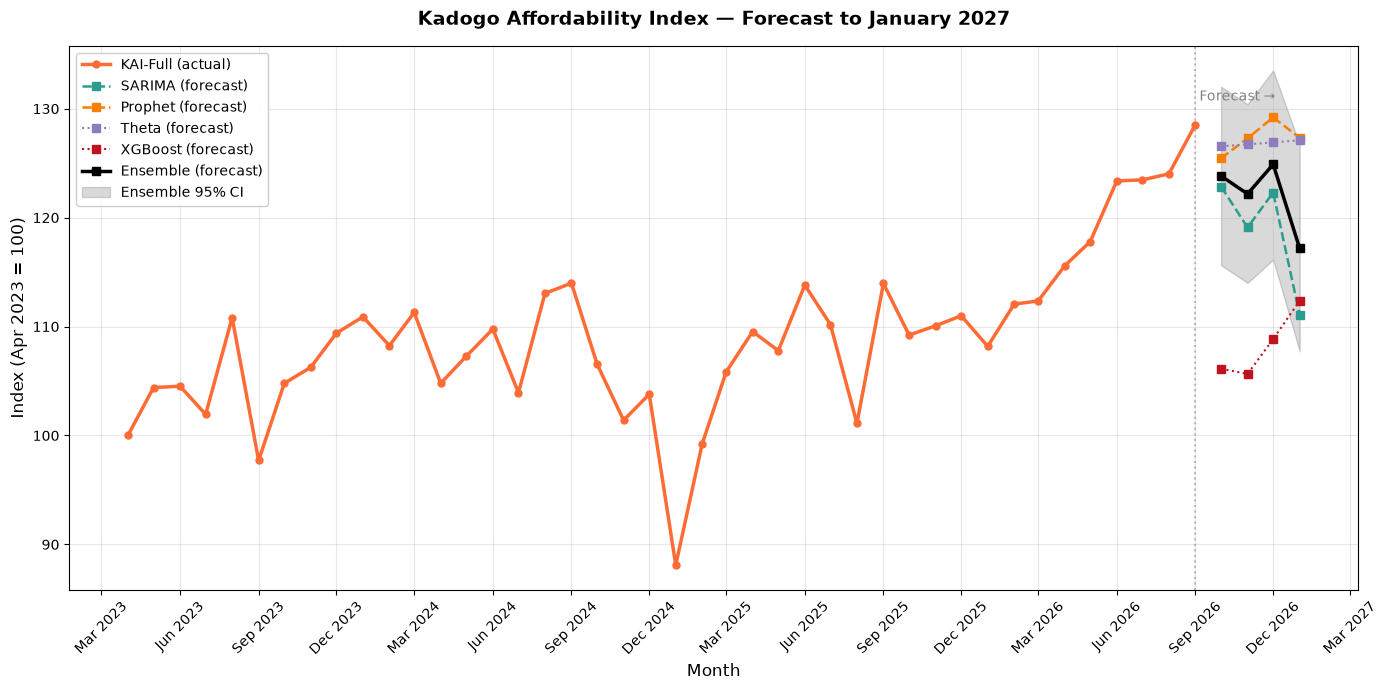

✅ Saved: C:/Users/Blackheart/Documents/kadogo-bestie/reports\fig_5_6_kai_forecast.png


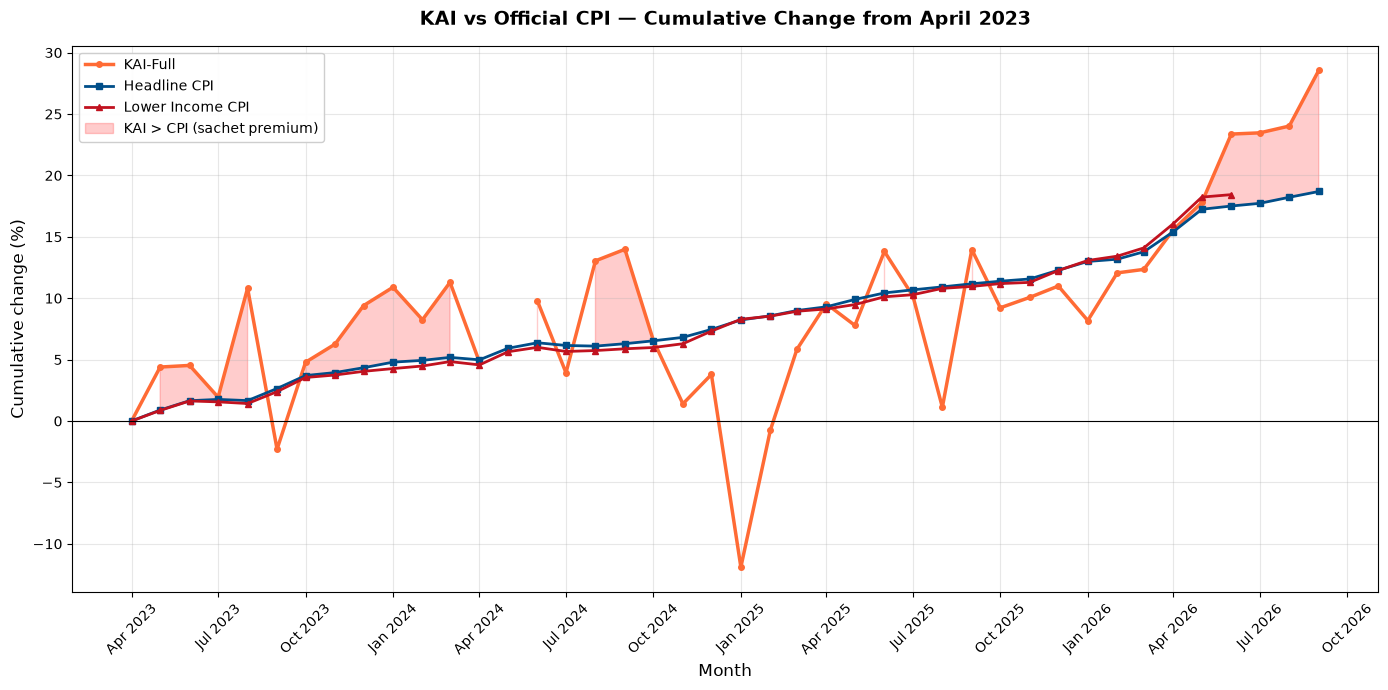

✅ Saved: C:/Users/Blackheart/Documents/kadogo-bestie/reports\fig_5_1_kai_divergence.png

CHART SUMMARY FOR REPORT
  KAI-Full (Sep 2026): 128.55 (+28.55%)
  Headline CPI:        156.47 (+18.69%)
  Divergence KAI-CPI:  +9.86 pp

  Ensemble forecast range (Oct 2026 – Jan 2027):
    Oct 2026: 123.83 [115.64 – 132.02]
    Nov 2026: 122.17 [114.01 – 130.41]
    Dec 2026: 124.89 [116.14 – 133.52]
    Jan 2027: 117.18 [107.72 – 126.71]


In [60]:
# ============================================================
# PHASE 5 CHART — KAI FORECAST VISUALISATION
# ============================================================
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime

processed = "C:/Users/Blackheart/Documents/kadogo-bestie/data/processed"
reports = "C:/Users/Blackheart/Documents/kadogo-bestie/reports"
os.makedirs(reports, exist_ok=True)

# ---- Load data ----
df = pd.read_csv(os.path.join(processed, "master_kai_v4_final.csv"))
df = df.sort_values('year_month').reset_index(drop=True)
df['kai_full'] = df['kai_full'].interpolate(method='linear')
df['date'] = pd.to_datetime(df['year_month'] + '-01')

forecasts = pd.read_csv(os.path.join(processed, "all_models_forecast.csv"))
forecasts['date'] = pd.to_datetime(forecasts['date'] + '-01')

# ---- Color palette (matches original handoff) ----
COLORS = {
    'kai_actual': '#FF6B35',      # Kadogo orange
    'headline_cpi': '#004E89',    # KNBS navy
    'sarima': '#2A9D8F',          # Teal
    'prophet': '#F77F00',         # Amber
    'theta': '#8E7DBE',           # Purple
    'xgboost': '#C1121F',         # Red
    'ensemble': '#000000',        # Black (weighted)
}

# ---- Figure 1: All forecasts overlay ----
fig, ax = plt.subplots(figsize=(14, 7))

# Plot actual KAI
ax.plot(df['date'], df['kai_full'], 'o-',
        color=COLORS['kai_actual'], linewidth=2.5, markersize=5,
        label='KAI-Full (actual)', zorder=5)

# Plot forecast lines
forecast_styles = [
    ('sarima_forecast', 'SARIMA', COLORS['sarima'], '--', 1.8),
    ('prophet_forecast', 'Prophet', COLORS['prophet'], '--', 1.8),
    ('theta_forecast', 'Theta', COLORS['theta'], ':', 1.5),
    ('xgboost_forecast', 'XGBoost', COLORS['xgboost'], ':', 1.5),
    ('ensemble_forecast', 'Ensemble', COLORS['ensemble'], '-', 2.5),
]

for col, name, color, ls, lw in forecast_styles:
    if col in forecasts.columns:
        ax.plot(forecasts['date'], forecasts[col], marker='s', linestyle=ls,
                color=color, linewidth=lw, markersize=6, label=f'{name} (forecast)')

# Shade ensemble uncertainty
if 'ensemble_lower' in forecasts.columns:
    ax.fill_between(forecasts['date'],
                    forecasts['ensemble_lower'],
                    forecasts['ensemble_upper'],
                    alpha=0.15, color=COLORS['ensemble'],
                    label='Ensemble 95% CI')

# Vertical line at forecast start
cutoff = pd.Timestamp('2026-09-01')
ax.axvline(cutoff, color='gray', linestyle=':', alpha=0.5)
ax.text(cutoff, ax.get_ylim()[1] * 0.97, ' Forecast →',
        color='gray', fontsize=10, va='top')

# Formatting
ax.set_title('Kadogo Affordability Index — Forecast to January 2027',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Month', fontsize=12)
ax.set_ylabel('Index (Apr 2023 = 100)', fontsize=12)
ax.legend(loc='upper left', fontsize=10, framealpha=0.95)
ax.grid(True, alpha=0.3)

# X-axis formatting
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45)

plt.tight_layout()
chart_path = os.path.join(reports, "fig_5_6_kai_forecast.png")
plt.savefig(chart_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Saved: {chart_path}")

# ---- Figure 2: Divergence chart (KAI vs CPI) ----
fig, ax = plt.subplots(figsize=(14, 7))

# Ensure headline_pct and kai_full_pct exist
if 'kai_full_pct' not in df.columns:
    base_kai = df['kai_full'].iloc[0]
    df['kai_full_pct'] = (df['kai_full'] / base_kai - 1) * 100
if 'headline_pct' not in df.columns:
    base_cpi = df['overall_cpi'].iloc[0]
    df['headline_pct'] = (df['overall_cpi'] / base_cpi - 1) * 100
if 'lower_pct' not in df.columns:
    base_lo = df['lower_income_cpi'].dropna().iloc[0]
    df['lower_pct'] = (df['lower_income_cpi'] / base_lo - 1) * 100

ax.plot(df['date'], df['kai_full_pct'], 'o-',
        color=COLORS['kai_actual'], linewidth=2.5, markersize=4,
        label='KAI-Full')
ax.plot(df['date'], df['headline_pct'], 's-',
        color=COLORS['headline_cpi'], linewidth=2, markersize=4,
        label='Headline CPI')
if 'lower_pct' in df.columns and df['lower_pct'].notna().any():
    ax.plot(df['date'], df['lower_pct'], '^-',
            color='#C1121F', linewidth=2, markersize=4,
            label='Lower Income CPI')

# Fill the gap
ax.fill_between(df['date'],
                df['kai_full_pct'],
                df['headline_pct'],
                where=(df['kai_full_pct'] > df['headline_pct']),
                alpha=0.2, color='red', label='KAI > CPI (sachet premium)')

ax.axhline(0, color='black', linestyle='-', linewidth=0.8)

ax.set_title('KAI vs Official CPI — Cumulative Change from April 2023',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Month', fontsize=12)
ax.set_ylabel('Cumulative change (%)', fontsize=12)
ax.legend(loc='upper left', fontsize=10, framealpha=0.95)
ax.grid(True, alpha=0.3)

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45)

plt.tight_layout()
chart_path2 = os.path.join(reports, "fig_5_1_kai_divergence.png")
plt.savefig(chart_path2, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Saved: {chart_path2}")

# ---- Summary text ----
print(f"\n{'='*70}")
print("CHART SUMMARY FOR REPORT")
print(f"{'='*70}")
last = df.iloc[-1]
print(f"  KAI-Full (Sep 2026): {last['kai_full']:.2f} ({last['kai_full_pct']:+.2f}%)")
print(f"  Headline CPI:        {last['overall_cpi']:.2f} ({last['headline_pct']:+.2f}%)")
if 'lower_pct' in df.columns and pd.notna(df.iloc[-1]['lower_pct']):
    print(f"  Lower Income CPI:    ({df.iloc[-1]['lower_pct']:+.2f}%)")
print(f"  Divergence KAI-CPI:  {last['kai_full_pct'] - last['headline_pct']:+.2f} pp")

print(f"\n  Ensemble forecast range (Oct 2026 – Jan 2027):")
for _, r in forecasts.iterrows():
    print(f"    {r['date'].strftime('%b %Y')}: {r['ensemble_forecast']:.2f} "
          f"[{r['ensemble_lower']:.2f} – {r['ensemble_upper']:.2f}]")

In [61]:
from dotenv import load_dotenv
import os

load_dotenv()  # Loads .env from current directory

dev_key = os.getenv("DEV_GEMINI_KEY")
prod_key = os.getenv("PROD_GEMINI_KEY")

print(f"DEV key loaded:  {dev_key[:10]}...{dev_key[-4:] if dev_key else 'NOT FOUND'}")
print(f"PROD key loaded: {prod_key[:10]}...{prod_key[-4:] if prod_key else 'NOT FOUND'}")

DEV key loaded:  AQ.Ab8RN6J...uVjA
PROD key loaded: AQ.Ab8RN6L...88jA
